# Notebook 2 of 3: from passages to themes

**What this is.** A general notebook for thematic analysis of qualitative text with language models:
deductive coding with a lexicon, and inductive themes from embeddings and clustering. It works on
any collection of documents; Stage 1 says what to change. **Example data:** humanitarian reports
(MSF documents on ReliefWeb) about eight countries, in English, French and Spanish.

**This notebook** clusters the passages of notebook 1 into two levels, names them, and tests what may
be said about them. **Notebook 3** compares countries statistically.

**What every result measures.** Visibility in public reporting: what agencies chose to write about.
Never prevalence, burden, incidence or severity.

### The two levels
- **Sub-themes** (fine level): every distinct topic. Found by HDBSCAN on the UMAP projection. Their
  number is found by the data, given only the smallest size worth comparing across countries.
- **Themes** (standard level): similar sub-themes grouped together by Ward's method. Their number is
  where the tree of sub-themes separates most clearly. Every sub-theme lies in exactly one theme.

### How to run
1. Run notebook 1 first. Then open this notebook in Google Colab with a **GPU** runtime (the
   instruction model in Stages 17, 19b and 20 needs one), and choose *Runtime > Run all*.
2. Stage 12 loads notebook 1's bundle from Drive and stops if the corpus or a setting differs.
3. Stage 25 packs every figure and table of both notebooks into one zip file and downloads it.

### Where each step is
| Phase | Stages | Question |
|---|---|---|
| Load | 12 | is this the bundle notebook 1 wrote? |
| Dimension reduction | 13 | what does the space look like before clustering? |
| Clustering | 14, 15 | which topics are there, and which belong together? |
| Cluster quality | 16 | does each cluster come back with other seeds and other passages? |
| Naming | 17, 18 | what is each cluster about, and may that name be used? |
| Health scope | 19 | which clusters are about health? |
| Summaries | 19b | what do the passages of each cluster say? |
| Validation | 20, 21 | can a second coder reproduce it; what does the method find in noise? |
| Output | 22 to 25 | figures, bundle for notebook 3, dashboard, one download |

## Where every cell is: the map of this notebook

In plain words the whole pipeline is this:

```
data  ->  cleaning  ->  embedding  ->  dimension reduction  ->  clustering  ->  naming  ->  summary
```

This notebook holds 20 cells in 10 phases of it, listed below.

A cell has a STAGE NUMBER, which is its identity: stage 14 is the sub-themes cell and nothing else, and every reference to Stage 14 anywhere in this notebook means that cell. Stages are grouped into PHASES, which have names and no numbers, so that no cell ever carries two competing numbers.

Every code cell below opens with a banner giving its phase, its stage number, its title and what it does, and prints the same stage heading when it runs.

| Phase | What this phase is for | Stages in it |
|---|---|---|
| **SETUP** | storage, settings and shared functions | **Stage 0** environment and storage: finds the corpus, mounts storage, records software versions<br><br>**Stage 1** configuration: every adjustable setting, in one place<br><br>**Stage 2** library: shared functions: cache, figures, number register, UMAP, clustering |
| **LOAD** | load and check notebook 1's bundle | **Stage 12** load the handover: loads notebook 1's bundle, checks it, keeps the analysis set |
| **DIMENSION REDUCTION** | UMAP: from 4,096 dimensions to a few | **Stage 13** 2-d map: a two-dimensional UMAP for drawing, coloured by language, place, lexicon and length |
| **CLUSTERING** | sub-themes (every topic), then themes (groups of sub-themes) | **Stage 14** sub-themes: fine level: HDBSCAN on five UMAP seeds finds every distinct topic; the count is found<br><br>**Stage 15** themes: standard level: Ward groups the sub-themes into themes, cut at the largest jump |
| **CLUSTER QUALITY** | are the clusters stable, and do they survive another embedding model | **Stage 16** stability: does each cluster come back with another seed and with other passages<br><br>**Stage 16b** a second embedding model: does each cluster come back when another embedding model reads the same passages |
| **NAMING** | a name per cluster, and a test of each name | **Stage 17** terms, then names: distinctive words per cluster, then a short name from the instruction model<br><br>**Stage 18** the name gate: tests every name against its cluster's own words and rejects the ones that fail |
| **HEALTH SCOPE** | which clusters are about health | **Stage 19** which clusters are health: marks the health sub-themes with the lexicon, and tests other thresholds |
| **SUMMARIES** | a short description per cluster and per passage, checked against its text | **Stage 19b** cluster and passage summaries: short summaries per cluster and per quoted passage, checked for unsupported claims<br><br>**Stage 19c** is each summary supported by its text: a fact-checking model tests every summary against the text it summarises |
| **VALIDATION** | a second coder, and a test on data with known structure | **Stage 20** a second coder: a second coder assigns passages to themes; agreement is measured with kappa<br><br>**Stage 21** self-test on known data: runs the same clustering on data with known structure and with none |
| **OUTPUT** | figures, the bundle for notebook 3, a dashboard and one download | **Stage 22** figures: size, coherence, confidence and stability of the themes in three figures<br><br>**Stage 23** hand over to notebook 3: saves themes, names, scope and every verdict for notebook 3<br><br>**Stage 24** interactive dashboard: one interactive page with every cluster's name, summary and evidence<br><br>**Stage 25** download everything: every figure and table of both notebooks, the dashboard and a README, in one zip file |

The SETUP phase is the same three cells in both notebooks, from the same text, because notebook 2 needs the same settings and the same helper functions.

## Stage 0: environment and storage   [phase: setup]

The same three cells as notebook 1, from the same source: environment, settings and shared functions.
Stage 12 compares the settings with those recorded in notebook 1's bundle.

In [ ]:
# @title
# ==================================================================================================
# PHASE: SETUP                                                          stage 1 of 3 in this phase
# STAGE 0  ENVIRONMENT AND STORAGE
# WHAT THIS CELL DOES: finds the corpus, mounts storage, records software versions
# ==================================================================================================
# WHAT THIS CELL DOES
#   Resolves where the corpus comes from, sets up local and Drive storage, and records the
#   software environment, printing all three so later results carry a provenance trail.
#
# WHY
#   The embedding step is the most expensive part of the pipeline, so its cache lives on Drive
#   when available and is reused across runs. Figures go to fast local storage during the run
#   and are copied to Drive as each one is produced, since writing directly to Drive is slow.

import subprocess, sys, os, shutil, platform, json
import importlib
import importlib.util   # explicit: `import importlib` alone does not expose importlib.util

# =============================================================================
#  EDIT HERE
# =============================================================================

# "auto"  : mount Drive if this is Colab; carry on locally if that fails
# True     : require Drive; stop if it cannot be mounted
# False    : never use Drive; everything stays in session storage and is lost when it ends
USE_DRIVE = "auto"

DRIVE_PROJECT_DIR = "MyDrive/CIRP_MSF"     # the project folder inside your Drive

# Where the corpus comes from. "auto" tries, in order: CORPUS_URL, then Drive, then an upload.
# Set it explicitly to "drive", "upload" or "url" to remove the guessing.
CORPUS_SOURCE = "auto"
CORPUS_FILENAME = "corpus.csv"             # the file name inside DRIVE_PROJECT_DIR, or uploaded
CORPUS_URL = ""                            # a direct download link, if you use one

# =============================================================================
#  END EDIT
# =============================================================================

REQUIRED = [
    ("sentence_transformers", "sentence-transformers>=3.0.0"),
    ("umap",                  "umap-learn>=0.5.5"),
    ("sklearn",               "scikit-learn>=1.3"),
    ("scipy",                 "scipy"),
    ("pandas",                "pandas"),
    ("matplotlib",            "matplotlib"),
    ("plotly",                "plotly>=5.20"),
    ("bitsandbytes",          "bitsandbytes>=0.46.1"),   # 4-bit loading for the naming model
    ("accelerate",            "accelerate>=0.30"),       # device_map="auto"
    ("spacy",                 "spacy>=3.7"),             # multilingual NER for place masking
    ("lingua",                "lingua-language-detector>=2.0"),  # replaces the stopword heuristic
    ("datasketch",            "datasketch>=1.6"),        # near-duplicates without an N by N matrix
]

missing = [spec for module, spec in REQUIRED
           if not importlib.util.find_spec(module.split(".")[0])]
if missing:
    print("Installing: " + ", ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False)
else:
    print("All required packages are already present.")

IN_COLAB = importlib.util.find_spec("google.colab") is not None

# ---- storage ----------------------------------------------------------------
DRIVE_ROOT = None
DRIVE_STATUS = "not requested"

if USE_DRIVE is not False:
    if not IN_COLAB:
        DRIVE_STATUS = "not Colab, so no Drive; using local storage"
    else:
        try:
            from google.colab import drive
            drive.mount("/content/drive", force_remount=False)
            candidate = os.path.join("/content/drive", DRIVE_PROJECT_DIR)
            os.makedirs(candidate, exist_ok=True)
            DRIVE_ROOT = candidate
            DRIVE_STATUS = "mounted"
        except Exception as exc:
            DRIVE_STATUS = f"mount failed ({type(exc).__name__}: {str(exc)[:70]})"

if USE_DRIVE is True and DRIVE_ROOT is None:
    raise RuntimeError(
        "USE_DRIVE is True but Drive could not be mounted: " + DRIVE_STATUS + "\n"
        "Set USE_DRIVE = 'auto' to continue in session storage instead, accepting that the "
        "cache and the outputs will be lost when this runtime ends."
    )

# Durable storage holds the cache. Working storage holds figures during the run, on fast local
# disk; each figure is also copied to Drive as soon as it is written (keep_on_drive, Stage 2).
DURABLE_DIR = os.path.join(DRIVE_ROOT, "checkpoints") if DRIVE_ROOT else "checkpoints"
DURABLE_OUTPUT_DIR = os.path.join(DRIVE_ROOT, "outputs") if DRIVE_ROOT else None
WORKING_DIR = "run_outputs"
os.makedirs(DURABLE_DIR, exist_ok=True)
os.makedirs(WORKING_DIR, exist_ok=True)
if DURABLE_OUTPUT_DIR:
    os.makedirs(DURABLE_OUTPUT_DIR, exist_ok=True)

# ---- the corpus file --------------------------------------------------------
# Looks for the named file first; if absent, looks for any data file in the places a corpus can
# arrive, and uses it when exactly one candidate is found.

DATA_SUFFIXES = (".csv", ".tsv", ".jsonl", ".json")
# WORKING_DIR is not searched: it holds this notebook's own output, not the corpus. A corpus
# arrives in /content (a Colab upload), in the notebook's folder, or in Drive.
SEARCH_FOLDERS = [f for f in ["/content", ".", DRIVE_ROOT] if f]
NOTEBOOK_OWN_FILES = {"environment.json", "MANIFEST.json"}


def _candidates():
    """Every data file in the places a corpus arrives, largest first. A corpus is almost always the
    biggest data file present, and the notebook's own outputs are excluded by folder."""
    found, seen = [], set()
    for folder in SEARCH_FOLDERS:
        if not folder or not os.path.isdir(folder):
            continue
        try:
            names = sorted(os.listdir(folder))
        except OSError:
            continue
        for name in names:
            path = os.path.join(folder, name)
            if (name.lower().endswith(DATA_SUFFIXES) and os.path.isfile(path)
                    and name not in NOTEBOOK_OWN_FILES
                    and os.path.getsize(path) > 1024          # a corpus is never a few bytes
                    and os.path.realpath(path) not in seen):
                seen.add(os.path.realpath(path))
                found.append((path, os.path.getsize(path)))
    return sorted(found, key=lambda pair: -pair[1])


def resolve_corpus(source, filename, url):
    """Return (path, how it was found). Tries the named file, then any data file present."""
    tried = []

    def try_url():
        if not url:
            tried.append("no CORPUS_URL is set")
            return None
        local = os.path.join(WORKING_DIR, filename or "corpus_downloaded.csv")
        try:
            import urllib.request
            urllib.request.urlretrieve(url, local)
            return (local, f"downloaded from CORPUS_URL to {local}")
        except Exception as exc:
            tried.append(f"the CORPUS_URL download failed ({type(exc).__name__})")
            return None

    def try_named():
        if not filename:
            tried.append("CORPUS_FILENAME is empty, so no exact name was looked for")
            return None
        for folder in SEARCH_FOLDERS:
            if not folder:
                continue
            candidate = os.path.join(folder, filename)
            if os.path.exists(candidate):
                where = "Drive" if DRIVE_ROOT and candidate.startswith(DRIVE_ROOT) else "the session"
                return (candidate, f"found '{filename}' in {where} at {candidate}")
        tried.append(f"'{filename}' is not in {', '.join(f for f in SEARCH_FOLDERS if f)}")
        return None

    def try_any():
        found = _candidates()
        if not found:
            tried.append("no .csv, .tsv, .jsonl or .json file is present in any of those folders")
            return None
        if len(found) == 1:
            path, size = found[0]
            return (path, f"the only data file present, {path} ({size / 1e6:.2f} MB). "
                          f"CORPUS_FILENAME said '{filename}', which is not here.")
        print("  SEVERAL data files are present and the notebook will not guess between them:")
        for path, size in found[:12]:
            print(f"    {size / 1e6:>8.2f} MB   {path}")
        print(f"  Set CORPUS_FILENAME to the one you want and run this cell again. The largest is")
        print(f"  usually the corpus; the smaller ones are usually its tables or outputs.")
        tried.append(f"{len(found)} data files are present, so the choice was left to you")
        return None

    routes = {"url": [try_url], "drive": [try_named], "upload": [try_named, try_any],
              "auto": [try_url, try_named, try_any]}
    for route in routes[source]:
        outcome = route()
        if outcome:
            return outcome

    raise FileNotFoundError(
        "No corpus file was found: upload it, place it in your Drive folder "
        f"{DRIVE_PROJECT_DIR}, or set CORPUS_FILENAME or CORPUS_URL, then run this cell again."
    )


CORPUS_PATH, CORPUS_ORIGIN = resolve_corpus(CORPUS_SOURCE, CORPUS_FILENAME, CORPUS_URL)

# ---- hardware --------------------------------------------------------------
try:
    import torch
    GPU_AVAILABLE = torch.cuda.is_available()
    GPU_NAME = torch.cuda.get_device_name(0) if GPU_AVAILABLE else "none"
    GPU_MEMORY_GB = (torch.cuda.get_device_properties(0).total_memory / 1e9) if GPU_AVAILABLE else 0.0
except Exception:
    GPU_AVAILABLE, GPU_NAME, GPU_MEMORY_GB = False, "none", 0.0

try:
    import spacy
    try:
        spacy.load("xx_ent_wiki_sm")
        NER_READY = True
    except OSError:
        print("Downloading the multilingual NER model xx_ent_wiki_sm ...")
        subprocess.run([sys.executable, "-m", "spacy", "download", "xx_ent_wiki_sm"], check=False)
        try:
            spacy.load("xx_ent_wiki_sm"); NER_READY = True
        except Exception:
            NER_READY = False
except Exception as exc:
    NER_READY = False
    print(f"spaCy setup skipped ({type(exc).__name__}); place masking will use its word list.")

# ---- the version record ----------------------------------------------------
def _version(module_name):
    """Version string for `module_name`: "not installed", the installed distribution's version,
    or "installed, version not exposed" for a package with no version metadata at all."""
    try:
        from importlib.metadata import version as _metadata_version, PackageNotFoundError
    except Exception:
        _metadata_version, PackageNotFoundError = None, Exception

    if importlib.util.find_spec(module_name) is None:
        return "not installed"

    # importlib.metadata reads the installed distribution, so it works for packages whose module
    # does not carry __version__. The distribution name can differ from the import name.
    DISTRIBUTION_NAME = {"lingua": "lingua-language-detector",
                         "sklearn": "scikit-learn",
                         "umap": "umap-learn"}
    if _metadata_version is not None:
        for candidate in (DISTRIBUTION_NAME.get(module_name, module_name), module_name):
            try:
                return _metadata_version(candidate)
            except Exception:
                continue
    try:
        return str(importlib.import_module(module_name).__version__)
    except Exception:
        return "installed, version not exposed"

ENVIRONMENT = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "in_colab": IN_COLAB,
    "gpu": GPU_NAME,
    "gpu_memory_gb": round(GPU_MEMORY_GB, 1),
    "drive": DRIVE_STATUS,
    "durable_dir": DURABLE_DIR,
    "working_dir": WORKING_DIR,
    "corpus_path": CORPUS_PATH,
    "corpus_origin": CORPUS_ORIGIN,
    "ner_model_ready": NER_READY,
    "versions": {m: _version(m) for m in
                 ["numpy", "pandas", "sklearn", "scipy", "umap", "matplotlib", "plotly",
                  "sentence_transformers", "transformers", "torch", "lingua", "datasketch"]},
}

# OUTPUT_WIDTH is defined here, before the configuration cell exists, and reused by every later
# cell rather than being redefined.
OUTPUT_WIDTH = 78
print("=" * OUTPUT_WIDTH)
print("  STAGE 0  ENVIRONMENT AND STORAGE")
print("=" * OUTPUT_WIDTH)
print(f"  running in Colab   : {IN_COLAB}")
print(f"  GPU                : {GPU_NAME}  ({GPU_MEMORY_GB:.1f} GB)")
print(f"  Google Drive       : {DRIVE_STATUS}")
print(f"  durable storage    : {DURABLE_DIR}")
print(f"  working storage    : {WORKING_DIR}")
if DURABLE_OUTPUT_DIR:
    print(f"    figures are written here, and copied to {DURABLE_OUTPUT_DIR} as each one is saved")
else:
    print(f"    WARNING: no Drive. Figures are written here only and are lost when this runtime")
    print(f"    ends; download the figures folder before closing the session.")
print(f"  NER model ready    : {NER_READY}")
print()
print(f"  CORPUS             : {CORPUS_PATH}")
print(f"    origin           : {CORPUS_ORIGIN}")
print(f"    size             : {os.path.getsize(CORPUS_PATH) / 1e6:.2f} MB")
print()
print("  software versions (affect reproducibility):")
for name, version in ENVIRONMENT["versions"].items():
    print(f"    {name:<24} {version}")
if DRIVE_ROOT is None:
    print()
    print("  WARNING: no Drive. The cache and every output are lost when this runtime ends, and")
    print("  the embedding will be recomputed from scratch on the next run.")
print("=" * OUTPUT_WIDTH)

with open(os.path.join(WORKING_DIR, "environment.json"), "w") as fh:
    json.dump(ENVIRONMENT, fh, indent=2)

Installing: bitsandbytes>=0.46.1, lingua-language-detector>=2.0, datasketch>=1.6
Mounted at /content/drive
  STAGE 0  ENVIRONMENT AND STORAGE
  running in Colab   : True
  GPU                : NVIDIA L4  (23.7 GB)
  Google Drive       : mounted
  durable storage    : /content/drive/MyDrive/CIRP_MSF/checkpoints
  working storage    : run_outputs
    figures are written here, and copied to /content/drive/MyDrive/CIRP_MSF/outputs as each one is saved
  NER model ready    : True

  CORPUS             : /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv
    origin           : the only data file present, /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv (7.41 MB). CORPUS_FILENAME said 'corpus.csv', which is not here.
    size             : 7.41 MB

  software versions (affect reproducibility):
    numpy                    2.1.3
    pandas                   2.2.3
    sklearn                  1.6.1
    scipy                    1.16.3
    umap                     0.5.12
    matplotlib               3.

  STAGE 1  CONFIGURATION
  seed                : 42
  input file          : /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv  (the only data file present, /content/drive/MyDrive/CIRP_MSF/msf_corpus.csv (7.41 MB). CORPUS_FILENAME said 'corpus.csv', which is not here.)
  group variable      : country   (column: country_searched)
  optional mapped     : date, doc_type, external_label, group, group_all, group_label, lang_declared, title, year
  optional not mapped : none
  embedding model     : qwen3-8b; second model bge-m3
  dimension reduction : UMAP, setting chosen by trustworthiness and continuity (mode 'auto')
  sub-themes          : HDBSCAN (leaf clusters), over 5 UMAP seeds
  themes              : sub-themes grouped by Ward, cut at the largest fusion jump in (4, 12)
  stability           : bootstrap Jaccard, stable at 0.75, dissolved at 0.5 (Hennig 2007)
  documents, subject  : humanitarian report; health
  lexicon             : built-in (Stage 6)
  health scope        : a sub-theme i

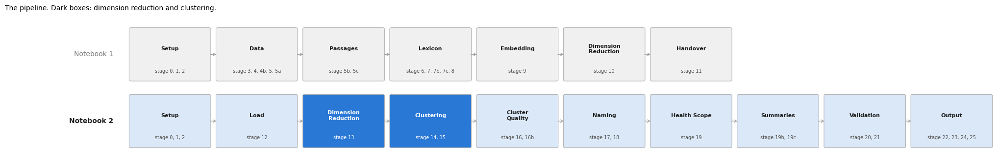


PRACTITIONER NOTE
  Keep every adjustable value in one place and publish it beside the results: a reader who cannot see
  the settings cannot check a figure. Describe the corpus with a column map, so the notebook runs on
  another collection and says which comparisons it could not make.


In [ ]:
# @title
# ==================================================================================================
# PHASE: SETUP                                                          stage 2 of 3 in this phase
# STAGE 1  CONFIGURATION
# WHAT THIS CELL DOES: every adjustable setting, in one place
# ==================================================================================================
# WHAT THIS CELL DOES
#   Holds every adjustable setting of notebooks 1 and 2, checks them, and draws the pipeline.
#
# WHY
#   A reader can see here, in one place, what produced every result. Each setting is classified
#   UPSTREAM (it can change the passages, the lexicon columns or the vectors) or DOWNSTREAM (it
#   cannot). The cache and the handover check both use this classification.
#
# HOW
#   The corpus is described by a column map: only an identifier and the text are required. Stages
#   that need a missing column say that they were skipped instead of failing.

from dataclasses import dataclass, asdict
import os, random
import numpy as np

# =============================================================================
#  EDIT HERE
# =============================================================================

SEED          = 42
CACHE_VERSION = "v2"          # raise to force every cached stage to recompute

# ---- the corpus -------------------------------------------------------------
DATA_PATH = CORPUS_PATH       # located by Stage 0 (Drive, an upload or a URL)

# Left: the name the notebook uses (do not change). Right: the column in your file, or None.
COLUMN_MAP = {
    "doc_id":         "url",              # REQUIRED. Unique per document.
    "text":           "body",             # REQUIRED. The text to analyse.
    "title":          "title",
    "group":          "country_searched", # the comparison variable
    "group_label":    "country_name",     # a readable name for the group
    "group_all":      "all_countries",    # every group of a document, separated by "|"
    "date":           "date",             # ISO date
    "year":           "year",
    "doc_type":       "format",           # the publisher's document type
    "lang_declared":  "language",         # the publisher's language label; not trusted (Stage 5)
    "external_label": "theme_name",       # an independent editorial label, for validation only
}
GROUP_NOUN = "country"        # what one group is, in words; used in labels only

# What the documents are, and the subject the lexicon defines, in words. They go into the
# instructions given to the models and into labels. Another corpus needs these two lines, the
# column map above and, for another subject, CODEBOOK_FILE below.
DOCUMENT_TYPE = "humanitarian report"   # singular
SUBJECT_NAME  = "health"

# ---- cleaning (Stage 4) -----------------------------------------------------
BOILERPLATE_MIN_DOC_FRACTION   = 0.15  # a sentence in this share of documents is boilerplate
BOILERPLATE_MIN_SENTENCE_CHARS = 40    # shorter sentences are never boilerplate
NEAR_DUPLICATE_THRESHOLD       = 0.90  # cosine at or above this is flagged, never deleted
NEAR_DUPLICATE_EXACT_MAX_DOCS  = 5000  # above this, an approximate search is used
MIN_WORDS_AFTER_CLEANING       = 50    # a shorter document leaves the analysis set

# ---- stories: one version per release (Stage 5a) ----------------------------
STORY_WINDOW_DAYS        = 10     # translations of one release appear within this many days
STORY_NULL_QUANTILE      = 0.99   # threshold = this quantile of scores between impossible pairs
STORY_PREFERRED_LANGUAGE = "en"   # the version kept when a story exists in several languages

# ---- passages (Stages 5b and 5c) --------------------------------------------
PASSAGE_TARGET_WORDS     = 160
PASSAGE_MAX_WORDS        = 250
PASSAGE_MIN_WORDS        = 20     # shorter passages are discarded and counted
PASSAGE_MERGE_TAIL_UNDER = 80     # a shorter final fragment joins the previous passage
PLACE_PLACEHOLDER  = "location"   # replaces a masked place name
# Place names to mask beyond the built-in list (the eight countries of this corpus) and the entity
# model: for another corpus, its countries, regions, cities and demonyms, one whole name per entry.
EXTRA_PLACE_NAMES  = []
LIST_CAPITAL_SHARE = 0.55         # at or above this share of capitalised words, a passage is a list
                                  # of names, not prose (prose median on this corpus: 0.12)

# ---- embedding (Stage 9) ----------------------------------------------------
EMBEDDING_MODELS      = [("qwen3-8b", "Qwen/Qwen3-Embedding-8B")]
EMBEDDING_BATCH_SIZE  = 16
EMBEDDING_MAX_SEQ_LEN = 512       # passages stop at PASSAGE_MAX_WORDS, so 512 tokens is enough
# The task instruction, in English as the model card advises, in the format of the developers'
# clustering evaluation: "Instruct: {task}\nQuery:{text}" (Zhang et al. 2025). Empty = none.
EMBEDDING_INSTRUCTION = ("Identify the topic or theme of the given passage from "
                         f"{'an' if DOCUMENT_TYPE[:1].lower() in 'aeiou' else 'a'} {DOCUMENT_TYPE}")
# A multilingual model still sets each language slightly apart. "auto": remove each language's
# offset (estimated on translation pairs) only if held-out translations then find their original
# more often. "on": always. "off": never. See Stage 9.
LANGUAGE_CORRECTION = "auto"
# A second, independent embedding model. Notebook 2 (Stage 16b) clusters its vectors the same way
# and reports which sub-themes come back: themes that depend on one model are marked. None = skip.
SECOND_EMBEDDING_MODEL = ("bge-m3", "BAAI/bge-m3")   # (short name, Hugging Face id); MIT licence

# ---- dimension reduction: UMAP (Stage 10) -----------------------------------
# "auto": search the grid, unless UMAP_FROZEN was tuned on this very analysis set and still measures
# above the floor. "search": always search. "frozen": never search.
PROJECTION_MODE            = "auto"
PROJECTION_TUNED_ON_CORPUS = ""        # the fingerprint Stage 10 prints after a search
UMAP_FROZEN          = (80, 0.1, 10)   # (n_neighbors, min_dist, n_components)
UMAP_NEIGHBORS_GRID  = [15, 30, 50, 80]
UMAP_MIN_DIST_GRID   = [0.0, 0.1]
UMAP_COMPONENTS_GRID = [5, 10, 20]
TRUSTWORTHINESS_K    = 15              # neighbourhood size for trustworthiness and continuity
PROJECTION_RECORDED_HARMONIC = 0.904   # the quality UMAP_FROZEN measured when it was tuned
PROJECTION_QUALITY_TOLERANCE = 0.06    # floor = record minus this
PROJECTION_TIE_TOLERANCE     = 0.001   # settings within this of the best score are tied; the tie
                                       # goes to fewer dimensions, then fewer neighbours. On this
                                       # corpus 0.001 absorbs sampling noise (0.0003) and no more.

# ---- clustering (notebook 2, Stages 14 and 15) ------------------------------
# Two levels. How many clusters each level has is found by a stated rule, never fixed in advance.
#   SUB-THEMES, the fine level: every distinct topic, found on the UMAP projection.
#   THEMES, the standard level: similar sub-themes grouped together in the embedding space.
SUBTHEME_METHOD  = "hdbscan"  # "hdbscan": density-based; unclear passages are held aside (default)
                              # "ward":    centroid-based; every passage is placed at once
HDBSCAN_MIN_SIZE = None       # smallest sub-theme. None = MIN_EXPECTED_CELL x number of groups:
                              # the smallest sub-theme that can be compared across groups
WARD_K_RANGE     = (10, 60)   # "ward": the number of sub-themes is sought in this range
THEME_K_RANGE    = (4, 12)    # the number of themes is sought in this range: the size of a
                              # thematic map a reader can take in at once
                              # Both are cut at the largest jump in Ward fusion height (Mojena 1977)
SUBTHEME_COUNT_FIXED = None   # an integer replaces the rule for the number of "ward" sub-themes
THEME_COUNT_FIXED    = None   # an integer replaces the rule for the number of themes
CLUSTER_SEEDS     = 5         # UMAP runs with different seeds; the reported partition is the one
                              # that agrees best with the others
CONFIDENCE_FLOOR  = 0.60      # a passage in its sub-theme on fewer of the seeds is "held weakly"
COHERENCE_FLOOR   = 0.0       # mean silhouette below this: passages sit closer to another cluster
MAX_CLUSTER_SHARE = 0.50      # one cluster above this share of passages dominates the partition
LANGUAGE_ARTEFACT_SHARE      = 0.90  # one language holding this share of a cluster ...
LANGUAGE_ARTEFACT_CORPUS_MAX = 0.50  # ... while holding at most this share of all passages

# ---- cluster quality (notebook 2, Stages 16 and 18) -------------------------
BOOTSTRAP_N            = 50     # resampling rounds for cluster stability (Hennig 2007)
STABILITY_JACCARD_MIN  = 0.75   # Hennig (2007): mean Jaccard at or above this is a stable cluster
UNSTABLE_CLUSTER_FLOOR = 0.50   # Hennig (2007): at or below this the cluster dissolves
SILHOUETTE_FLOOR       = 0.05   # the name gate's floor for a theme's silhouette
PERMUTATION_MAX_N      = 1500   # the permutation null is computed on a sample above this size

# ---- naming (Stages 17 and 18) ----------------------------------------------
# Words a name may not contain. QUANTITY words would claim a level in the world; the corpus shows
# only what is reported. META words name the method, not the subject.
NAME_FORBIDDEN_QUANTITY = (
    "high", "low", "rising", "falling", "increasing", "decreasing", "growing", "declining",
    "severe", "severity", "acute", "widespread", "prevalent", "prevalence", "incidence",
    "burden", "crisis", "emergency", "epidemic", "surge", "spike", "worsening", "improving",
    "majority", "minority", "most", "least", "more", "less", "many", "few", "rate", "rates",
    "level", "levels", "trend", "trends", "significant", "significantly", "massive", "extreme",
)
NAME_FORBIDDEN_META = (
    "theme", "themes", "cluster", "clusters", "topic", "topics", "group", "groups",
    "category", "categories", "class", "classes", "unnamed", "miscellaneous", "other", "various",
    "general", "mixed",
)
NAME_MAX_WORDS  = 6
NAME_MIN_WORDS  = 1      # one word is enough when it is a subject: cholera, migration
NAME_MIN_LIFT   = 1.30   # the name's words must be this much more frequent in its own cluster,
                         # on the smoothed lift (Monroe, Colaresi and Quinn 2008)
NAME_MIN_MARGIN = 0.04   # below this, the name fits another cluster about as well
NAME_STEM_CHARS = 6      # de-duplicates the words of a label built from terms
NAME_MISDIRECTED_MAX_SHARE = 0.75  # share of a cluster's passages that may contain no name word
NAME_LANGUAGE   = "en"   # every name is written in this language
NAME_LEXICAL_MIN_SHARE = 0.50  # the word-based name tests apply only when at least this share of
                               # the cluster is in NAME_LANGUAGE
NAME_FOREIGN_MAX_SHARE = 0.25  # a name word found mostly outside NAME_LANGUAGE is foreign
NAME_RETRY = True        # a rejected name is asked for once more, with the reason
# Fixed terms that contain a forbidden word but name a subject, not a quantity or the method.
NAME_ALLOWED_PHRASES = (
    "armed group", "armed groups", "support group", "support groups",
    "acute malnutrition", "severe acute malnutrition", "acute watery diarrhoea",
    "acute watery diarrhea", "emergency care", "emergency surgery", "emergency room",
    "emergency department", "emergency obstetric care",
)

# ---- the instruction model (Stages 7, 17, 19b and 20) -----------------------
LLM_ENABLE       = True
LLM_MODEL        = "Qwen/Qwen3-4B-Instruct-2507"   # Apache-2.0, July 2025; transformers >= 4.51
LLM_LOAD_IN_4BIT = False  # 16-bit fits a 16 GB GPU; True halves the memory
LLM_N_QUOTES     = 7      # passages shown to the model per cluster

# ---- summaries (Stage 19b) --------------------------------------------------
# SUMMARY_PASSAGE_SCOPE: "auto" (every passage when a GPU is present, else the quoted passages
# only), "all" (every passage; about 20 to 60 minutes on a GPU for 4,000 passages),
# "representative" (the quoted passages only, a few minutes) or "none". The dashboard shows a
# passage's own summary on hover, so "auto" or "all" is needed for every point to have one.
SUMMARY_ENABLE             = True
SUMMARY_CLUSTER_SENTENCES  = 3
SUMMARY_PASSAGE_SCOPE      = "auto"
SUMMARY_PASSAGE_MAX_WORDS  = 28   # a longer passage summary is rejected
SUMMARY_BATCH              = 8
SUMMARY_MAX_QUOTE_WORDS    = 110  # a quotation is cut to this before it is sent to the model
# Stage 19c checks every summary against its source text with a fact-checking model (MiniCheck,
# Tang, Laban and Durrett 2024): "flan-t5-large" (770M, MIT, English). "" = skip the check.
GROUNDING_MODEL     = "flan-t5-large"
GROUNDING_THRESHOLD = 0.5    # below this support probability a summary is marked "not supported"

# The corpus shows what agencies chose to publish: VISIBILITY in public reporting, never prevalence,
# incidence, burden or severity. A summary with one of these phrases is asked for once more; if it
# still contains one, it is withheld.
SUMMARY_FORBIDDEN_CLAIMS = (
    "most common", "commonest", "most frequent", "most prevalent", "prevalence",
    "incidence", "burden of disease", "disease burden", "high burden",
    "widespread", "epidemic of", "rates of", "morbidity", "mortality rate",
    "leading cause", "main cause", "primary cause", "majority of patients",
    "majority of people", "majority of cases", "increasing number of cases",
    "on the rise", "growing crisis", "worsening health", "severity of",
    "more severe", "affected the most", "worst affected", "hardest hit",
)
# Words that judge severity. A summary using one is asked for once more and the second answer is
# marked. "acute" and "emergency" are absent: "acute malnutrition" is a clinical term.
SUMMARY_SEVERITY_WORDS = (
    "critical", "critically", "severe", "severely", "dire", "alarming", "catastrophic",
    "catastrophe", "crisis", "crises", "devastating", "deteriorating", "deteriorated",
    "exacerbated", "overwhelming", "overwhelmed", "unprecedented", "grave", "desperate",
)

# ---- the lexicon and scope (Stages 6, 7, 8 and 19) ---------------------------
# CODEBOOK_FILE: "" uses the built-in lexicon (12 health categories, English, French, Spanish,
# Arabic). For another subject, a JSON file: {"categories": {category: {language: [regex, ...]}},
# "short_labels": {category: label}} and, optionally, "canonical": {regex: label} and
# "sub_concepts": {name: [regex, ...]}. Stage 6 writes the built-in lexicon in this format.
CODEBOOK_FILE = ""
SCOPE_SHARE_FLOOR  = 0.40   # a sub-theme is in scope when this share of its passages matches
SCOPE_SENSITIVITY  = (0.30, 0.40, 0.50)   # the rule is re-applied at each and compared
SCOPE_MANUAL_OVERRIDE = []  # sub-theme numbers to force into scope; empty uses the rule
VALIDATION_SAMPLE_PER_CATEGORY = 20       # matches judged per category for precision
PRECISION_FLOOR = 0.80                    # a category below this is reported as weak
# A random sample of ALL passages, coded by a person for every category (Stage 7c). It corrects the
# lexicon's shares per group and measures recall. 40 per group is about 3 hours of reading for 8
# groups. 0 = no sample.
HUMAN_SAMPLE_PER_GROUP = 40

# ---- group comparison (Stage 8) ---------------------------------------------
SMALL_GROUP_N     = 40   # a group with fewer documents is marked as small
MIN_EXPECTED_CELL = 5    # below this expected count a cell is not interpreted

# ---- statistics carried to notebook 3 (notebooks 1 and 2 do not read them) ---
RESIDUAL_NOTABLE       = 2.0   # a standardised residual beyond this is notable
FDR_ALPHA              = 0.05
MIN_DOCS_FOR_SUBJECT   = 3
TOP_SUBJECTS_PER_THEME = 8
MIN_DOCS_WITH_BARRIER  = 20
NEGATION_CONCERN_SHARE = 0.15
QUOTES_PER_CELL        = 3
CASE_STUDY_PAIR        = None  # None: the two largest groups

# ---- figures and output -----------------------------------------------------
FIGURE_STYLE = {"point_size": 4.6, "point_opacity": 0.55}
OUTPUT_NAMES = {"dashboard": "nb2_dashboard.html", "download": "thematic_analysis_outputs.zip"}

# ---- the interactive dashboard (Stage 24): what is SHOWN, never a result -----
DASHBOARD_QUOTES_PER_CLUSTER = 8      # passages shown per cluster, the most central first
DASHBOARD_POINT_LIMIT        = 12000  # above this, a seeded sample of points is drawn
DASHBOARD_TEXT_CHARS         = 900    # a longer passage is cut at a word

CHECKPOINT_DIR = DURABLE_DIR   # from Stage 0
OUTPUT_DIR     = WORKING_DIR   # from Stage 0

# =============================================================================
#  END EDIT
# =============================================================================

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
REQUIRED_INTERNAL_COLUMNS = ("doc_id", "text")


@dataclass(frozen=True)
class Config:
    seed: int
    cache_version: str
    data_path: str
    column_map: tuple
    group_noun: str
    document_type: str
    subject_name: str
    codebook_file: str
    boilerplate_min_doc_fraction: float
    boilerplate_min_sentence_chars: int
    near_duplicate_threshold: float
    near_duplicate_exact_max_docs: int
    min_words_after_cleaning: int
    story_window_days: int
    story_null_quantile: float
    story_preferred_language: str
    passage_target_words: int
    passage_min_words: int
    passage_max_words: int
    passage_merge_tail_under: int
    place_placeholder: str
    extra_place_names: tuple
    list_capital_share: float
    embedding_models: tuple
    embedding_batch_size: int
    embedding_max_seq_len: int
    embedding_instruction: str
    language_correction: str
    second_embedding_model: tuple
    projection_mode: str
    projection_tuned_on_corpus: str
    umap_frozen: tuple
    umap_neighbors_grid: tuple
    umap_min_dist_grid: tuple
    umap_components_grid: tuple
    trustworthiness_k: int
    projection_recorded_harmonic: float
    projection_quality_tolerance: float
    projection_tie_tolerance: float
    subtheme_method: str
    hdbscan_min_size: object
    ward_k_range: tuple
    theme_k_range: tuple
    subtheme_count_fixed: object
    theme_count_fixed: object
    cluster_seeds: int
    confidence_floor: float
    coherence_floor: float
    max_cluster_share: float
    language_artefact_share: float
    language_artefact_corpus_max: float
    bootstrap_n: int
    stability_jaccard_min: float
    unstable_cluster_floor: float
    silhouette_floor: float
    permutation_max_n: int
    name_forbidden_quantity: tuple
    name_forbidden_meta: tuple
    name_max_words: int
    name_min_words: int
    name_min_lift: float
    name_min_margin: float
    name_stem_chars: int
    name_misdirected_max_share: float
    name_language: str
    name_lexical_min_share: float
    name_foreign_max_share: float
    name_retry: bool
    name_allowed_phrases: tuple
    llm_enable: bool
    llm_model: str
    llm_load_in_4bit: bool
    llm_n_quotes: int
    summary_enable: bool
    summary_cluster_sentences: int
    summary_passage_scope: str
    summary_passage_max_words: int
    summary_batch: int
    summary_max_quote_words: int
    summary_forbidden_claims: tuple
    summary_severity_words: tuple
    grounding_model: str
    grounding_threshold: float
    scope_share_floor: float
    scope_sensitivity: tuple
    scope_manual_override: tuple
    validation_sample_per_category: int
    precision_floor: float
    human_sample_per_group: int
    small_group_n: int
    min_expected_cell: int
    residual_notable: float
    fdr_alpha: float
    min_docs_for_subject: int
    top_subjects_per_theme: int
    min_docs_with_barrier: int
    negation_concern_share: float
    quotes_per_cell: int
    case_study_pair: tuple
    figure_style: tuple
    output_names: tuple
    dashboard_quotes_per_cluster: int
    dashboard_point_limit: int
    dashboard_text_chars: int
    checkpoint_dir: str
    output_dir: str

    def as_dict(self):
        return asdict(self)

    def upstream_dict(self):
        """Only the settings that could change the passages, lexicon columns or vectors."""
        return {k: v for k, v in sorted(asdict(self).items()) if k in UPSTREAM_SETTINGS}

    def style(self, key):
        return dict(self.figure_style)[key]

    def output(self, key):
        return dict(self.output_names)[key]

    def column(self, internal_name):
        """The column in the loaded file that carries this internal name, or None."""
        return dict(self.column_map).get(internal_name)

    @property
    def projection_quality_floor(self):
        return self.projection_recorded_harmonic - self.projection_quality_tolerance


# UPSTREAM: changing it could change the passages, the lexicon columns or the vectors, so notebook 2
# stops if it differs from notebook 1. DOWNSTREAM: nothing that produces those reads it.
UPSTREAM_SETTINGS = frozenset({
    "seed", "cache_version", "data_path", "column_map", "group_noun", "codebook_file",
    "boilerplate_min_doc_fraction", "boilerplate_min_sentence_chars",
    "near_duplicate_threshold", "near_duplicate_exact_max_docs", "min_words_after_cleaning",
    "story_window_days", "story_null_quantile", "story_preferred_language",
    "passage_target_words", "passage_min_words", "passage_max_words",
    "passage_merge_tail_under", "place_placeholder", "extra_place_names", "list_capital_share",
    "embedding_models", "embedding_batch_size", "embedding_max_seq_len", "embedding_instruction",
    "language_correction", "second_embedding_model",
    "projection_mode", "projection_tuned_on_corpus",
    "umap_frozen", "umap_neighbors_grid", "umap_min_dist_grid", "umap_components_grid",
    "trustworthiness_k", "projection_recorded_harmonic", "projection_quality_tolerance",
    "projection_tie_tolerance",
    "validation_sample_per_category", "precision_floor", "human_sample_per_group",
    "scope_share_floor", "scope_sensitivity", "scope_manual_override",
    "small_group_n", "min_expected_cell",
})
DOWNSTREAM_SETTINGS = frozenset({
    "document_type", "subject_name", "name_allowed_phrases",
    "subtheme_method", "hdbscan_min_size", "ward_k_range", "theme_k_range",
    "subtheme_count_fixed", "theme_count_fixed", "cluster_seeds", "confidence_floor",
    "coherence_floor", "max_cluster_share", "language_artefact_share",
    "language_artefact_corpus_max",
    "bootstrap_n", "stability_jaccard_min", "unstable_cluster_floor", "silhouette_floor",
    "permutation_max_n",
    "name_forbidden_quantity", "name_forbidden_meta", "name_max_words", "name_min_words",
    "name_min_lift", "name_min_margin", "name_stem_chars", "name_misdirected_max_share",
    "name_language", "name_lexical_min_share", "name_foreign_max_share", "name_retry",
    "llm_enable", "llm_model", "llm_load_in_4bit", "llm_n_quotes",
    "summary_enable", "summary_cluster_sentences", "summary_passage_scope",
    "summary_passage_max_words", "summary_batch", "summary_max_quote_words",
    "summary_forbidden_claims", "summary_severity_words", "grounding_model", "grounding_threshold",
    "residual_notable", "fdr_alpha", "min_docs_for_subject", "top_subjects_per_theme",
    "min_docs_with_barrier", "negation_concern_share", "quotes_per_cell", "case_study_pair",
    "figure_style", "output_names",
    "dashboard_quotes_per_cluster", "dashboard_point_limit", "dashboard_text_chars",
    "checkpoint_dir", "output_dir",
})

CFG = Config(
    seed=SEED, cache_version=CACHE_VERSION, data_path=DATA_PATH,
    column_map=tuple(sorted(COLUMN_MAP.items())), group_noun=GROUP_NOUN,
    document_type=str(DOCUMENT_TYPE), subject_name=str(SUBJECT_NAME),
    codebook_file=str(CODEBOOK_FILE or ""),
    boilerplate_min_doc_fraction=BOILERPLATE_MIN_DOC_FRACTION,
    boilerplate_min_sentence_chars=BOILERPLATE_MIN_SENTENCE_CHARS,
    near_duplicate_threshold=NEAR_DUPLICATE_THRESHOLD,
    near_duplicate_exact_max_docs=NEAR_DUPLICATE_EXACT_MAX_DOCS,
    min_words_after_cleaning=MIN_WORDS_AFTER_CLEANING,
    story_window_days=int(STORY_WINDOW_DAYS), story_null_quantile=float(STORY_NULL_QUANTILE),
    story_preferred_language=str(STORY_PREFERRED_LANGUAGE),
    passage_target_words=PASSAGE_TARGET_WORDS, passage_min_words=PASSAGE_MIN_WORDS,
    passage_max_words=PASSAGE_MAX_WORDS, passage_merge_tail_under=PASSAGE_MERGE_TAIL_UNDER,
    place_placeholder=PLACE_PLACEHOLDER, list_capital_share=float(LIST_CAPITAL_SHARE),
    extra_place_names=tuple(str(n) for n in EXTRA_PLACE_NAMES),
    embedding_models=tuple(EMBEDDING_MODELS), embedding_batch_size=EMBEDDING_BATCH_SIZE,
    embedding_max_seq_len=EMBEDDING_MAX_SEQ_LEN, embedding_instruction=str(EMBEDDING_INSTRUCTION),
    language_correction=str(LANGUAGE_CORRECTION),
    second_embedding_model=(tuple(SECOND_EMBEDDING_MODEL) if SECOND_EMBEDDING_MODEL else ()),
    projection_mode=str(PROJECTION_MODE),
    projection_tuned_on_corpus=str(PROJECTION_TUNED_ON_CORPUS),
    umap_frozen=tuple(UMAP_FROZEN), umap_neighbors_grid=tuple(UMAP_NEIGHBORS_GRID),
    umap_min_dist_grid=tuple(UMAP_MIN_DIST_GRID), umap_components_grid=tuple(UMAP_COMPONENTS_GRID),
    trustworthiness_k=TRUSTWORTHINESS_K,
    projection_recorded_harmonic=PROJECTION_RECORDED_HARMONIC,
    projection_quality_tolerance=PROJECTION_QUALITY_TOLERANCE,
    projection_tie_tolerance=PROJECTION_TIE_TOLERANCE,
    subtheme_method=str(SUBTHEME_METHOD),
    hdbscan_min_size=None if HDBSCAN_MIN_SIZE is None else int(HDBSCAN_MIN_SIZE),
    ward_k_range=tuple(int(v) for v in WARD_K_RANGE),
    theme_k_range=tuple(int(v) for v in THEME_K_RANGE),
    subtheme_count_fixed=None if SUBTHEME_COUNT_FIXED is None else int(SUBTHEME_COUNT_FIXED),
    theme_count_fixed=None if THEME_COUNT_FIXED is None else int(THEME_COUNT_FIXED),
    cluster_seeds=int(CLUSTER_SEEDS),
    confidence_floor=float(CONFIDENCE_FLOOR), coherence_floor=float(COHERENCE_FLOOR),
    max_cluster_share=float(MAX_CLUSTER_SHARE),
    language_artefact_share=float(LANGUAGE_ARTEFACT_SHARE),
    language_artefact_corpus_max=float(LANGUAGE_ARTEFACT_CORPUS_MAX),
    bootstrap_n=int(BOOTSTRAP_N), stability_jaccard_min=float(STABILITY_JACCARD_MIN),
    unstable_cluster_floor=float(UNSTABLE_CLUSTER_FLOOR),
    silhouette_floor=float(SILHOUETTE_FLOOR), permutation_max_n=int(PERMUTATION_MAX_N),
    name_forbidden_quantity=NAME_FORBIDDEN_QUANTITY,
    name_forbidden_meta=NAME_FORBIDDEN_META, name_max_words=NAME_MAX_WORDS,
    name_min_words=NAME_MIN_WORDS, name_min_lift=NAME_MIN_LIFT, name_min_margin=NAME_MIN_MARGIN,
    name_stem_chars=NAME_STEM_CHARS, name_misdirected_max_share=NAME_MISDIRECTED_MAX_SHARE,
    name_language=NAME_LANGUAGE, name_lexical_min_share=NAME_LEXICAL_MIN_SHARE,
    name_foreign_max_share=NAME_FOREIGN_MAX_SHARE, name_retry=bool(NAME_RETRY),
    name_allowed_phrases=tuple(str(p).lower() for p in NAME_ALLOWED_PHRASES),
    llm_enable=LLM_ENABLE, llm_model=LLM_MODEL, llm_load_in_4bit=bool(LLM_LOAD_IN_4BIT),
    llm_n_quotes=LLM_N_QUOTES,
    summary_enable=SUMMARY_ENABLE,
    summary_cluster_sentences=SUMMARY_CLUSTER_SENTENCES,
    summary_passage_scope=SUMMARY_PASSAGE_SCOPE,
    summary_passage_max_words=SUMMARY_PASSAGE_MAX_WORDS,
    summary_batch=SUMMARY_BATCH,
    summary_max_quote_words=SUMMARY_MAX_QUOTE_WORDS,
    summary_forbidden_claims=SUMMARY_FORBIDDEN_CLAIMS,
    summary_severity_words=tuple(SUMMARY_SEVERITY_WORDS),
    grounding_model=str(GROUNDING_MODEL or ""), grounding_threshold=float(GROUNDING_THRESHOLD),
    scope_share_floor=SCOPE_SHARE_FLOOR, scope_sensitivity=tuple(SCOPE_SENSITIVITY),
    scope_manual_override=tuple(SCOPE_MANUAL_OVERRIDE),
    validation_sample_per_category=VALIDATION_SAMPLE_PER_CATEGORY, precision_floor=PRECISION_FLOOR,
    human_sample_per_group=int(HUMAN_SAMPLE_PER_GROUP),
    small_group_n=SMALL_GROUP_N, min_expected_cell=MIN_EXPECTED_CELL,
    residual_notable=RESIDUAL_NOTABLE, fdr_alpha=FDR_ALPHA,
    min_docs_for_subject=MIN_DOCS_FOR_SUBJECT, top_subjects_per_theme=TOP_SUBJECTS_PER_THEME,
    min_docs_with_barrier=MIN_DOCS_WITH_BARRIER,
    negation_concern_share=NEGATION_CONCERN_SHARE, quotes_per_cell=QUOTES_PER_CELL,
    case_study_pair=(tuple(CASE_STUDY_PAIR) if CASE_STUDY_PAIR else ()),
    figure_style=tuple(sorted(FIGURE_STYLE.items())),
    output_names=tuple(sorted(OUTPUT_NAMES.items())),
    dashboard_quotes_per_cluster=int(DASHBOARD_QUOTES_PER_CLUSTER),
    dashboard_point_limit=int(DASHBOARD_POINT_LIMIT),
    dashboard_text_chars=int(DASHBOARD_TEXT_CHARS),
    checkpoint_dir=CHECKPOINT_DIR, output_dir=OUTPUT_DIR,
)

# ---- checks -----------------------------------------------------------------
# An unclassified setting would be ignored by the cache and the handover check without any warning.
_fields = set(CFG.as_dict())
_unclassified = sorted(_fields - UPSTREAM_SETTINGS - DOWNSTREAM_SETTINGS)
_both = sorted(UPSTREAM_SETTINGS & DOWNSTREAM_SETTINGS)
_phantom = sorted((UPSTREAM_SETTINGS | DOWNSTREAM_SETTINGS) - _fields)
assert not _unclassified, f"Add these settings to UPSTREAM or DOWNSTREAM: {_unclassified}."
assert not _both, f"These settings are in both lists: {_both}."
assert not _phantom, f"These classified names are not settings: {_phantom}."

_SUMMARY_SCOPES = ("auto", "representative", "all", "none")
assert CFG.summary_passage_scope in _SUMMARY_SCOPES, (
    f"SUMMARY_PASSAGE_SCOPE must be one of {_SUMMARY_SCOPES}.")
assert int(CFG.summary_cluster_sentences) >= 1, "SUMMARY_CLUSTER_SENTENCES must be at least 1."
assert CFG.subtheme_method in ("hdbscan", "ward"), 'SUBTHEME_METHOD must be "hdbscan" or "ward".'
assert CFG.language_correction in ("auto", "on", "off"), (
    'LANGUAGE_CORRECTION must be "auto", "on" or "off".')
assert not CFG.second_embedding_model or len(CFG.second_embedding_model) == 2, (
    "SECOND_EMBEDDING_MODEL must be (short name, Hugging Face id) or None.")
assert 0.0 < CFG.grounding_threshold < 1.0, "GROUNDING_THRESHOLD must be between 0 and 1."
assert not CFG.codebook_file or os.path.exists(CFG.codebook_file), (
    f"CODEBOOK_FILE not found: {CFG.codebook_file}. Leave it empty for the built-in lexicon.")
assert CFG.theme_k_range[0] >= 2 and CFG.theme_k_range[0] <= CFG.theme_k_range[1], (
    "THEME_K_RANGE must be (low, high) with 2 <= low <= high.")
assert CFG.cluster_seeds >= 2, "CLUSTER_SEEDS must be at least 2, or stability cannot be measured."

_missing_required = [name for name in REQUIRED_INTERNAL_COLUMNS if not CFG.column(name)]
if _missing_required:
    raise ValueError("COLUMN_MAP must give a column for: " + ", ".join(_missing_required) + ".")


def set_all_seeds(seed=None):
    """Fix every random source the notebook uses."""
    s = CFG.seed if seed is None else int(seed)
    os.environ["PYTHONHASHSEED"] = str(s)
    random.seed(s)
    np.random.seed(s)
    try:
        import torch
        torch.manual_seed(s)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(s)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass


set_all_seeds()

PRACTITIONER_NOTES = []


def practitioner_note(stage, text):
    PRACTITIONER_NOTES.append({"stage": stage, "note": " ".join(text.split())})
    print("\nPRACTITIONER NOTE")
    print("  " + "\n  ".join(line.strip() for line in text.strip().split("\n")))


# ---- what this configuration will do ----------------------------------------
_optional_present = sorted(k for k, v in COLUMN_MAP.items()
                           if v and k not in REQUIRED_INTERNAL_COLUMNS)
_optional_absent = sorted(k for k, v in COLUMN_MAP.items() if not v)
_method = ("HDBSCAN (leaf clusters)" if CFG.subtheme_method == "hdbscan"
           else f"Ward, cut at the largest fusion jump in {CFG.ward_k_range}")

print("=" * OUTPUT_WIDTH)
print("  STAGE 1  CONFIGURATION")
print("=" * OUTPUT_WIDTH)
print(f"  seed                : {CFG.seed}")
print(f"  input file          : {CFG.data_path}  ({CORPUS_ORIGIN})")
print(f"  group variable      : {CFG.group_noun}   (column: {CFG.column('group') or 'NOT MAPPED'})")
print(f"  optional mapped     : {', '.join(_optional_present) if _optional_present else 'none'}")
print(f"  optional not mapped : {', '.join(_optional_absent) if _optional_absent else 'none'}")
print(f"  embedding model     : {', '.join(name for name, _ in CFG.embedding_models)}"
      f"{'; second model ' + CFG.second_embedding_model[0] if CFG.second_embedding_model else ''}")
print(f"  dimension reduction : UMAP, setting chosen by trustworthiness and continuity "
      f"(mode '{CFG.projection_mode}')")
print(f"  sub-themes          : {_method}, over {CFG.cluster_seeds} UMAP seeds")
print(f"  themes              : sub-themes grouped by Ward, cut at the largest fusion jump in "
      f"{CFG.theme_k_range}")
print(f"  stability           : bootstrap Jaccard, stable at {CFG.stability_jaccard_min}, "
      f"dissolved at {CFG.unstable_cluster_floor} (Hennig 2007)")
print(f"  documents, subject  : {CFG.document_type}; {CFG.subject_name}")
print(f"  lexicon             : {CFG.codebook_file or 'built-in (Stage 6)'}")
print(f"  {CFG.subject_name + ' scope':<20}: a sub-theme is in scope at "
      f"{CFG.scope_share_floor:.0%} matched passages, tested at {CFG.scope_sensitivity}")
print(f"  cache directory     : {CFG.checkpoint_dir}  (version {CFG.cache_version})")
print(f"  output directory    : {CFG.output_dir}")
print("=" * OUTPUT_WIDTH)

# ---- figure: the pipeline, and where this notebook sits in it ---------------
# The build writes PIPELINE_MAP from the one stage map, so this figure and the cells agree.
PIPELINE_MAP = {'this_notebook': 2, 'notebooks': [(1, [('SETUP', ['0', '1', '2']), ('DATA', ['3', '4', '4b', '5', '5a']), ('PASSAGES', ['5b', '5c']), ('LEXICON', ['6', '7', '7b', '7c', '8']), ('EMBEDDING', ['9']), ('DIMENSION REDUCTION', ['10']), ('HANDOVER', ['11'])]), (2, [('SETUP', ['0', '1', '2']), ('LOAD', ['12']), ('DIMENSION REDUCTION', ['13']), ('CLUSTERING', ['14', '15']), ('CLUSTER QUALITY', ['16', '16b']), ('NAMING', ['17', '18']), ('HEALTH SCOPE', ['19']), ('SUMMARIES', ['19b', '19c']), ('VALIDATION', ['20', '21']), ('OUTPUT', ['22', '23', '24', '25'])])]}
if PIPELINE_MAP:
    import textwrap as _textwrap
    import matplotlib.pyplot as _plt
    from matplotlib.patches import FancyBboxPatch as _Box
    _ink, _muted, _key, _light = "#1E1E1E", "#7a7a7a", "#2a78d6", "#dbe8f7"
    _rows = PIPELINE_MAP["notebooks"]
    _width = max(len(phases) for _, phases in _rows)
    _fig, _ax = _plt.subplots(figsize=(2.05 * _width, 1.55 * len(_rows) + 0.4))
    for r, (number, phases) in enumerate(_rows):
        y = len(_rows) - 1 - r
        current = number == PIPELINE_MAP["this_notebook"]
        _ax.text(-0.15, y, f"Notebook {number}", ha="right", va="center", fontsize=10,
                 fontweight="bold" if current else "normal", color=_ink if current else _muted)
        for k, (phase, stages) in enumerate(phases):
            key = phase in ("DIMENSION REDUCTION", "CLUSTERING")
            face = (_key if key else _light) if current else "#f0f0f0"
            _ax.add_patch(_Box((k + 0.05, y - 0.38), 0.9, 0.76, boxstyle="round,pad=0.02",
                               facecolor=face, edgecolor="#b0b0b0", linewidth=0.8))
            label = "\n".join(_textwrap.wrap(phase.title(), 13))
            _ax.text(k + 0.5, y + 0.08, label, ha="center", va="center", fontsize=8,
                     color="white" if (current and key) else _ink, fontweight="bold")
            _ax.text(k + 0.5, y - 0.25, "stage " + ", ".join(stages), ha="center", va="center",
                     fontsize=7, color="white" if (current and key) else "#52514e")
            if k:
                _ax.annotate("", xy=(k + 0.05, y), xytext=(k - 0.05, y),
                             arrowprops=dict(arrowstyle="->", color="#9a9a9a", lw=0.8))
    _ax.set_xlim(-1.4, _width)
    _ax.set_ylim(-0.6, len(_rows) - 0.4)
    _ax.axis("off")
    _ax.set_title("The pipeline. Dark boxes: dimension reduction and clustering.", fontsize=10,
                  loc="left")
    _fig.tight_layout()
    _plt.show()

practitioner_note("Configuration", """
Keep every adjustable value in one place and publish it beside the results: a reader who cannot see
the settings cannot check a figure. Describe the corpus with a column map, so the notebook runs on
another collection and says which comparisons it could not make.
""")

In [ ]:
# @title
# ==================================================================================================
# PHASE: SETUP                                                          stage 3 of 3 in this phase
# STAGE 2  LIBRARY
# WHAT THIS CELL DOES: shared functions: cache, figures, number register, UMAP, clustering
# ==================================================================================================
# WHAT THIS CELL DOES
#   Provides the machinery shared across the notebook: a content-addressed cache for expensive
#   artifacts, a register of every reported number, house-style figure saving, and the ledger,
#   UMAP, clustering and instruction-model helpers used by later stages.
#
# WHY
#   A cache keyed on the actual objects an artifact was computed from cannot go stale: different
#   inputs produce different file names, so a given set of inputs has exactly one correct file.
#   Recording every reported number lets each one be traced back to the stage that produced it.
#   The clustering helpers live here so the self-test (Stage 21) runs the same code as the analysis.
#
# REFERENCES
#   Campello, R.J.G.B., Moulavi, D. and Sander, J. (2013) Density-based clustering based on
#     hierarchical density estimates. In PAKDD 2013, LNCS 7819:160-172. Springer.
#   Grootendorst, M. (2022) BERTopic: neural topic modeling with a class-based TF-IDF procedure.
#     arXiv:2203.05794.
#   Hennig, C. (2007) Cluster-wise assessment of cluster stability. Computational Statistics and
#     Data Analysis 52(1):258-271.
#   Hubert, L. and Arabie, P. (1985) Comparing partitions. Journal of Classification 2(1):193-218.
#   Mojena, R. (1977) Hierarchical grouping methods and stopping rules: an evaluation. The Computer
#     Journal 20(4):359-363.
#   Ward, J.H. (1963) Hierarchical grouping to optimize an objective function. Journal of the
#     American Statistical Association 58(301):236-244.

import os, io, json, pickle, hashlib, shutil, re, textwrap, datetime
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt

# =============================================================================
#  EDIT HERE
# =============================================================================

# prefer_local : read local first, then durable storage. Fastest. The default.
# prefer_durable: read durable storage first. Use when several machines share one Drive folder.
# durable_only : ignore the local copy entirely.
# local_only   : never touch durable storage.
# recompute    : ignore every cache and recompute. Nothing is deleted.
CACHE_POLICY = "prefer_local"

VERIFY_CACHED_BYTES = True   # check each artifact against the hash recorded in the manifest.
                             # Catches a truncated or partially synced download, which does happen
                             # with cloud folders, instead of loading it as if it were complete.

# =============================================================================
#  END EDIT
# =============================================================================

LOCAL_CACHE   = os.path.join(CFG.output_dir, "cache")      # fast, disposable
DURABLE_CACHE = CFG.checkpoint_dir                          # Drive when available
FIGURE_DIR    = os.path.join(CFG.output_dir, "figures")
ARTIFACT_DIR  = os.path.join(CFG.output_dir, "artifacts")
for _d in (LOCAL_CACHE, DURABLE_CACHE, FIGURE_DIR, ARTIFACT_DIR):
    os.makedirs(_d, exist_ok=True)

RUN_ID = hashlib.md5(f"{CFG.seed}|{CFG.cache_version}|{datetime.datetime.now().isoformat()}"
                     .encode()).hexdigest()[:6]


# ---- plain text output ------------------------------------------------------
# OUTPUT_WIDTH comes from Stage 0, which owns it. It is deliberately NOT redefined here.
def rule(character="=", width=None):
    print(character * (width or OUTPUT_WIDTH))

def heading(text, width=None):
    rule("=", width); print("  " + text); rule("=", width)


# ---- fingerprints -----------------------------------------------------------
def fingerprint(obj, _depth=0):
    """Stable hash of what an object contains, not of a name assumed to summarise it.

    Each type the pipeline passes around is handled explicitly; anything else falls back to
    repr(). Returns a 12-character hex digest."""
    h = hashlib.sha256()

    def feed(x, depth):
        if depth > 6:
            h.update(b"<deep>"); return
        if x is None:
            h.update(b"<none>")
        elif isinstance(x, (str, bytes)):
            h.update(x if isinstance(x, bytes) else x.encode("utf-8", "ignore"))
        elif isinstance(x, (bool, int, float)):
            h.update(repr(x).encode())
        elif isinstance(x, np.ndarray):
            # Hash the whole array. Sampling was used before and can miss a change that matters.
            h.update(str(x.shape).encode()); h.update(str(x.dtype).encode())
            h.update(np.ascontiguousarray(x).tobytes())
        elif isinstance(x, pd.DataFrame):
            h.update(str(x.shape).encode())
            h.update(",".join(map(str, x.columns)).encode())
            h.update(pd.util.hash_pandas_object(x, index=True).values.tobytes())
        elif isinstance(x, pd.Series):
            h.update(str(x.shape).encode()); h.update(str(x.name).encode())
            h.update(pd.util.hash_pandas_object(x, index=True).values.tobytes())
        elif isinstance(x, dict):
            for k in sorted(x, key=repr):
                feed(k, depth + 1); feed(x[k], depth + 1)
        elif isinstance(x, (list, tuple)):
            h.update(f"<seq{len(x)}>".encode())
            for item in x:
                feed(item, depth + 1)
        elif isinstance(x, set):
            for item in sorted(x, key=repr):
                feed(item, depth + 1)
        else:
            h.update(repr(x).encode("utf-8", "ignore"))

    feed(obj, _depth)
    return h.hexdigest()[:12]


CONFIG_FINGERPRINT = fingerprint(CFG.as_dict())


IRREGULAR_PLURALS = {"country": "countries", "city": "cities", "facility": "facilities",
                     "agency": "agencies", "category": "categories", "study": "studies",
                     "body": "bodies", "entity": "entities", "party": "parties",
                     "analysis": "analyses", "person": "people", "child": "children"}


def plural(noun, count=None):
    """Plural of a noun supplied by the configuration, for printing only.

    Handles irregular forms and the common English rules, since the group can be named anything.
    Pass count=1 for the singular. Returns the pluralised (or singular) string."""
    word = str(noun)
    if count == 1:
        return word
    lowered = word.lower()
    if lowered in IRREGULAR_PLURALS:
        formed = IRREGULAR_PLURALS[lowered]
    elif lowered.endswith("y") and len(lowered) > 1 and lowered[-2] not in "aeiou":
        formed = word[:-1] + "ies"
    elif lowered.endswith(("s", "x", "z", "ch", "sh")):
        formed = word + "es"
    else:
        formed = word + "s"
    return formed.capitalize() if word[:1].isupper() else formed


UPSTREAM_FINGERPRINT = fingerprint(CFG.upstream_dict())


def content_key(*inputs, scope="full"):
    """Cache key for an artifact computed from `inputs`, at the given scope: "full" keys on the
    whole configuration (the safe default), "upstream" on the settings that can change the
    passages, lexicon columns or vectors, "inputs" on just `inputs` and the cache version.
    Returns a 12-character key."""
    base = {"full": CONFIG_FINGERPRINT, "upstream": UPSTREAM_FINGERPRINT, "inputs": ""}[scope]
    return fingerprint([base, scope, CFG.cache_version, list(inputs)])


# ---- the manifest -----------------------------------------------------------
MANIFEST_PATH = os.path.join(DURABLE_CACHE, "MANIFEST.json")

def _read_manifest():
    if os.path.exists(MANIFEST_PATH):
        try:
            with open(MANIFEST_PATH) as fh:
                return json.load(fh)
        except Exception:
            print("  WARNING: the manifest could not be read and is being rebuilt. "
                  "Cached files are still usable; only their provenance record is lost.")
    return {"artifacts": {}}

def _write_manifest(manifest):
    tmp = MANIFEST_PATH + ".tmp"
    with open(tmp, "w") as fh:
        json.dump(manifest, fh, indent=2, sort_keys=True)
    os.replace(tmp, MANIFEST_PATH)          # atomic, so an interrupted write cannot corrupt it

MANIFEST = _read_manifest()


def _sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()[:16]


def _is_empty_result(obj):
    """True when `obj` is a failure sentinel that must not be cached: None, or anything with
    length zero."""
    if obj is None:
        return True
    try:
        return len(obj) == 0
    except TypeError:
        return False


CACHE_FILES = {}   # tag -> the filename and location it resolved to, this run


def cached(tag, compute, inputs, note="", scope="full"):
    """Return the cached artifact for `tag`, computing it via `compute()` on a miss.

    `inputs` must list every OBJECT the artifact depends on (the real objects, not their names),
    or a change to it will not invalidate the cache. Records what it resolved to in CACHE_FILES.
    Returns the artifact."""
    key = content_key(tag, *inputs, scope=scope)
    filename = f"{tag}__{key}.pkl"
    local_path   = os.path.join(LOCAL_CACHE, filename)
    durable_path = os.path.join(DURABLE_CACHE, filename)

    order = {"prefer_local":   [("local", local_path), ("durable", durable_path)],
             "prefer_durable": [("durable", durable_path), ("local", local_path)],
             "durable_only":   [("durable", durable_path)],
             "local_only":     [("local", local_path)],
             "recompute":      []}[CACHE_POLICY]

    for where, path in order:
        if not os.path.exists(path):
            continue
        record = MANIFEST["artifacts"].get(filename)
        if VERIFY_CACHED_BYTES and record and record.get("sha256"):
            actual = _sha256_file(path)
            if actual != record["sha256"]:
                print(f"  [{tag}] the {where} copy does not match the manifest "
                      f"(expected {record['sha256']}, found {actual}). It is being ignored; "
                      f"a partially synced file is not loaded as if it were complete.")
                continue
        with open(path, "rb") as fh:
            obj = pickle.load(fh)
        written = (record or {}).get("written_at", "unknown time")
        by_run  = (record or {}).get("run_id", "an earlier run")
        print(f"  [{tag}] loaded from {where} | written {written} by run {by_run} | key {key}")
        CACHE_FILES[tag] = {"filename": filename, "key": key, "path": path,
                            "location": where, "state": "loaded",
                            "bytes": os.path.getsize(path)}
        if where == "durable" and CACHE_POLICY != "durable_only" and not os.path.exists(local_path):
            shutil.copy2(path, local_path)      # keep the fast copy for next time
        return obj

    if CACHE_POLICY == "recompute":
        print(f"  [{tag}] CACHE_POLICY is 'recompute'; computing even though a copy may exist.")
    else:
        print(f"  [{tag}] not cached for key {key}; computing ...")

    obj = compute()

    if _is_empty_result(obj):
        print(f"  [{tag}] the result is empty and is NOT being cached, so a later run can retry.")
        CACHE_FILES[tag] = {"filename": filename, "key": key, "path": None,
                            "location": "none", "state": "empty, not cached", "bytes": 0}
        return obj

    with open(local_path, "wb") as fh:
        pickle.dump(obj, fh)
    digest = _sha256_file(local_path)
    if CACHE_POLICY != "local_only":
        try:
            shutil.copy2(local_path, durable_path)
            durable_state = "copied to durable storage"
        except Exception as exc:
            durable_state = f"NOT copied to durable storage ({type(exc).__name__})"
    else:
        durable_state = "local only, by policy"

    CACHE_FILES[tag] = {
        "filename": filename, "key": key,
        "path": (durable_path if os.path.exists(durable_path) else local_path),
        "location": ("durable" if os.path.exists(durable_path) else "local"),
        "state": f"computed, {durable_state}",
        "bytes": os.path.getsize(local_path)}

    MANIFEST["artifacts"][filename] = {
        "tag": tag, "key": key, "scope": scope, "sha256": digest,
        "written_at": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
        "run_id": RUN_ID, "config_fingerprint": CONFIG_FINGERPRINT,
        "bytes": os.path.getsize(local_path), "note": note,
        "input_fingerprints": [fingerprint(i) for i in inputs],
    }
    _write_manifest(MANIFEST)
    print(f"  [{tag}] computed and saved | key {key} | "
          f"{os.path.getsize(local_path)/1e6:.1f} MB | {durable_state}")
    return obj


def save_artifact(name, obj):
    with open(os.path.join(ARTIFACT_DIR, f"{name}.pkl"), "wb") as fh:
        pickle.dump(obj, fh)

def load_artifact(name):
    path = os.path.join(ARTIFACT_DIR, f"{name}.pkl")
    if os.path.exists(path):
        with open(path, "rb") as fh:
            return pickle.load(fh)
    return None


# ---- the number register ----------------------------------------------------
NUMBER_REGISTER = []

def report(name, value, unit, stage, note=""):
    """Record a number the notebook reports (name, value, unit, stage, note) in NUMBER_REGISTER,
    so every number that appears in a figure can be traced. Returns `value` unchanged."""
    try:
        numeric = float(value)
    except (TypeError, ValueError):
        numeric = float("nan")
    NUMBER_REGISTER.append({"name": name, "value": numeric, "unit": unit,
                            "stage": stage, "run_id": RUN_ID, "note": note})
    return value

def register_table():
    return pd.DataFrame(NUMBER_REGISTER)


# ---- house style ------------------------------------------------------------
BACKGROUND, INK, GRID = "#FFFFFF", "#1E1E1E", "#E4E4E4"
ACCENT = "#9B1B30"
# Two semantic colours, so a figure does not have to invent them and two figures cannot disagree
# about which colour means "this one failed a check".
NEUTRAL = "#2B6CB0"      # an ordinary result
WARN = "#C05621"         # a result that failed one of the notebook's own checks
GOOD = "#2F855A"         # the reference for "as good as it gets", used by the calibration figure
# Eight categorical colours in a fixed order, checked for colour-blind and normal-vision separation.
# A ninth category is grey, never a generated ninth hue. Magnitudes use one hue, light to dark.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
OTHER = "#9a9a9a"
SEQUENTIAL = "Blues"

def apply_house_style():
    mpl.rcParams.update({
        "figure.facecolor": BACKGROUND, "axes.facecolor": BACKGROUND,
        "savefig.facecolor": BACKGROUND, "axes.edgecolor": GRID,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "axes.axisbelow": True, "axes.titleweight": "bold", "axes.spines.top": False,
        "axes.spines.right": False, "text.color": INK, "axes.labelcolor": INK,
        "xtick.color": INK, "ytick.color": INK, "font.size": 10,
        "figure.dpi": 110, "savefig.dpi": 200,
    })

apply_house_style()

def palette(n):
    """List of n colours: the eight categorical colours in order, then grey beyond eight."""
    return (list(PALETTE) + [OTHER] * max(0, n - len(PALETTE)))[:n]


FIGURE_LEDGER = []


def keep_on_drive(path):
    """Copy one output file to Drive, mirroring its sub-folder under the working directory.

    Returns the Drive path, or None when Drive is not mounted; a copy failure is reported but
    does not stop the run, since the local file is already complete."""
    durable = globals().get("DURABLE_OUTPUT_DIR")
    if not durable or not os.path.exists(path):
        return None
    relative = os.path.relpath(os.path.abspath(path), os.path.abspath(CFG.output_dir))
    if relative.startswith(".."):
        relative = os.path.basename(path)
    target = os.path.join(durable, relative)
    try:
        os.makedirs(os.path.dirname(target), exist_ok=True)
        shutil.copy2(path, target)
        return target
    except Exception as exc:
        print(f"  WARNING: {os.path.basename(path)} was not copied to Drive "
              f"({type(exc).__name__}: {str(exc)[:80]}). The local copy is intact.")
        return None

def save_figure(fig, name, slide_ready=False):
    """Write a PNG and an SVG for `fig`, and, if slide_ready, a 1920x1080 slide version made by
    placing the rendered image, unchanged and in proportion, on that canvas. Returns the base
    path (without extension)."""
    base = os.path.join(FIGURE_DIR, name)
    written = []
    if hasattr(fig, "write_html"):
        fig.write_html(base + ".html", include_plotlyjs="cdn", full_html=True)
        written.append("HTML")
    else:
        fig.savefig(base + ".png", bbox_inches="tight", facecolor=BACKGROUND)
        fig.savefig(base + ".svg", bbox_inches="tight", facecolor=BACKGROUND)
        written += ["PNG", "SVG"]
        if slide_ready:
            try:
                from PIL import Image
                buffer = io.BytesIO()
                fig.savefig(buffer, format="png", dpi=200, bbox_inches="tight",
                            facecolor=BACKGROUND)
                buffer.seek(0)
                drawing = Image.open(buffer).convert("RGB")
                canvas = Image.new("RGB", (1920, 1080), BACKGROUND)
                scale = min(1820 / drawing.width, 980 / drawing.height)
                resized = drawing.resize((max(1, int(drawing.width * scale)),
                                          max(1, int(drawing.height * scale))),
                                         Image.LANCZOS)
                canvas.paste(resized, ((1920 - resized.width) // 2,
                                       (1080 - resized.height) // 2))
                canvas.save(base + "_16x9.png")
                written.append("16x9")
            except Exception as exc:
                print(f"  slide version not written for {name} ({type(exc).__name__}); "
                      f"the PNG and SVG above are unaffected.")
    FIGURE_LEDGER.append({"name": name, "formats": written, "run_id": RUN_ID})
    suffix = {"HTML": ".html", "PNG": ".png", "SVG": ".svg", "16x9": "_16x9.png"}
    copies = [keep_on_drive(base + suffix[kind]) for kind in written]
    where = "local and Drive" if copies and all(copies) else "local only"
    print(f"  figure saved: {name} ({', '.join(written)}; {where})")
    return base


def add_reference_footer(fig, text):
    fig.text(0.005, -0.02, text, fontsize=7, color="#666666", va="top", ha="left", wrap=True)


def show_text_diff(before, after, label="", width=110):
    """Print the region that changed, not the opening words of the document."""
    a, b = " ".join(str(before).split()), " ".join(str(after).split())
    start = 0
    while start < min(len(a), len(b)) and a[start] == b[start]:
        start += 1
    left = max(0, start - 45)
    prefix = "..." if left > 0 else ""
    print(f"    --- {label} ---")
    print(f"    BEFORE: {prefix}{a[left:left + width]}")
    print(f"    AFTER : {prefix}{b[left:left + width]}")


def wilson_interval(successes, total, z=1.96):
    """Wilson score interval for a proportion (Wilson 1927), correct for small samples and for
    proportions near 0 or 1. Returns (low, high) as percentages."""
    if total == 0:
        return (0.0, 0.0)
    p = successes / total
    denominator = 1 + z**2 / total
    centre = (p + z**2 / (2 * total)) / denominator
    half = (z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2))) / denominator
    return (max(0.0, centre - half) * 100, min(1.0, centre + half) * 100)


def format_p(p):
    """Format a p-value as a string, never rounding it to "0". Returns "not computed" for None
    or NaN."""
    if p is None or (isinstance(p, float) and np.isnan(p)):
        return "not computed"
    return "< 1e-300" if p < 1e-300 else (f"{p:.2e}" if p < 0.001 else f"{p:.4f}")


# ---- projection, shared by the stage that chooses it and the stage that repeats it ----
# Lives here (not in the projection stage) because notebook 2 also needs to re-project without
# running that stage; one definition means both stages use the same metric and neighbour count.
try:
    import umap
    from sklearn.manifold import trustworthiness
    PROJECTION_TOOLS_AVAILABLE = True
    PROJECTION_TOOLS_REASON = ""
except Exception as _exc:                                    # noqa: BLE001 - reported, not hidden
    PROJECTION_TOOLS_AVAILABLE = False
    PROJECTION_TOOLS_REASON = f"{type(_exc).__name__}: {_exc}"


def project(setting, seed=None, rows=None, source=None):
    """Project X (or X[rows], or `source` if given) with one UMAP setting (n_neighbors, min_dist,
    n_components) and a seed. Returns the projected array, float32."""
    if not PROJECTION_TOOLS_AVAILABLE:
        raise RuntimeError(
            f"UMAP or scikit-learn's trustworthiness could not be imported "
            f"({PROJECTION_TOOLS_REASON}), so no projection can be made. Install umap-learn in the "
            f"runtime and re-run this cell. This is raised rather than returning the embedding "
            f"unprojected, which would silently change what every stage below is clustering.")
    n_neighbors, min_dist, n_components = setting
    if source is None:
        source = X if rows is None else X[np.asarray(rows)]
    reducer = umap.UMAP(n_neighbors=int(n_neighbors), min_dist=float(min_dist),
                        n_components=int(n_components), metric="cosine",
                        random_state=(CFG.seed if seed is None else int(seed)), n_jobs=1)
    return reducer.fit_transform(source).astype(np.float32)


def projection_quality(embedded, projected, sample_size=600):
    """Harmonic mean of trustworthiness and continuity between `embedded` and `projected`, on a
    seeded sample. Returns (harmonic_mean, forward, backward)."""
    index = np.random.default_rng(CFG.seed).choice(
        len(embedded), size=min(sample_size, len(embedded)), replace=False)
    forward = trustworthiness(embedded[index], projected[index],
                              n_neighbors=CFG.trustworthiness_k)
    backward = trustworthiness(projected[index], embedded[index],
                               n_neighbors=CFG.trustworthiness_k)
    return (2 * forward * backward / (forward + backward)), forward, backward


# ---- the ledger, and the one correct way to ask for the group column ------------
# Lives here, not in the loading stage, because notebook 2 also appends to the ledger without
# running that stage; its loader replaces this list with the one from the handoff.
CORPUS_LEDGER = []


def ledger_step(step, rows_in, rows_out, reason, unit="document"):
    """Append one step of the reconciliation from the raw file to the analysed set to
    CORPUS_LEDGER, recording rows in/out, what was removed and why, and the unit counted."""
    CORPUS_LEDGER.append({"step": step, "rows_in": int(rows_in), "rows_out": int(rows_out),
                          "removed": int(rows_in) - int(rows_out), "reason": reason,
                          "unit": unit})


def group_column(frame):
    """Name of the group column in a LOADED table ("group" once renamed, else the source column
    name from CFG, else None if the corpus has no groups). Returns that name or None."""
    if "group" in frame.columns:
        return "group"
    source = CFG.column("group")
    if source and source in frame.columns:
        return source                       # a corpus whose file already uses the internal name
    return None


# ---- a fingerprint of the notebook's own code -----------------------------------
# Covers the CODE, where the configuration fingerprint covers only the SETTINGS. Recorded in the
# handoff, not in the embedding or base-partition cache keys, so code edits do not invalidate them.
def code_fingerprint(namespace=None):
    """Hash of the source of every function this notebook defines (library functions are excluded;
    their versions are already in ENVIRONMENT). Returns {"digest", "functions", "counted"}."""
    import inspect
    namespace = globals() if namespace is None else namespace
    per_function = {}
    for name, value in sorted(namespace.items()):
        if name.startswith("_") or not callable(value):
            continue
        if getattr(value, "__module__", None) not in (None, "__main__", "builtins"):
            continue
        try:
            source = inspect.getsource(value)
        except (OSError, TypeError):
            continue                     # defined interactively without retrievable source
        per_function[name] = fingerprint(source)
    return {"digest": fingerprint(per_function), "functions": per_function,
            "counted": len(per_function)}


def compare_code_fingerprints(recorded, current):
    """Compare two code fingerprints. Returns {"comparable", "identical", "changed", "added",
    "removed"}, or {"comparable": False, ...} when `recorded` has no functions."""
    if not recorded or "functions" not in recorded:
        return {"comparable": False, "reason": "the bundle records no code fingerprint"}
    was, now = recorded["functions"], current["functions"]
    return {"comparable": True,
            "identical": recorded.get("digest") == current.get("digest"),
            "changed": sorted(k for k in set(was) & set(now) if was[k] != now[k]),
            "added": sorted(set(now) - set(was)),
            "removed": sorted(set(was) - set(now))}


# ---- handoff bundles, written and read the same way at every boundary ----------
# The pipeline is split across three notebooks; one writer and one reader, used at every boundary,
# means the check for stale state cannot be thorough at one boundary and absent at another.
HANDOFF_FORMAT_VERSION = 2


def write_handoff(stage_name, payload, required, corpus_fingerprint, folder="handoff"):
    """Write one handoff bundle (pickle) and a plain-text JSON summary beside it, after checking
    every object in `required` is present in the caller's namespace. Returns a dict with the
    bundle's path, name, size, checksum and contents."""
    import json, hashlib, datetime, pickle as _pickle

    caller = required.get("__namespace__")
    namespace = caller if isinstance(caller, dict) else None
    if namespace is not None:
        required = {k: v for k, v in required.items() if k != "__namespace__"}
        missing = [name for name in required if name not in namespace]
        if missing:
            print("  STOP. This run is incomplete and no handoff will be written.")
            for name in missing:
                print(f"    missing: {name:<22} {required[name]}")
            raise RuntimeError("Run every cell above, in order, before writing the handoff.")
        print(f"  all {len(required)} required objects are present")

    bundle = dict(payload)
    bundle.update({"format_version": HANDOFF_FORMAT_VERSION, "stage": stage_name,
                   "written_at": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
                   "run_id": RUN_ID, "corpus_fingerprint": corpus_fingerprint,
                   "config_fingerprint": CONFIG_FINGERPRINT,
                   "upstream_fingerprint": UPSTREAM_FINGERPRINT,
                   "config": CFG.as_dict()})

    directory = os.path.join(DURABLE_CACHE, folder)
    os.makedirs(directory, exist_ok=True)
    name = f"handoff_{stage_name}__{corpus_fingerprint}__{CONFIG_FINGERPRINT}.pkl"
    path = os.path.join(directory, name)
    with open(path, "wb") as handle:
        _pickle.dump(bundle, handle, protocol=4)
    digest = hashlib.sha256(open(path, "rb").read()).hexdigest()[:16]

    summary = {k: v for k, v in bundle.items()
               if isinstance(v, (str, int, float, bool, type(None)))}
    summary.update({"handoff_file": name, "handoff_bytes": os.path.getsize(path),
                    "handoff_sha256_first_16": digest,
                    "contents": {k: _shape_of(v) for k, v in sorted(bundle.items())}})
    with open(os.path.join(directory, name.replace(".pkl", ".json")), "w") as handle:
        json.dump(summary, handle, indent=2, default=str)
    return {"path": path, "name": name, "bytes": os.path.getsize(path), "sha256": digest,
            "folder": directory, "bundle": bundle}


def _shape_of(value):
    """One-line description of `value`'s shape, for the plain-text bundle summary. Returns a
    string."""
    if isinstance(value, pd.DataFrame):
        return f"{value.shape[0]} rows by {value.shape[1]} columns"
    if isinstance(value, pd.Series):
        return f"series of {len(value)}"
    if isinstance(value, np.ndarray):
        return f"array {value.shape} {value.dtype}"
    if isinstance(value, (list, tuple, dict, set)):
        return f"{len(value)} item(s)"
    return str(value)[:70]


def print_handoff(result, extra_lines=()):
    """Print the same handoff report at every boundary (file, folder, size, checksum, contents)."""
    print()
    print(f"  HANDOFF WRITTEN")
    print(f"    file      : {result['name']}")
    print(f"    folder    : {result['folder']}")
    print(f"    size      : {result['bytes'] / 1e6:.1f} MB")
    print(f"    checksum  : {result['sha256']}")
    print(f"    a .json summary sits beside it, readable without unpickling")
    for line in extra_lines:
        print(f"    {line}")
    print()
    print(f"  CONTENTS")
    for name, value in sorted(result["bundle"].items()):
        print(f"    {name:<28} {_shape_of(value)}")


# ---- language offsets, estimated in Stage 9 and applied again in Stage 12 ----
def apply_language_offsets(vectors, languages, offsets):
    """Subtract each language's offset vector from the rows in that language and re-normalise.
    `offsets` maps a language code to a vector; languages without one are unchanged."""
    if not offsets:
        return vectors
    out = np.array(vectors, dtype=np.float32, copy=True)
    languages = np.asarray(languages).astype(str)
    for language, offset in offsets.items():
        rows = languages == str(language)
        if rows.any():
            out[rows] -= np.asarray(offset, dtype=np.float32)
    out /= np.maximum(np.linalg.norm(out, axis=1, keepdims=True), 1e-12)
    return out


def estimate_language_offsets(vectors, frame, preferred_language, mode, seed, min_pairs=10):
    """Language offsets from translation pairs (Stage 9), for any embedding model.

    A pair is a document not in `preferred_language` and the preferred-language version of the
    same story. A language's offset is the mean difference between the two document vectors (mean
    of their passage vectors), so it carries the language and not the topic (Yang et al. 2021).
    Test: in a pool of ALL documents, is a translation's nearest document its original? Measured on
    the stories the offsets were not estimated from (two folds, by story). mode "auto" keeps the
    offsets only if that share rises; "on" always; "off" never.
    Returns (offsets {language: vector}, record {applied, pairs, top1_before, top1_after, ...})."""
    record = {"mode": mode, "applied": False, "languages": [], "pairs": 0,
              "top1_before": None, "top1_after": None}
    doc_ids, inverse = np.unique(frame["doc_id"].values, return_inverse=True)
    doc_vec = np.zeros((len(doc_ids), vectors.shape[1]), dtype=np.float32)
    np.add.at(doc_vec, inverse, np.asarray(vectors, dtype=np.float32))
    doc_vec /= np.maximum(np.linalg.norm(doc_vec, axis=1, keepdims=True), 1e-12)
    info = frame.groupby("doc_id")[["story_id", "doc_language", "is_main_version"]].first()
    info = info.loc[doc_ids]
    language = info["doc_language"].values.astype(str)
    story = info["story_id"].values
    main = info["is_main_version"].values.astype(bool)
    original = {story[k]: k for k in np.flatnonzero(main & (language == str(preferred_language)))}
    pairs = [(k, original[story[k]], language[k])
             for k in np.flatnonzero(~main & (language != str(preferred_language)))
             if story[k] in original]
    record["pairs"] = len(pairs)
    if mode == "off" or len(pairs) < 2 * min_pairs:
        return {}, record

    def estimate(subset):
        by_language = {}
        for other, english, lang in subset:
            by_language.setdefault(lang, []).append(doc_vec[other] - doc_vec[english])
        return {lang: np.mean(d, axis=0) for lang, d in by_language.items() if len(d) >= min_pairs}

    def mixed_ranks(subset, offsets):
        adjusted = apply_language_offsets(doc_vec, language, offsets)
        ranks = []
        for other, english, _ in subset:
            scores = adjusted @ adjusted[other]
            scores[other] = -np.inf
            ranks.append(int((scores > scores[english]).sum()) + 1)
        return np.array(ranks)

    stories = sorted({story[o] for o, _, _ in pairs})
    fold = {s: f % 2 for f, s in enumerate(np.random.default_rng(seed).permutation(stories))}
    folds = [[p for p in pairs if fold[story[p[0]]] == f] for f in (0, 1)]
    before = np.concatenate([mixed_ranks(folds[1 - f], {}) for f in (0, 1)])
    after = np.concatenate([mixed_ranks(folds[1 - f], estimate(folds[f])) for f in (0, 1)])
    offsets = {}
    if mode == "on" or (after == 1).mean() > (before == 1).mean():
        offsets = {k: v.astype(np.float32) for k, v in estimate(pairs).items()}
    record.update({"applied": bool(offsets), "languages": sorted(offsets),
                   "top1_before": float((before == 1).mean()),
                   "top1_after": float((after == 1).mean()),
                   "median_rank_before": float(np.median(before)),
                   "median_rank_after": float(np.median(after))})
    return offsets, record


# ---- clustering, shared by the analysis (Stages 14 to 16) and its self-test (Stage 21) ----
# One definition, so the self-test checks the procedure the analysis actually runs.
from scipy.cluster.hierarchy import linkage as _linkage, fcluster as _fcluster
from sklearn.metrics import adjusted_rand_score


def fusion_cut(tree, k_range):
    """The number of clusters in k_range at which the next merge of a Ward tree costs the most:
    the largest jump in fusion height (Mojena 1977). Returns (k, {k: jump})."""
    heights = tree[:, 2]
    n_items = len(heights) + 1
    low, high = max(2, int(k_range[0])), min(int(k_range[1]), n_items - 1)
    if low > high:
        return n_items, {}
    jumps = {k: float(heights[-(k - 1)] - heights[-k]) for k in range(low, high + 1)}
    return max(jumps, key=jumps.get), jumps


def find_subthemes(points, method, min_size, k_range, k_fixed=None):
    """Sub-themes on one projection. "hdbscan": leaf clusters of at least min_size passages, noise
    = -1. "ward": Ward's tree, cut by fusion_cut or at k_fixed. Returns (labels, jumps)."""
    points = np.asarray(points, dtype=np.float64)
    if method == "hdbscan":
        import warnings
        from sklearn.cluster import HDBSCAN
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", FutureWarning)
            labels = HDBSCAN(min_cluster_size=int(min_size),
                             cluster_selection_method="leaf").fit_predict(points)
        return labels.astype(int), {}
    tree = _linkage(points, method="ward")
    k, jumps = (int(k_fixed), {}) if k_fixed else fusion_cut(tree, k_range)
    return _fcluster(tree, t=k, criterion="maxclust").astype(int) - 1, jumps


def centroids(vectors, labels):
    """Unit-length mean vector of each cluster, noise excluded. Returns (ids, matrix)."""
    ids = np.unique(labels[labels >= 0])
    matrix = np.stack([vectors[labels == i].mean(axis=0) for i in ids])
    return ids, matrix / np.linalg.norm(matrix, axis=1, keepdims=True)


def attach_noise(vectors, labels):
    """Give each noise passage the cluster whose centroid is most similar (cosine), as in the
    outlier reduction of BERTopic (Grootendorst 2022). Returns (labels, attached)."""
    labels = np.asarray(labels).copy()
    attached = labels < 0
    if attached.any() and (~attached).any():
        ids, matrix = centroids(vectors, labels)
        labels[attached] = ids[np.argmax(vectors[attached] @ matrix.T, axis=1)]
    return labels, attached


def build_themes(vectors, labels, k_range, k_fixed=None):
    """Themes: Ward's tree over the sub-theme centroids, cut by fusion_cut or at k_fixed. Each
    sub-theme counts once, so a small distinct sub-theme is not absorbed for being small.
    Returns ({sub-theme: theme}, tree, jumps)."""
    ids, matrix = centroids(vectors, labels)
    if len(ids) < 3:
        return {int(i): n for n, i in enumerate(ids)}, None, {}
    tree = _linkage(matrix, method="ward")
    k, jumps = (int(k_fixed), {}) if k_fixed else fusion_cut(tree, k_range)
    groups = _fcluster(tree, t=min(int(k), len(ids)), criterion="maxclust") - 1
    return {int(i): int(g) for i, g in zip(ids, groups)}, tree, jumps


def medoid_partition(partitions):
    """The partition that agrees best with all the others: the highest mean adjusted Rand index
    against them (Hubert and Arabie 1985). Returns (index, matrix of pairwise ARI)."""
    n = len(partitions)
    ari = np.eye(n)
    for i in range(n):
        for j in range(i + 1, n):
            ari[i, j] = ari[j, i] = adjusted_rand_score(partitions[i], partitions[j])
    mean = (ari.sum(axis=1) - 1) / max(n - 1, 1)
    return int(np.argmax(mean)), ari


def align_to(reference, labels):
    """Each cluster of `labels` takes the reference cluster it overlaps most, so two partitions can
    be compared passage by passage. Returns the relabelled array."""
    table = pd.crosstab(np.asarray(labels), np.asarray(reference))
    mapping = table.idxmax(axis=1).to_dict()
    return np.array([mapping[v] for v in labels])


def clusterwise_jaccard(reference, labels):
    """For each reference cluster, the best Jaccard similarity with any cluster of `labels` over the
    same passages (Hennig 2007). Returns {reference cluster: Jaccard}."""
    reference, labels = np.asarray(reference), np.asarray(labels)
    out = {}
    for r in np.unique(reference):
        members = reference == r
        out[int(r)] = max(float((members & (labels == c)).sum() / (members | (labels == c)).sum())
                          for c in np.unique(labels[members]))
    return out


class _SharedLLM:
    """One instruction model, loaded once and reused by every stage that needs it, so no stage
    can leave another without a model it still needs."""

    def __init__(self):
        self._model = None
        self._tokeniser = None
        self._failed = False
        self.reason = ""
        self.calls = 0
        self.failures = 0

    @property
    def available(self):
        return self.load()

    def load(self):
        if self._model is not None:
            return True
        if self._failed:
            return False
        try:
            import torch
            from transformers import AutoTokenizer, AutoModelForCausalLM
            # 16-bit by default: a 4B model fits, and quantisation would cost accuracy for nothing.
            half = (torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported()
                    else torch.float16)
            options = {"device_map": "auto", "torch_dtype": half}
            if CFG.llm_load_in_4bit:
                from transformers import BitsAndBytesConfig
                options = {"device_map": "auto", "quantization_config": BitsAndBytesConfig(
                    load_in_4bit=True, bnb_4bit_quant_type="nf4",
                    bnb_4bit_compute_dtype=half, bnb_4bit_use_double_quant=True)}
            print(f"  loading {CFG.llm_model} ({'4-bit' if CFG.llm_load_in_4bit else '16-bit'}),"
                  f" shared across all stages ...")
            self._tokeniser = AutoTokenizer.from_pretrained(CFG.llm_model)
            self._model = AutoModelForCausalLM.from_pretrained(CFG.llm_model, **options)
            self._model.eval()
            print("  model ready. It stays loaded until the release call at the end.")
            return True
        except Exception as exc:
            self._failed = True
            self.reason = f"{type(exc).__name__}: {str(exc)[:130]}"
            print(f"  WARNING: the instruction model is unavailable ({self.reason}).")
            print("  Stages that need it will say so and fall back; none reports a silent zero.")
            return False

    def generate(self, system_prompt, user_prompt, max_new_tokens=180):
        if not self.load():
            raise RuntimeError(f"instruction model unavailable: {self.reason}")
        import torch
        self.calls += 1
        messages = [{"role": "system", "content": system_prompt},
                    {"role": "user", "content": user_prompt}]
        prompt = self._tokeniser.apply_chat_template(messages, add_generation_prompt=True,
                                                     tokenize=False)
        encoded = self._tokeniser(prompt, return_tensors="pt").to(
            next(self._model.parameters()).device)
        with torch.no_grad():
            output = self._model.generate(**encoded, max_new_tokens=max_new_tokens,
                                          do_sample=False,
                                          pad_token_id=self._tokeniser.eos_token_id)
        return self._tokeniser.decode(output[0][encoded["input_ids"].shape[1]:],
                                      skip_special_tokens=True)

    def generate_batch(self, system_prompt, user_prompts, max_new_tokens=60, batch_size=8):
        """Generate one reply per prompt, batching several prompts per forward pass (left-padded,
        since this is a decoder-only model). A failing batch is retried prompt-by-prompt so one
        bad prompt cannot lose the rest. Returns a list of replies, in order of `user_prompts`."""
        if not self.load():
            raise RuntimeError(f"instruction model unavailable: {self.reason}")
        import torch
        prompts = list(user_prompts)
        if not prompts:
            return []

        previous_side = self._tokeniser.padding_side
        previous_pad = self._tokeniser.pad_token
        self._tokeniser.padding_side = "left"
        if self._tokeniser.pad_token is None:
            self._tokeniser.pad_token = self._tokeniser.eos_token
        assert self._tokeniser.padding_side == "left", (
            "batched generation with a decoder-only model requires left padding")

        replies = []
        try:
            for start in range(0, len(prompts), max(1, int(batch_size))):
                block = prompts[start:start + max(1, int(batch_size))]
                texts = [self._tokeniser.apply_chat_template(
                    [{"role": "system", "content": system_prompt},
                     {"role": "user", "content": one}],
                    add_generation_prompt=True, tokenize=False) for one in block]
                try:
                    encoded = self._tokeniser(texts, return_tensors="pt", padding=True).to(
                        next(self._model.parameters()).device)
                    self.calls += len(block)
                    with torch.no_grad():
                        output = self._model.generate(
                            **encoded, max_new_tokens=max_new_tokens, do_sample=False,
                            pad_token_id=self._tokeniser.pad_token_id)
                    width = encoded["input_ids"].shape[1]
                    replies.extend(self._tokeniser.decode(row[width:], skip_special_tokens=True)
                                   for row in output)
                except Exception:
                    # One prompt in the block failed. Retry them singly so the rest survive, and
                    # record an empty reply for the one that cannot be produced.
                    for one in block:
                        try:
                            replies.append(self.generate(system_prompt, one, max_new_tokens))
                        except Exception:
                            self.failures += 1
                            replies.append("")
        finally:
            self._tokeniser.padding_side = previous_side
            self._tokeniser.pad_token = previous_pad

        assert len(replies) == len(prompts), (
            f"batched generation returned {len(replies)} replies for {len(prompts)} prompts")
        return replies

    def release(self):
        self._model = None
        self._tokeniser = None
        import gc; gc.collect()
        try:
            import torch; torch.cuda.empty_cache()
        except Exception:
            pass

LLM = _SharedLLM()


# ---- what this stage set up -------------------------------------------------
heading("STAGE 2  LIBRARY")
print(f"  run id                : {RUN_ID}")
print(f"  configuration hash    : {CONFIG_FINGERPRINT}")
print(f"  cache policy          : {CACHE_POLICY}")
print(f"  local cache           : {LOCAL_CACHE}")
print(f"  durable cache         : {DURABLE_CACHE}")
print(f"  manifest              : {MANIFEST_PATH}  "
      f"({len(MANIFEST['artifacts'])} artifact(s) recorded)")
print(f"  byte verification     : {'on' if VERIFY_CACHED_BYTES else 'OFF'}")
print()
print("  a cached file's name is a fingerprint of its inputs: one correct file per input set.")
if MANIFEST["artifacts"]:
    _by_config = {}
    for record in MANIFEST["artifacts"].values():
        _by_config.setdefault(record.get("config_fingerprint", "unknown"), []).append(record["tag"])
    print()
    print("  artifacts already cached, by the configuration that produced them:")
    for config_hash, tags in sorted(_by_config.items()):
        marker = "  <- this run's configuration" if config_hash == CONFIG_FINGERPRINT else ""
        print(f"    {config_hash}  {len(tags):>2} artifact(s): "
              f"{', '.join(sorted(set(tags))[:6])}{marker}")
rule()

practitioner_note("Caching and provenance", """
Name a cached file after the things it was computed from, not the stage or day that wrote it: a
given set of inputs then has exactly one correct file. Record a hash of the bytes too, since a
file synced from cloud storage can arrive incomplete, and a half-written file should fail to load.
""")

  STAGE 2  LIBRARY
  run id                : cbc18e
  configuration hash    : 565d749e9a73
  cache policy          : prefer_local
  local cache           : run_outputs/cache
  durable cache         : /content/drive/MyDrive/CIRP_MSF/checkpoints
  manifest              : /content/drive/MyDrive/CIRP_MSF/checkpoints/MANIFEST.json  (57 artifact(s) recorded)
  byte verification     : on

  a cached file's name is a fingerprint of its inputs: one correct file per input set.

  artifacts already cached, by the configuration that produced them:
    0c9f685a7f88   8 artifact(s): agreement_machine_a, cluster_summaries, consensus, naming_vocabulary, passage_summaries, proper_nouns
    3a016cd67ad9  12 artifact(s): embed_qwen3-8b, recall_probe, recall_probe_proper_nouns, umap_2d, umap_best, umap_frozen_trial
    565d749e9a73   7 artifact(s): embed_bge-m3, lexicon_judge, recall_probe, recall_probe_proper_nouns, umap_2d, umap_best  <- this run's configuration
    bbd96b21d9e9   9 artifact(s): agreeme

## Stage 12: load the handover   [phase: load]

**What.** Loads notebook 1's bundle and keeps the analysis set: one version per story, no lists of
names, no passages in another language than their document.

**Check.** The corpus fingerprint and every upstream setting must match notebook 1, or the run stops.
The embedding is not inside the bundle; its file name, shape and hash are, and all three are verified.

  STAGE 12  LOAD THE HANDOVER
  classification        : 45 upstream, 61 downstream, from Stage 1
  looking in            : /content/drive/MyDrive/CIRP_MSF/checkpoints/handoff
  bundles found         : 5
  selected by name      : the bundle whose config fingerprint matches this notebook
      handoff_nb1_to_nb2__6bf86906b520__565d749e9a73.pkl    36.5 MB  <- using
      handoff_nb1_to_nb2__436d066d6f0d__d54a82af1700.pkl    28.5 MB
      handoff_nb1_to_nb2__28054b7e6927__3a016cd67ad9.pkl    28.7 MB
      handoff_nb1_to_nb2__b0a398d268be__3a016cd67ad9.pkl    28.7 MB
      handoff_nb1_to_nb2__b0a398d268be__bbd96b21d9e9.pkl    28.7 MB

  opened                : handoff_nb1_to_nb2__6bf86906b520__565d749e9a73.pkl
  written               : 2026-09-25 15:47 by run 3af71f
  format version        : 2

  CORPUS
    bundle              : 6bf86906b520
    documents           : 1,362
    passages            : 6,089
    countries           : 8

  CONFIGURATION
    bundle fingerprint  : 565d749e9a73
   

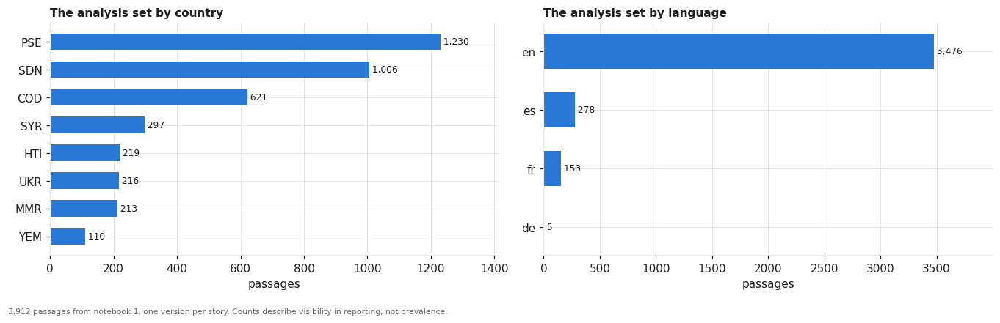


PRACTITIONER NOTE
  Check the input before using it, separating settings that would invalidate it from ones that would
  not. A blanket check that fails on any change trains people to switch it off; a check that names
  which setting changed, and whether it could affect the result, is one people keep.


In [ ]:
# @title
# ==================================================================================================
# PHASE: LOAD                                                         the only stage in this phase
# STAGE 12  LOAD THE HANDOVER
# WHAT THIS CELL DOES: loads notebook 1's bundle, checks it, keeps the analysis set
# ==================================================================================================
# WHAT THIS CELL DOES
#   Loads the handoff bundle written by notebook 1, checks it against this notebook's settings,
#   code and embedding file, and restores its contents into the namespace.
#
# WHY
#   A pipeline split across notebooks can silently run on stale state. Settings that could change
#   the passages or vectors are checked and block the run; settings that could not are only
#   reported.

import os, pickle, glob, hashlib
import numpy as np, pandas as pd

heading("STAGE 12  LOAD THE HANDOVER")

# The upstream/downstream lists come from Stage 1, which asserts every setting is in exactly one.
print(f"  classification        : {len(UPSTREAM_SETTINGS)} upstream, "
      f"{len(DOWNSTREAM_SETTINGS)} downstream, from Stage 1")

# ---- find the bundle --------------------------------------------------------
HANDOFF_DIR = os.path.join(DURABLE_CACHE, "handoff")
_candidates = sorted(glob.glob(os.path.join(HANDOFF_DIR, "handoff_nb1_to_nb2__*.pkl")),
                     key=os.path.getmtime, reverse=True)
print(f"  looking in            : {HANDOFF_DIR}")
print(f"  bundles found         : {len(_candidates)}")
if not _candidates:
    raise FileNotFoundError(
        f"No handoff bundle in {HANDOFF_DIR}. Run notebook 1 with the same storage mounted.")

# The bundle name carries both fingerprints, so the right one can be chosen before opening any file.
_expected_tail = f"__{CONFIG_FINGERPRINT}.pkl"
_matching = [p for p in _candidates if p.endswith(_expected_tail)]
if _matching:
    HANDOFF_PATH_IN = _matching[0]
    print(f"  selected by name      : the bundle whose config fingerprint matches this notebook")
else:
    HANDOFF_PATH_IN = _candidates[0]
    print(f"  selected by name      : no match; using the most recent bundle to report the diff")
for path in _candidates:
    marker = "  <- using" if path == HANDOFF_PATH_IN else ""
    print(f"      {os.path.basename(path)}  "
          f"{os.path.getsize(path)/1e6:6.1f} MB{marker}")

with open(HANDOFF_PATH_IN, "rb") as fh:
    HANDOFF = pickle.load(fh)
print()
print(f"  opened                : {os.path.basename(HANDOFF_PATH_IN)}")
print(f"  written               : {HANDOFF['written_at']} by run {HANDOFF['run_id']}")
print(f"  format version        : {HANDOFF['format_version']}")
READS_FORMAT_VERSIONS = (2,)
if HANDOFF["format_version"] not in READS_FORMAT_VERSIONS:
    raise RuntimeError(
        f"Bundle is format version {HANDOFF['format_version']}, this cell reads "
        f"{READS_FORMAT_VERSIONS}. Re-run notebook 1 from the same set of cells as this notebook.")

# ---- the corpus fingerprint -------------------------------------------------
print()
print("  CORPUS")
print(f"    bundle              : {HANDOFF['corpus_fingerprint']}")
print(f"    documents           : {len(HANDOFF['df_analysis']):,}")
print(f"    passages            : {len(HANDOFF['passages']):,}")
print(f"    {plural(HANDOFF['group_noun']):<19} : {len(HANDOFF['groups'])}")

# ---- the configuration diff -------------------------------------------------
_bundle_config = HANDOFF["config"]
_now_config = CFG.as_dict()
_all_keys = sorted(set(_bundle_config) | set(_now_config))

# A setting present on only one side is judged the same way as a changed one: by whether it could
# have affected what the bundle holds, not merely by being one-sided.
def classify(key):
    if key in UPSTREAM_SETTINGS:
        return "upstream"
    if key in DOWNSTREAM_SETTINGS:
        return "downstream"
    return "unclassified"


_unclassified = [k for k in _all_keys if classify(k) == "unclassified"]
_changed_upstream, _changed_downstream, _changed_unclassified = [], [], []
_added, _removed = [], []
for key in _all_keys:
    if key not in _bundle_config:
        _added.append(key)
    elif key not in _now_config:
        _removed.append(key)
    elif _bundle_config[key] == _now_config[key]:
        continue
    {"upstream": _changed_upstream, "downstream": _changed_downstream,
     "unclassified": _changed_unclassified}[classify(key)].append(key)


def _describe_setting(key):
    was = _bundle_config.get(key, "absent from the bundle")
    now = _now_config.get(key, "absent from this notebook")
    return f"{key:<32} bundle {str(was)[:22]:<24} now {str(now)[:22]}"

print()
print("  CONFIGURATION")
print(f"    bundle fingerprint  : {HANDOFF['config_fingerprint']}")
print(f"    this notebook       : {CONFIG_FINGERPRINT}")
print(f"    settings compared   : {len(_all_keys)}")
if _added:
    print(f"    added since the bundle: {len(_added)} "
          f"({', '.join(f'{k} [{classify(k)}]' for k in _added)})")
if _removed:
    print(f"    removed since the bundle: {len(_removed)} "
          f"({', '.join(f'{k} [{classify(k)}]' for k in _removed)})")
if _changed_downstream:
    print(f"    differing, downstream : {len(_changed_downstream)}  "
          f"(allowed: notebook 1 never read these)")
    for key in _changed_downstream:
        print(f"      {_describe_setting(key)}")
if _changed_unclassified:
    print(f"    differing, NOT CLASSIFIED : {len(_changed_unclassified)}")
    print(f"      Not in either list; add each to the correct list so it can be judged.")
    for key in _changed_unclassified:
        print(f"      {_describe_setting(key)}")
if _changed_upstream:
    print(f"    differing, UPSTREAM   : {len(_changed_upstream)}")
    for key in _changed_upstream:
        print(f"      {_describe_setting(key)}")
if not (_changed_upstream or _changed_downstream or _changed_unclassified):
    print(f"    every setting that could affect the bundle is identical on both sides")
if _unclassified and not _changed_unclassified:
    print(f"    {len(_unclassified)} setting(s) are unclassified but identical on both sides, so "
          f"nothing turns on them here")

CONFIG_DIFFERENCES = {"upstream": list(_changed_upstream), "downstream": list(_changed_downstream),
                      "unclassified": list(_changed_unclassified),
                      "added": list(_added), "removed": list(_removed)}

if _changed_upstream:
    raise RuntimeError(
        "Upstream settings differ between notebook 1 and this notebook, so the bundle may be "
        "stale. Restore those settings, or re-run notebook 1 and use its new bundle.")

# ---- the code that produced this bundle, against the code reading it ---------
_code_now = code_fingerprint(globals())
_code_diff = compare_code_fingerprints(HANDOFF.get("code_fingerprint"), _code_now)
print()
print("  CODE")
if not _code_diff["comparable"]:
    print(f"    {_code_diff['reason']}, no comparison possible")
elif _code_diff["identical"]:
    print(f"    identical: all {_code_now['counted']} functions match the ones that produced")
    print(f"    the bundle")
else:
    _n = len(_code_diff["changed"]) + len(_code_diff["added"]) + len(_code_diff["removed"])
    print(f"    {_n} function(s) differ from the code that produced this bundle (reported, not")
    print(f"    blocked; the settings check above decides validity).")
    for label, names in (("changed", _code_diff["changed"]), ("added", _code_diff["added"]),
                         ("removed", _code_diff["removed"])):
        if names:
            print(f"      {label}: {', '.join(names[:12])}"
                  f"{f' and {len(names) - 12} more' if len(names) > 12 else ''}")

# ---- the embedding, by the recorded name ------------------------------------
_record = HANDOFF["embedding_record"]
print()
print("  EMBEDDING")
print(f"    recorded file       : {_record['file']}")
print(f"    recorded shape      : {_record['shape']}  {_record['dtype']}")
if not _record["file"]:
    raise RuntimeError(
        "The bundle records no embedding file. Re-run notebook 1 Stage 9 with storage mounted.")

_search = [os.path.join(DURABLE_CACHE, _record["file"]),
           os.path.join(LOCAL_CACHE, _record["file"])]
X_PATH = next((p for p in _search if os.path.exists(p)), None)
if X_PATH is None:
    raise FileNotFoundError(
        f"The embedding file '{_record['file']}' is not in {DURABLE_CACHE} or {LOCAL_CACHE}. "
        f"Re-run notebook 1 Stage 9 with the same storage mounted.")

with open(X_PATH, "rb") as fh:
    X = pickle.load(fh)
_shape_ok = tuple(X.shape) == tuple(_record["shape"])
_hash_now = hashlib.sha256(np.ascontiguousarray(X).tobytes()).hexdigest()[:16]
_hash_ok = _hash_now == _record["sha256_first_16"]
print(f"    loaded from         : {os.path.dirname(X_PATH)}")
print(f"    shape matches       : {_shape_ok}   {tuple(X.shape)}")
print(f"    contents match      : {_hash_ok}   ({_hash_now} against {_record['sha256_first_16']})")
if not (_shape_ok and _hash_ok):
    raise RuntimeError(
        "The embedding file does not match what the bundle recorded, likely a partly written "
        "copy. Wait for the sync to finish and re-run this cell.")

# ---- restore the namespace --------------------------------------------------
passages          = HANDOFF["passages"]
df_analysis       = HANDOFF["df_analysis"]
Z_best            = HANDOFF["Z_best"]
BEST_UMAP         = tuple(HANDOFF["best_umap"])

# ---- the language offsets notebook 1 applied (Stage 9), applied again to the stored vectors ----
LANGUAGE_OFFSETS = HANDOFF.get("language_offsets") or {}
X = apply_language_offsets(X, passages["doc_language"].values, LANGUAGE_OFFSETS)
print(f"    language offsets    : "
      f"{', '.join(sorted(LANGUAGE_OFFSETS)) + ' removed' if LANGUAGE_OFFSETS else 'none'}")

# ---- the analysis set: the main version of each story, in prose, in its document's language ----
if "in_analysis" in passages.columns:
    _keep = passages["in_analysis"].to_numpy(dtype=bool)
    X = X[_keep]
    passages = passages.loc[_keep].reset_index(drop=True)
assert len(passages) == len(X) == len(Z_best), (
    f"passages {len(passages)}, vectors {len(X)}, projection {len(Z_best)}: out of alignment. "
    f"Re-run notebook 1.")
CHOSEN_MODEL      = HANDOFF["chosen_model"]
CORPUS_TEXT_FINGERPRINT = HANDOFF["corpus_fingerprint"]
CATEGORIES        = HANDOFF["categories"]
CODEBOOK          = HANDOFF["codebook"]
# len(CODEBOOK) is the number of CATEGORIES, not the number of patterns; the pattern count is
# carried in the bundle separately.
N_PATTERNS        = int(HANDOFF.get("n_patterns", 0))
SHORT_LABELS      = HANDOFF["short_labels"]
BARRIER_SUBTYPES  = HANDOFF["barrier_subtypes"]
CANONICAL         = HANDOFF["canonical"]
CAT_COLS          = HANDOFF["cat_cols"]
CURATED_PLACE_WORDS = set(HANDOFF.get("curated_place_words", []))
BAR_COLS          = HANDOFF["bar_cols"]
WEAK_CATEGORIES   = set(HANDOFF["weak_categories"])
PRECISION_TABLE   = HANDOFF["precision_table"]
PRECISION_SOURCE  = HANDOFF["precision_source"]
CAPABILITIES      = HANDOFF["capabilities"]
GROUPS            = HANDOFF["groups"]
GROUP_LABELS      = HANDOFF["group_labels"]
GROUP_MAIN        = HANDOFF["group_main"]
GROUP_ALL         = HANDOFF["group_all"]
GROUP_N           = HANDOFF["group_n"]
SCOPE_SENSITIVITY_RESULT = HANDOFF["scope_sensitivity"]

# The records ACCUMULATE: notebook 2 appends to what notebook 1 wrote, so the reconciliation at
# the end of notebook 3 accounts for the whole pipeline.
CORPUS_LEDGER   = list(HANDOFF["corpus_ledger"])
CLEANING_LEDGER = list(HANDOFF["cleaning_ledger"])
NUMBER_REGISTER = list(HANDOFF["number_register"]) + list(NUMBER_REGISTER)
FIGURE_LEDGER   = list(HANDOFF["figure_ledger"]) + list(FIGURE_LEDGER)
PRACTITIONER_NOTES = list(HANDOFF["practitioner_notes"]) + list(PRACTITIONER_NOTES)
ENVIRONMENT_NB1 = HANDOFF["environment"]

print()
print("  RESTORED")
print(f"    passages            : {len(passages):,} rows by {passages.shape[1]} columns")
print(f"    documents           : {len(df_analysis):,}")
print(f"    projection          : {Z_best.shape}  from setting {BEST_UMAP}")
print(f"    projection quality  : harmonic {HANDOFF['projection_harmonic']} "
      f"({HANDOFF['projection_decision']})")
print(f"    embedding           : {X.shape}")
print(f"    lexicon categories  : {len(CATEGORIES)}"
      f"{f'  ({N_PATTERNS:,} patterns)' if N_PATTERNS else '  (pattern count not in this bundle)'}")
# An empty weak-categories list means two different things: precision was measured and every
# category cleared the floor, or precision was never measured. These must not print the same way.
if PRECISION_TABLE is None or not len(PRECISION_TABLE):
    print(f"    lexicon precision   : NOT MEASURED  ({PRECISION_SOURCE})")
    print(f"      No category may be described as validated; the limitations must say precision")
    print(f"      is unmeasured. To measure it, code the sample notebook 1 Stage 7 wrote.")
    print(f"    weak categories     : none recorded, because none were tested")
    print(f"    place words shared  : {len(CURATED_PLACE_WORDS):,} from the masking stage")
else:
    print(f"    lexicon precision   : measured from {PRECISION_SOURCE}")
    print(f"      {len(PRECISION_TABLE)} categor(ies) tested, "
          f"mean precision {PRECISION_TABLE['precision'].mean():.2f}")
    print(f"    weak categories     : {', '.join(sorted(WEAK_CATEGORIES)) or 'none, all cleared'}")
print(f"    numbers carried in  : {len(HANDOFF['number_register'])}")
print(f"    figures carried in  : {len(HANDOFF['figure_ledger'])}")

# The environment may differ between the two notebooks; this is allowed and recorded here.
_nb1_env = {k: v for k, v in ENVIRONMENT_NB1.get("packages", {}).items()}
_now_env = {k: v for k, v in ENVIRONMENT.get("packages", {}).items()}
_env_diff = sorted(k for k in set(_nb1_env) | set(_now_env)
                   if _nb1_env.get(k, "absent") != _now_env.get(k, "absent"))
print()
print("  SOFTWARE")
if _env_diff:
    print(f"    {len(_env_diff)} package version(s) differ from the run that produced the bundle")
    print(f"    (recorded for traceability; does not invalidate anything).")
    for key in _env_diff:
        print(f"      {key:<24} notebook 1 {_nb1_env.get(key,'absent'):<14} "
              f"here {_now_env.get(key,'absent')}")
else:
    print(f"    identical to the run that produced the bundle")
rule()


# ---- figure: the analysis set this notebook clusters -----------------------------------------
import matplotlib.pyplot as plt
_by = [(name, passages[column].astype(str)) for name, column in
       ((CFG.group_noun, group_column(passages)), ("language", "doc_language"))
       if column and column in passages.columns]
if _by:
    fig, axes = plt.subplots(1, len(_by), figsize=(6.2 * len(_by), 3.8), squeeze=False)
    for ax, (name, values) in zip(axes[0], _by):
        counts = values.value_counts()
        ax.barh(counts.index[::-1], counts.values[::-1], color=PALETTE[0], height=0.6)
        for k, v in enumerate(counts.values[::-1]):
            ax.text(v, k, f" {v:,}", va="center", fontsize=8)
        ax.set_xlim(0, counts.max() * 1.15)
        ax.set_xlabel("passages")
        ax.set_title(f"The analysis set by {name}", fontsize=10, loc="left")
    fig.tight_layout()
    add_reference_footer(fig, f"{len(passages):,} passages from notebook 1, one version per story. "
                              f"Counts describe visibility in reporting, not prevalence.")
    save_figure(fig, "s12_analysis_set")
    plt.show()

report("handoff.passages_in", len(passages), "passages", "Stage 12")
report("handoff.documents_in", len(df_analysis), "documents", "Stage 12")

practitioner_note("Reading a handoff", """
Check the input before using it, separating settings that would invalidate it from ones that would
not. A blanket check that fails on any change trains people to switch it off; a check that names
which setting changed, and whether it could affect the result, is one people keep.
""")

## Stage 13: 2-d map   [phase: dimension reduction]

**What.** A two-dimensional UMAP of the passages, for drawing only, coloured by language, country,
lexicon category and passage length, before anything is clustered.

**Why.** If one language or one country owns a region, a clustering will spend a cluster on it. This
is visible here first. The clustering itself uses the multi-dimensional projection of notebook 1.

  STAGE 13  2-D MAP
  [umap_2d_view] not cached for key 236efe5dc4b2; computing ...
  [umap_2d_view] computed and saved | key 236efe5dc4b2 | 0.0 MB | copied to durable storage
  passages                  : 3,912
  embedding                 : 4,096 dimensions from qwen3-8b
  projection for clustering : 5 dimensions, n_neighbors=80, min_dist=0.1 (quality 0.942, notebook 1)
  projection for this figure: 2 dimensions, same neighbours and distance

  panels                    : 4
    language             4 value(s)   a region of one language is a warning, not a theme
    country              8 value(s)   a region of one country means place, not subject
    lexicon category    13 value(s)   the deductive codebook, for comparison with what the clustering finds
    passage length       4 value(s)   a region of one length is an artefact of the splitter
  figure saved: s13_space_before_clustering (PNG, SVG, 16x9; local and Drive)


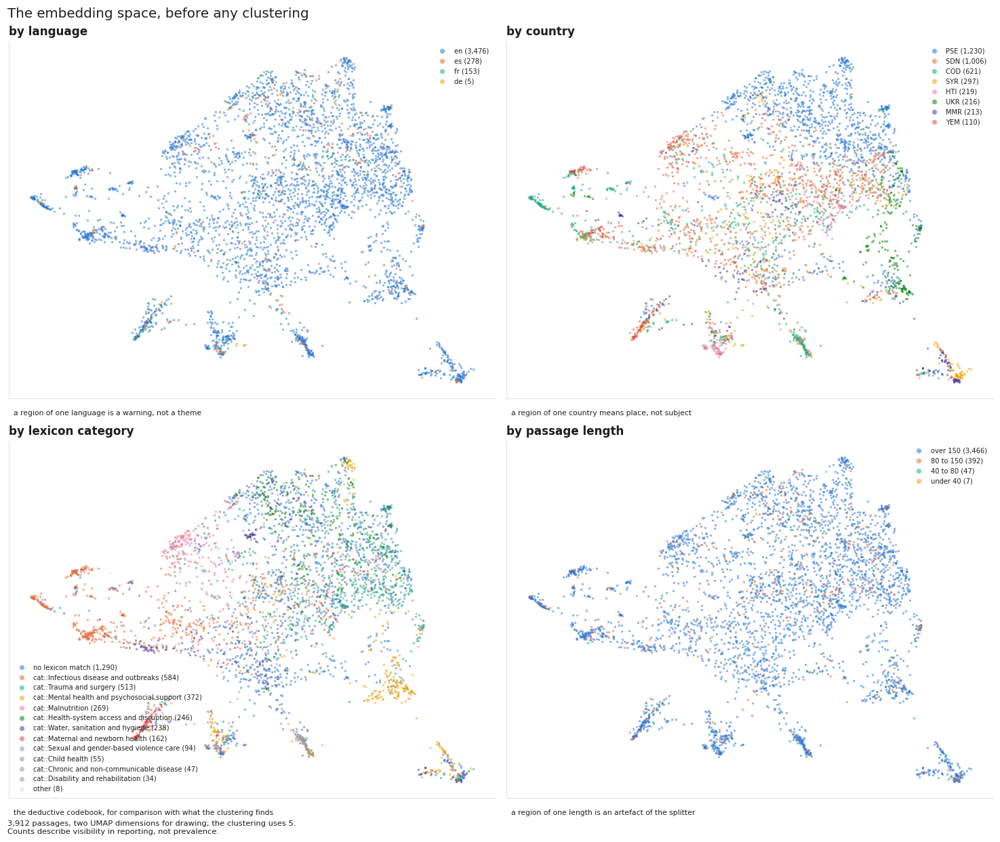


  language separation (silhouette of language labels, 2,000 passages): -0.007
    near 0: languages mixed, as a multilingual embedding should be; above 0.10: separate regions
  language offsets (notebook 1, Stage 9): applied to es, fr; held-out translations finding their English original 1% -> 28%

PRACTITIONER NOTE
  Colour the space by everything you did not intend to cluster on: language, source, place, length.
  If one of those owns a region, the clustering will return it as a theme.


In [ ]:
# @title
# ==================================================================================================
# PHASE: DIMENSION REDUCTION                                          the only stage in this phase
# STAGE 13  2-D MAP
# WHAT THIS CELL DOES: a two-dimensional UMAP for drawing, coloured by language, place, lexicon and
#                      length
# ==================================================================================================
# WHAT THIS CELL DOES
#   Dimension reduction for drawing: a two-dimensional UMAP of the analysis set, coloured by
#   language, country, lexicon category and passage length, before anything is clustered.
#
# WHY
#   If one language or one country owns a region of the space, a clustering will spend a cluster on
#   it. That is visible here first. The clustering itself (Stage 14) uses the multi-dimensional
#   projection of notebook 1, not this one; the 2-D view is a further, display-only compression.

import numpy as np, pandas as pd
import matplotlib.pyplot as plt

heading("STAGE 13  2-D MAP")

PROJECTION_2D = cached("umap_2d_view", lambda: project((BEST_UMAP[0], BEST_UMAP[1], 2), seed=CFG.seed),
                       inputs=[CORPUS_TEXT_FINGERPRINT, CHOSEN_MODEL, BEST_UMAP[0], BEST_UMAP[1],
                               2, CFG.seed],
                       note="two dimensions, for drawing only", scope="inputs")

print(f"  passages                  : {len(passages):,}")
print(f"  embedding                 : {X.shape[1]:,} dimensions from {CHOSEN_MODEL}")
print(f"  projection for clustering : {BEST_UMAP[2]} dimensions, "
      f"n_neighbors={BEST_UMAP[0]}, min_dist={BEST_UMAP[1]} "
      f"(quality {HANDOFF['projection_harmonic']}, notebook 1)")
print(f"  projection for this figure: 2 dimensions, same neighbours and distance")

# ---- what to colour by, given what this corpus has -------------------------
_group = group_column(passages)
_language = "doc_language" if "doc_language" in passages.columns else None
_words = passages["text"].astype(str).str.split().str.len()

PANELS = []
if _language:
    PANELS.append(("language", passages[_language].astype(str),
                   "a region of one language is a warning, not a theme"))
if _group:
    PANELS.append((CFG.group_noun, passages[_group].astype(str),
                   "a region of one " + CFG.group_noun + " means place, not subject"))
_main_category = None
if CAT_COLS:
    _counts = passages[CAT_COLS].sum(axis=1)
    _first = passages[CAT_COLS].idxmax(axis=1).where(_counts > 0, "no lexicon match")
    _main_category = _first.map(lambda c: SHORT_LABELS.get(str(c).replace("cat_", ""), str(c)))
    PANELS.append(("lexicon category", _main_category,
                   "the deductive codebook, for comparison with what the clustering finds"))
PANELS.append(("passage length", pd.cut(_words, bins=[0, 40, 80, 150, 10**6],
                                        labels=["under 40", "40 to 80", "80 to 150", "over 150"]),
               "a region of one length is an artefact of the splitter"))

print()
print(f"  panels                    : {len(PANELS)}")
for name, series, why in PANELS:
    print(f"    {name:<18} {series.astype(str).nunique():>3} value(s)   {why}")

# ---- the figure -------------------------------------------------------------
_rows = (len(PANELS) + 1) // 2
fig, axes = plt.subplots(_rows, 2, figsize=(13.5, 5.6 * _rows))
axes = np.atleast_1d(axes).ravel()
_order = np.random.default_rng(CFG.seed).permutation(len(passages))   # so no group draws on top

for index, (name, series, why) in enumerate(PANELS):
    ax = axes[index]
    values = series.astype(str).to_numpy()
    labels = pd.Series(values).value_counts()
    shown = list(labels.index[:12])
    colours = dict(zip(shown, palette(len(shown))))
    for value in shown:
        mask = (values == value)[_order]
        points = PROJECTION_2D[_order][mask]
        ax.scatter(points[:, 0], points[:, 1], s=CFG.style("point_size"),
                   alpha=CFG.style("point_opacity"), linewidths=0,
                   color=colours[value], label=f"{value} ({int(labels[value]):,})")
    _other = ~np.isin(values, shown)
    if _other.any():
        points = PROJECTION_2D[_order][_other[_order]]
        ax.scatter(points[:, 0], points[:, 1], s=CFG.style("point_size"),
                   alpha=0.25, linewidths=0, color="#BBBBBB",
                   label=f"other ({int(_other.sum()):,})")
    ax.set_title(f"by {name}", fontsize=11, loc="left")
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(fontsize=6.5, frameon=False, markerscale=2.2, loc="best", ncol=1)
    ax.text(0.01, -0.03, why, transform=ax.transAxes, fontsize=7, color=INK, va="top")

for index in range(len(PANELS), len(axes)):
    axes[index].axis("off")

fig.suptitle("The embedding space, before any clustering", fontsize=13, x=0.01, ha="left")
fig.text(0.01, -0.01,
         f"{len(passages):,} passages, two UMAP dimensions for drawing; the clustering uses "
         f"{BEST_UMAP[2]}.\nCounts describe visibility in reporting, not prevalence.",
         fontsize=7.5, ha="left")
fig.tight_layout()
save_figure(fig, "s13_space_before_clustering", slide_ready=True)
plt.show()

# ---- how far apart are the languages already? -------------------------------------------------
if _language:
    from sklearn.metrics import silhouette_score
    _codes = pd.factorize(passages[_language].astype(str))[0]
    if len(np.unique(_codes)) > 1:
        _sample = np.random.default_rng(CFG.seed).choice(
            len(passages), size=min(2000, len(passages)), replace=False)
        MAP_LANGUAGE_SEPARATION = float(silhouette_score(PROJECTION_2D[_sample], _codes[_sample]))
        print()
        print(f"  language separation (silhouette of language labels, 2,000 passages): "
              f"{MAP_LANGUAGE_SEPARATION:.3f}")
        print(f"    near 0: languages mixed, as a multilingual embedding should be; above 0.10: "
              f"separate regions")
        report("projection.language_separation", round(MAP_LANGUAGE_SEPARATION, 4),
               "silhouette", "Stage 13")
    else:
        MAP_LANGUAGE_SEPARATION = float("nan")
else:
    MAP_LANGUAGE_SEPARATION = float("nan")
    print()
    print(f"  No detected-language column: no language panel or measure.")
_correction = HANDOFF.get("language_correction") or {}
if _correction.get("top1_before") is not None:
    _status = ("applied to " + ", ".join(_correction.get("languages", []))
               if _correction.get("applied") else "not applied")
    print(f"  language offsets (notebook 1, Stage 9): {_status}; held-out translations finding "
          f"their English original {_correction['top1_before']:.0%} -> "
          f"{_correction['top1_after']:.0%}")
rule()

practitioner_note("Look at the space before you cut it", """
Colour the space by everything you did not intend to cluster on: language, source, place, length.
If one of those owns a region, the clustering will return it as a theme.
""")

## Stage 14: sub-themes   [phase: clustering]

**What.** Finds every distinct topic. The number of sub-themes is not set; the data decide it.

**Method.**
1. **Projections.** Notebook 1's UMAP projection and four more with other seeds.
2. **HDBSCAN** (Campello, Moulavi and Sander 2013) on each, keeping the *leaf* clusters of its tree,
   the finest stable groups (McInnes, Healy and Astels 2017). The only input is the smallest
   sub-theme: 5 passages per country x number of countries, the smallest group that can be compared
   across all countries (Cochran 1954). Passages in no dense region are held aside at first.
3. **The reported run** is the one that agrees best with the other seeds (adjusted Rand index).
4. **Held-aside passages** join the sub-theme whose centroid is most similar, and are flagged; they
   are never quoted as evidence.

**Figure.** Step 1 shows how many sub-themes each minimum size gives, so the choice can be judged.
Step 2 shows the sub-themes on the map, and their sizes.

**Switch.** `SUBTHEME_METHOD = "ward"` in Stage 1 uses Ward's method instead, cut at the largest jump
in fusion height. Everything after this cell works with either.

**Checks per sub-theme.** Coherence (silhouette in the embedding space), confidence (share of seeds
that keep each passage in place) and language (is it held together by one language?).

  STAGE 14  SUB-THEMES
  passages              : 3,912, in 5 UMAP dimensions
  method                : hdbscan
  smallest sub-theme    : 40 passages (5 per country x 8)
  UMAP seeds            : [42, 43, 44, 45, 46]
  [umap_seed_43] not cached for key 77a8a0173af5; computing ...
  [umap_seed_43] computed and saved | key 77a8a0173af5 | 0.1 MB | copied to durable storage
  [umap_seed_44] not cached for key e14508a3efa4; computing ...
  [umap_seed_44] computed and saved | key e14508a3efa4 | 0.1 MB | copied to durable storage
  [umap_seed_45] not cached for key 560d19ac766c; computing ...
  [umap_seed_45] computed and saved | key 560d19ac766c | 0.1 MB | copied to durable storage
  [umap_seed_46] not cached for key 7f1452d2758c; computing ...
  [umap_seed_46] computed and saved | key 7f1452d2758c | 0.1 MB | copied to durable storage

  STEP 1  minimum size against the result (mean over the seeds)
 min_size  sub_themes  held_aside  seed_agreement
       20        24.8       0.532           0

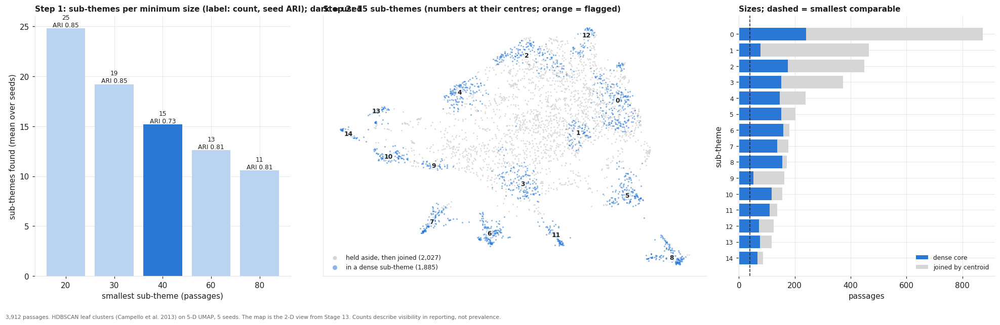


PRACTITIONER NOTE
  Do not fix the number of clusters. State the smallest group worth reporting, let a density method
  find how many such groups the data hold, and show how that number moves when the minimum moves.


In [ ]:
# @title
# ==================================================================================================
# PHASE: CLUSTERING                                                     stage 1 of 2 in this phase
# STAGE 14  SUB-THEMES
# WHAT THIS CELL DOES: fine level: HDBSCAN on five UMAP seeds finds every distinct topic; the count
#                      is found
# ==================================================================================================
# WHAT THIS CELL DOES
#   Clustering, fine level: finds the SUB-THEMES, every distinct topic in the analysis set.
#   Step 1 shows how the number of sub-themes depends on the minimum size; step 2 clusters.
#
# WHY
#   The number of sub-themes is not set in advance. HDBSCAN finds as many dense groups as the data
#   hold, given only the smallest group worth reporting: one that can be compared across all
#   groups, MIN_EXPECTED_CELL passages per group (Cochran 1954).
#
# HOW
#   1. The UMAP projection from notebook 1, and CLUSTER_SEEDS - 1 more with other seeds.
#   2. On each, HDBSCAN (Campello, Moulavi and Sander 2013) keeps the leaf clusters of its tree
#      (McInnes, Healy and Astels 2017); passages in no dense region are held aside. With
#      SUBTHEME_METHOD = "ward", Ward's tree is cut at the largest jump in fusion height instead.
#   3. The reported run is the one that agrees best with the others (mean adjusted Rand index).
#   4. Held-aside passages join the sub-theme with the most similar centroid and are flagged.
#   5. Confidence: the share of the other runs that keep a passage in the same sub-theme.
#      Coherence: mean silhouette in the embedding space, cosine (Rousseeuw 1987).
#
# REFERENCES
#   Campello, R.J.G.B., Moulavi, D. and Sander, J. (2013) Density-based clustering based on
#     hierarchical density estimates. In PAKDD 2013, LNCS 7819:160-172. Springer.
#   Cochran, W.G. (1954) Some methods for strengthening the common chi-square tests. Biometrics
#     10(4):417-451.
#   McInnes, L., Healy, J. and Astels, S. (2017) hdbscan: hierarchical density based clustering.
#     Journal of Open Source Software 2(11):205.
#   Rousseeuw, P.J. (1987) Silhouettes: a graphical aid to the interpretation and validation of
#     cluster analysis. Journal of Computational and Applied Mathematics 20:53-65.

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_samples

heading("STAGE 14  SUB-THEMES")

passages = passages.reset_index(drop=True).copy()
N_PASSAGES = len(passages)
_group = group_column(passages)
N_GROUPS = int(passages[_group].nunique()) if _group else 1
MIN_SUBTHEME_SIZE = int(CFG.hdbscan_min_size or int(CFG.min_expected_cell) * max(N_GROUPS, 1))
METHOD = CFG.subtheme_method
SEEDS = [int(CFG.seed) + i for i in range(int(CFG.cluster_seeds))]

print(f"  passages              : {N_PASSAGES:,}, in {BEST_UMAP[2]} UMAP dimensions")
print(f"  method                : {METHOD}")
print(f"  smallest sub-theme    : {MIN_SUBTHEME_SIZE} passages "
      f"({int(CFG.min_expected_cell)} per {CFG.group_noun} x {N_GROUPS})")
print(f"  UMAP seeds            : {SEEDS}")


# ---- the projections: notebook 1's, and one per further seed -------------------------------
def _projection(seed):
    if seed == int(CFG.seed):
        return Z_best
    return cached(f"umap_seed_{seed}", lambda: project(BEST_UMAP, seed=seed),
                  inputs=[CORPUS_TEXT_FINGERPRINT, CHOSEN_MODEL, tuple(BEST_UMAP), seed],
                  note="a further UMAP run for the sub-theme consensus", scope="inputs")


PROJECTIONS = [_projection(seed) for seed in SEEDS]


def _run(points, min_size=MIN_SUBTHEME_SIZE):
    raw, jumps = find_subthemes(points, METHOD, min_size, CFG.ward_k_range,
                                CFG.subtheme_count_fixed)
    full, _ = attach_noise(X, raw)
    return raw, full, jumps


# ---- step 1: how the number of sub-themes depends on the minimum size ---------------------
SENSITIVITY = pd.DataFrame()
if METHOD == "hdbscan":
    _sizes = sorted({max(5, int(round(MIN_SUBTHEME_SIZE * f))) for f in (0.5, 0.75, 1, 1.5, 2)})
    rows = []
    for size in _sizes:
        runs = [_run(points, size) for points in PROJECTIONS]
        counts = [int(len(np.unique(raw[raw >= 0]))) for raw, _, _ in runs]
        _, agreement = medoid_partition([full for _, full, _ in runs])
        pairs = agreement[np.triu_indices(len(runs), 1)]
        rows.append({"min_size": size, "sub_themes": float(np.mean(counts)),
                     "held_aside": float(np.mean([(raw < 0).mean() for raw, _, _ in runs])),
                     "seed_agreement": float(pairs.mean()) if len(pairs) else float("nan")})
    SENSITIVITY = pd.DataFrame(rows)
    print()
    print("  STEP 1  minimum size against the result (mean over the seeds)")
    print(SENSITIVITY.round(3).to_string(index=False))

# ---- step 2: cluster every projection, keep the run that agrees best -----------------------
RUNS = [_run(points) for points in PROJECTIONS]
_too_few = [s for s, (raw, _, _) in zip(SEEDS, RUNS) if len(np.unique(raw[raw >= 0])) < 2]
if _too_few:
    raise RuntimeError(f"Fewer than two sub-themes on seed(s) {_too_few}. The space has no dense "
                       f"groups of {MIN_SUBTHEME_SIZE}; set HDBSCAN_MIN_SIZE lower in Stage 1.")
REFERENCE_RUN, SEED_ARI = medoid_partition([full for _, full, _ in RUNS])
SUBTHEME_SEED_AGREEMENT = float(SEED_ARI[np.triu_indices(len(RUNS), 1)].mean())
_raw, _full, WARD_JUMPS = RUNS[REFERENCE_RUN]

# Number the sub-themes by size, largest first, so "sub-theme 0" is always the largest.
_order = pd.Series(_full).value_counts().index
_renumber = {int(old): new for new, old in enumerate(_order)}
SUB_LABELS = np.array([_renumber[int(v)] for v in _full])
ASSIGNED_BY_CENTROID = _raw < 0
K_SUB_OBTAINED = int(len(_renumber))

# ---- confidence: does each passage stay in its sub-theme on the other seeds? ---------------
_others = [i for i in range(len(RUNS)) if i != REFERENCE_RUN]
_agree = np.zeros(N_PASSAGES)
for i in _others:
    _agree += align_to(SUB_LABELS, RUNS[i][1]) == SUB_LABELS
passages["theme_sub"] = SUB_LABELS
passages["assigned_by_centroid"] = ASSIGNED_BY_CENTROID
passages["confidence_sub"] = _agree / max(len(_others), 1)
passages["low_confidence"] = passages["confidence_sub"] < float(CFG.confidence_floor)
passages["misplaced_signal"] = passages["confidence_sub"] < 0.5

# ---- coherence: is each sub-theme closer to itself than to its neighbours? -----------------
passages["silhouette_sub"] = silhouette_samples(X, SUB_LABELS, metric="cosine")
_coherence = passages.groupby("theme_sub")["silhouette_sub"].mean()
INCOHERENT_SUBTHEMES = set(int(v) for v in
                           _coherence.index[_coherence < float(CFG.coherence_floor)])
LARGEST_SUB_SHARE = float(pd.Series(SUB_LABELS).value_counts(normalize=True).iloc[0])

# ---- is a sub-theme held together by a language rather than a subject? ---------------------
LANGUAGE_ARTEFACT_SUBTHEMES = set()
LANGUAGE_TABLE = pd.DataFrame()
if "doc_language" in passages.columns:
    _corpus_share = passages["doc_language"].astype(str).value_counts(normalize=True)
    rows = []
    for value, block in passages.groupby("theme_sub"):
        shares = block["doc_language"].astype(str).value_counts(normalize=True)
        rows.append({"theme_sub": int(value), "passages": len(block),
                     "dominant_language": shares.index[0],
                     "dominant_share": float(shares.iloc[0]),
                     "corpus_share_of_that_language": float(_corpus_share.get(shares.index[0], 0))})
    LANGUAGE_TABLE = pd.DataFrame(rows)
    LANGUAGE_TABLE["language_artefact"] = (
        (LANGUAGE_TABLE["dominant_share"] >= float(CFG.language_artefact_share))
        & (LANGUAGE_TABLE["corpus_share_of_that_language"]
           <= float(CFG.language_artefact_corpus_max)))
    LANGUAGE_ARTEFACT_SUBTHEMES = set(
        int(v) for v in LANGUAGE_TABLE.loc[LANGUAGE_TABLE["language_artefact"], "theme_sub"])
WEAK_SUBTHEMES = INCOHERENT_SUBTHEMES | LANGUAGE_ARTEFACT_SUBTHEMES

# ---- the sub-theme table ---------------------------------------------------------------------
rows = []
for value in range(K_SUB_OBTAINED):
    members = passages["theme_sub"] == value
    rows.append({
        "theme_sub": value, "passages": int(members.sum()), "share": float(members.mean()),
        "documents": int(passages.loc[members, "doc_id"].nunique()),
        "coherence": float(_coherence.get(value, np.nan)),
        "confidence_mean": float(passages.loc[members, "confidence_sub"].mean()),
        "below_floor": int(passages.loc[members, "low_confidence"].sum()),
        "incoherent": value in INCOHERENT_SUBTHEMES,
        "language_artefact": value in LANGUAGE_ARTEFACT_SUBTHEMES,
        "centroid_assigned": int(passages.loc[members, "assigned_by_centroid"].sum()),
        "too_small_to_compare": int(members.sum()) < MIN_SUBTHEME_SIZE,
    })
SUBTHEME_TABLE = pd.DataFrame(rows)

print()
print(f"  STEP 2  RESULT: {K_SUB_OBTAINED} sub-themes")
print(f"    reported run          : seed {SEEDS[REFERENCE_RUN]} (best mean agreement with the "
      f"others)")
print(f"    agreement across seeds: adjusted Rand {SUBTHEME_SEED_AGREEMENT:.3f}")
print(f"    held aside, then joined to the nearest sub-theme: {int(ASSIGNED_BY_CENTROID.sum()):,} "
      f"({ASSIGNED_BY_CENTROID.mean():.1%})")
print(f"    held weakly (confidence below {CFG.confidence_floor}): "
      f"{int(passages['low_confidence'].sum()):,}")
print(f"    incoherent (silhouette below {CFG.coherence_floor}): "
      f"{sorted(INCOHERENT_SUBTHEMES) or 'none'}")
print(f"    one language dominates   : {sorted(LANGUAGE_ARTEFACT_SUBTHEMES) or 'none'}")
print()
print(f"    {'sub':>4}  {'passages':>8}  {'joined':>6}  {'docs':>5}  {'silhouette':>10}  "
      f"{'confidence':>10}  flags")
for _, row in SUBTHEME_TABLE.iterrows():
    flags = ", ".join(f for f, on in (("incoherent", row["incoherent"]),
                                      ("one language", row["language_artefact"]),
                                      ("too small to compare", row["too_small_to_compare"])) if on)
    print(f"    {int(row['theme_sub']):>4}  {int(row['passages']):>8,}  "
          f"{int(row['centroid_assigned']):>6,}  {int(row['documents']):>5,}  "
          f"{row['coherence']:>10.3f}  {row['confidence_mean']:>10.2f}  {flags}")

# ---- figure: step 1 the minimum size, step 2 the sub-themes on the map ---------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={"width_ratios": [1, 1.5, 1]})
ax = axes[0]
if len(SENSITIVITY):
    ax.bar(SENSITIVITY["min_size"].astype(str), SENSITIVITY["sub_themes"],
           color=[PALETTE[0] if s == MIN_SUBTHEME_SIZE else "#b9d3f0"
                  for s in SENSITIVITY["min_size"]])
    for i, row in SENSITIVITY.reset_index(drop=True).iterrows():
        ax.text(i, row["sub_themes"], f"{row['sub_themes']:.0f}\nARI {row['seed_agreement']:.2f}",
                ha="center", va="bottom", fontsize=8)
    ax.set_xlabel("smallest sub-theme (passages)")
    ax.set_ylabel("sub-themes found (mean over seeds)")
    ax.set_title("Step 1: sub-themes per minimum size (label: count, seed ARI); dark = used",
                 fontsize=10, loc="left")
elif WARD_JUMPS:
    ks = sorted(WARD_JUMPS)
    ax.bar([str(k) for k in ks], [WARD_JUMPS[k] for k in ks],
           color=[PALETTE[0] if k == K_SUB_OBTAINED else "#b9d3f0" for k in ks])
    ax.set_xlabel("number of sub-themes")
    ax.set_ylabel("jump in Ward fusion height")
    ax.tick_params(axis="x", labelsize=6)
    ax.set_title("Step 1: largest jump = number used", fontsize=10, loc="left")
else:
    ax.axis("off")

ax = axes[1]
_shuffle = np.random.default_rng(CFG.seed).permutation(N_PASSAGES)
_aside = ASSIGNED_BY_CENTROID[_shuffle]
_xy = PROJECTION_2D[_shuffle]
ax.scatter(_xy[_aside, 0], _xy[_aside, 1], s=3, color="#d6d6d6", linewidths=0,
           label=f"held aside, then joined ({int(ASSIGNED_BY_CENTROID.sum()):,})")
ax.scatter(_xy[~_aside, 0], _xy[~_aside, 1], s=4, color=PALETTE[0], alpha=0.55, linewidths=0,
           label=f"in a dense sub-theme ({int((~ASSIGNED_BY_CENTROID).sum()):,})")
for value in range(K_SUB_OBTAINED):
    core = (SUB_LABELS == value) & ~ASSIGNED_BY_CENTROID
    if not core.any():
        core = SUB_LABELS == value
    cx, cy = np.median(PROJECTION_2D[core], axis=0)
    ax.text(cx, cy, str(value), fontsize=8, fontweight="bold", ha="center", va="center",
            color=WARN if value in WEAK_SUBTHEMES else INK,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(fontsize=8, frameon=False, markerscale=3, loc="lower left")
ax.set_title(f"Step 2: {K_SUB_OBTAINED} sub-themes (numbers at their centres; orange = flagged)",
             fontsize=10, loc="left")

ax = axes[2]
_t = SUBTHEME_TABLE.sort_values("theme_sub", ascending=False)
_direct = _t["passages"] - _t["centroid_assigned"]
ax.barh(_t["theme_sub"].astype(str), _direct, color=PALETTE[0], label="dense core")
ax.barh(_t["theme_sub"].astype(str), _t["centroid_assigned"], left=_direct, color="#d6d6d6",
        label="joined by centroid")
ax.axvline(MIN_SUBTHEME_SIZE, color=INK, ls="--", lw=1)
ax.tick_params(axis="y", labelsize=7 if K_SUB_OBTAINED > 30 else 8)
ax.set_xlabel("passages")
ax.set_ylabel("sub-theme")
ax.legend(fontsize=8, frameon=False, loc="lower right")
ax.set_title("Sizes; dashed = smallest comparable", fontsize=10, loc="left")
fig.tight_layout()
add_reference_footer(fig, f"{N_PASSAGES:,} passages. HDBSCAN leaf clusters (Campello et al. 2013) "
                          f"on {BEST_UMAP[2]}-D UMAP, {len(SEEDS)} seeds. The map is the 2-D view "
                          f"from Stage 13. Counts describe visibility in reporting, not prevalence."
                     if METHOD == "hdbscan" else
                     f"{N_PASSAGES:,} passages. Ward (1963) on {BEST_UMAP[2]}-D UMAP, cut at the "
                     f"largest fusion jump (Mojena 1977). Counts describe visibility, not "
                     f"prevalence.")
save_figure(fig, "s14_subthemes", slide_ready=True)
plt.show()
rule()

report("subthemes.count", K_SUB_OBTAINED, "sub-themes", "Stage 14")
report("subthemes.min_size", MIN_SUBTHEME_SIZE, "passages", "Stage 14")
report("subthemes.seed_agreement", round(SUBTHEME_SEED_AGREEMENT, 4), "adjusted Rand", "Stage 14")
report("subthemes.held_aside", int(ASSIGNED_BY_CENTROID.sum()), "passages", "Stage 14")
report("subthemes.largest_share", round(LARGEST_SUB_SHARE, 4), "share", "Stage 14")
report("subthemes.incoherent", len(INCOHERENT_SUBTHEMES), "sub-themes", "Stage 14")
report("subthemes.language_artefacts", len(LANGUAGE_ARTEFACT_SUBTHEMES), "sub-themes", "Stage 14")
report("subthemes.below_confidence_floor", int(passages["low_confidence"].sum()),
       "passages", "Stage 14")

practitioner_note("Letting the data set the number", """
Do not fix the number of clusters. State the smallest group worth reporting, let a density method
find how many such groups the data hold, and show how that number moves when the minimum moves.
""")

## Stage 15: themes   [phase: clustering]

**What.** Groups similar sub-themes into themes, so all themes appear at a readable level.

**Method.** Ward's method (Ward 1963) on the sub-theme centroids in the 4,096-dimensional embedding
space; UMAP keeps neighbourhoods but not large distances, and themes depend on large distances. The
tree is cut where the next merge would cost the most: the largest jump in fusion height (Mojena 1977),
between 4 and 12 themes. Each sub-theme counts once, so a small distinct topic is not absorbed because
it is small. This mirrors thematic analysis: codes first, then themes (Braun and Clarke 2006).

**Figure.** Step 1: the jump for each number of themes. Step 2: the tree of sub-themes coloured by
theme, and the themes on the map.

  STAGE 15  THEMES
  sub-themes grouped    : 15
  STEP 1  number of themes: 9  (chosen by: largest jump in fusion height)
    largest jumps       : 9 themes 0.063, 7 themes 0.055, 6 themes 0.048

  STEP 2  RESULT: 9 themes over 15 sub-themes
    agreement across seeds : adjusted Rand 0.775
    mean silhouette        : 0.178
    largest theme          : 34.2% of passages
    incoherent             : [1]

    theme  passages  silhouette  confidence  sub-themes
        0     1,337       0.300        0.97  0, 1
        1       946      -0.003        0.73  2, 3, 12  <- incoherent
        2       402       0.098        0.96  4, 9
        3       359       0.208        0.98  10, 13, 14
        4       202       0.175        0.97  5
        5       180       0.174        0.97  6
        6       177       0.225        0.97  7
        7       172       0.159        0.99  8
        8       137       0.353        0.97  11
  figure saved: s15_themes (PNG, SVG, 16x9; local and Drive)


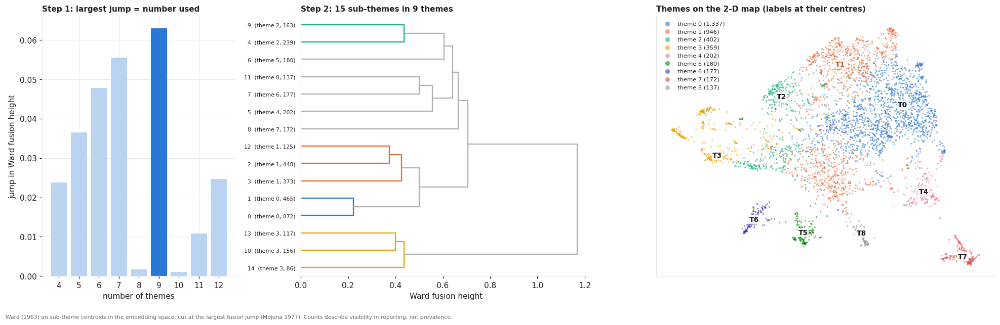


PRACTITIONER NOTE
  Find the fine groups first, check each one, then group the groups. Show which small groups make up
  each theme, so a reader can judge the grouping, and state the rule that chose how many themes.


In [ ]:
# @title
# ==================================================================================================
# PHASE: CLUSTERING                                                     stage 2 of 2 in this phase
# STAGE 15  THEMES
# WHAT THIS CELL DOES: standard level: Ward groups the sub-themes into themes, cut at the largest
#                      jump
# ==================================================================================================
# WHAT THIS CELL DOES
#   Clustering, standard level: groups similar sub-themes into THEMES. Step 1 chooses the number
#   of themes; step 2 shows which sub-themes each theme holds.
#
# WHY
#   Sub-themes answer "which topics are there"; themes answer "which topics belong together". The
#   grouping is done in the 4,096-dimensional embedding space, because UMAP keeps neighbourhoods
#   but not large distances (McInnes, Healy and Melville 2018), and themes depend on large
#   distances. Every sub-theme lies in exactly one theme, so the two levels nest.
#
# HOW
#   Ward's method (Ward 1963) on the sub-theme centroids. Each sub-theme counts once, so a small
#   but distinct sub-theme is not absorbed because it is small. The tree is cut where the next
#   merge would cost the most: the largest jump in fusion height (Mojena 1977) within
#   THEME_K_RANGE. This is how codes are grouped into themes in thematic analysis (Braun and
#   Clarke 2006). Coherence: mean silhouette, cosine, in the embedding space (Rousseeuw 1987).
#
# REFERENCES
#   Braun, V. and Clarke, V. (2006) Using thematic analysis in psychology. Qualitative Research in
#     Psychology 3(2):77-101.
#   McInnes, L., Healy, J. and Melville, J. (2018) UMAP: Uniform Manifold Approximation and
#     Projection for dimension reduction. arXiv:1802.03426.
#   Mojena, R. (1977) Hierarchical grouping methods and stopping rules: an evaluation. The Computer
#     Journal 20(4):359-363.
#   Rousseeuw, P.J. (1987) Silhouettes: a graphical aid to the interpretation and validation of
#     cluster analysis. Journal of Computational and Applied Mathematics 20:53-65.
#   Ward, J.H. (1963) Hierarchical grouping to optimize an objective function. Journal of the
#     American Statistical Association 58(301):236-244.

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from sklearn.metrics import silhouette_samples

heading("STAGE 15  THEMES")

# ---- step 1: the number of themes ------------------------------------------------------------
THEME_OF_SUBTHEME, THEME_TREE, THEME_JUMPS = build_themes(
    X, SUB_LABELS, CFG.theme_k_range, CFG.theme_count_fixed)
# Number the themes by size, largest first.
_sizes = pd.Series(SUB_LABELS).map(THEME_OF_SUBTHEME).value_counts()
_renumber = {int(old): new for new, old in enumerate(_sizes.index)}
THEME_OF_SUBTHEME = {s: _renumber[t] for s, t in THEME_OF_SUBTHEME.items()}
K_MAIN_OBTAINED = int(len(_renumber))
THEMES_CHOSEN_BY = ("THEME_COUNT_FIXED in Stage 1" if CFG.theme_count_fixed
                    else "largest jump in fusion height" if THEME_JUMPS
                    else "too few sub-themes to group; each is its own theme")

print(f"  sub-themes grouped    : {K_SUB_OBTAINED}")
print(f"  STEP 1  number of themes: {K_MAIN_OBTAINED}  (chosen by: {THEMES_CHOSEN_BY})")
if THEME_JUMPS:
    _ranked = sorted(THEME_JUMPS.items(), key=lambda kv: -kv[1])[:3]
    print("    largest jumps       : " + ", ".join(f"{k} themes {v:.3f}" for k, v in _ranked))

# ---- step 2: assign, nest, and check -------------------------------------------------------
passages["theme_main"] = passages["theme_sub"].map(THEME_OF_SUBTHEME).astype(int)
_nesting = pd.crosstab(passages["theme_sub"], passages["theme_main"])
assert ((_nesting > 0).sum(axis=1) == 1).all(), "A sub-theme lies in more than one theme."
MAIN_LABELS = passages["theme_main"].to_numpy()

# Theme confidence: the same grouping rule applied to the sub-themes of every other seed.
_agree = np.zeros(len(passages))
THEME_RUNS = []
for i, (_, full, _) in enumerate(RUNS):
    grouping, _, _ = build_themes(X, full, CFG.theme_k_range, K_MAIN_OBTAINED)
    THEME_RUNS.append(np.array([grouping[int(v)] for v in full]))
    if i != REFERENCE_RUN:
        _agree += align_to(MAIN_LABELS, THEME_RUNS[-1]) == MAIN_LABELS
passages["confidence_main"] = _agree / max(len(RUNS) - 1, 1)
THEME_SEED_ARI = medoid_partition(THEME_RUNS)[1]
THEME_SEED_AGREEMENT = float(THEME_SEED_ARI[np.triu_indices(len(RUNS), 1)].mean())

passages["silhouette_main"] = silhouette_samples(X, MAIN_LABELS, metric="cosine")
_coherence = passages.groupby("theme_main")["silhouette_main"].mean()
SILHOUETTE_MAIN = float(passages["silhouette_main"].mean())
INCOHERENT_THEMES = set(int(v) for v in _coherence.index[_coherence < float(CFG.coherence_floor)])
LARGEST_SHARE = float(pd.Series(MAIN_LABELS).value_counts(normalize=True).iloc[0])
PARTITION_DOMINATED = LARGEST_SHARE > float(CFG.max_cluster_share)

rows = []
for value in range(K_MAIN_OBTAINED):
    subs = sorted(s for s, t in THEME_OF_SUBTHEME.items() if t == value)
    members = passages["theme_main"] == value
    rows.append({
        "theme_main": value, "sub_themes": len(subs), "sub_theme_ids": subs,
        "passages": int(members.sum()), "share": float(members.mean()),
        "documents": int(passages.loc[members, "doc_id"].nunique()),
        "coherence": float(_coherence.get(value, np.nan)),
        "confidence_mean": float(passages.loc[members, "confidence_main"].mean()),
        "incoherent": value in INCOHERENT_THEMES,
        "contains_language_artefact": bool(set(subs) & LANGUAGE_ARTEFACT_SUBTHEMES),
    })
CONSENSUS_MAIN_TABLE = pd.DataFrame(rows)
WEAK_THEMES = set(INCOHERENT_THEMES)

print()
print(f"  STEP 2  RESULT: {K_MAIN_OBTAINED} themes over {K_SUB_OBTAINED} sub-themes")
print(f"    agreement across seeds : adjusted Rand {THEME_SEED_AGREEMENT:.3f}")
print(f"    mean silhouette        : {SILHOUETTE_MAIN:.3f}")
print(f"    largest theme          : {LARGEST_SHARE:.1%} of passages"
      + ("  (dominates the partition)" if PARTITION_DOMINATED else ""))
print(f"    incoherent             : {sorted(INCOHERENT_THEMES) or 'none'}")
print()
print(f"    {'theme':>5}  {'passages':>8}  {'silhouette':>10}  {'confidence':>10}  sub-themes")
for _, row in CONSENSUS_MAIN_TABLE.iterrows():
    print(f"    {int(row['theme_main']):>5}  {int(row['passages']):>8,}  "
          f"{row['coherence']:>10.3f}  "
          f"{row['confidence_mean']:>10.2f}  {', '.join(str(s) for s in row['sub_theme_ids'])}"
          + ("  <- incoherent" if row["incoherent"] else ""))

# ---- figure: step 1 the cut, step 2 the tree and the map ------------------------------------
_colour = dict(zip(range(K_MAIN_OBTAINED), palette(K_MAIN_OBTAINED)))
fig, axes = plt.subplots(1, 3, figsize=(18, max(5.6, 0.22 * K_SUB_OBTAINED)),
                         gridspec_kw={"width_ratios": [0.8, 1.2, 1.4]})
ax = axes[0]
if THEME_JUMPS:
    ks = sorted(THEME_JUMPS)
    ax.bar([str(k) for k in ks], [THEME_JUMPS[k] for k in ks],
           color=[PALETTE[0] if k == K_MAIN_OBTAINED else "#b9d3f0" for k in ks])
    ax.set_xlabel("number of themes")
    ax.set_ylabel("jump in Ward fusion height")
else:
    ax.text(0.5, 0.5, "no choice to make", ha="center", va="center", transform=ax.transAxes)
ax.set_title("Step 1: largest jump = number used", fontsize=10, loc="left")

ax = axes[1]
if THEME_TREE is not None:
    _ids = sorted(THEME_OF_SUBTHEME)
    _leaf_colour = {i: _colour[THEME_OF_SUBTHEME[s]] for i, s in enumerate(_ids)}
    _link_colour = {}
    for j, (a, b, _, _) in enumerate(THEME_TREE):
        ca = _leaf_colour.get(int(a), _link_colour.get(int(a)))
        cb = _leaf_colour.get(int(b), _link_colour.get(int(b)))
        _link_colour[len(_ids) + j] = ca if ca == cb else "#b0b0b0"
    dendrogram(THEME_TREE, ax=ax, orientation="right", leaf_font_size=7,
               labels=[f"{s}  (theme {THEME_OF_SUBTHEME[s]}, {int((SUB_LABELS == s).sum())})"
                       for s in _ids],
               link_color_func=lambda k: _link_colour.get(k, "#b0b0b0"))
    ax.set_xlabel("Ward fusion height")
    ax.grid(False)
ax.set_title(f"Step 2: {K_SUB_OBTAINED} sub-themes in {K_MAIN_OBTAINED} themes",
             fontsize=10, loc="left")

ax = axes[2]
_shuffle = np.random.default_rng(CFG.seed).permutation(len(passages))
_xy, _lab = PROJECTION_2D[_shuffle], MAIN_LABELS[_shuffle]
for value in range(K_MAIN_OBTAINED):
    pick = _lab == value
    ax.scatter(_xy[pick, 0], _xy[pick, 1], s=4, alpha=0.6, linewidths=0, color=_colour[value],
               label=f"theme {value} ({int((MAIN_LABELS == value).sum()):,})")
for value in range(K_MAIN_OBTAINED):
    # A theme can span several islands; its label sits on its largest sub-theme.
    largest = max((s for s, t in THEME_OF_SUBTHEME.items() if t == value),
                  key=lambda s: int((SUB_LABELS == s).sum()))
    cx, cy = np.median(PROJECTION_2D[SUB_LABELS == largest], axis=0)
    ax.text(cx, cy, f"T{value}", fontsize=9, fontweight="bold", ha="center", va="center",
            color=WARN if value in INCOHERENT_THEMES else INK,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
ax.legend(fontsize=7.5, frameon=False, markerscale=3, loc="best")
ax.set_title("Themes on the 2-D map (labels at their centres)", fontsize=10, loc="left")
fig.tight_layout()
add_reference_footer(fig, "Ward (1963) on sub-theme centroids in the embedding space; cut at the "
                          "largest fusion jump (Mojena 1977). Counts describe visibility in "
                          "reporting, not prevalence.")
save_figure(fig, "s15_themes", slide_ready=True)
plt.show()

NAME_LEVELS = [("sub", "theme_sub", "confidence_sub", K_SUB_OBTAINED),
               ("main", "theme_main", "confidence_main", K_MAIN_OBTAINED)]
rule()

report("themes.count", K_MAIN_OBTAINED, "themes", "Stage 15")
report("themes.seed_agreement", round(THEME_SEED_AGREEMENT, 4), "adjusted Rand", "Stage 15")
report("themes.silhouette", round(SILHOUETTE_MAIN, 4), "silhouette", "Stage 15")
report("themes.largest_share", round(LARGEST_SHARE, 4), "share", "Stage 15")
report("themes.incoherent", len(INCOHERENT_THEMES), "themes", "Stage 15")

practitioner_note("Codes first, themes second", """
Find the fine groups first, check each one, then group the groups. Show which small groups make up
each theme, so a reader can judge the grouping, and state the rule that chose how many themes.
""")

## Stage 16: stability   [phase: cluster quality]

**What.** Would each cluster come back? Two tests, each giving every cluster a Jaccard score
(Hennig 2007): **seeds**, the runs on the other UMAP seeds; **passages**, 50 re-runs on 80% of the
passages.

**Reading.** Hennig's scale: 0.75 or more is stable, 0.50 or less dissolves. A cluster that dissolves is
reported with its score and never used alone as the basis of a claim. Stability is necessary but not
sufficient; coherence (Stages 14 and 15) and the self-test (Stage 21) cover the rest.

  STAGE 16  STABILITY
  bootstrap rounds      : 50 of 50, 3,129 passages each (10 s)
  overall agreement     : themes ARI 0.861, sub-themes ARI 0.784 (bootstrap); themes 0.775, sub-themes 0.734 (seeds)
  verdicts (Hennig 2007): stable >= 0.75, dissolves <= 0.5, on the lower of the two Jaccard scores
    themes              : stable 8, uncertain 1
    sub-themes          : stable 13, uncertain 2

    theme  passages   seeds  passages  silhouette  verdict
        0     1,337    0.85      0.91       0.300  stable
        1       946    0.80      0.87      -0.003  stable, incoherent
        2       402    0.82      0.70       0.098  uncertain
        3       359    0.97      0.84       0.208  stable
        4       202    0.95      0.93       0.175  stable
        5       180    0.97      0.95       0.174  stable
        6       177    0.95      0.79       0.225  stable
        7       172    0.99      0.98       0.159  stable
        8       137    0.94      0.89       0.353  stable
  fig

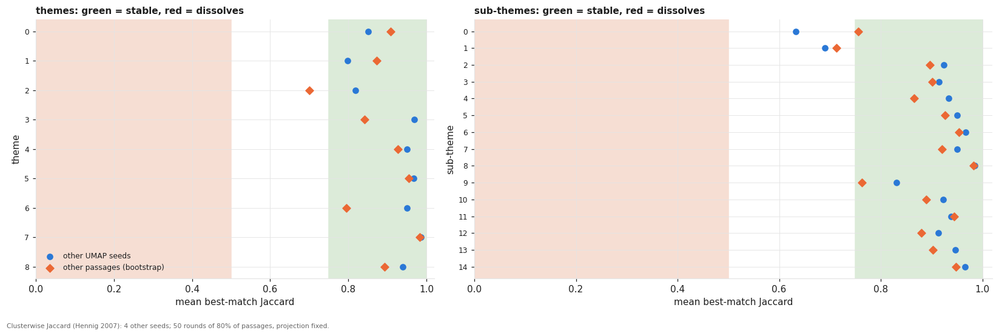


PRACTITIONER NOTE
  Report stability per cluster, not only overall, and say what each number varies: a new seed and a
  new sample of passages are different tests. A cluster that dissolves is reported with its score and
  never used alone as the basis of a claim.


In [ ]:
# @title
# ==================================================================================================
# PHASE: CLUSTER QUALITY                                                stage 1 of 2 in this phase
# STAGE 16  STABILITY
# WHAT THIS CELL DOES: does each cluster come back with another seed and with other passages
# ==================================================================================================
# WHAT THIS CELL DOES
#   Cluster quality: would the same sub-themes and themes come back with another UMAP seed, or
#   with other passages? Each cluster gets two scores, and a verdict.
#
# WHY
#   A clustering method returns clusters whether or not the data hold any. A cluster that dissolves
#   when the data are resampled is not a finding. Stability is necessary, not sufficient: the
#   coherence scores (Stages 14 and 15) and the self-test (Stage 21) cover the rest.
#
# HOW
#   Seeds: each cluster's best Jaccard match in the runs on the other UMAP seeds (Stage 14).
#   Passages: BOOTSTRAP_N rounds, each re-running both levels on 80% of the passages drawn without
#   replacement, with the projection held fixed; each cluster's best Jaccard match per round
#   (Hennig 2007). Hennig's reading: mean Jaccard at or above 0.75 is stable, at or below 0.50 the
#   cluster dissolves.
#
# REFERENCES
#   Hennig, C. (2007) Cluster-wise assessment of cluster stability. Computational Statistics and
#     Data Analysis 52(1):258-271.
#   Hubert, L. and Arabie, P. (1985) Comparing partitions. Journal of Classification 2(1):193-218.

import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

heading("STAGE 16  STABILITY")

# ---- 1. across seeds (the runs of Stage 14) --------------------------------------------------
_seed_sub, _seed_main = {}, {}
for i, (_, full, _) in enumerate(RUNS):
    if i == REFERENCE_RUN:
        continue
    for value, score in clusterwise_jaccard(SUB_LABELS, full).items():
        _seed_sub.setdefault(value, []).append(score)
    for value, score in clusterwise_jaccard(MAIN_LABELS, THEME_RUNS[i]).items():
        _seed_main.setdefault(value, []).append(score)

# ---- 2. across passages (bootstrap without replacement) -------------------------------------
_rng = np.random.default_rng(CFG.seed + 16)
_draw = int(0.8 * N_PASSAGES)
_min_size = max(5, int(round(MIN_SUBTHEME_SIZE * 0.8)))
_z = PROJECTIONS[REFERENCE_RUN]
_boot_sub, _boot_main, _ari_sub, _ari_main = {}, {}, [], []
_t0 = time.perf_counter()
for _ in range(int(CFG.bootstrap_n)):
    rows = np.sort(_rng.choice(N_PASSAGES, size=_draw, replace=False))
    raw, _ = find_subthemes(_z[rows], METHOD, _min_size, CFG.ward_k_range, K_SUB_OBTAINED)
    if len(np.unique(raw[raw >= 0])) < 2:
        continue
    sub, _ = attach_noise(X[rows], raw)
    grouping, _, _ = build_themes(X[rows], sub, CFG.theme_k_range, K_MAIN_OBTAINED)
    main = np.array([grouping[int(v)] for v in sub])
    for value, score in clusterwise_jaccard(SUB_LABELS[rows], sub).items():
        _boot_sub.setdefault(value, []).append(score)
    for value, score in clusterwise_jaccard(MAIN_LABELS[rows], main).items():
        _boot_main.setdefault(value, []).append(score)
    _ari_sub.append(adjusted_rand_score(SUB_LABELS[rows], sub))
    _ari_main.append(adjusted_rand_score(MAIN_LABELS[rows], main))
BOOTSTRAP_ROUNDS = len(_ari_main)
PASSAGE_BOOTSTRAP_ARI = float(np.mean(_ari_main)) if _ari_main else float("nan")
SUB_BOOTSTRAP_ARI = float(np.mean(_ari_sub)) if _ari_sub else float("nan")


def _table(seed_scores, boot_scores, key, n):
    frame = pd.DataFrame({key: range(n)})
    frame["jaccard_seeds"] = [np.mean(seed_scores.get(v, [np.nan])) for v in range(n)]
    frame["jaccard_passages"] = [np.mean(boot_scores.get(v, [np.nan])) for v in range(n)]
    frame["jaccard_p05"] = [np.percentile(boot_scores[v], 5) if v in boot_scores else np.nan
                            for v in range(n)]
    low = frame[["jaccard_seeds", "jaccard_passages"]].min(axis=1)
    frame["verdict"] = np.where(low <= float(CFG.unstable_cluster_floor), "dissolves",
                                np.where(low >= float(CFG.stability_jaccard_min), "stable",
                                         "uncertain"))
    return frame


SUBTHEME_STABILITY = _table(_seed_sub, _boot_sub, "theme_sub", K_SUB_OBTAINED)
STABILITY = _table(_seed_main, _boot_main, "theme_main", K_MAIN_OBTAINED).merge(
    CONSENSUS_MAIN_TABLE[["theme_main", "passages", "coherence", "confidence_mean", "sub_themes"]],
    on="theme_main", how="left")
UNSTABLE_THEMES = set(int(v) for v in STABILITY.loc[STABILITY["verdict"] == "dissolves",
                                                    "theme_main"])
UNSTABLE_SUBTHEMES = set(int(v) for v in SUBTHEME_STABILITY.loc[
    SUBTHEME_STABILITY["verdict"] == "dissolves", "theme_sub"])
STABILITY["unstable"] = STABILITY["theme_main"].isin(UNSTABLE_THEMES)
STABILITY["incoherent"] = STABILITY["theme_main"].isin(INCOHERENT_THEMES)
STABILITY["safe_to_report"] = ~(STABILITY["unstable"] | STABILITY["incoherent"])
SUBTHEME_TABLE = SUBTHEME_TABLE.drop(columns=[c for c in ("jaccard_seeds", "jaccard_passages",
                                                          "stability") if c in SUBTHEME_TABLE])
SUBTHEME_TABLE = SUBTHEME_TABLE.merge(
    SUBTHEME_STABILITY[["theme_sub", "jaccard_seeds", "jaccard_passages", "verdict"]]
    .rename(columns={"verdict": "stability"}), on="theme_sub", how="left")

print(f"  bootstrap rounds      : {BOOTSTRAP_ROUNDS} of {int(CFG.bootstrap_n)}, "
      f"{_draw:,} passages each ({time.perf_counter() - _t0:.0f} s)")
print(f"  overall agreement     : themes ARI {PASSAGE_BOOTSTRAP_ARI:.3f}, sub-themes ARI "
      f"{SUB_BOOTSTRAP_ARI:.3f} (bootstrap); themes {THEME_SEED_AGREEMENT:.3f}, sub-themes "
      f"{SUBTHEME_SEED_AGREEMENT:.3f} (seeds)")
print(f"  verdicts (Hennig 2007): stable >= {CFG.stability_jaccard_min}, dissolves <= "
      f"{CFG.unstable_cluster_floor}, on the lower of the two Jaccard scores")
print(f"    themes              : " + ", ".join(
    f"{k} {v}" for k, v in STABILITY["verdict"].value_counts().items()))
print(f"    sub-themes          : " + ", ".join(
    f"{k} {v}" for k, v in SUBTHEME_STABILITY["verdict"].value_counts().items()))
print()
print(f"    {'theme':>5}  {'passages':>8}  {'seeds':>6}  {'passages':>8}  {'silhouette':>10}  "
      f"verdict")
for _, row in STABILITY.iterrows():
    print(f"    {int(row['theme_main']):>5}  {int(row['passages']):>8,}  "
          f"{row['jaccard_seeds']:>6.2f}  {row['jaccard_passages']:>8.2f}  "
          f"{row['coherence']:>10.3f}  {row['verdict']}"
          + (", incoherent" if row["incoherent"] else ""))

# ---- figure: every cluster's two stability scores, with Hennig's bands -----------------------
fig, axes = plt.subplots(1, 2, figsize=(15, max(4.8, 0.2 * K_SUB_OBTAINED)),
                         gridspec_kw={"width_ratios": [1, 1.3]})
for ax, frame, key, title in ((axes[0], STABILITY, "theme_main", "themes"),
                              (axes[1], SUBTHEME_STABILITY, "theme_sub", "sub-themes")):
    y = np.arange(len(frame))[::-1]
    ax.axvspan(0, float(CFG.unstable_cluster_floor), color="#f6ded3", zorder=0)
    ax.axvspan(float(CFG.stability_jaccard_min), 1.0, color="#dcebd9", zorder=0)
    ax.scatter(frame["jaccard_seeds"], y, s=36, color=PALETTE[0], label="other UMAP seeds",
               zorder=3)
    ax.scatter(frame["jaccard_passages"], y, s=36, marker="D", color=PALETTE[1],
               label="other passages (bootstrap)", zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([str(v) for v in frame[key]], fontsize=7 if len(frame) > 30 else 8)
    ax.set_xlim(0, 1.02)
    ax.set_xlabel("mean best-match Jaccard")
    ax.set_ylabel(title[:-1])
    ax.set_title(f"{title}: green = stable, red = dissolves", fontsize=10, loc="left")
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
fig.tight_layout()
add_reference_footer(fig, f"Clusterwise Jaccard (Hennig 2007): {len(RUNS) - 1} other seeds; "
                          f"{BOOTSTRAP_ROUNDS} rounds of 80% of passages, projection fixed.")
save_figure(fig, "s16_stability", slide_ready=True)
plt.show()
rule()

report("stability.seed_ari_themes", round(THEME_SEED_AGREEMENT, 4), "adjusted Rand", "Stage 16")
report("stability.passage_bootstrap_ari", round(PASSAGE_BOOTSTRAP_ARI, 4), "adjusted Rand",
       "Stage 16")
report("stability.themes_dissolving", len(UNSTABLE_THEMES), "themes", "Stage 16")
report("stability.subthemes_dissolving", len(UNSTABLE_SUBTHEMES), "sub-themes", "Stage 16")
report("stability.bootstrap_rounds", BOOTSTRAP_ROUNDS, "rounds", "Stage 16")

practitioner_note("Reporting stability", """
Report stability per cluster, not only overall, and say what each number varies: a new seed and a
new sample of passages are different tests. A cluster that dissolves is reported with its score and
never used alone as the basis of a claim.
""")

## Stage 16b: a second embedding model   [phase: cluster quality]

**Why.** Stage 16 shows that clusters survive other seeds and other passages, but always with the
same embedding model. A sub-theme that disappears when another good model reads the same passages
depends on the model, not on the text.

**How.** Notebook 1 also embedded every passage with a second model of another family (BGE-M3 by
default, `SECOND_EMBEDDING_MODEL` in Stage 1). This cell clusters those vectors with exactly the
same procedure (UMAP setting, method, minimum size, number of themes) and, for each sub-theme and
theme, finds its best match (Jaccard, Hennig 2007).

**Reading it.** 0.75 or more: reproduced. 0.50 or less: not reproduced, and reported as tentative.
The overall agreement (adjusted Rand) is shown beside the agreement of the first model with itself
across seeds, which is the most one can expect.

  STAGE 16b  A SECOND EMBEDDING MODEL
  second model          : bge-m3 (BAAI/bge-m3), 1,024 dimensions
  procedure             : UMAP (80, 0.1, 5), seed 42; hdbscan, smallest sub-theme 40; 9 themes
  [umap_second_model] not cached for key bc4de11beec5; computing ...
  [umap_second_model] computed and saved | key bc4de11beec5 | 0.1 MB | copied to durable storage

  second model found    : 12 sub-themes (first model 15); held aside 71.2%
  agreement, adjusted Rand   sub-themes 0.337   themes 0.424
  for comparison, the first model with itself across seeds: sub-themes 0.734, themes 0.775
  sub-themes : 0 reproduced, 6 partly, 9 not reproduced
  themes     : 0 reproduced, 6 partly, 3 not reproduced

     sub  passages  Jaccard  verdict
       0       872     0.45  not reproduced
       1       465     0.21  not reproduced
       2       448     0.55  partly
       3       373     0.39  not reproduced
       4       239     0.54  partly
       5       202     0.51  partly
       6       180

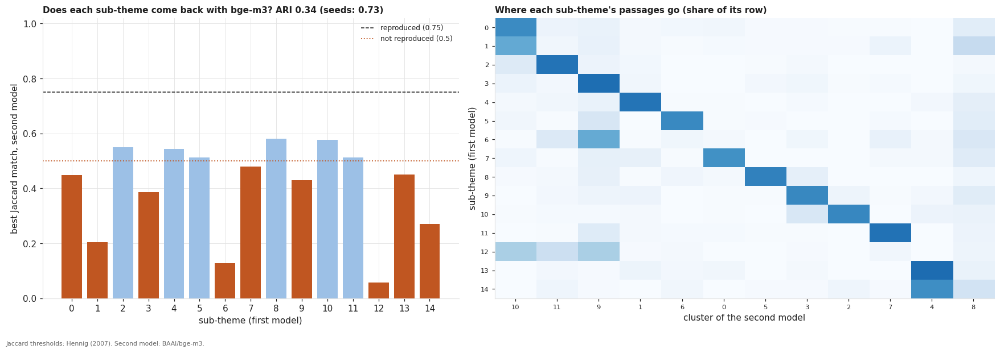


PRACTITIONER NOTE
  Cluster the same texts with a second, independent embedding model and the same procedure. Report the
  agreement beside the agreement of the first model with itself across seeds, and mark every cluster
  that does not come back: it belongs to the model's view of the texts, not to the texts alone.


In [ ]:
# @title
# ==================================================================================================
# PHASE: CLUSTER QUALITY                                                stage 2 of 2 in this phase
# STAGE 16b  A SECOND EMBEDDING MODEL
# WHAT THIS CELL DOES: does each cluster come back when another embedding model reads the same
#                      passages
# ==================================================================================================
# WHAT THIS CELL DOES
#   Robustness to the embedding model: clusters the same passages again, embedded by a second,
#   independent model (Stage 9 of notebook 1), with the same procedure, and says which sub-themes
#   and themes come back.
#
# WHY
#   Stage 16 shows that the clusters survive other seeds and other passages, but always with the
#   same model. A sub-theme that disappears with another good model depends on that model's view
#   of the text, not on the text alone, and is reported as tentative.
#
# HOW
#   The second model's vectors (language offsets estimated for it separately) are projected with
#   the UMAP setting chosen in notebook 1 and the first seed, and clustered by the method, minimum
#   size and number of themes of Stages 14 and 15. For each sub-theme and theme, the best Jaccard
#   match among the second model's clusters (Hennig 2007): 0.75 or more "reproduced", 0.50 or
#   less "not reproduced". The adjusted Rand index between the two partitions is set beside the
#   agreement of the first model with itself across seeds, which is the ceiling to expect.
#
# REFERENCES
#   Hennig, C. (2007) Cluster-wise assessment of cluster stability. Computational Statistics and
#     Data Analysis 52(1):258-271.
#   Hubert, L. and Arabie, P. (1985) Comparing partitions. Journal of Classification 2(1):193-218.
#   Chen, J., Xiao, S., Zhang, P., Luo, K., Lian, D. and Liu, Z. (2024) BGE M3-Embedding:
#     multi-lingual, multi-functionality, multi-granularity text embeddings through self-knowledge
#     distillation. arXiv:2402.03216.

import os, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

heading("STAGE 16b  A SECOND EMBEDDING MODEL")

SECOND = (globals().get("HANDOFF") or {}).get("second_model")
SUBTHEMES_MODEL_DEPENDENT, THEMES_MODEL_DEPENDENT = set(), set()
SECOND_MODEL_SUMMARY = None
SUBTHEME_TABLE["second_model_jaccard"] = np.nan
SUBTHEME_TABLE["model_dependent"] = False

if not SECOND or SECOND.get("vectors") is None:
    print("  No second model in the bundle: SECOND_EMBEDDING_MODEL is None, or notebook 1 could")
    print("  not compute it. This check was not run; every cluster depends on one embedding model.")
else:
    X2 = np.asarray(SECOND["vectors"], dtype=np.float32)
    X2 /= np.maximum(np.linalg.norm(X2, axis=1, keepdims=True), 1e-12)
    assert len(X2) == len(passages), (
        f"The second model has {len(X2)} rows for {len(passages)} passages; re-run notebook 1.")
    print(f"  second model          : {SECOND['name']} ({SECOND['path']}), "
          f"{SECOND['dimensions']:,} dimensions")
    print(f"  procedure             : UMAP {tuple(BEST_UMAP)}, seed {CFG.seed}; {METHOD}, smallest "
          f"sub-theme {MIN_SUBTHEME_SIZE}; {K_MAIN_OBTAINED} themes")

    Z2 = cached("umap_second_model", lambda: project(BEST_UMAP, seed=CFG.seed, source=X2),
                inputs=[CORPUS_TEXT_FINGERPRINT, SECOND["name"], tuple(BEST_UMAP), CFG.seed,
                        hashlib.sha256(np.ascontiguousarray(X2).tobytes()).hexdigest()[:16]],
                note="the second model's vectors, projected like the first", scope="inputs")
    _raw2, _ = find_subthemes(Z2, METHOD, MIN_SUBTHEME_SIZE, CFG.ward_k_range,
                              CFG.subtheme_count_fixed)
    if len(np.unique(_raw2[_raw2 >= 0])) < 2:
        print("  The second model gives fewer than two sub-themes with this procedure: no")
        print("  comparison is possible. Its space has no dense groups of this size.")
    else:
        SUB2, _ = attach_noise(X2, _raw2)
        _grouping2, _, _ = build_themes(X2, SUB2, CFG.theme_k_range, K_MAIN_OBTAINED)
        MAIN2 = np.array([_grouping2[int(v)] for v in SUB2])
        _j_sub = clusterwise_jaccard(SUB_LABELS, SUB2)
        _j_main = clusterwise_jaccard(MAIN_LABELS, MAIN2)
        ARI_SUB_MODELS = float(adjusted_rand_score(SUB_LABELS, SUB2))
        ARI_MAIN_MODELS = float(adjusted_rand_score(MAIN_LABELS, MAIN2))
        _stable, _floor = float(CFG.stability_jaccard_min), float(CFG.unstable_cluster_floor)

        def _verdict(score):
            return ("reproduced" if score >= _stable else
                    "not reproduced" if score <= _floor else "partly")

        SUBTHEME_TABLE["second_model_jaccard"] = SUBTHEME_TABLE["theme_sub"].map(_j_sub)
        SUBTHEME_TABLE["model_dependent"] = SUBTHEME_TABLE["second_model_jaccard"] <= _floor
        SUBTHEMES_MODEL_DEPENDENT = {int(k) for k, v in _j_sub.items() if v <= _floor}
        THEMES_MODEL_DEPENDENT = {int(k) for k, v in _j_main.items() if v <= _floor}
        _count = {"sub": pd.Series({k: _verdict(v) for k, v in _j_sub.items()}).value_counts(),
                  "main": pd.Series({k: _verdict(v) for k, v in _j_main.items()}).value_counts()}
        SECOND_MODEL_SUMMARY = {
            "model": SECOND["name"], "subthemes_found": int(len(np.unique(_raw2[_raw2 >= 0]))),
            "held_aside": float((_raw2 < 0).mean()), "ari_subthemes": ARI_SUB_MODELS,
            "ari_themes": ARI_MAIN_MODELS, "jaccard_subthemes": _j_sub, "jaccard_themes": _j_main,
            "subthemes_model_dependent": sorted(SUBTHEMES_MODEL_DEPENDENT),
            "themes_model_dependent": sorted(THEMES_MODEL_DEPENDENT)}

        print()
        print(f"  second model found    : {SECOND_MODEL_SUMMARY['subthemes_found']} sub-themes "
              f"(first model {K_SUB_OBTAINED}); held aside "
              f"{SECOND_MODEL_SUMMARY['held_aside']:.1%}")
        print(f"  agreement, adjusted Rand   sub-themes {ARI_SUB_MODELS:.3f}   themes "
              f"{ARI_MAIN_MODELS:.3f}")
        print(f"  for comparison, the first model with itself across seeds: sub-themes "
              f"{SUBTHEME_SEED_AGREEMENT:.3f}, themes {THEME_SEED_AGREEMENT:.3f}")
        for level, label in (("sub", "sub-themes"), ("main", "themes")):
            counts = _count[level]
            print(f"  {label:<11}: " + ", ".join(f"{counts.get(v, 0)} {v}" for v in
                                                 ("reproduced", "partly", "not reproduced")))
        print()
        print(f"    {'sub':>4}  {'passages':>8}  {'Jaccard':>7}  verdict")
        for row in SUBTHEME_TABLE.itertuples():
            print(f"    {row.theme_sub:>4}  {row.passages:>8,}  {row.second_model_jaccard:>7.2f}  "
                  f"{_verdict(row.second_model_jaccard)}")
        if SUBTHEMES_MODEL_DEPENDENT:
            _themes_too = (f"; themes {sorted(THEMES_MODEL_DEPENDENT)}"
                           if THEMES_MODEL_DEPENDENT else "")
            print(f"  NOT REPRODUCED by the second model, reported as tentative: sub-themes "
                  f"{sorted(SUBTHEMES_MODEL_DEPENDENT)}{_themes_too}")
        report("robustness.second_model_ari_subthemes", round(ARI_SUB_MODELS, 4), "adjusted Rand",
               "Stage 16b")
        report("robustness.second_model_ari_themes", round(ARI_MAIN_MODELS, 4), "adjusted Rand",
               "Stage 16b")
        report("robustness.subthemes_not_reproduced", len(SUBTHEMES_MODEL_DEPENDENT),
               "sub-themes", "Stage 16b")
        pd.DataFrame({"theme_sub": list(_j_sub), "jaccard": list(_j_sub.values())}).to_csv(
            os.path.join(FIGURE_DIR, "s16b_second_model_jaccard.csv"), index=False)

        # ---- figure: each sub-theme's best match, and where its passages went -------------------
        fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1, 1.2]})
        ax = axes[0]
        _scores = SUBTHEME_TABLE["second_model_jaccard"].values
        ax.bar(SUBTHEME_TABLE["theme_sub"].astype(str), _scores,
               color=[PALETTE[0] if v >= _stable else WARN if v <= _floor else "#9cc0e6"
                      for v in _scores])
        ax.axhline(_stable, color=INK, ls="--", lw=1, label=f"reproduced ({_stable})")
        ax.axhline(_floor, color=WARN, ls=":", lw=1.2, label=f"not reproduced ({_floor})")
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("sub-theme (first model)")
        ax.set_ylabel("best Jaccard match, second model")
        ax.set_title(f"Does each sub-theme come back with {SECOND['name']}? "
                     f"ARI {ARI_SUB_MODELS:.2f} (seeds: {SUBTHEME_SEED_AGREEMENT:.2f})",
                     fontsize=10, loc="left")
        ax.legend(fontsize=8, frameon=False)
        ax = axes[1]
        _table = pd.crosstab(pd.Series(SUB_LABELS, name="first"), pd.Series(SUB2, name="second"),
                             normalize="index")
        _order = list(dict.fromkeys(_table.idxmax(axis=1).tolist()
                                    + [c for c in _table.columns]))
        _table = _table[_order]
        ax.imshow(_table.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
        ax.set_yticks(range(len(_table.index)))
        ax.set_yticklabels([str(v) for v in _table.index], fontsize=7.5)
        ax.set_ylabel("sub-theme (first model)")
        ax.set_xticks(range(len(_order)))
        ax.set_xticklabels([str(c) for c in _order], fontsize=7.5)
        ax.set_xlabel("cluster of the second model")
        ax.grid(False)
        ax.set_title("Where each sub-theme's passages go (share of its row)", fontsize=10,
                     loc="left")
        fig.tight_layout()
        add_reference_footer(fig, "Jaccard thresholds: Hennig (2007). Second model: "
                                  f"{SECOND['path']}.")
        save_figure(fig, "s16b_second_model")
        plt.show()
rule()

practitioner_note("Robustness to the model", """
Cluster the same texts with a second, independent embedding model and the same procedure. Report the
agreement beside the agreement of the first model with itself across seeds, and mark every cluster
that does not come back: it belongs to the model's view of the texts, not to the texts alone.
""")

## Stage 17: terms, then names   [phase: naming]

**Terms.** The distinctive words of each cluster, by weighted log-odds with an informative Dirichlet
prior (Monroe, Colaresi and Quinn 2008), on the masked text.

**Names.** The instruction model (Qwen3-4B-Instruct-2507) reads the terms and the most typical passages
of a sub-theme and writes a name of one to six words in English. A theme is named from the names of its
sub-themes, so the model names what they share. Held-aside and weakly held passages are never shown to
the model.

  STAGE 17  TERMS, THEN NAMES
  passages                  : 3,912
  eligible to be quoted     : 1,861
    excluded, held weakly   : 244
    excluded, no evidence   : 2,027
  text column read          : 'text'  (MASKED: place names replaced in Stage 5c)
  quotations per theme      : 7
  place words shared with masking : 195 form(s), 282 stem(s), compared with accents folded
  [proper_nouns] not cached for key 2f3f638cd407; computing ...
  [proper_nouns] computed and saved | key 2f3f638cd407 | 0.0 MB | copied to durable storage
  proper nouns filtered        : 589 term(s), by capitalisation
  group-derived stems filtered : 19 (from countries)
  [naming_vocabulary] not cached for key eb0933d19cfc; computing ...
  [naming_vocabulary] computed and saved | key eb0933d19cfc | 0.3 MB | copied to durable storage
  vocabulary                   : 24,249 distinct tokens, 808 excluded

  SUB LEVEL: 15 theme(s), distinctive terms measured

  MAIN LEVEL: 9 theme(s), distinctive terms measured

  cach

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (4 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

  model ready. It stays loaded until the release call at the end.
  instruction model         : Qwen/Qwen3-4B-Instruct-2507
  terms and quotes fingerprint : 2aac485019f7
  [theme_names] not cached for key d90a3ebcba6c; computing ...
  [theme_names] computed and saved | key d90a3ebcba6c | 0.0 MB | copied to durable storage

  stemming                  : Snowball stemmers, English, French and Spanish (Porter 2001)
  naming tests keyed by     : its source
  WHERE THE NAMES CAME FROM
     23  instruction model
      1  instruction model, second attempt
  asked a second time, because the first answer was refused: 1; accepted on the second attempt: 0

  SUB THEMES (14 of 15 pass)
     id       n  name                                   own   rival   lang  verdict
                                                        fit     fit  share
      0     872  wounded patients in hospital          5.86    1.81    89%  ok
      1     465  armed group violence                  3.72    3.36    93%  ok


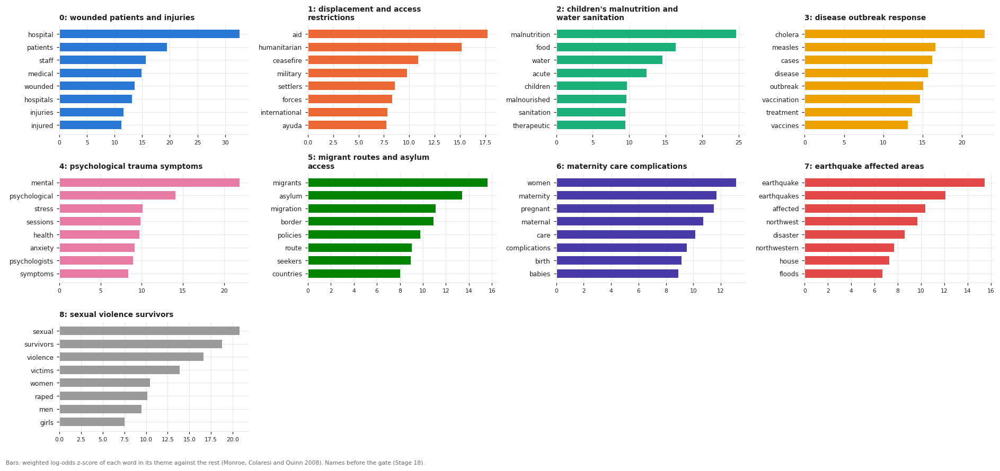


PRACTITIONER NOTE
  Key the name cache on the cluster labels, not just the corpus and settings, or re-clustering
  silently returns stale names. Quote the passages held most firmly across seeds and, among those,
  the most typical (highest silhouette), and test every name against its own cluster's distinctive
  vocabulary and its neighbours'.


In [ ]:
# @title
# ==================================================================================================
# PHASE: NAMING                                                         stage 1 of 2 in this phase
# STAGE 17  TERMS, THEN NAMES
# WHAT THIS CELL DOES: distinctive words per cluster, then a short name from the instruction model
# ==================================================================================================
# WHAT THIS CELL DOES
#   Names each sub-theme and theme cluster: an instruction model proposes a label where available,
#   a term-built label is used otherwise, and every name is tested against the distinctive
#   vocabulary of its own cluster before acceptance.
#
# WHY
#   A name must be traceable to evidence in its own cluster, not merely plausible, and it must not
#   assert a level, burden, rate or trend that this pipeline does not measure.
#
# HOW
#   Distinctive vocabulary per cluster is weighted log-odds with an informative Dirichlet prior
#   (Monroe, Colaresi and Quinn 2008). Sub-themes are named first, since a theme is named from its
#   sub-themes. Quotations are drawn from masked text, from passages held with highest confidence.
#   A proposed label is stemmed (Snowball, English/French/Spanish) and checked against its
#   cluster's distinctive terms, the name language, and neighbouring clusters, then retried once
#   if refused before falling back to a term-built label.
#
# REFERENCES
#   Monroe, B.L., Colaresi, M.P. and Quinn, K.M. (2008) Fightin' words: lexical feature selection
#     and evaluation for identifying the content of political conflict. Political Analysis
#     16(4):372-403. DOI 10.1093/pan/mpn018

import re, json, math, unicodedata
import textwrap
import numpy as np, pandas as pd

heading("STAGE 17  TERMS, THEN NAMES")



# Sub-themes must be named before themes, since a theme prompt is built from its sub-themes' names.
assert [level for level, _, _, _ in NAME_LEVELS] == ["sub", "main"], (
    f"NAME_LEVELS is ordered {[l for l, _, _, _ in NAME_LEVELS]}; the sub level must come first.")

# ---- which passages may speak for a theme ----------------------------------
# A passage held with low confidence, or assigned by centroid rather than by clustering, is excluded
# from naming evidence. Both are counted, since a theme with nothing confident to say is a finding.
ELIGIBLE = (~passages["low_confidence"]) & (~passages["assigned_by_centroid"])
print(f"  passages                  : {len(passages):,}")
print(f"  eligible to be quoted     : {int(ELIGIBLE.sum()):,}")
print(f"    excluded, held weakly   : {int(passages['low_confidence'].sum()):,}")
print(f"    excluded, no evidence   : {int(passages['assigned_by_centroid'].sum()):,}")
print(f"  text column read          : 'text'  (MASKED: place names replaced in Stage 5c)")
print(f"  quotations per theme      : {CFG.llm_n_quotes}")

def fold(text):
    """Lower-case form with accents removed, so accented and unaccented spellings compare equal."""
    return "".join(character for character in unicodedata.normalize("NFKD", str(text).lower())
                   if not unicodedata.combining(character))



_MASK = re.escape(str(CFG.place_placeholder))

# Accented Latin letters are accepted as word characters, not only a-z, so an accent does not end a
# token. The ranges cover Latin-1 Supplement and Latin Extended-A/B: every accented letter used by
# the languages in this corpus, and by Latin-script languages generally.
LATIN = "a-z\u00c0-\u024f"
TOKEN = re.compile(f"[{LATIN}][{LATIN}\\-']{{2,}}")

# URLs and email addresses are not prose and must not contribute vocabulary: a lower-case place name
# inside a URL slug would otherwise defeat the capitalisation test below.
URL_OR_EMAIL = re.compile(r"(?:https?://|www\.)\S+|\S+@\S+\.\S+", re.IGNORECASE)


def prose_only(text):
    return URL_OR_EMAIL.sub(" ", str(text))

# The corpus is multilingual (Stage 5 detects English, Spanish, French and German). An English-only
# stop list would leave other languages' function words in place, and since those words are frequent
# in one language and rare elsewhere, the log-odds measure would rank them as highly distinctive.
STOPWORDS = set("""
the a an and or but if then than that this these those there here of to in on at by for with from
as is are was were be been being have has had do does did will would can could should may might
must shall not no nor so such very more most much many few less least own same other another
its it he she they them their his her our your my we you i us who whom whose which what when where
while about against between into through during before after above below up down out off over under
again further once all any both each other some own too only own s t don now also per one two
que los las del una unos unas por con para como pero mas muy este esta estos estas ese esa eso
ser son era eran fue fueron sido siendo tiene tienen tenia haber hay hubo desde hasta sobre entre
sin tras donde cuando porque aunque tambien solo otro otra otros otras cada todo toda todos todas
les des aux dans sur avec pour par plus tres cette ces cet leur leurs nous vous ils elles etre est
sont etait etaient ete avoir ont avait avaient fait faire dont ainsi apres avant chez comme
lorsque meme aussi encore alors depuis pendant sans sous entre tout toute tous toutes autre autres
der die das den dem eines einer eine einen und oder aber wenn dann als dass dies diese diesem
ist sind war waren sein seine ihre ihrer nicht auch noch schon mehr sehr durch bei aus nach vor
uma umas uns duas dois pelo pela pelos pelas nao mais muito esse essa isso quando porque entao
ete etait etre deja tres apres plusieurs ou numero tambien esta estan segun mas dia ano anos
""".split())

# Additional French and Spanish function words, from the Snowball project's stop lists (Porter 2001)
# as distributed by NLTK, written without accents since the comparison below folds accents on both
# sides. A function word is distinctive of such a cluster only because of its language, not its
# subject.
STOPWORDS |= set("""
qui une pas cet cette ces son ses leur leurs mais donc car lui elle elles ils eux moi toi soi mon ton
notre votre nos vos mes tes quel quels quelle quelles ceci cela celui celle ceux celles ici etre avoir
etait etaient etant suis est sommes etes serai sera seront serait seraient aurait auraient avait
avaient avons avez ont aura auront fait faire font comme aussi tres tout toute toutes dont meme entre
depuis sans sous vers chez contre selon pendant apres avant alors ainsi encore deja jamais toujours
moins peu beaucoup autre autres chaque plusieurs certains certaines quelque quelques lequel laquelle
lesquels lesquelles aupres parmi afin lors puis enfin notamment egalement
este esta estos estas ese esa esos esas aquel aquella sus pero tambien muy sin sobre hasta donde desde
durante todo toda todos todas uno unos unas otro otra otros otras cuando porque como hay ser estar fue
fueron era eran sido siendo han tiene tienen tenia puede pueden segun mientras ante tras cada ellos
ellas nosotros usted ustedes esto eso nada algo algunos algunas mismo misma tanto muchos muchas poco
pocos cual cuales quien quienes solo estan estaba estaban habia habian
""".split())

# Words derived from the values of the corpus's group column. Stage 5c replaces place names with a
# placeholder, but not their adjectival or demonymic forms (e.g. a stem such as "sudan"), which can
# be highly distinctive of a theme and describe WHERE rather than WHAT. Built from the group values
# present in the corpus rather than a fixed list, so it works on any corpus.
# An elided article is part of a French word's spelling, not a separate word ("l'hopital" and
# "hopital" must count as the same token). Elided forms are stripped from the front of a token, and
# the typographic apostrophe is treated as the plain one, since French text uses both.
ELISION = re.compile(r"^(?:l|d|qu|n|s|c|j|m|t|jusqu|lorsqu|puisqu)'", re.IGNORECASE)


def tokens_of(text):
    """Every word of a passage as this cell counts it: prose only, lower case, elisions removed."""
    body = prose_only(text).lower().replace("\u2019", "'")
    out = []
    for token in TOKEN.findall(body):
        token = ELISION.sub("", token).strip("-'")
        if len(token) >= 3:
            out.append(token)
    return out


def _group_derived_stems():
    stems = set()
    _group = group_column(passages)
    sources = []
    if _group:
        sources += [str(v) for v in passages[_group].dropna().unique()]
    sources += [str(v) for v in (GROUP_LABELS or {}).values()]
    sources += [str(v) for v in (GROUPS or [])]
    for value in sources:
        for word in re.findall(r"[A-Za-z]{4,}", value):
            lowered = word.lower()
            stems.add(lowered)
            stems.add(lowered[:4])          # isra(el), suda(n), ukra(ine)
            stems.add(lowered[:5])
    return {s for s in stems if len(s) >= 4}


# Place words and demonyms are read from the masking stage rather than duplicated here. Masking
# removes a place NAME from the text; this keeps its derived forms out of a theme label, which
# matters because a demonym is lower case by orthographic rule in Spanish and French, so no
# capitalisation test can catch one.
# A word is a place word when it is one, or shares a Snowball stem with one. Matching by stem,
# rather than by a fixed character prefix, catches derived forms (a demonym still shares a stem
# with its place) while sparing ordinary words that merely share a few letters.
try:
    from nltk.stem.snowball import SnowballStemmer as _PlaceStemmer
    _PLACE_STEMMERS = [_PlaceStemmer(language) for language in ("english", "french", "spanish")]
except ImportError:
    _PLACE_STEMMERS = []


def _place_stems(word):
    key = fold(str(word).lower())
    return ({stemmer.stem(key) for stemmer in _PLACE_STEMMERS} | {key}) if _PLACE_STEMMERS else {key}


PLACE_FORMS = {fold(word) for word in CURATED_PLACE_WORDS if len(str(word)) >= 4}
PLACE_STEMS = {stem for form in PLACE_FORMS for stem in _place_stems(form) if len(stem) >= 4}
print(f"  place words shared with masking : {len(PLACE_FORMS):,} form(s), "
      f"{len(PLACE_STEMS):,} stem(s), compared with accents folded")


def _is_place_word(token):
    folded = re.sub(r"['\u2019]s$", "", fold(token))
    parts = [p for p in re.split(r"[-'\u2019]", folded) if len(p) >= 4]
    if folded in PLACE_FORMS or any(p in PLACE_FORMS for p in parts):
        return True
    return len(folded) >= 4 and bool(_place_stems(folded) & PLACE_STEMS)


GROUP_STEMS = _group_derived_stems()


def _proper_noun_stems(minimum_count=8, capitalised_share=0.85):
    """Terms that are proper nouns in this corpus, found by capitalisation rather than a fixed list.
    A token capitalised in almost every occurrence of the original text is a name (a place, camp,
    organisation or person) and can describe WHERE rather than WHAT. Catches names masking missed,
    including demonyms and transliterations, on any corpus and language, with no hard-coded list.

    A sentence-initial capital is not counted, since it says nothing about the word.
    """
    column = "text_raw" if "text_raw" in passages.columns else "text"
    upper, lower = {}, {}
    boundary = re.compile(r"(?:^|[.!?]\s+|\n)\s*$")
    word_pattern = re.compile(f"[A-Za-z\u00c0-\u024f][A-Za-z\u00c0-\u024f\\-']{{2,}}")
    for text in passages[column].astype(str):
        text = prose_only(text)
        for match in word_pattern.finditer(text):
            token = match.group(0)
            key = token.lower()
            if key in STOPWORDS:
                continue
            if token[0].isupper():
                if boundary.search(text[max(0, match.start() - 3):match.start()]):
                    continue                    # a sentence-initial capital says nothing
                upper[key] = upper.get(key, 0) + 1
            else:
                lower[key] = lower.get(key, 0) + 1
    names = set()
    for key, count in upper.items():
        total = count + lower.get(key, 0)
        if total >= minimum_count and count / total >= capitalised_share:
            names.add(key)
    return names


PROPER_NOUNS = cached(
    "proper_nouns", _proper_noun_stems,
    inputs=[CORPUS_TEXT_FINGERPRINT, "text_raw" in passages.columns, 8, 0.85,
            LATIN, URL_OR_EMAIL.pattern],
    note="terms capitalised in almost every occurrence in the original text")
print(f"  proper nouns filtered        : {len(PROPER_NOUNS)} term(s), by capitalisation")
print(f"  group-derived stems filtered : {len(GROUP_STEMS)} (from {plural(CFG.group_noun)})")


def _is_group_word(token):
    return len(token) >= 4 and any(token.startswith(stem) or stem.startswith(token)
                                   for stem in GROUP_STEMS)


# Every token's exclusion is resolved once, over the distinct vocabulary, before counting begins.
def _corpus_vocabulary():
    seen = set()
    for text in passages["text"].astype(str):
        seen.update(tokens_of(text))
    return seen


VOCABULARY = cached("naming_vocabulary", _corpus_vocabulary,
                    inputs=[CORPUS_TEXT_FINGERPRINT, TOKEN.pattern, URL_OR_EMAIL.pattern,
                            ELISION.pattern],
                    note="distinct lower-case tokens in the masked text")
_mask_pattern = re.compile(_MASK.lower())
# The stop-word test compares folded (accent-stripped) forms, since the list is written without
# accents while the tokeniser accepts accented tokens.
FOLDED_STOPWORDS = frozenset(fold(word) for word in STOPWORDS)

EXCLUDED_TOKENS = frozenset(
    token for token in VOCABULARY
    if fold(token) in FOLDED_STOPWORDS or _mask_pattern.fullmatch(token)
    or token in PROPER_NOUNS or _is_group_word(token) or _is_place_word(token))

# A check that can fail: no surviving token may fold onto a stop word.
_leaked = sorted(t for t in VOCABULARY
                 if t not in EXCLUDED_TOKENS and fold(t) in FOLDED_STOPWORDS)[:10]
assert not _leaked, f"Tokens fold onto stop words but were not excluded: {_leaked}."
print(f"  vocabulary                   : {len(VOCABULARY):,} distinct tokens, "
      f"{len(EXCLUDED_TOKENS):,} excluded")


def token_counts(texts):
    counter = {}
    for text in texts:
        for token in tokens_of(text):
            if token in EXCLUDED_TOKENS:
                continue
            counter[token] = counter.get(token, 0) + 1
    return counter


TERM_FALLBACK_THEMES = {"main": [], "sub": []}


def distinctive_terms(label_column, top_n=18, min_count=5, level=None):
    """Weighted log-odds with an informative Dirichlet prior, per theme (Monroe et al. 2008).

    A word's score is the log-odds of its rate inside the theme against its rate in the rest of the
    corpus, using corpus counts as the prior and dividing by the log-odds' standard deviation, so a
    word seen only a few times cannot outrank one seen hundreds of times.

    Every theme in the passage table gets an entry. A theme with no eligible passage (all held with
    low confidence) is measured from its own passages instead, the same fallback quotations use, and
    is recorded in TERM_FALLBACK_THEMES.
    """
    eligible_rows = passages.loc[ELIGIBLE]
    corpus_counts = token_counts(eligible_rows["text"])
    corpus_total = sum(corpus_counts.values())
    all_values = sorted(int(v) for v in passages[label_column].unique())
    if not corpus_total:
        return {value: [] for value in all_values}
    alpha_0 = float(len(corpus_counts))                      # one pseudo-count per vocabulary item

    def score(block_texts):
        inside = token_counts(block_texts)
        inside_total = sum(inside.values())
        if inside_total == 0:
            return []
        scored = []
        for token, count in inside.items():
            if count < min_count:
                continue
            outside = max(0, corpus_counts.get(token, 0) - count)
            prior = alpha_0 * corpus_counts.get(token, 0) / max(1, corpus_total)
            a_in = count + prior
            a_out = outside + prior
            b_in = inside_total + alpha_0 - a_in
            b_out = (corpus_total - inside_total) + alpha_0 - a_out
            if min(a_in, a_out, b_in, b_out) <= 0:
                continue
            delta = math.log(a_in / b_in) - math.log(a_out / b_out)
            variance = 1.0 / a_in + 1.0 / a_out
            scored.append((token, delta / math.sqrt(variance), count,
                           count / inside_total,
                           (corpus_counts.get(token, 0) / corpus_total) or 1e-12, delta))
        scored.sort(key=lambda row: -row[1])
        # "lift" is the raw ratio, kept for reading. "smoothed_lift" is exp(delta), the same ratio
        # after both rates are shrunk toward the corpus rate by the prior; the gate uses it, since
        # the raw ratio can explode in a small cluster.
        return [{"term": t, "z": round(z, 3), "count": c, "rate_in_theme": round(r, 5),
                 "lift": round(r / p, 2), "delta": round(d, 4),
                 "smoothed_lift": round(math.exp(d), 3)}
                for t, z, c, r, p, d in scored[:top_n]]

    out, fallback = {}, []
    for value in all_values:
        block = eligible_rows.loc[eligible_rows[label_column] == value, "text"]
        if not len(block):
            block = passages.loc[passages[label_column] == value, "text"]
            fallback.append(value)
        out[value] = score(block)
    if level is not None:
        TERM_FALLBACK_THEMES[level] = fallback
    return out


def quotations(label_column, confidence_column, value, n):
    """The n passages whose evidence points most firmly at this theme, trimmed for printing."""
    block = passages.loc[ELIGIBLE & (passages[label_column] == value)]
    if not len(block):
        block = passages.loc[passages[label_column] == value]
    # Most firmly held first; among those, the most typical (highest silhouette).
    typical = "silhouette_" + label_column.split("_", 1)[1]
    ordered = block.sort_values([confidence_column, typical], ascending=False, na_position="last")
    picked = []
    for _, row in ordered.head(n * 3).iterrows():
        text = " ".join(str(row["text"]).split())
        if len(text) > 340:
            text = text[:337].rsplit(" ", 1)[0] + " ..."
        if len(text.split()) >= 12:
            picked.append(text)
        if len(picked) >= n:
            break
    return picked


TERMS = {}
QUOTES = {}
for level, label_column, confidence_column, obtained in NAME_LEVELS:
    TERMS[level] = distinctive_terms(label_column, level=level)
    QUOTES[level] = {value: quotations(label_column, confidence_column, value, int(CFG.llm_n_quotes))
                     for value in sorted(passages[label_column].unique())}
    _empty = [v for v, q in QUOTES[level].items() if not q]
    print()
    print(f"  {level.upper()} LEVEL: {len(TERMS[level])} theme(s), distinctive terms measured")
    _fallback = TERM_FALLBACK_THEMES.get(level, [])
    if _fallback:
        print(f"    {len(_fallback)} theme(s) have no high-confidence passage: {_fallback}")
        print(f"    Terms measured from their own passages instead (weak-theme caveat, Stage 18).")
    if _empty:
        print(f"    {len(_empty)} theme(s) have no quotable passage: {_empty}")

# ---- the prompt -------------------------------------------------------------
NAME_SYSTEM = (
    f"You are labelling clusters of passages from {CFG.document_type}s for an academic thematic "
    "analysis. Place names have been replaced by a placeholder and must not appear in any label. "
    "You reply with a label alone, on one line, and nothing else.")
_ALLOWED_NOTE = ""
if CFG.name_allowed_phrases:
    _ALLOWED_NOTE = ("  These fixed terms are allowed even though they contain such a word: "
                     + ", ".join(CFG.name_allowed_phrases) + ".\n")

NAME_INSTRUCTION = (
    "Return a short label of two to six words naming the SUBJECT the passages share. Follow these "
    "rules exactly:\n"
    "  Name the subject, not a quantity. Do not use words such as high, low, rising, falling, "
    "severe, widespread, increasing, burden, crisis or prevalence: this analysis measures what is "
    "written about, not how much of it there is.\n"
    "  Use at least one word that appears in the term list or in the passages.\n"
    "  Write the label in English. Some passages may be in other languages: translate the "
    "subject into English, and do not copy words of another language into the label.\n"
    "  Do not name a country, region, city or organisation.\n"
    "  Do not use the words theme, cluster, topic, group or category.\n"
    + _ALLOWED_NOTE +
    "  Use ordinary academic English, in lower case except for proper nouns.\n\n"
    "Reply with the label alone, on one line, and nothing else.")


def build_prompt(level, value, sub_names=None):
    """The user half of the prompt. The system half is NAME_SYSTEM, and both are in the cache key,
    so a change to either produces different names rather than returning the old ones.

    A theme is named from its sub-themes' names, not from raw passages: it is an abstraction over
    sub-themes, and naming it from a handful of passages risks naming the language of those
    passages rather than the subject they share.
    """
    terms = ", ".join(row["term"] for row in TERMS[level].get(value, [])[:12]) or "none measured"
    quotes = QUOTES[level].get(value, [])
    body = []
    if level == "main" and sub_names:
        body.append("This theme groups the following sub-themes, each already named:")
        for sub_value, sub_name, sub_size in sub_names:
            body.append(f"  sub-theme {sub_value}: {sub_name}  ({sub_size:,} passages)")
        body.append("")
        body.append("Give one label that covers all of them. Do not simply repeat one sub-theme's "
                    "name when there is more than one, because that hides the others.")
        body.append("")
    body.append(f"Distinctive vocabulary, most distinctive first:\n{terms}")
    body.append("")
    if quotes and not (level == "main" and sub_names):
        body.append("Passages from this cluster:")
        for index, quote in enumerate(quotes, start=1):
            body.append(f"  {index}. {quote}")
    elif not quotes and not sub_names:
        body.append("This cluster has no passage that the consensus holds firmly, so no quotation "
                    "is shown. Name it from the vocabulary alone.")
    return NAME_INSTRUCTION + "\n\n" + "\n".join(body)


def _sub_names_of_theme(value, produced):
    """The named sub-themes inside one theme, largest first, for the theme prompt."""
    if "THEME_OF_SUBTHEME" not in globals():
        return []
    inside = [s for s, t in THEME_OF_SUBTHEME.items() if int(t) == int(value)]
    rows = []
    for sub_value in inside:
        record = produced.get("sub", {}).get(int(sub_value))
        size = int((passages["theme_sub"] == int(sub_value)).sum())
        rows.append((int(sub_value),
                     (record.get("display") or record["name"]) if record
                     else f"sub-theme {sub_value}", size))
    return sorted(rows, key=lambda row: -row[2])


def name_from_terms(level, value, how_many=3):
    """A name built from the distinctive terms alone. This is the fallback, and it is recorded as a
    fallback wherever it is used. It is deliberately plain rather than fluent: a name that reads
    like a sentence invites the reader to believe a model wrote it after reading the passages."""
    rows = TERMS[level].get(value, [])
    picked, seen = [], set()
    for row in rows:
        stem = row["term"][:int(CFG.name_stem_chars)]
        if stem in seen:
            continue
        seen.add(stem)
        picked.append(row["term"])
        if len(picked) >= how_many:
            break
    return " / ".join(picked) if picked else f"unnamed cluster {value}"


# ---- judging a name: every test, defined once --------------------------------
# These functions are used twice: by the retry below, to decide whether to ask the model again, and
# by the gate in Stage 18, to decide what may be reported. Defining them once means the two cannot
# disagree about what a good name is.
FORBIDDEN_QUANTITY = {w.lower() for w in CFG.name_forbidden_quantity}
FORBIDDEN_META = {w.lower() for w in CFG.name_forbidden_meta}
# A fixed term such as "armed groups" names a subject, so its words are not tested (Stage 1,
# NAME_ALLOWED_PHRASES). Longest first, so "severe acute malnutrition" goes before its parts.
_ALLOWED_PHRASES = [re.compile(rf"\b{re.escape(p)}\b", re.IGNORECASE)
                    for p in sorted(CFG.name_allowed_phrases, key=len, reverse=True)]


def without_allowed_phrases(name):
    text = str(name)
    for pattern in _ALLOWED_PHRASES:
        text = pattern.sub(" ", text)
    return text

WORD = re.compile(f"[A-Z{LATIN}][A-Z{LATIN}\\-']*")

# Words are matched by Snowball stems (Porter 2001) in English, French and Spanish. A stem is taken
# in all three languages, and two words match when any of their stems agree.
try:
    from nltk.stem.snowball import SnowballStemmer
except ImportError:
    import subprocess as _subprocess, sys as _sys
    _subprocess.run([_sys.executable, "-m", "pip", "install", "-q", "nltk"], check=False)
    try:
        from nltk.stem.snowball import SnowballStemmer
    except ImportError:
        SnowballStemmer = None
if SnowballStemmer is not None:
    _STEMMERS = [SnowballStemmer(language) for language in ("english", "french", "spanish")]
    STEMMING = "Snowball stemmers, English, French and Spanish (Porter 2001)"
else:
    _STEMMERS = []
    STEMMING = "FALLBACK: first seven letters, because nltk could not be imported"
_STEM_CACHE = {}


def stems_of(word):
    """The stems of one word, accents folded. Cached, because the same words recur."""
    key = fold(str(word).lower()).strip("-'")
    found = _STEM_CACHE.get(key)
    if found is None:
        found = ({stemmer.stem(key) for stemmer in _STEMMERS} | {key}) if _STEMMERS else {key[:7]}
        found = {stem for stem in found if len(stem) >= 3}
        _STEM_CACHE[key] = found
    return found


def english_stem(word):
    """One canonical stem, used only to tell whether two names are the same name."""
    key = fold(str(word).lower()).strip("-'")
    return _STEMMERS[0].stem(key) if _STEMMERS else key[:7]


def name_words(name):
    """The words of a name that carry meaning: elisions stripped, stop words removed."""
    words = [ELISION.sub("", w.lower()).strip("-'") for w in WORD.findall(str(name))]
    return [w for w in words if len(w) >= 3 and fold(w) not in FOLDED_STOPWORDS]


# THE LANGUAGE OF EACH PASSAGE AND EACH WORD. The lexical tests compare a name's words with the
# passages' words, which is only meaningful when both are in the same language.
_TEXTS = passages["text"].astype(str).tolist()
_LANGS = (passages["doc_language"].astype(str).str.lower().to_numpy()
          if "doc_language" in passages.columns else np.array([str(CFG.name_language)] * len(passages)))
_IN_NAME_LANGUAGE = _LANGS == str(CFG.name_language).lower()
PASSAGE_TOKENS = [set(tokens_of(text)) for text in _TEXTS]

_seen, _in_language = {}, {}
for _tokens, _here in zip(PASSAGE_TOKENS, _IN_NAME_LANGUAGE):
    for _token in _tokens:
        _seen[_token] = _seen.get(_token, 0) + 1
        if _here:
            _in_language[_token] = _in_language.get(_token, 0) + 1
TOKEN_LANGUAGE_SHARE = {t: (_in_language.get(t, 0) / n, n) for t, n in _seen.items()}

_STEM_INDEX = {}
for _token in _seen:
    for _stem in stems_of(_token):
        _STEM_INDEX.setdefault(_stem, set()).add(_token)
del _seen, _in_language


def is_foreign(word):
    """True when a word of a name is not in NAME_LANGUAGE: it carries an accented letter, or it
    occurs mostly in passages written in another language."""
    w = str(word).lower()
    if any(ord(c) > 127 for c in w):
        return True
    share, seen = TOKEN_LANGUAGE_SHARE.get(w, (1.0, 0))
    return seen >= 5 and share < float(CFG.name_foreign_max_share)


def _fit(entries, name_stems):
    """The best smoothed lift, in one cluster, of any distinctive term that matches the name."""
    best, matched = 0.0, []
    for term_stems, row in entries:
        if term_stems & name_stems:
            matched.append(row["term"])
            best = max(best, float(row.get("smoothed_lift", row.get("lift", 0.0))))
    return best, matched


TERM_INDEX = {level: {int(value): [(stems_of(row["term"]), row) for row in rows]
                      for value, rows in TERMS[level].items()}
              for level, _, _, _ in NAME_LEVELS}


def check_level(level, label_column, names, sources):
    """Judge every name at one level together. Together, because one test is about the level as a
    whole: two clusters may not carry the same name. Returns {value: verdict}."""
    index = TERM_INDEX[level]
    labels = passages[label_column].to_numpy()
    # The share of each cluster written in the name language, computed once for the level. A rival
    # is only sought among clusters that are themselves mostly in that language, since comparing a
    # name against another language's distinctive words is not a meaningful test.
    share_of = {}
    for value in index:
        members = labels == value
        share_of[value] = float(_IN_NAME_LANGUAGE[members].mean()) if members.any() else 0.0
    comparable = {v for v, share in share_of.items()
                  if share >= float(CFG.name_lexical_min_share)}
    verdicts = {}
    for value, name in names.items():
        value = int(value)
        all_words = [w.lower() for w in WORD.findall(str(name))]
        words = name_words(name)
        name_stems = set().union(*(stems_of(w) for w in words)) if words else set()
        is_model = str(sources.get(value, "")).startswith("instruction model")
        failures, kinds = [], []

        if not (int(CFG.name_min_words) <= len(all_words) <= int(CFG.name_max_words)):
            failures.append(f"length {len(all_words)} words, outside "
                            f"{CFG.name_min_words} to {CFG.name_max_words}")
            kinds.append("length")
        tested_words = {w.lower() for w in WORD.findall(without_allowed_phrases(name))}
        quantity = sorted(tested_words & FORBIDDEN_QUANTITY)
        if quantity:
            failures.append(f"asserts a quantity or level: {', '.join(quantity)}")
            kinds.append("quantity")
        meta = sorted(tested_words & FORBIDDEN_META)
        if meta:
            failures.append(f"names the method, not the subject: {', '.join(meta)}")
            kinds.append("method")
        foreign = [w for w in words if is_foreign(w)] if is_model else []
        if foreign:
            failures.append(f"not in English: {', '.join(foreign)}")
            kinds.append("language")

        own, matched = _fit(index.get(value, []), name_stems)
        rival, rival_value = 0.0, -1
        for other, entries in index.items():
            if other == value or other not in comparable:
                continue
            score, _ = _fit(entries, name_stems)
            if score > rival:
                rival, rival_value = score, other

        members = labels == value
        n_members = int(members.sum())
        language_share = float(_IN_NAME_LANGUAGE[members].mean()) if n_members else 0.0
        lexical = is_model and language_share >= float(CFG.name_lexical_min_share)
        covered, not_covered = None, None
        if lexical:
            if own < float(CFG.name_min_lift):
                failures.append(f"no word of it is distinctive of this cluster "
                                f"(best smoothed lift {own:.2f}, below {CFG.name_min_lift})")
                kinds.append("not distinctive")
            if own - rival < float(CFG.name_min_margin):
                failures.append(f"fits {level} {rival_value} as well or better "
                                f"(smoothed lift {own:.2f} here, {rival:.2f} there)")
                kinds.append("rival")
            positions = np.where(members & _IN_NAME_LANGUAGE)[0]
            match_tokens = {t for stem in name_stems for t in _STEM_INDEX.get(stem, ())}
            if len(positions) and match_tokens:
                hits = sum(1 for i in positions if PASSAGE_TOKENS[i] & match_tokens)
                covered = hits / len(positions)
            else:
                covered = 0.0
            not_covered = 1.0 - covered
            if not_covered > float(CFG.name_misdirected_max_share):
                failures.append(f"{not_covered:.0%} of its {CFG.name_language} passages contain "
                                f"no word of it")
                kinds.append("coverage")

        verdicts[value] = {
            "name": str(name), "source": sources.get(value, ""), "failures": failures,
            "kinds": kinds, "own": round(own, 3), "rival": round(rival, 3),
            "rival_value": int(rival_value), "margin": round(own - rival, 3),
            "matched": matched, "words": words, "passages": n_members,
            "language_share": round(language_share, 3),
            "lexical": ("applied" if lexical else
                        f"not applicable: {language_share:.0%} of its passages are in "
                        f"{CFG.name_language}" if is_model else "not applicable: term-built label"),
            "covered": None if covered is None else round(covered, 4),
            "not_covered": None if not_covered is None else round(not_covered, 4)}

    # Two clusters may not carry the same name. This test does not depend on language, so it also
    # protects clusters the lexical tests cannot judge. The name stays with the cluster it describes
    # best; the others are refused and asked again.
    groups = {}
    for value, verdict in verdicts.items():
        if not str(verdict["source"]).startswith("instruction model") or not verdict["words"]:
            continue
        key = frozenset(english_stem(w) for w in verdict["words"])
        groups.setdefault(key, []).append(value)
    for members in groups.values():
        if len(members) < 2:
            continue
        keeper = max(members, key=lambda v: (verdicts[v]["own"], verdicts[v]["passages"]))
        for value in members:
            if value == keeper:
                continue
            verdicts[value]["failures"].append(
                f"same name as {level} {keeper}, which it describes better")
            verdicts[value]["kinds"].append("duplicate")
            verdicts[value]["rival_value"] = int(keeper)

    for verdict in verdicts.values():
        verdict["accepted"] = not verdict["failures"]
    return verdicts


# ---- the second attempt ------------------------------------------------------
def retry_note(level, verdict, names):
    """What the model is told when its first label was refused. It is told the rule that failed, in
    plain words, and when another cluster is the reason it is told what that cluster is about, so
    that it can name the difference instead of guessing again."""
    lines = [f"Your previous label for this cluster was: \"{verdict['name']}\".",
             f"It was not accepted: {'; '.join(verdict['failures'])}."]
    kinds = set(verdict["kinds"])
    rival = verdict.get("rival_value", -1)
    if kinds & {"rival", "duplicate"} and rival in TERMS[level]:
        rival_terms = ", ".join(row["term"] for row in TERMS[level][rival][:10])
        lines.append(f"Another cluster is labelled \"{names.get(rival, '')}\". Its most distinctive "
                     f"words are: {rival_terms}.")
        lines.append("Give a label for THIS cluster that names what it is about and the other "
                     "cluster is not.")
    if "language" in kinds:
        lines.append("The label must be in English. Translate the subject; do not copy French or "
                     "Spanish words.")
    if kinds & {"quantity", "method"}:
        lines.append("Leave out the word or words named above.")
    if "not distinctive" in kinds or "coverage" in kinds:
        lines.append("Use a word that is characteristic of these passages, from the term list if "
                     "possible.")
    return "\n".join(lines)


def _ask(level, value, prompt):
    """One call to the model. Returns (cleaned label or None, error or None)."""
    if not (CFG.llm_enable and LLM.available):
        return None, None
    try:
        text = LLM.generate(NAME_SYSTEM, prompt, max_new_tokens=24).strip()
    except Exception as exc:                          # noqa: BLE001 - recorded, not swallowed
        return None, f"{type(exc).__name__}: {exc}"
    cleaned = " ".join(text.replace("\n", " ").split())
    cleaned = re.sub(r'^["\'\s\-\*0-9\.\)]+', "", cleaned)
    cleaned = re.sub(r'["\'\s]+$', "", cleaned).strip()
    cleaned = re.sub(r"^(?:label|name)\s*:\s*", "", cleaned, flags=re.IGNORECASE)
    cleaned = cleaned.split(".")[0].strip()
    if len(cleaned.split()) > 10 or len(cleaned) < 3:
        return None, f"unusable reply: {cleaned[:60]!r}"
    return cleaned, None


# ---- ask the model, judge the answer, and ask once more when it is refused ------
def generate_names():
    """Return {level: {value: record}}. Raises if any theme is left without a name, so a partial
    result is never cached as complete.

    Per level: ask for every name, judge them together, ask again once for each refused name with
    the reason stated, then judge again. Sub-themes are done first, so each theme prompt can be
    given the names of its sub-themes."""
    produced = {level: {} for level, _, _, _ in NAME_LEVELS}
    failures = []
    for level, label_column, _, _ in NAME_LEVELS:
        values = [int(v) for v in sorted(passages[label_column].unique())]
        names, sources, first = {}, {}, {}
        for value in values:
            prompt = build_prompt(level, value,
                                  sub_names=_sub_names_of_theme(value, produced)
                                  if level == "main" else None)
            cleaned, error = _ask(level, value, prompt)
            if error:
                failures.append((level, value, error))
            if cleaned:
                names[value], sources[value] = cleaned, "instruction model"
            else:
                names[value] = name_from_terms(level, value)
                sources[value] = ("terms only, model unavailable" if not LLM.available
                                  else "terms only, model reply unusable" if error is None
                                  or error.startswith("unusable") else "terms only, model raised")
            first[value] = names[value]

        verdicts = check_level(level, label_column, names, sources)
        first_verdicts = {v: {"failures": list(d["failures"]), "kinds": list(d["kinds"])}
                          for v, d in verdicts.items()}
        retried = set()
        if bool(CFG.name_retry):
            for value in values:
                verdict = verdicts[value]
                if verdict["accepted"] or not sources[value].startswith("instruction model"):
                    continue
                prompt = (build_prompt(level, value,
                                       sub_names=_sub_names_of_theme(value, produced)
                                       if level == "main" else None)
                          + "\n\n" + retry_note(level, verdict, names))
                cleaned, error = _ask(level, value, prompt)
                if error:
                    failures.append((level, value, f"second attempt: {error}"))
                if cleaned:
                    names[value] = cleaned
                    sources[value] = "instruction model, second attempt"
                    retried.add(value)
            if retried:
                verdicts = check_level(level, label_column, names, sources)

        for value in values:
            verdict = verdicts[value]
            produced[level][value] = {
                "name": names[value], "source": sources[value],
                "model": CFG.llm_model if CFG.llm_enable else "disabled", "error": None,
                "first_proposal": first[value],
                "first_failures": first_verdicts[value]["failures"],
                "retried": value in retried,
                "accepted": bool(verdict["accepted"]),
                # The name a reader sees: the model's, when the gate accepts it.
                "display": names[value] if verdict["accepted"] else name_from_terms(level, value)}

    for level, _, _, _ in NAME_LEVELS:
        missing = [v for v, record in produced[level].items() if not record.get("name")]
        if missing:
            raise RuntimeError(
                f"{len(missing)} {level}-level theme(s) have no name: {missing}. Re-run the cell.")
    produced["_failures"] = failures
    return produced


# The key includes a fingerprint of the cluster labels, so a change to the clustering cannot
# silently return names computed for a different clustering.
LABEL_FINGERPRINT = fingerprint([passages["theme_main"].tolist(), passages["theme_sub"].tolist(),
                                 sorted(THEME_OF_SUBTHEME.items())
                                 if "THEME_OF_SUBTHEME" in globals() else []])
print()
print(f"  cache key includes        : corpus, settings, label fingerprint ({LABEL_FINGERPRINT})")
print(f"  instruction model         : "
      f"{CFG.llm_model if CFG.llm_enable else 'disabled in Stage 1'}"
      f"{'' if LLM.available else '  NOT AVAILABLE'}")

# The key covers everything the names are derived from, including TERMS and QUOTES themselves.
# Fingerprinting those two directly, rather than listing the settings that produced them, means a
# change to the stop words, the proper-noun filter, or the term scoring changes the fingerprint
# without needing to be listed here separately.
TERMS_FINGERPRINT = fingerprint([{level: {int(k): [row["term"] for row in rows]
                                          for k, rows in TERMS[level].items()}
                                  for level, _, _, _ in NAME_LEVELS},
                                 {level: {int(k): v for k, v in QUOTES[level].items()}
                                  for level, _, _, _ in NAME_LEVELS}])
print(f"  terms and quotes fingerprint : {TERMS_FINGERPRINT}")

# The tests and the retry logic are part of the key, as in Stage 19b: the prompts decide what the
# model writes and the tests decide what it is asked again, so both can change the names.
import inspect as _inspect
try:
    NAMING_CODE_FINGERPRINT = fingerprint([_inspect.getsource(fn) for fn in (
        check_level, retry_note, _ask, _fit, stems_of, name_words, is_foreign, generate_names)])
    _naming_code_by = "its source"
except (OSError, TypeError):
    NAMING_CODE_FINGERPRINT = fingerprint(["declared", 2])
    _naming_code_by = "declared version 2"

NAMES_RAW = cached(
    "theme_names", generate_names,
    inputs=[CORPUS_TEXT_FINGERPRINT, LABEL_FINGERPRINT, TERMS_FINGERPRINT,
            CFG.llm_model, bool(CFG.llm_enable),
            int(CFG.llm_n_quotes), CFG.seed, NAME_SYSTEM, NAME_INSTRUCTION,
            NAMING_CODE_FINGERPRINT, STEMMING, float(CFG.name_min_lift),
            float(CFG.name_min_margin), float(CFG.name_misdirected_max_share),
            str(CFG.name_language), float(CFG.name_lexical_min_share),
            float(CFG.name_foreign_max_share), bool(CFG.name_retry),
            tuple(sorted(FORBIDDEN_QUANTITY)), tuple(sorted(FORBIDDEN_META)),
            tuple(CFG.name_allowed_phrases)],
    note=f"{K_MAIN_OBTAINED} main and {K_SUB_OBTAINED} sub-theme names")
NAME_FAILURES = NAMES_RAW.get("_failures", [])

# ---- the verdict on each final name, for the record and for the gate -----------
# Recomputed with the same check_level the retry used, so this reflects the names as they now stand.
# Stage 18 applies the gate; nothing here changes a name.
NAME_VERDICTS = {}
NAME_CHECKS = []
for level, label_column, _, _ in NAME_LEVELS:
    records = NAMES_RAW[level]
    NAME_VERDICTS[level] = check_level(
        level, label_column, {v: r["name"] for v, r in records.items()},
        {v: r["source"] for v, r in records.items()})
    for value, verdict in NAME_VERDICTS[level].items():
        record = records[value]
        NAME_CHECKS.append({
            "level": level, "theme": int(value), "name": record["name"],
            "source": record["source"], "first_proposal": record.get("first_proposal", ""),
            "retried": bool(record.get("retried", False)),
            "words_in_name": len(verdict["words"]),
            "words_matching_own_terms": len(verdict["matched"]),
            "matched_terms": ", ".join(verdict["matched"]),
            "own_lift": verdict["own"], "best_rival_lift": verdict["rival"],
            "best_rival_theme": verdict["rival_value"], "margin": verdict["margin"],
            "language_share": verdict["language_share"], "lexical": verdict["lexical"],
            "accepted": verdict["accepted"], "failed": "; ".join(verdict["failures"]),
            "passages": verdict["passages"]})
NAME_CHECKS = pd.DataFrame(NAME_CHECKS)

# ---- report ----------------------------------------------------------------
THEME_NAMES = {level: {value: record["name"] for value, record in NAMES_RAW[level].items()}
               for level, _, _, _ in NAME_LEVELS}
NAME_SOURCES = {level: {value: record["source"] for value, record in NAMES_RAW[level].items()}
                for level, _, _, _ in NAME_LEVELS}

print()
print(f"  stemming                  : {STEMMING}")
print(f"  naming tests keyed by     : {_naming_code_by}")
print(f"  WHERE THE NAMES CAME FROM")
for source, count in NAME_CHECKS["source"].value_counts().items():
    print(f"    {count:>3}  {source}")
_retried = NAME_CHECKS[NAME_CHECKS["retried"]]
if len(_retried):
    print(f"  asked a second time, because the first answer was refused: {len(_retried)}; "
          f"accepted on the second attempt: {int(_retried['accepted'].sum())}")
if NAME_FAILURES:
    print(f"  {len(NAME_FAILURES)} failure(s) recorded (not hidden behind a fallback name):")
    for level, value, error in NAME_FAILURES[:10]:
        print(f"    {level} theme {value}: {str(error)[:88]}")

for level, label_column, _, _ in NAME_LEVELS:
    block = NAME_CHECKS[NAME_CHECKS["level"] == level].sort_values("passages", ascending=False)
    print()
    print(f"  {level.upper()} THEMES", f"({int(block['accepted'].sum())} of {len(block)} pass)")
    print(f"    {'id':>3}  {'n':>6}  {'name':<34}  {'own':>6}  {'rival':>6}  {'lang':>5}  verdict")
    print(f"    {'':>3}  {'':>6}  {'':<34}  {'fit':>6}  {'fit':>6}  {'share':>5}")
    for _, row in block.iterrows():
        mark = "ok" if row["accepted"] else "REFUSED"
        if row["retried"]:
            mark += ", 2nd attempt"
        print(f"    {row['theme']:>3}  {row['passages']:>6,}  {row['name'][:34]:<34}  "
              f"{row['own_lift']:>6.2f}  {row['best_rival_lift']:>6.2f}  "
              f"{row['language_share']:>5.0%}  {mark}")
        if row["retried"]:
            print(f"                 first answer : {row['first_proposal'][:60]}")
        if not row["accepted"]:
            print(f"                 refused      : {row['failed'][:92]}")
        elif not str(row["lexical"]).startswith("applied"):
            print(f"                 lexical tests: {row['lexical'][:80]}")
    print(f"    own/rival fit are smoothed lifts (log-odds ratio shrunk toward the corpus rate).")

print()
print(f"  DISTINCTIVE VOCABULARY, MAIN LEVEL  (weighted log-odds, Monroe et al. 2008)")
for value in sorted(TERMS["main"]):
    terms = ", ".join(row["term"] for row in TERMS["main"][value][:10]) or "none above the floor"
    print(f"    {value:>3}  {THEME_NAMES['main'][value][:30]:<30}  {terms}")


# ---- figure: the distinctive words behind each theme's name --------------------------------
import matplotlib.pyplot as plt
_values = sorted(TERMS["main"])
_cols = min(4, max(1, len(_values)))
_rows = int(np.ceil(len(_values) / _cols)) if _values else 1
fig, axes = plt.subplots(_rows, _cols, figsize=(4.3 * _cols, 2.6 * _rows), squeeze=False)
for ax, value in zip(axes.ravel(), _values):
    terms = TERMS["main"][value][:8][::-1]
    ax.barh([t["term"] for t in terms], [t["z"] for t in terms],
            color=palette(len(_values))[value], height=0.65)
    ax.set_title("\n".join(textwrap.wrap(f"{value}: {THEME_NAMES['main'][value]}", 34)),
                 fontsize=9, loc="left")
    ax.tick_params(axis="y", labelsize=8)
    ax.tick_params(axis="x", labelsize=7)
for ax in axes.ravel()[len(_values):]:
    ax.axis("off")
fig.tight_layout()
add_reference_footer(fig, "Bars: weighted log-odds z-score of each word in its theme against the "
                          "rest (Monroe, Colaresi and Quinn 2008). Names before the gate (Stage 18).")
save_figure(fig, "s17_theme_terms", slide_ready=True)
plt.show()
rule()

report("naming.themes_named", len(NAME_CHECKS), "themes", "Stage 17")
report("naming.by_instruction_model",
       int(NAME_CHECKS["source"].str.startswith("instruction model").sum()), "themes", "Stage 17")
report("naming.from_terms_only",
       int((~NAME_CHECKS["source"].str.startswith("instruction model")).sum()), "themes",
       "Stage 17")
report("naming.names_with_no_own_term",
       int((NAME_CHECKS["words_matching_own_terms"] == 0).sum()), "themes", "Stage 17")
report("naming.eligible_passages", int(ELIGIBLE.sum()), "passages", "Stage 17")
report("naming.asked_twice", int(NAME_CHECKS["retried"].sum()), "names", "Stage 17")
report("naming.accepted_after_retry",
       int((NAME_CHECKS["retried"] & NAME_CHECKS["accepted"]).sum()), "names", "Stage 17")

practitioner_note("Naming clusters", """
Key the name cache on the cluster labels, not just the corpus and settings, or re-clustering
silently returns stale names. Quote the passages held most firmly across seeds and, among those,
the most typical (highest silhouette), and test every name against its own cluster's distinctive
vocabulary and its neighbours'.
""")

## Stage 18: the name gate   [phase: naming]

**What.** Tests every name before it is used: length, no quantity or severity words, no method words,
English, a word distinctive of its own cluster, a better fit to its own cluster than to any other, and
uniqueness. A name that fails is asked for once more with the reason; if it fails again, a label built
from the cluster's terms replaces it. Both are kept in the record.

**Themes.** The silhouette of the themes is compared with a permutation null: is it higher than an
arbitrary partition of the same passages would score?

  STAGE 18  THE NAME GATE
  words 1 to 6, minimum lift 1.3, minimum margin 0.04
  lexical tests apply when at least 50% of a cluster is in en
  forbidden words: 41 quantity, 18 method; matching: Snowball stemmers, English, French and Spanish (Porter 2001)

  SUB LEVEL: 14 of 15 model name(s) accepted
    ok       0     872  wounded patients in hospital                
    ok       1     465  armed group violence                        
    ok       2     448  aid restriction                             
    ok       3     373  fleeing and seeking refuge                  
    ok       4     239  acute malnutrition in children              
    ok       5     202  post-traumatic stress disorder              
    ok       6     180  migrant routes and asylum access            
    ok       7     177  maternity care complications                
    ok       8     172  earthquake affected areas                   
    REFUSE   9     163  water / sanitation / latrines                 (second

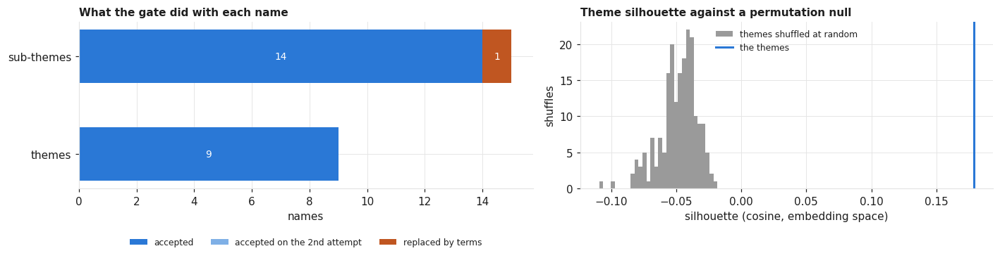


PRACTITIONER NOTE
  Separate producing a label from accepting it, and test what it asserts, not only how well it fits.
  Decide per cluster whether it may be reported plainly or with a caveat, and keep the ones that fail:
  a cluster that does not pass its own checks is a finding about the corpus, not noise to drop.


In [ ]:
# @title
# ==================================================================================================
# PHASE: NAMING                                                         stage 2 of 2 in this phase
# STAGE 18  THE NAME GATE
# WHAT THIS CELL DOES: tests every name against its cluster's own words and rejects the ones that
#                      fail
# ==================================================================================================
# WHAT THIS CELL DOES
#   Applies the acceptance tests from Stage 17 to every proposed theme and sub-theme name, replacing
#   any name that fails with a label built from the cluster's own terms. Tests whether each theme is
#   coherent enough to report, and builds a table stating what may be said about each theme.
#
# WHY
#   Separating acceptance from production lets a name be checked and rejected without touching the
#   clustering. The tests include what a name asserts, not only how well it fits, because a name
#   drawn from public reporting can claim a level, rate or direction the counts do not support. A
#   theme that fails its own coherence check is evidence about the corpus, and is reported, not
#   discarded.
#
# HOW
#   Reapplies the eight tests defined in Stage 17 (check_level): length, forbidden quantity and
#   method words, language, distinctiveness (smoothed lift), discrimination against rival clusters,
#   lexical coverage, and uniqueness. The distinctiveness, discrimination and coverage tests apply
#   only where most of a cluster's passages are in the reference language; elsewhere the record says
#   so. Theme coherence is the Stage 15 silhouette in the embedding space (cosine), judged against a
#   permutation null that shuffles the theme labels (Rousseeuw 1987).
#
# REFERENCES
#   Rousseeuw, P.J. (1987) Silhouettes: a graphical aid to the interpretation and validation of
#     cluster analysis. Journal of Computational and Applied Mathematics 20:53-65.
#     DOI 10.1016/0377-0427(87)90125-7

import numpy as np, pandas as pd
from sklearn.metrics import silhouette_score, silhouette_samples

heading("STAGE 18  THE NAME GATE")

print(f"  words {CFG.name_min_words} to {CFG.name_max_words}, minimum lift {CFG.name_min_lift}, "
      f"minimum margin {CFG.name_min_margin}")
print(f"  lexical tests apply when at least {CFG.name_lexical_min_share:.0%} of a cluster is in "
      f"{CFG.name_language}")
print(f"  forbidden words: {len(FORBIDDEN_QUANTITY)} quantity, {len(FORBIDDEN_META)} method; "
      f"matching: {STEMMING}")

GATE = []
for level, label_column, _, _ in NAME_LEVELS:
    for value, verdict in sorted(NAME_VERDICTS[level].items()):
        record = NAMES_RAW[level][value]
        accepted = bool(verdict["accepted"])
        GATE.append({
            "level": level, "theme": int(value), "passages": int(verdict["passages"]),
            "proposed": record["name"], "first_proposal": record.get("first_proposal", ""),
            "retried": bool(record.get("retried", False)),
            "first_failed": "; ".join(record.get("first_failures", [])),
            "source": record["source"], "accepted": accepted,
            "final_name": record["name"] if accepted else name_from_terms(level, value),
            "failed": "; ".join(verdict["failures"]),
            "kinds": ", ".join(dict.fromkeys(verdict["kinds"])),
            "own_lift": verdict["own"], "rival_lift": verdict["rival"],
            "rival": verdict["rival_value"], "margin": verdict["margin"],
            "lexical": verdict["lexical"], "language_share": verdict["language_share"],
            "coverage": verdict["covered"], "not_covered": verdict["not_covered"]})
GATE = pd.DataFrame(GATE)

# The names used everywhere below this cell are the gated ones.
THEME_NAMES = {level: dict(zip(GATE.loc[GATE["level"] == level, "theme"],
                               GATE.loc[GATE["level"] == level, "final_name"]))
               for level, _, _, _ in NAME_LEVELS}
NAME_ACCEPTED = {level: dict(zip(GATE.loc[GATE["level"] == level, "theme"],
                                 GATE.loc[GATE["level"] == level, "accepted"]))
                 for level, _, _, _ in NAME_LEVELS}
passages["theme_main_name"] = passages["theme_main"].map(THEME_NAMES["main"])
passages["theme_sub_name"] = passages["theme_sub"].map(THEME_NAMES["sub"])

for level, _, _, _ in NAME_LEVELS:
    block = GATE[GATE["level"] == level].sort_values("passages", ascending=False)
    passed = int(block["accepted"].sum())
    print()
    print(f"  {level.upper()} LEVEL: {passed} of {len(block)} model name(s) accepted")
    for _, row in block.iterrows():
        mark = "ok    " if row["accepted"] else "REFUSE"
        second = "  (second attempt)" if row["retried"] else ""
        print(f"    {mark} {row['theme']:>3}  {row['passages']:>6,}  {row['final_name'][:44]:<44}"
              f"{second}")
        if row["retried"]:
            print(f"             first answer : {row['first_proposal'][:60]}")
            print(f"             refused for  : {row['first_failed'][:90]}")
        if not row["accepted"]:
            print(f"             model said   : {row['proposed'][:60]}")
            print(f"             refused for  : {row['failed'][:90]}")
            print(f"             replaced by  : {row['final_name'][:60]}")

_rejected = GATE[~GATE["accepted"]]
print()
print(f"  SUMMARY OF THE NAME GATE")
print(f"    names               : {len(GATE)}")
print(f"    accepted            : {int(GATE['accepted'].sum())}")
print(f"      at the first attempt  : {int((GATE['accepted'] & ~GATE['retried']).sum())}")
print(f"      at the second attempt : {int((GATE['accepted'] & GATE['retried']).sum())}")
print(f"    refused, term label : {len(_rejected)}")
if len(_rejected):
    # Tallied by kind of failure, not the exact text, which carries a cluster number.
    _KIND_WORDS = {"rival": "fits another cluster as well or better", "duplicate": "same name as "
                   "another cluster", "language": "not in English", "quantity": "asserts a quantity",
                   "method": "names the method", "length": "wrong length",
                   "not distinctive": "no distinctive word", "coverage": "absent from most passages"}
    _reasons = pd.Series([kind.strip() for text in _rejected["kinds"] for kind in text.split(",")
                          if kind.strip()])
    for kind, count in _reasons.value_counts().items():
        print(f"      {count:>3}  {_KIND_WORDS.get(kind, kind)}")
    print(f"    A refused name is replaced by a term-based label; the model's name is kept above.")
_not_lexical = GATE[~GATE["lexical"].astype(str).str.startswith("applied")
                    & GATE["source"].astype(str).str.startswith("instruction model")]
if len(_not_lexical):
    print(f"    {len(_not_lexical)} name(s) not tested word against word (mostly not in "
          f"{CFG.name_language});")
    print(f"    judged on length, forbidden words, language and uniqueness only.")

# ---- is each theme coherent enough to report? -------------------------------
# The silhouette is Stage 15's, in the embedding space; the null shuffles the theme labels.
print()
print(f"  THEME COHERENCE, silhouette in the embedding space (cosine)")
_labels = MAIN_LABELS
SILHOUETTE_OVERALL = float(passages["silhouette_main"].mean())
SILHOUETTE_NULL = np.array([])
if K_MAIN_OBTAINED >= 2:
    from sklearn.metrics.pairwise import cosine_distances
    _rng = np.random.default_rng(CFG.seed + 71)
    _rounds = min(200, max(50, int(CFG.bootstrap_n) * 4))
    _sample = (_rng.choice(len(_labels), size=int(CFG.permutation_max_n), replace=False)
               if len(_labels) > int(CFG.permutation_max_n) else np.arange(len(_labels)))
    _sub = cosine_distances(X[_sample])
    _sub_labels = _labels[_sample]
    _observed_on_sample = float(silhouette_score(_sub, _sub_labels, metric="precomputed"))
    SILHOUETTE_NULL = np.array([
        silhouette_score(_sub, _rng.permutation(_sub_labels), metric="precomputed")
        for _ in range(_rounds)])
    _p = float((SILHOUETTE_NULL >= _observed_on_sample).sum() + 1) / (len(SILHOUETTE_NULL) + 1)
    print(f"    silhouette, all {len(_labels):,} passages : {SILHOUETTE_OVERALL:.4f}")
    print(f"    floor declared in Stage 1            : {CFG.silhouette_floor}")
    print(f"    permutation null, {_rounds} shuffles on {len(_sample):,} passages:")
    print(f"      observed on that sample            : {_observed_on_sample:.4f}")
    print(f"      null mean                          : {SILHOUETTE_NULL.mean():.4f}")
    print(f"      null 95th percentile               : {np.percentile(SILHOUETTE_NULL, 95):.4f}")
    print(f"      p                                  : {_p:.4f}"
          f"   (share of shuffles reaching the observed value)")
    if SILHOUETTE_OVERALL < float(CFG.silhouette_floor):
        print(f"    BELOW the declared floor. Report this figure with the themes.")

    _theme_sil = (passages.groupby("theme_main")["silhouette_main"]
                  .agg(["mean", "min", "count"]).reset_index())
    print()
    print(f"    {'theme':>5}  {'n':>6}  {'silhouette':>10}  {'worst':>7}  name")
    for _, row in _theme_sil.sort_values("mean").iterrows():
        theme = int(row["theme_main"])
        print(f"    {theme:>5}  {int(row['count']):>6,}  {row['mean']:>10.4f}  "
              f"{row['min']:>7.4f}  {THEME_NAMES['main'].get(theme, '?')[:40]}")

# ---- one table saying what may be said about each theme ---------------------
REPORTABLE = pd.DataFrame({"theme_main": sorted(THEME_NAMES["main"])})
REPORTABLE["name"] = REPORTABLE["theme_main"].map(THEME_NAMES["main"])
REPORTABLE["name_accepted"] = REPORTABLE["theme_main"].map(NAME_ACCEPTED["main"])
REPORTABLE = REPORTABLE.merge(STABILITY[["theme_main", "jaccard_seeds", "jaccard_passages",
                                         "passages", "coherence", "confidence_mean"]],
                              on="theme_main", how="left")
REPORTABLE["stable"] = ~REPORTABLE["theme_main"].isin(UNSTABLE_THEMES)
REPORTABLE["held_firmly"] = ~REPORTABLE["theme_main"].isin(WEAK_THEMES)
REPORTABLE["report_without_caveat"] = (REPORTABLE["name_accepted"] & REPORTABLE["stable"]
                                       & REPORTABLE["held_firmly"])

print()
print(f"  WHAT MAY BE SAID ABOUT EACH THEME")
print(f"    {'theme':>5}  {'n':>6}  {'name ok':>7}  {'stable':>6}  {'firm':>5}  "
      f"{'plain reporting':>15}  name")
for _, row in REPORTABLE.sort_values("passages", ascending=False).iterrows():
    print(f"    {int(row['theme_main']):>5}  {int(row['passages']):>6,}  "
          f"{str(bool(row['name_accepted'])):>7}  {str(bool(row['stable'])):>6}  "
          f"{str(bool(row['held_firmly'])):>5}  "
          f"{('yes' if row['report_without_caveat'] else 'WITH CAVEAT'):>15}  {row['name'][:34]}")
_caveat = REPORTABLE[~REPORTABLE["report_without_caveat"]]
print()
print(f"    {len(REPORTABLE) - len(_caveat)} of {len(REPORTABLE)} themes may be reported plainly.")
if len(_caveat):
    print(f"    The other {len(_caveat)} carry a caveat wherever they appear; none is removed.")

# ---- figure: what happened to the names, and the theme silhouette against its null ------------
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
_outcomes = [("accepted", lambda g: g["accepted"] & ~g["retried"], PALETTE[0]),
             ("accepted on the 2nd attempt", lambda g: g["accepted"] & g["retried"], "#7fb0e6"),
             ("replaced by terms", lambda g: ~g["accepted"], WARN)]
_levels = [("main", "themes"), ("sub", "sub-themes")]
for y, (level, label) in enumerate(_levels):
    block, left = GATE[GATE["level"] == level], 0
    for outcome, rule_of, colour in _outcomes:
        n = int(rule_of(block).sum())
        ax.barh(y, n, left=left, color=colour, height=0.55, label=outcome if y == 0 else None)
        if n:
            ax.text(left + n / 2, y, str(n), ha="center", va="center", color="white", fontsize=9)
        left += n
ax.set_yticks(range(len(_levels)))
ax.set_yticklabels([label for _, label in _levels])
ax.set_xlabel("names")
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax.set_title("What the gate did with each name", fontsize=10, loc="left")
ax = axes[1]
if len(SILHOUETTE_NULL):
    ax.hist(SILHOUETTE_NULL, bins=30, color=OTHER, label="themes shuffled at random")
    ax.axvline(_observed_on_sample, color=PALETTE[0], lw=2, label="the themes")
    ax.legend(fontsize=8, frameon=False)
    ax.set_xlabel("silhouette (cosine, embedding space)")
    ax.set_ylabel("shuffles")
else:
    ax.axis("off")
ax.set_title("Theme silhouette against a permutation null", fontsize=10, loc="left")
fig.tight_layout()
save_figure(fig, "s18_name_gate")
plt.show()

rule()

report("gate.names_proposed", len(GATE), "names", "Stage 18")
report("gate.names_accepted", int(GATE["accepted"].sum()), "names", "Stage 18")
report("gate.names_rejected", int((~GATE["accepted"]).sum()), "names", "Stage 18")
report("gate.names_accepted_second_attempt", int((GATE["accepted"] & GATE["retried"]).sum()),
       "names", "Stage 18")
report("gate.names_without_lexical_test", int(len(_not_lexical)), "names", "Stage 18")
report("gate.silhouette_embedding", round(SILHOUETTE_OVERALL, 4)
       if np.isfinite(SILHOUETTE_OVERALL) else float("nan"), "silhouette", "Stage 18")
report("gate.themes_reportable_plainly",
       int(REPORTABLE["report_without_caveat"].sum()), "themes", "Stage 18")

practitioner_note("Gating what you say", """
Separate producing a label from accepting it, and test what it asserts, not only how well it fits.
Decide per cluster whether it may be reported plainly or with a caveat, and keep the ones that fail:
a cluster that does not pass its own checks is a finding about the corpus, not noise to drop.
""")

## Stage 19: which clusters are health   [phase: health scope]

**Rule.** A sub-theme is health-related when at least 40% of its passages match the health lexicon of
notebook 1. Themes inherit their health-related sub-themes.

**Sensitivity.** The rule is re-applied at 30% and 50%, and the cell reports how far the country
comparison moves. Any manual override is printed.

  STAGE 19  WHICH CLUSTERS ARE HEALTH
  rule: in scope when >= 40% of a sub-theme's passages match the lexicon
  applied at the sub-theme level, 15 sub-themes; alternatives tested: 30%, 40%, 50%
  passages matching lexicon : 2,622 of 3,912 (67.0%)

   sub   main       n   matched   share   scope  name
    10      3     156       155  99.4%     IN   cholera treatment
     9      2     163       152  93.3%     IN   water / sanitation / latrines
     4      2     239       217  90.8%     IN   acute malnutrition in children
    13      3     117       105  89.7%     IN   measles vaccination campaigns
     7      6     177       153  86.4%     IN   maternity care complications
    14      3      86        73  84.9%     IN   mpox outbreak response
     5      4     202       167  82.7%     IN   post-traumatic stress disorder
    11      8     137       106  77.4%     IN   sexual violence survivors
     0      0     872       550  63.1%     IN   wounded patients in hospital
     1      0     

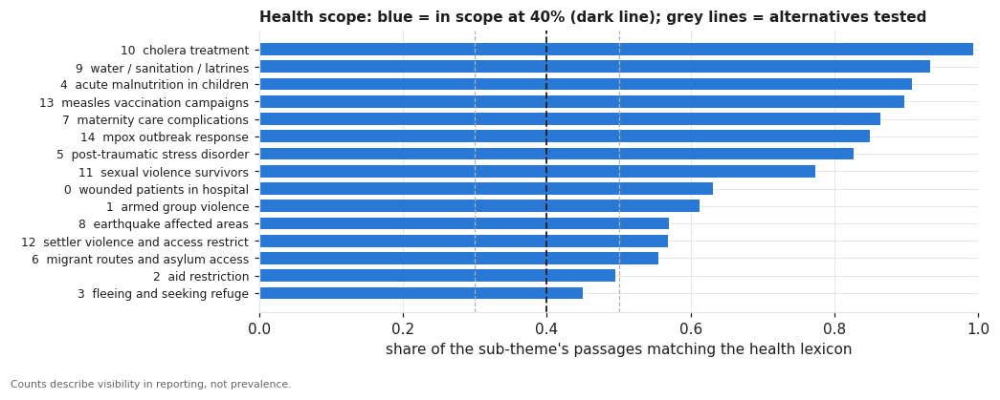


PRACTITIONER NOTE
  Find the choice sitting in the denominator of every comparison, and test it: apply every
  alternative threshold in full, and compare the ORDER of results, since findings are comparisons.
  Report whichever answer you get, and print every manual override with its direction.


In [ ]:
# @title
# ==================================================================================================
# PHASE: HEALTH SCOPE                                                 the only stage in this phase
# STAGE 19  WHICH CLUSTERS ARE HEALTH
# WHAT THIS CELL DOES: marks the health sub-themes with the lexicon, and tests other thresholds
# ==================================================================================================
# WHAT THIS CELL DOES
#   Decides which sub-themes are in scope for the study, applies the rule to the passage table,
#   tests how sensitive the resulting group ranking is to the threshold, and builds the
#   subject-related set (HEALTH_SET) that notebook 3 works on.
#
# WHY
#   The clustering in Stage 14 partitions every passage, including material outside the subject
#   under study. Every downstream comparison has this scope decision in its denominator, so the
#   threshold and its effect on the results must be shown, not only applied.
#
# HOW
#   A sub-theme is in scope when at least SCOPE_SHARE_FLOOR of its passages match the in-scope
#   lexicon (Stage 6). Scope is decided at the sub-theme, not the main-theme, level, since main
#   themes are coarse enough to mix both kinds of material; main themes inherit whichever of their
#   sub-themes are in scope. Manual overrides in SCOPE_MANUAL_OVERRIDE are applied and printed with
#   their direction. Every alternative threshold in SCOPE_SENSITIVITY is applied in full, and the
#   resulting group ranking is compared with the one at the threshold in force by Spearman rank
#   correlation.

import numpy as np, pandas as pd

heading("STAGE 19  WHICH CLUSTERS ARE HEALTH")

SCOPE_COLUMN = "in_scope"
if SCOPE_COLUMN not in passages.columns:
    raise RuntimeError(
        f"Column '{SCOPE_COLUMN}' is missing; run notebook 1 to its last cell and use its handoff.")

print(f"  rule: in scope when >= {float(CFG.scope_share_floor):.0%} of a sub-theme's passages "
      f"match the lexicon")
print(f"  applied at the sub-theme level, {K_SUB_OBTAINED} sub-themes; alternatives tested: "
      f"{', '.join(f'{v:.0%}' for v in CFG.scope_sensitivity)}")
print(f"  passages matching lexicon : {int(passages[SCOPE_COLUMN].sum()):,} of {len(passages):,} "
      f"({passages[SCOPE_COLUMN].mean():.1%})")

# ---- the share per sub-theme, and the rule ----------------------------------
SUB_SCOPE = (passages.groupby("theme_sub")
             .agg(passages=("theme_sub", "size"),
                  matched=(SCOPE_COLUMN, "sum"),
                  share=(SCOPE_COLUMN, "mean"),
                  main=("theme_main", lambda s: int(s.mode().iloc[0])))
             .reset_index())
SUB_SCOPE["name"] = SUB_SCOPE["theme_sub"].map(THEME_NAMES["sub"])
SUB_SCOPE["in_scope_by_rule"] = SUB_SCOPE["share"] >= float(CFG.scope_share_floor)

_override = {int(k): bool(v) for k, v in dict(CFG.scope_manual_override).items()} \
    if CFG.scope_manual_override else {}
SUB_SCOPE["overridden"] = SUB_SCOPE["theme_sub"].isin(_override)
SUB_SCOPE["in_scope"] = [
    _override.get(int(theme), bool(rule))
    for theme, rule in zip(SUB_SCOPE["theme_sub"], SUB_SCOPE["in_scope_by_rule"])]

print()
print(f"  {'sub':>4}  {'main':>5}  {'n':>6}  {'matched':>8}  {'share':>6}  {'scope':>6}  name")
for _, row in SUB_SCOPE.sort_values("share", ascending=False).iterrows():
    mark = "IN " if row["in_scope"] else "out"
    if row["overridden"]:
        mark += " (by hand)"
    print(f"  {int(row['theme_sub']):>4}  {int(row['main']):>5}  {int(row['passages']):>6,}  "
          f"{int(row['matched']):>8,}  {row['share']:>5.1%}  {mark:>6}  "
          f"{str(row['name'])[:36]}")

if _override:
    print()
    print(f"  MANUAL OVERRIDES: {len(_override)}")
    for theme, decision in sorted(_override.items()):
        row = SUB_SCOPE[SUB_SCOPE["theme_sub"] == theme]
        if not len(row):
            print(f"    sub-theme {theme}: NOT PRESENT; the override does nothing.")
            continue
        row = row.iloc[0]
        by_rule = "in" if row["in_scope_by_rule"] else "out"
        print(f"    sub-theme {theme:>3} forced {'IN' if decision else 'OUT'} "
              f"(the rule would put it {by_rule}, at {row['share']:.1%}): "
              f"{str(row['name'])[:40]}")
else:
    print()
    print(f"  MANUAL OVERRIDES: none. Every scope decision below follows the rule alone.")

IN_SCOPE_SUB = set(int(v) for v in SUB_SCOPE.loc[SUB_SCOPE["in_scope"], "theme_sub"])
passages["sub_in_scope"] = passages["theme_sub"].isin(IN_SCOPE_SUB)
ANALYSED = passages.loc[passages["sub_in_scope"]].copy()

MAIN_SCOPE = (passages.groupby("theme_main")
              .agg(passages=("theme_main", "size"),
                   in_scope_passages=("sub_in_scope", "sum"),
                   share=("sub_in_scope", "mean"),
                   sub_themes=("theme_sub", "nunique"))
              .reset_index())
MAIN_SCOPE["in_scope_sub_themes"] = [
    int(passages.loc[passages["theme_main"] == theme, "theme_sub"]
        .isin(IN_SCOPE_SUB).groupby(passages.loc[passages["theme_main"] == theme, "theme_sub"])
        .any().sum())
    for theme in MAIN_SCOPE["theme_main"]]
MAIN_SCOPE["name"] = MAIN_SCOPE["theme_main"].map(THEME_NAMES["main"])

print()
print(f"  IN SCOPE")
print(f"    sub-themes            : {len(IN_SCOPE_SUB)} of {K_SUB_OBTAINED}")
print(f"    passages              : {len(ANALYSED):,} of {len(passages):,} "
      f"({len(ANALYSED)/len(passages):.1%})")
print(f"    documents represented : {ANALYSED['doc_id'].nunique():,} of "
      f"{passages['doc_id'].nunique():,}")
# A rule that puts every sub-theme on the same side separates nothing; that is said, not hidden.
SCOPE_DISCRIMINATES = 0 < len(IN_SCOPE_SUB) < K_SUB_OBTAINED
if not SCOPE_DISCRIMINATES:
    print()
    print(f"  NOTE: the rule does not separate sub-themes on this corpus. Every sub-theme is "
          f"{'in' if len(IN_SCOPE_SUB) else 'out of'} scope")
    print(f"  (lowest share {SUB_SCOPE['share'].min():.0%}, highest {SUB_SCOPE['share'].max():.0%}"
          f", threshold {float(CFG.scope_share_floor):.0%}). The corpus was collected for this "
          f"subject,")
    print(f"  so the in-scope set is the whole corpus and every comparison is over all passages.")
report("scope.rule_separates_sub_themes", int(SCOPE_DISCRIMINATES), "0 or 1", "Stage 19")
print()
print(f"  MAIN THEMES, AND HOW MUCH OF EACH IS IN SCOPE")
print(f"    {'theme':>5}  {'n':>6}  {'in scope':>9}  {'share':>6}  {'subs in/of':>11}  name")
for _, row in MAIN_SCOPE.sort_values("in_scope_passages", ascending=False).iterrows():
    print(f"    {int(row['theme_main']):>5}  {int(row['passages']):>6,}  "
          f"{int(row['in_scope_passages']):>9,}  {row['share']:>5.1%}  "
          f"{int(row['in_scope_sub_themes']):>4} of {int(row['sub_themes']):<4}  "
          f"{str(row['name'])[:34]}")
_partial = MAIN_SCOPE[(MAIN_SCOPE["share"] > 0.05) & (MAIN_SCOPE["share"] < 0.95)]
if len(_partial):
    print()
    print(f"    {len(_partial)} main theme(s) are partly in and out of scope; whole-theme and")
    print(f"    in-scope counts differ, and each table below states which it uses.")

# ---- does the scope rule explain the incoherent themes? ---------------------
# A theme mixing in-scope and out-of-scope material has no common subject; remedy differs by case.
if INCOHERENT_THEMES:
    print()
    print(f"  WHY THE INCOHERENT THEME(S) FROM STAGE 15 ARE INCOHERENT")
    for theme in sorted(INCOHERENT_THEMES):
        block = passages.loc[passages["theme_main"] == theme]
        out_of_scope = int((~block["sub_in_scope"]).sum())
        share_out = out_of_scope / max(1, len(block))
        subs = (block.groupby("theme_sub")
                .agg(n=("theme_sub", "size"), in_scope=("sub_in_scope", "first"))
                .sort_values("n", ascending=False))
        print(f"    main theme {theme}: {len(block):,} passages, {out_of_scope:,} of them out of "
              f"scope ({share_out:.0%})")
        print(f"      it contains {len(subs)} sub-theme(s), "
              f"{int((~subs['in_scope']).sum())} of which are out of scope")
        for sub, row in subs.head(4).iterrows():
            print(f"        sub {int(sub):>3}  {int(row['n']):>6,}  "
                  f"{'in scope ' if row['in_scope'] else 'OUT      '}  "
                  f"{str(THEME_NAMES['sub'].get(int(sub), ''))[:38]}")
        if share_out >= 0.40:
            print(f"      DIAGNOSIS: largely out-of-scope material with no common subject; report")
            print(f"      counts over its sub-themes or the in-scope set, not the whole theme.")
        else:
            print(f"      DIAGNOSIS: mostly in scope, still incoherent; see Stage 15's theme tree.")

# ---- sub-themes too small to compare across groups -----------------------------
# Below MIN_SUBTHEME_SIZE (Stage 14) a sub-theme cannot be compared across all groups.
_tiny = SUB_SCOPE[SUB_SCOPE["passages"] < int(MIN_SUBTHEME_SIZE)]
print()
print(f"  SUB-THEMES TOO SMALL TO COMPARE")
print(f"    {len(_tiny)} of {K_SUB_OBTAINED} sub-theme(s) hold fewer than "
      f"{int(MIN_SUBTHEME_SIZE)} passages, the smallest comparable size (Stage 14).")
if len(_tiny):
    for _, row in _tiny.sort_values("passages").iterrows():
        print(f"      sub {int(row['theme_sub']):>3}  {int(row['passages']):>5}  "
              f"{'in scope' if row['in_scope'] else 'out     '}  {str(row['name'])[:40]}")
    print(f"    Kept in every total but left out of comparisons across {plural(CFG.group_noun)}; "
          f"comparable sub-themes: {K_SUB_OBTAINED - len(_tiny)}.")
SUB_THEMES_REPORTABLE = K_SUB_OBTAINED - len(_tiny)
SUB_THEMES_TOO_SMALL = sorted(int(v) for v in _tiny["theme_sub"])

# ---- the health-related set, as a named object rather than a flag -----------
# Built explicitly, with names and counts, because notebook 3 works on this set directly.
HEALTH_SUBTHEMES = sorted(int(v) for v in IN_SCOPE_SUB)
HEALTH_THEMES = sorted(int(v) for v in
                       passages.loc[passages["sub_in_scope"], "theme_main"].unique())

HEALTH_SET = []
for theme in HEALTH_THEMES:
    subs = [s for s in HEALTH_SUBTHEMES
            if int(passages.loc[passages["theme_sub"] == s, "theme_main"].iloc[0]) == theme]
    block_rows = passages.loc[passages["theme_main"] == theme]
    in_scope_rows = block_rows.loc[block_rows["sub_in_scope"]]
    for sub in subs:
        sub_rows = passages.loc[passages["theme_sub"] == sub]
        HEALTH_SET.append({
            "theme": theme,
            "theme_name": THEME_NAMES["main"].get(theme, ""),
            "sub_theme": sub,
            "sub_theme_name": THEME_NAMES["sub"].get(sub, ""),
            "passages": int(len(sub_rows)),
            "documents": int(sub_rows["doc_id"].nunique()),
            "lexicon_match_share": float(sub_rows[SCOPE_COLUMN].mean()),
            "coherence": float(SUBTHEME_TABLE.loc[
                SUBTHEME_TABLE["theme_sub"] == sub, "coherence"].iloc[0])
                if (SUBTHEME_TABLE["theme_sub"] == sub).any() else float("nan"),
            "incoherent": sub in INCOHERENT_SUBTHEMES,
            "language_artefact": sub in LANGUAGE_ARTEFACT_SUBTHEMES,
            "theme_incoherent": theme in INCOHERENT_THEMES,
        })
HEALTH_SET = pd.DataFrame(HEALTH_SET)

print()
print(f"  THE {str(CFG.subject_name).upper()}-RELATED SET")
print(f"    themes represented    : {len(HEALTH_THEMES)} of {K_MAIN_OBTAINED}")
print(f"    sub-themes            : {len(HEALTH_SUBTHEMES)} of {K_SUB_OBTAINED}")
print(f"    passages              : {len(ANALYSED):,} of {len(passages):,} "
      f"({len(ANALYSED)/len(passages):.1%})")
print(f"    documents             : {int(ANALYSED['doc_id'].nunique()):,} of "
      f"{int(passages['doc_id'].nunique()):,}")
print()
if len(HEALTH_SET):
    print(f"    {'theme':>5}  {'sub':>4}  {'passages':>9}  {'docs':>6}  {'match':>6}  "
          f"{'coh':>6}  name")
    _last = None
    for _, row in HEALTH_SET.sort_values(["theme", "passages"],
                                         ascending=[True, False]).iterrows():
        if row["theme"] != _last:
            _last = row["theme"]
            _mark = "  <- theme failed the coherence check" if row["theme_incoherent"] else ""
            print(f"    theme {int(row['theme'])}: {str(row['theme_name'])[:46]}{_mark}")
        flags = ", ".join(f for f, on in (("incoherent", row["incoherent"]),
                                          ("language artefact", row["language_artefact"])) if on)
        print(f"    {int(row['theme']):>5}  {int(row['sub_theme']):>4}  "
              f"{int(row['passages']):>9,}  {int(row['documents']):>6,}  "
              f"{row['lexicon_match_share']:>5.1%}  {row['coherence']:>6.3f}  "
              f"{str(row['sub_theme_name'])[:34]}{'   [' + flags + ']' if flags else ''}")

    _path = os.path.join(FIGURE_DIR, "s19_health_related_set.csv")
    HEALTH_SET.to_csv(_path, index=False)
    _path_on_drive = keep_on_drive(_path)
    print()
    print(f"    written to {_path}")
    if _path_on_drive:
        print(f"    and to     {_path_on_drive}")
    print(f"    This table travels in the handoff; its flags travel with it so notebook 3 does not")
    print(f"    report a comparison as clean when the sub-theme behind it was not.")
else:
    print(f"    The set is empty: no sub-theme cleared the lexical share. Check the threshold and")
    print(f"    lexicon before reading anything below as a result.")

# ---- sensitivity of the scope rule to its threshold --------------------------
print()
print(f"  SENSITIVITY TO THE THRESHOLD")
print(f"    Each alternative is applied in full; what matters is whether group ORDER changes, not")
print(f"    whether the counts themselves change, since the findings are comparisons.")

_group_column = group_column(passages)
_has_groups = _group_column is not None
SCOPE_ALTERNATIVES = []
_reference_rank = None
for threshold in sorted({float(CFG.scope_share_floor), *[float(v) for v in CFG.scope_sensitivity]}):
    keep = set(int(v) for v in SUB_SCOPE.loc[SUB_SCOPE["share"] >= threshold, "theme_sub"])
    keep = {t for t in keep if _override.get(t, True)} | {t for t, v in _override.items() if v}
    subset = passages.loc[passages["theme_sub"].isin(keep)]
    entry = {"threshold": threshold, "sub_themes": len(keep), "passages": len(subset),
             "share_of_corpus": len(subset) / len(passages),
             "documents": int(subset["doc_id"].nunique()) if len(subset) else 0,
             "is_the_rule": abs(threshold - float(CFG.scope_share_floor)) < 1e-9}
    if _has_groups and len(subset):
        ranking = (subset.groupby(_group_column).size()
                   / passages.groupby(_group_column).size()).dropna().rank(ascending=False)
        if entry["is_the_rule"]:
            _reference_rank = ranking
        entry["_ranking"] = ranking
    SCOPE_ALTERNATIVES.append(entry)

import warnings
for entry in SCOPE_ALTERNATIVES:
    if _has_groups and _reference_rank is not None and "_ranking" in entry:
        shared = _reference_rank.index.intersection(entry["_ranking"].index)
        # A ranking with every group tied has no rank correlation. SciPy warns and returns NaN; the
        # NaN is kept and explained in words below, so the warning itself is not printed.
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore", message="An input array is constant")
            entry["rank_correlation"] = (float(_reference_rank[shared].corr(
                entry["_ranking"][shared], method="spearman")) if len(shared) > 2
                else float("nan"))
        entry["groups_moving_rank"] = int(
            (_reference_rank[shared] != entry["_ranking"][shared]).sum())
    entry.pop("_ranking", None)
SCOPE_ALTERNATIVES = pd.DataFrame(SCOPE_ALTERNATIVES)

print()
print(f"    {'threshold':>9}  {'subs':>5}  {'passages':>9}  {'of corpus':>10}  "
      f"{'rank corr':>10}  {'groups moved':>12}")
for _, row in SCOPE_ALTERNATIVES.iterrows():
    mark = "  <- the rule in force" if row["is_the_rule"] else ""
    corr = row.get("rank_correlation", float("nan"))
    moved = row.get("groups_moving_rank", float("nan"))
    print(f"    {row['threshold']:>8.0%}  {int(row['sub_themes']):>5}  {int(row['passages']):>9,}  "
          f"{row['share_of_corpus']:>9.1%}  "
          f"{(f'{corr:.3f}' if np.isfinite(corr) else 'n/a'):>10}  "
          f"{('' if not np.isfinite(moved) else f'{int(moved)}'):>12}{mark}")

# Rank correlation is undefined when every group ties (full scope) or fewer than three groups have
# passages; the worst case is sought only among defined values, else the table is reported as-is.
_defined = (SCOPE_ALTERNATIVES["rank_correlation"].dropna()
            if _has_groups and "rank_correlation" in SCOPE_ALTERNATIVES else pd.Series(dtype=float))
if len(_defined):
    _worst = SCOPE_ALTERNATIVES.loc[_defined.idxmin()]
    SCOPE_WORST_CORRELATION = float(_worst["rank_correlation"])
    print()
    print(f"    Alternative disturbing the ranking most: {_worst['threshold']:.0%}, rank "
          f"correlation {SCOPE_WORST_CORRELATION:.3f}.")
    if SCOPE_WORST_CORRELATION >= 0.95:
        print(f"    The group ordering does not depend on the threshold.")
    else:
        print(f"    The group ordering DOES depend on the threshold; report affected comparisons")
        print(f"    with this table, and mark any group whose rank moves as threshold-sensitive.")
elif _has_groups:
    SCOPE_WORST_CORRELATION = float("nan")
    _tied = _reference_rank is not None and _reference_rank.nunique() <= 1
    print()
    if _tied:
        print(f"    No rank correlation: every {CFG.group_noun} has the same in-scope share, so "
              f"there is no order to disturb.")
    else:
        print(f"    No rank correlation: fewer than three {plural(CFG.group_noun)} have passages "
              f"in scope at every threshold.")
    print(f"    Sensitivity is reported in passages and sub-themes only.")
else:
    SCOPE_WORST_CORRELATION = float("nan")
    print()
    print(f"    No group variable in this corpus; sensitivity is reported in passages and "
          f"sub-themes only.")

# ---- figure: lexicon share per sub-theme against the scope rule and its alternatives --------
import matplotlib.pyplot as plt
_s = SUB_SCOPE.sort_values("share").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, max(3.6, 0.22 * len(_s))))
ax.barh([f"{int(v)}  {str(n)[:36]}" for v, n in zip(_s["theme_sub"], _s["name"])], _s["share"],
        color=[PALETTE[0] if v else OTHER for v in _s["in_scope"]], height=0.7)
for x in CFG.scope_sensitivity:
    ax.axvline(float(x), color=INK if float(x) == float(CFG.scope_share_floor) else "#b0b0b0",
               ls="--", lw=1.2 if float(x) == float(CFG.scope_share_floor) else 0.8)
ax.tick_params(axis="y", labelsize=7 if len(_s) > 30 else 8)
ax.set_xlim(0, 1)
ax.set_xlabel(f"share of the sub-theme's passages matching the {CFG.subject_name} lexicon")
ax.set_title(f"{str(CFG.subject_name).capitalize()} scope: blue = in scope at "
             f"{float(CFG.scope_share_floor):.0%} "
             f"(dark line); grey lines = alternatives tested", fontsize=10, loc="left")
fig.tight_layout()
add_reference_footer(fig, "Counts describe visibility in reporting, not prevalence.")
save_figure(fig, "s19_scope", slide_ready=True)
plt.show()

rule()

report("scope.threshold", float(CFG.scope_share_floor), "share", "Stage 19")
report("scope.sub_themes_in", len(IN_SCOPE_SUB), "sub-themes", "Stage 19")
report("scope.passages_in", len(ANALYSED), "passages", "Stage 19")
report("scope.documents_in", int(ANALYSED["doc_id"].nunique()), "documents", "Stage 19")
report("scope.manual_overrides", len(_override), "sub-themes", "Stage 19")
report("health_set.sub_themes", len(HEALTH_SUBTHEMES), "sub-themes", "Stage 19")
report("health_set.themes", len(HEALTH_THEMES), "themes", "Stage 19")
report("scope.sub_themes_reportable", SUB_THEMES_REPORTABLE, "sub-themes", "Stage 19")
report("scope.sub_themes_too_small", len(SUB_THEMES_TOO_SMALL), "sub-themes", "Stage 19")
report("scope.worst_rank_correlation", round(SCOPE_WORST_CORRELATION, 4)
       if np.isfinite(SCOPE_WORST_CORRELATION) else float("nan"), "Spearman", "Stage 19")
ledger_step("sub-themes out of scope", len(passages), len(ANALYSED),
            f"passages in sub-themes below the {float(CFG.scope_share_floor):.0%} lexical share",
            unit="passage")

practitioner_note("The threshold nobody sees", """
Find the choice sitting in the denominator of every comparison, and test it: apply every
alternative threshold in full, and compare the ORDER of results, since findings are comparisons.
Report whichever answer you get, and print every manual override with its direction.
""")

## Stage 19b: cluster and passage summaries   [phase: summaries]

**What.** A three-sentence summary per theme, per sub-theme and per health sub-theme, written by the
instruction model from measured evidence only: the accepted name, the distinctive terms and the most
typical passages. Then one sentence per passage (every passage when a GPU is present), written from
that passage's original text alone; it may name a place only if the passage does. For English
passages, the share of the summary's words found in the passage is recorded as a check.

**The one claim a summary may not make.** The corpus shows what is reported, not how common or severe
anything is. A summary that claims prevalence, incidence, burden or severity is asked for once more; if
it still does, it is withheld and the cluster is described by its name and evidence alone.

  STAGE 19b  CLUSTER AND PASSAGE SUMMARIES
  instruction model         : Qwen/Qwen3-4B-Instruct-2507
  sentences per cluster     : 3
  passage summary scope     : all  (auto: GPU present)
  forbidden claim phrases   : 29
  place words for the gate  : 1,183 (1,142 removed by masking, curated list, group names)
  gate identified by        : its source

  [cluster_summaries] not cached for key d2c8c3e460d6; computing ...
  [cluster_summaries] computed and saved | key d2c8c3e460d6 | 0.0 MB | copied to durable storage

  cluster summaries written  : 39 of 39
    themes                : 9 kept of 9
    sub-themes            : 15 kept of 15
    health sub-themes     : 15 kept of 15
  kept with a severity word after one retry: 4 (dashboard marks)
  regenerated once, because the first reply failed the check: 9
         6  characterises severity
         2  uses the placeholder word 'location'
         1  claims not measurable from this corpus

  passages to summarise      : 3,912 of 3,912 (scop

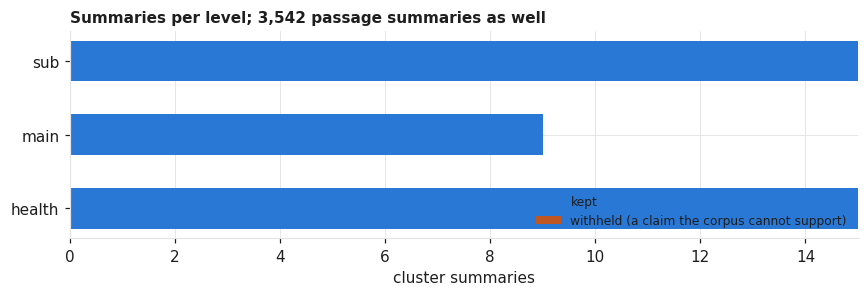

In [ ]:
# @title
# ==================================================================================================
# PHASE: SUMMARIES                                                      stage 1 of 2 in this phase
# STAGE 19b  CLUSTER AND PASSAGE SUMMARIES
# WHAT THIS CELL DOES: short summaries per cluster and per quoted passage, checked for unsupported
#                      claims
# ==================================================================================================
# WHAT THIS CELL DOES
#   Generates a short text summary for every cluster (themes, sub-themes, and health sub-themes)
#   and a one-sentence summary for each quoted passage, using an instruction model.
#
# WHY
#   A cluster name identifies a cluster but does not describe what its passages say. The corpus is
#   what agencies chose to publish, so a summary may describe what is visible in public reporting
#   and must not claim prevalence, incidence, burden or severity in a population.
#
# HOW
#   The model is prompted with each cluster's distinctive terms and representative passages (masked
#   text). Each reply is cleaned, then gated: rejected for a forbidden claim phrase or a named place
#   (a word masking removed, a curated place word or a group name), retried once for a severity
#   word or the place placeholder, trimmed to the requested length. A summary that still fails is
#   withheld and the cluster is reported by name and evidence only. Subject sub-themes (in scope,
#   Stage 19) are summarised again with a prompt that names the subject.
#   A passage summary is written from the ORIGINAL text of that one passage, so it may name a place
#   only if the passage does; one naming any other place is withheld. Its word support (share of
#   its content words found in the passage) is recorded, for English passages, as a check on
#   invented content. Results are cached, keyed on the labels, prompts and the gate itself.

heading("STAGE 19b  CLUSTER AND PASSAGE SUMMARIES")

if not bool(CFG.summary_enable):
    SUMMARIES = pd.DataFrame(columns=["level", "theme", "name", "in_scope", "summary",
                                      "source", "verdict", "reason", "n_passages"])
    PASSAGE_SUMMARIES = pd.DataFrame(columns=["passage", "theme_main", "theme_sub", "summary",
                                              "word_support"])
    print("  SUMMARY_ENABLE is False. No summary is produced; themes and names are unaffected.")
else:
    SUMMARY_SENTENCES = int(CFG.summary_cluster_sentences)
    FORBIDDEN_CLAIMS = tuple(str(p).lower() for p in CFG.summary_forbidden_claims)

    print(f"  instruction model         : "
          f"{CFG.llm_model if CFG.llm_enable else 'disabled in Stage 1'}"
          f"{'' if LLM.available else '  NOT AVAILABLE'}")
    print(f"  sentences per cluster     : {SUMMARY_SENTENCES}")
    # "auto": every passage when a GPU is present, so each point of the dashboard has its own
    # summary; the quoted passages only without one.
    SCOPE = str(CFG.summary_passage_scope)
    if SCOPE == "auto":
        SCOPE = "all" if globals().get("GPU_AVAILABLE") else "representative"
    PASSAGE_SUMMARY_SCOPE = SCOPE
    print(f"  passage summary scope     : {SCOPE}"
          + (f"  (auto: {'GPU present' if SCOPE == 'all' else 'no GPU'})"
             if CFG.summary_passage_scope == "auto" else ""))
    print(f"  forbidden claim phrases   : {len(FORBIDDEN_CLAIMS)}")

    # ---- the three levels this cell summarises ------------------------------
    # Health sub-themes are a subset of the sub-themes, reported on their own because the analysis
    # is about health; their prompt says so, so the summary describes health content, not the label.
    SUMMARY_LEVELS = [
        ("main", "theme_main", "confidence_main", "theme"),
        ("sub", "theme_sub", "confidence_sub", "sub-theme"),
        ("health", "theme_sub", "confidence_sub", f"{CFG.subject_name} sub-theme"),
    ]
    HEALTH_VALUES = set(int(v) for v in HEALTH_SUBTHEMES)

    def values_of(level, label_column):
        if level == "health":
            return sorted(HEALTH_VALUES)
        return sorted(int(v) for v in passages[label_column].unique())

    def name_of(level, value):
        return THEME_NAMES["sub" if level == "health" else level].get(value, f"cluster {value}")

    def terms_of(level, value):
        rows = TERMS["sub" if level == "health" else level].get(value, [])
        return [str(row["term"]) for row in rows][:12]

    def quotes_of(level, value):
        return QUOTES["sub" if level == "health" else level].get(value, [])

    # ---- the prompts -------------------------------------------------------
    SUMMARY_SYSTEM = (
        f"You are writing descriptions of clusters of passages from {CFG.document_type}s, for an "
        "academic thematic analysis. The corpus is what its authors chose to publish. It therefore "
        "shows what is REPORTED, and it cannot show how common, how severe or how widespread "
        "anything is in any population. Place names were replaced by the word "
        f"'{CFG.place_placeholder}' before analysis; do not use that word (write 'the area' if a "
        "place must be referred to), and do not name any place. "
        "You reply with the description alone and nothing else.")

    SUMMARY_RULES = (
        "Write exactly {n} sentence(s) describing what these passages are about. Follow these rules "
        "exactly:\n"
        "  Describe what the passages report. Write for example that the passages report disruption "
        "to routine immunisation, not that immunisation coverage is low.\n"
        "  Do not state or imply how common, how frequent, how severe or how widespread anything "
        "is. Do not use the words prevalence, incidence, burden, morbidity, mortality, widespread, "
        "most common, rising, worsening, worst affected or leading cause.\n"
        "  Do not name a country, region, city, camp or organisation.\n"
        "  Do not use the words theme, cluster, topic, group or category, and do not refer to the "
        "cluster or to this analysis.\n"
        "  Use the vocabulary of the passages themselves.\n"
        "  Write in ordinary academic English, in the present tense.\n\n"
        "Reply with the {n} sentence(s) alone and nothing else.")

    PASSAGE_SYSTEM = (
        f"You are compressing single passages from {CFG.document_type}s into one sentence each, "
        "so that a reader can see what a passage says without reading all of it. The passage "
        "reports what its author published. Your sentence says what the passage reports and "
        "nothing more. You reply with one sentence in English and nothing else.")

    PASSAGE_RULES = (
        "Compress the passage into ONE sentence of at most {n} words, in English. State what the "
        "passage reports. Add nothing that is not in it, and do not say how common, how severe or "
        "how widespread anything is. Name a place only if the passage itself names it. Reply with "
        "the one sentence alone.")

    def first_sentences(text, how_many):
        """Keep the first `how_many` sentences and drop the rest.

        A summary that is too long is trimmed, not regenerated: an unacceptable shape is a
        different failure from an unacceptable claim, and treating them alike discards good text."""
        parts = [p.strip() for p in SENTENCE_END.split(str(text).strip()) if p.strip()]
        if not parts:
            return ""
        return " ".join(p.rstrip(".") + "." for p in parts[:max(1, int(how_many))])


    def first_sentence(text):
        return first_sentences(text, 1)


    def trim(text, max_words):
        words = " ".join(str(text).split()).split()
        if len(words) <= max_words:
            return " ".join(words)
        return " ".join(words[:max_words]) + " ..."

    def cluster_prompt(level, value, restate=False):
        """User half of the prompt: this cluster's distinctive terms and its most firmly held and
        most typical passages. Cluster size or rank is not included, so a summary cannot depend on
        how large a cluster happens to be."""
        label = f"{CFG.subject_name} sub-theme" if level == "health" else (
            "theme" if level == "main" else "sub-theme")
        lines = []
        if level == "health":
            lines.append(f"These passages were matched by a {CFG.subject_name} lexicon, so the "
                         f"description should say what {CFG.subject_name} subject they report on.")
        lines.append(f"Working label for this {label}: {name_of(level, value)}")
        terms = terms_of(level, value)
        if terms:
            lines.append("Words that occur far more in these passages than elsewhere in the corpus: "
                         + ", ".join(terms))
        quoted = quotes_of(level, value)
        if quoted:
            lines.append("")
            lines.append("Passages from this group:")
            for i, quote in enumerate(quoted, start=1):
                lines.append(f"  {i}. {trim(quote, int(CFG.summary_max_quote_words))}")
        lines.append("")
        lines.append(SUMMARY_RULES.format(n=SUMMARY_SENTENCES))
        if restate:
            lines.append("")
            lines.append("Your previous reply made a claim about how common, how severe or how "
                         "widespread something is, or characterised its severity with a word such "
                         "as critical, crisis or alarming. This corpus cannot support such a claim. "
                         "Rewrite it so that it describes only what the passages report, in neutral "
                         "words.")
        return "\n".join(lines)

    # ---- the gate ----------------------------------------------------------
    SENTENCE_END = re.compile(r"[.!?]+(?:\s|$)")

    def clean_reply(text):
        """Strip formatting an instruction model adds (preamble, quotes, bullets, markdown headings,
        trailing notes). What remains is prose, or it is rejected."""
        body = str(text).strip()
        body = re.sub(r"^(?:here (?:is|are)[^:]{0,40}:|summary:|description:)\s*", "", body,
                      flags=re.IGNORECASE)
        body = "\n".join(line for line in body.split("\n")
                         if not line.strip().startswith(("#", "```")))
        body = re.sub(r"^[\s>*\-]+", "", body)
        body = " ".join(body.split()).strip().strip('"').strip("'")
        return body

    def count_sentences(text):
        return len([part for part in SENTENCE_END.split(str(text)) if part.strip()])

    # A word in running prose counts as naming a place only if it IS one, matched whole: a word
    # that masking removed wherever it occurs (in the original text, never in the masked text),
    # the curated place list shared with masking, or a group name. Capitalised words in general
    # are not used: "Borders" (in an organisation's name) or "Ebola" are not places.
    def _vocabulary(column):
        seen = set()
        for text in passages[column].astype(str):
            seen.update(fold(w.lower()) for w in WORD.findall(text))
        return seen

    MASKED_AWAY = (_vocabulary("text_raw") - _vocabulary("text")
                   if "text_raw" in passages.columns else set())
    _group_values = set()
    _gcol = group_column(passages)
    if _gcol:
        _group_values |= {str(v) for v in passages[_gcol].dropna().unique()}
    _group_values |= {str(v) for v in (globals().get("GROUP_LABELS") or {}).values()}
    _group_values |= {str(v) for v in (globals().get("GROUPS") or [])}
    PLACE_WORDS_IN_PROSE = ({w for w in MASKED_AWAY if len(w) >= 3}
                            | {fold(str(w).lower()) for w in PLACE_FORMS}
                            | {fold(v.strip().lower()) for v in _group_values
                               if v.strip() and " " not in v.strip() and len(v.strip()) >= 4})
    print(f"  place words for the gate  : {len(PLACE_WORDS_IN_PROSE):,} "
          f"({len(MASKED_AWAY):,} removed by masking, curated list, group names)")
    # The placeholder word (masking's replacement for place names) is matched as a whole word and
    # names no place, so it is not a reason to withhold, only to ask once more; the second reply is
    # kept whatever it says.
    _PLACEHOLDER = re.compile(rf"\b{re.escape(str(CFG.place_placeholder))}\b", re.IGNORECASE)
    _SEVERITY = re.compile(r"\b(" + "|".join(re.escape(str(w)) for w in CFG.summary_severity_words)
                           + r")\b", re.IGNORECASE)

    def places_named(body):
        return sorted({w for w in WORD.findall(str(body))
                       if len(w) >= 3 and fold(w.lower()) in PLACE_WORDS_IN_PROSE})

    def gate_summary(text, max_words, max_sentences):
        """Return (verdict, reason). The verdict is 'kept', 'withheld', or 'retry', which means the
        summary is acceptable but worth one more request; a second 'retry' is kept. The reason names
        the single rule that failed, so a withheld summary can be explained in one line."""
        body = str(text)
        if not body:
            return "withheld", "the model returned nothing"
        lowered = body.lower()
        hit = [phrase for phrase in FORBIDDEN_CLAIMS if phrase in lowered]
        if hit:
            return "withheld", f"claims not measurable from this corpus: {', '.join(hit[:3])}"
        named = places_named(body)
        if named:
            return "withheld", f"names a place or group the masking removed: {', '.join(named[:3])}"
        if len(body.split()) > max_words:
            return "withheld", f"{len(body.split())} words, the limit is {max_words}"
        if count_sentences(body) > max_sentences:
            return "withheld", (f"{count_sentences(body)} sentences, "
                                f"{max_sentences} were requested")
        severity = sorted({m.lower() for m in _SEVERITY.findall(body)})
        if severity:
            return "retry", f"characterises severity: {', '.join(severity[:4])}"
        if _PLACEHOLDER.search(body):
            return "retry", f"uses the placeholder word '{CFG.place_placeholder}'"
        return "kept", ""

    # ---- the passage gate: the passage's own places are allowed, nothing else --------
    _REPORTING_WORDS = {"passage", "reports", "report", "reported", "describes", "described",
                        "states", "stated", "notes", "noted", "mentions", "says", "text"}

    def word_support(body, source):
        """Share of the summary's content words whose stem occurs in the passage (English only)."""
        source_stems = set().union(*(stems_of(w) for w in WORD.findall(str(source).lower()))) \
            if str(source).strip() else set()
        words = [w for w in WORD.findall(str(body).lower())
                 if len(w) >= 3 and fold(w) not in FOLDED_STOPWORDS and w not in _REPORTING_WORDS]
        if not words:
            return float("nan")
        return sum(1 for w in words if stems_of(w) & source_stems) / len(words)

    def gate_passage_summary(body, source, max_words):
        if not body:
            return "withheld", "the model returned nothing"
        lowered = body.lower()
        hit = [phrase for phrase in FORBIDDEN_CLAIMS if phrase in lowered]
        if hit:
            return "withheld", f"claims not measurable from this corpus: {', '.join(hit[:3])}"
        own = {fold(w.lower()) for w in WORD.findall(str(source))}
        foreign_places = [w for w in places_named(body) if fold(w.lower()) not in own]
        if foreign_places:
            return "withheld", (f"names a place the passage does not name: "
                                f"{', '.join(foreign_places[:3])}")
        if len(body.split()) > max_words:
            return "withheld", f"{len(body.split())} words, the limit is {max_words}"
        return "kept", ""

    # ---- generate the cluster summaries ------------------------------------
    def generate_cluster_summaries():
        produced, attempts = {}, {"regenerated": 0, "withheld": 0, "model_errors": [],
                                  "regenerated_because": {}}
        for level, label_column, _, _ in SUMMARY_LEVELS:
            produced[level] = {}
            for value in values_of(level, label_column):
                record = {"summary": "", "source": "not produced", "verdict": "withheld",
                          "reason": "the instruction model was not available"}
                if not (CFG.llm_enable and LLM.available):
                    produced[level][value] = record
                    continue
                for pass_number in (1, 2):
                    try:
                        raw = LLM.generate(SUMMARY_SYSTEM,
                                           cluster_prompt(level, value, restate=(pass_number == 2)),
                                           max_new_tokens=60 * SUMMARY_SENTENCES + 40)
                    except Exception as exc:
                        attempts["model_errors"].append(
                            f"{level} {value}: {type(exc).__name__}: {str(exc)[:80]}")
                        record["reason"] = f"the model raised {type(exc).__name__}"
                        break
                    body = first_sentences(clean_reply(raw), SUMMARY_SENTENCES)
                    verdict, reason = gate_summary(body, max_words=60 * SUMMARY_SENTENCES,
                                                   max_sentences=SUMMARY_SENTENCES)
                    if verdict == "retry" and pass_number == 2:
                        verdict = "kept"             # acceptable; the note is kept with it
                        reason = "kept after one retry; " + reason
                    record = {"summary": body, "source": "instruction model",
                              "verdict": verdict, "reason": reason}
                    if verdict == "kept":
                        break
                    if pass_number == 1:
                        attempts["regenerated"] += 1
                        # The specific reason is recorded: regeneration can be triggered by any gate
                        # rule, not only a claim about how common something is.
                        _why = reason.split(":")[0] or "unstated"
                        attempts["regenerated_because"][_why] = (
                            attempts["regenerated_because"].get(_why, 0) + 1)
                if record["verdict"] != "kept":
                    attempts["withheld"] += 1
                    record["summary"] = ""
                produced[level][value] = record
        produced["_attempts"] = attempts
        return produced

    # The gate decides what is kept, so it is part of the cache key, alongside the prompts. The key
    # uses the gate functions' own source when readable, else the declared version below; the cell
    # prints which was used. Raise SUMMARY_GATE_VERSION by one whenever the gate changes.
    SUMMARY_GATE_VERSION = 4
    import inspect as _inspect
    _gate_functions = (gate_summary, places_named, clean_reply, first_sentence, count_sentences,
                       cluster_prompt, trim, gate_passage_summary, word_support)
    try:
        SUMMARY_GATE_FINGERPRINT = fingerprint([_inspect.getsource(fn) for fn in _gate_functions])
        _gate_identified_by = "its source"
    except (OSError, TypeError):
        SUMMARY_GATE_FINGERPRINT = fingerprint(["declared", SUMMARY_GATE_VERSION])
        _gate_identified_by = f"declared version {SUMMARY_GATE_VERSION}"
    SUMMARY_PROMPT_FINGERPRINT = fingerprint([SUMMARY_SYSTEM, SUMMARY_RULES, PASSAGE_SYSTEM,
                                              PASSAGE_RULES, SUMMARY_SENTENCES,
                                              SUMMARY_GATE_FINGERPRINT])
    SUMMARY_NAME_FINGERPRINT = fingerprint([
        {level: {int(k): str(v) for k, v in THEME_NAMES[level].items()} for level in THEME_NAMES},
        sorted(HEALTH_VALUES), sorted(PLACE_WORDS_IN_PROSE)])

    print(f"  gate identified by        : {_gate_identified_by}")
    print()
    CLUSTER_RAW = cached(
        "cluster_summaries", generate_cluster_summaries,
        inputs=[LABEL_FINGERPRINT, TERMS_FINGERPRINT, SUMMARY_NAME_FINGERPRINT,
                SUMMARY_PROMPT_FINGERPRINT, CFG.llm_model, bool(CFG.llm_enable),
                int(CFG.llm_n_quotes), int(CFG.summary_max_quote_words), FORBIDDEN_CLAIMS,
                CFG.seed],
        note=("Keyed on the cluster labels, the distinctive terms, the accepted names, the health "
              "sub-theme list and both prompts. A change to any of them produces new summaries "
              "rather than returning the previous ones."),
        scope="inputs")

    ATTEMPTS = CLUSTER_RAW.get("_attempts", {})

    rows = []
    for level, label_column, _, label_word in SUMMARY_LEVELS:
        for value in values_of(level, label_column):
            record = CLUSTER_RAW.get(level, {}).get(value, {})
            if level == "health":
                n_passages = int((passages[label_column] == value).sum())
            else:
                n_passages = int((passages[label_column] == value).sum())
            rows.append({
                "level": level, "level_name": label_word, "theme": int(value),
                "name": name_of(level, value),
                "in_scope": bool(value in HEALTH_VALUES) if level != "main" else None,
                "summary": record.get("summary", ""),
                "source": record.get("source", "not produced"),
                "verdict": record.get("verdict", "withheld"),
                "reason": record.get("reason", ""),
                "n_passages": n_passages,
            })
    SUMMARIES = pd.DataFrame(rows)

    kept = SUMMARIES["verdict"] == "kept"
    print()
    print(f"  cluster summaries written  : {int(kept.sum())} of {len(SUMMARIES)}")
    for level, _, _, label_word in SUMMARY_LEVELS:
        block = SUMMARIES[SUMMARIES["level"] == level]
        if len(block):
            print(f"    {label_word + 's':<22}: {int((block['verdict'] == 'kept').sum())} kept "
                  f"of {len(block)}")
    _severity_kept = SUMMARIES[kept & SUMMARIES["reason"].astype(str).str.contains("severity")]
    if len(_severity_kept):
        print(f"  kept with a severity word after one retry: {len(_severity_kept)} (dashboard marks)")
    if ATTEMPTS.get("regenerated"):
        print(f"  regenerated once, because the first reply failed the check: "
              f"{ATTEMPTS['regenerated']}")
        for reason, count in sorted(ATTEMPTS.get("regenerated_because", {}).items(),
                                    key=lambda pair: -pair[1]):
            print(f"      {count:>4}  {reason}")
    if int((~kept).sum()):
        print(f"  WITHHELD, and reported below with the rule each one failed:")
        for _, row in SUMMARIES[~kept].iterrows():
            _reason = row["reason"]
            if len(_reason) > 76:
                _reason = _reason[:76].rsplit(" ", 1)[0] + " ..."
            print(f"    {row['level_name']:<17} {row['theme']:>3}  {row['name'][:30]:<30}  "
                  f"{_reason}")
    for line in ATTEMPTS.get("model_errors", [])[:5]:
        print(f"  model error: {line}")

    # ---- the passage summaries ---------------------------------------------
    # "representative" means the passages already quoted for each cluster, selected by the same
    # rule and by index so each summary can be joined back to its passage. Set
    # SUMMARY_PASSAGE_SCOPE = "all" in Stage 1 to summarise every passage instead.
    def representative_index(label_column, confidence_column, value, n):
        block = passages.loc[ELIGIBLE & (passages[label_column] == value)]
        if not len(block):
            block = passages.loc[passages[label_column] == value]
        typical = "silhouette_" + label_column.split("_", 1)[1]
        ordered = block.sort_values([confidence_column, typical], ascending=False,
                                    na_position="last")
        picked = []
        for index, row in ordered.head(n * 3).iterrows():
            if len(str(row["text"]).split()) >= 12:
                picked.append(index)
            if len(picked) >= n:
                break
        return picked

    if SCOPE == "none":
        TO_SUMMARISE = []
    elif SCOPE == "all":
        TO_SUMMARISE = list(passages.index)
    else:
        chosen = set()
        for level, label_column, confidence_column, _ in SUMMARY_LEVELS:
            for value in values_of(level, label_column):
                chosen.update(representative_index(label_column, confidence_column, value,
                                                   int(CFG.llm_n_quotes)))
        TO_SUMMARISE = sorted(chosen)

    print()
    print(f"  passages to summarise      : {len(TO_SUMMARISE):,} of {len(passages):,} "
          f"(scope: {SCOPE})")
    if SCOPE == "all" and len(TO_SUMMARISE) > 2000:
        print(f"    long run (roughly 20 to 60 minutes on a GPU); cached, so it happens once for a "
              f"given clustering and prompt set")

    # The passage summary reads the ORIGINAL text: it describes one passage to a reader, and the
    # masked text ("location") would only make it vaguer. Masking matters for the clustering.
    PASSAGE_SOURCE = passages["text_raw" if "text_raw" in passages.columns else "text"].astype(str)

    def generate_passage_summaries():
        if not TO_SUMMARISE or not (CFG.llm_enable and LLM.available):
            return {"summaries": {}, "withheld": 0,
                    "reason": ("no passage selected" if not TO_SUMMARISE
                               else "the instruction model was not available")}
        rules = PASSAGE_RULES.format(n=int(CFG.summary_passage_max_words))
        prompts = [f"Passage:\n{trim(PASSAGE_SOURCE.at[index], 260)}\n\n{rules}"
                   for index in TO_SUMMARISE]
        replies = LLM.generate_batch(PASSAGE_SYSTEM, prompts, max_new_tokens=70,
                                     batch_size=int(CFG.summary_batch))
        out, refused = {}, {}
        for index, reply in zip(TO_SUMMARISE, replies):
            body = first_sentence(clean_reply(reply))
            if len(body.split()) > int(CFG.summary_passage_max_words):
                body = trim(body, int(CFG.summary_passage_max_words))
            verdict, reason = gate_passage_summary(body, PASSAGE_SOURCE.at[index],
                                                   max_words=int(CFG.summary_passage_max_words) + 4)
            if verdict == "kept":
                out[int(index)] = body
            else:
                # The reason is kept and counted, not just the withheld total, so it is actionable.
                short = reason.split(":")[0]
                refused[short] = refused.get(short, 0) + 1
        return {"summaries": out, "refused": refused,
                "withheld": sum(refused.values()), "reason": ""}

    PASSAGE_RAW = cached(
        "passage_summaries", generate_passage_summaries,
        inputs=[LABEL_FINGERPRINT, SUMMARY_PROMPT_FINGERPRINT, CFG.llm_model,
                bool(CFG.llm_enable), SCOPE, int(CFG.summary_passage_max_words),
                int(CFG.llm_n_quotes), FORBIDDEN_CLAIMS, CFG.seed,
                fingerprint(list(TO_SUMMARISE)), fingerprint(PASSAGE_SOURCE.tolist())],
        note="Keyed on the selected passages themselves, so changing the scope or the clustering "
             "produces new summaries rather than reusing the previous selection's.",
        scope="inputs")

    _written = PASSAGE_RAW.get("summaries", {})
    PASSAGE_SUMMARIES = pd.DataFrame({
        "passage": list(_written), "summary": list(_written.values())})
    # Word support, for passages in the naming language only (the summary is in that language).
    _in_language = (passages["doc_language"].astype(str).str.lower() == str(CFG.name_language)
                    if "doc_language" in passages.columns
                    else pd.Series(True, index=passages.index))
    PASSAGE_SUMMARIES["word_support"] = [
        round(word_support(body, PASSAGE_SOURCE.at[index]), 3) if _in_language.at[index]
        else float("nan") for index, body in zip(PASSAGE_SUMMARIES["passage"],
                                                  PASSAGE_SUMMARIES["summary"])]
    if len(PASSAGE_SUMMARIES):
        PASSAGE_SUMMARIES["theme_main"] = passages.loc[PASSAGE_SUMMARIES["passage"],
                                                      "theme_main"].to_numpy()
        PASSAGE_SUMMARIES["theme_sub"] = passages.loc[PASSAGE_SUMMARIES["passage"],
                                                     "theme_sub"].to_numpy()
    else:
        PASSAGE_SUMMARIES["theme_main"] = pd.Series(dtype="int64")
        PASSAGE_SUMMARIES["theme_sub"] = pd.Series(dtype="int64")

    print(f"  passage summaries written  : {len(PASSAGE_SUMMARIES):,}")
    if PASSAGE_RAW.get("withheld"):
        print(f"    withheld by the gate     : {PASSAGE_RAW['withheld']:,}")
        for reason, count in sorted(PASSAGE_RAW.get("refused", {}).items(),
                                    key=lambda pair: -pair[1]):
            print(f"      {count:>6,}  {reason}")
    if PASSAGE_RAW.get("reason"):
        print(f"    none produced: {PASSAGE_RAW['reason']}")
    _support = PASSAGE_SUMMARIES["word_support"].dropna() if len(PASSAGE_SUMMARIES) else []
    if len(_support):
        print(f"    word support (English passages, share of a summary's content words found in")
        print(f"    its passage): median {np.median(_support):.2f}; below 0.50: "
              f"{int((_support < 0.5).sum()):,} of {len(_support):,} (marked on the dashboard)")
        report("summary.passage_word_support_median", round(float(np.median(_support)), 3),
               "share", "Stage 19b")

    # ---- what the summaries say --------------------------------------------
    # Themes first, then health sub-themes, the subject of the analysis. Sub-theme summaries are in
    # SUMMARIES and go to the handoff; printing them here would bury the two blocks that matter.
    for level, label_word in (("main", "THEME"),
                              ("health", f"{str(CFG.subject_name).upper()} SUB-THEME")):
        block = SUMMARIES[(SUMMARIES["level"] == level) & (SUMMARIES["verdict"] == "kept")]
        if not len(block):
            continue
        print()
        print(f"  {label_word} SUMMARIES")
        for _, row in block.sort_values("n_passages", ascending=False).iterrows():
            print()
            print(f"    {row['theme']:>3}  {row['name']}  "
                  f"({row['n_passages']:,} {plural('passage', row['n_passages'])})")
            words, line = row["summary"].split(), "        "
            for word in words:
                if len(line) + len(word) + 1 > 104:
                    print(line)
                    line = "        " + word
                else:
                    line = (line + " " + word) if line.strip() else line + word
            if line.strip():
                print(line)

    report("summary.clusters_written", int(kept.sum()), "summaries", "Stage 19b")
    report("summary.clusters_withheld", int((~kept).sum()), "summaries", "Stage 19b")
    report("summary.passages_written", len(PASSAGE_SUMMARIES), "summaries", "Stage 19b")
    report("summary.passages_withheld", int(PASSAGE_RAW.get("withheld", 0)), "summaries",
           "Stage 19b")
    report("summary.regenerated_once", int(ATTEMPTS.get("regenerated", 0)), "summaries", "Stage 19b")

# The statement below is read off the results, not asserted, so it holds whether summaries were
# produced, withheld, or disabled entirely.
print()
print("  WHAT THIS CELL ESTABLISHED")
if not bool(CFG.summary_enable):
    print("  Nothing. SUMMARY_ENABLE is False; clusters are reported by name and evidence only.")
elif not len(SUMMARIES):
    print("  Nothing. There was no cluster to summarise.")
else:
    _kept_n = int((SUMMARIES["verdict"] == "kept").sum())
    _held_n = len(SUMMARIES) - _kept_n
    print(f"  {_kept_n} of {len(SUMMARIES)} clusters have a description as well as a name.")
    if _held_n:
        print(f"  {_held_n} {plural('cluster', _held_n)} withheld: an unsupported claim or a named "
              f"place, twice in a row. Reported by name and evidence only; rule above.")
    else:
        print(f"  Every description passed the check on the first or second attempt.")
    print(f"  {len(PASSAGE_SUMMARIES):,} {plural('passage', len(PASSAGE_SUMMARIES))} have a "
          f"one-sentence summary (scope: {SCOPE}).")

# ---- figure: summaries kept and withheld, per level -----------------------------------------
if len(SUMMARIES):
    import matplotlib.pyplot as plt
    _table = SUMMARIES.assign(kept=SUMMARIES["verdict"] == "kept").groupby("level")["kept"] \
        .agg(kept="sum", total="size")
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.barh(_table.index, _table["kept"], color=PALETTE[0], label="kept", height=0.55)
    ax.barh(_table.index, _table["total"] - _table["kept"], left=_table["kept"], color=WARN,
            label="withheld (a claim the corpus cannot support)", height=0.55)
    ax.set_xlabel("cluster summaries")
    ax.legend(fontsize=8, frameon=False, loc="lower right")
    ax.set_title(f"Summaries per level; {len(PASSAGE_SUMMARIES):,} passage summaries as well",
                 fontsize=10, loc="left")
    fig.tight_layout()
    save_figure(fig, "s19b_summaries")
    plt.show()

## Stage 19c: is each summary supported by its text   [phase: summaries]

**Why.** A generated summary can add something its text does not say. Stage 19b catches forbidden
claims and place names, not that.

**How.** A fact-checking model, MiniCheck (Tang, Laban and Durrett 2024), reads a text and a
sentence and gives the probability that the text supports the sentence. Each passage summary is
checked against its own passage; each sentence of a cluster summary against the passages the model
was shown. Below `GROUNDING_THRESHOLD` (0.5), the summary is marked "not supported" in the tables
and on the dashboard. Nothing is deleted.

**Limit.** The checker reads English only. Summaries of French or Spanish passages are "not
checked", and the cell says how many.

In [ ]:
# @title
# ==================================================================================================
# PHASE: SUMMARIES                                                      stage 2 of 2 in this phase
# STAGE 19c  IS EACH SUMMARY SUPPORTED BY ITS TEXT
# WHAT THIS CELL DOES: a fact-checking model tests every summary against the text it summarises
# ==================================================================================================
# WHAT THIS CELL DOES
#   Checks every summary against the text it summarises with a fact-checking model: each passage
#   summary against its passage, each sentence of a cluster summary against the passages the
#   model was shown. Each summary gets a support probability; one below GROUNDING_THRESHOLD is
#   marked "not supported" in every table and on the dashboard.
#
# WHY
#   Stage 19b stops claims about prevalence and named places, but a summary can still add
#   something its text does not say. Word overlap (Stage 19b) cannot see that; a model trained to
#   decide whether a document supports a sentence can (MiniCheck: on par with GPT-4 on the
#   LLM-AggreFact benchmark at a fraction of its size).
#
# HOW
#   MiniCheck-Flan-T5-Large (770M, MIT licence), through its authors' package. It is trained on
#   English: passage summaries are checked for passages in NAME_LANGUAGE only, and cluster summaries
#   against their quotations in that language only; the rest is "not checked", and said so. A
#   cluster summary's support is its weakest sentence. Summaries are marked, never removed.
#
# REFERENCES
#   Tang, L., Laban, P. and Durrett, G. (2024) MiniCheck: efficient fact-checking of LLMs on
#     grounding documents. Proceedings of EMNLP 2024.

import os, re, gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

heading("STAGE 19c  IS EACH SUMMARY SUPPORTED BY ITS TEXT")

GROUNDING_THRESHOLD = float(CFG.grounding_threshold)
GROUNDING_SUMMARY = {"model": CFG.grounding_model or "none", "passages_checked": 0,
                     "clusters_checked": 0}
if len(PASSAGE_SUMMARIES):
    PASSAGE_SUMMARIES["grounding"] = np.nan
if len(SUMMARIES):
    SUMMARIES["grounding"] = np.nan
    SUMMARIES["weakest_sentence"] = ""

# English function words: a quotation with almost none of them is not in English, and an English
# fact-checker would misjudge it.
_ENGLISH = {"the", "and", "of", "to", "in", "is", "was", "for", "with", "that", "are", "on",
            "have", "has", "were", "by", "this", "their", "from"}


def _in_name_language(text):
    if str(CFG.name_language).lower() != "en":
        return True
    words = re.findall(r"[a-z']+", str(text).lower())
    return bool(words) and sum(w in _ENGLISH for w in words) / len(words) >= 0.05


def load_grounding_checker():
    """MiniCheck through its authors' own package (Tang, Laban and Durrett 2024), installed if
    missing. Returns an object with .score(docs=[...], claims=[...])."""
    try:
        from minicheck.minicheck import MiniCheck
    except ImportError:
        import subprocess, sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "minicheck @ git+https://github.com/Liyan06/MiniCheck.git@main"],
                       check=False)
        from minicheck.minicheck import MiniCheck
    return MiniCheck(model_name=CFG.grounding_model,
                     cache_dir=os.path.join(LOCAL_CACHE, "minicheck"))


_SENTENCES = re.compile(r"(?<=[.!?])\s+(?=[A-Z])")
_pairs = []                                  # (kind, key, sentence number, document, claim)
if CFG.grounding_model and bool(CFG.summary_enable) and len(PASSAGE_SUMMARIES):
    for row in PASSAGE_SUMMARIES.itertuples():
        source = PASSAGE_SOURCE.at[row.passage]
        if _in_name_language(source) and str(row.summary).strip():
            _pairs.append(("passage", int(row.passage), 0, str(source), str(row.summary)))
if CFG.grounding_model and len(SUMMARIES):
    for index, row in SUMMARIES[SUMMARIES["verdict"] == "kept"].iterrows():
        level = "sub" if row["level"] == "health" else row["level"]
        quotes = [q for q in QUOTES.get(level, {}).get(int(row["theme"]), [])
                  if _in_name_language(q)]
        if len(quotes) < 2:
            continue
        document = "\n".join(quotes)
        for k, sentence in enumerate(_SENTENCES.split(str(row["summary"]).strip())):
            if sentence.strip():
                _pairs.append(("cluster", int(index), k, document, sentence.strip()))

print(f"  fact-checking model   : {CFG.grounding_model or 'none (GROUNDING_MODEL is empty)'}")
print(f"  threshold             : support probability below {GROUNDING_THRESHOLD} = not supported")
print(f"  claims to check       : {sum(p[0] == 'passage' for p in _pairs):,} passage summaries, "
      f"{sum(p[0] == 'cluster' for p in _pairs):,} cluster-summary sentences")


def _check_all():
    checker = load_grounding_checker()
    scores = []
    for start in range(0, len(_pairs), 64):
        block = _pairs[start:start + 64]
        _, probabilities, _, _ = checker.score(docs=[p[3] for p in block],
                                               claims=[p[4] for p in block])
        scores += [float(v) for v in probabilities]
    del checker
    gc.collect()
    try:
        import torch
        torch.cuda.empty_cache()
    except Exception:
        pass
    return scores


GROUNDING_SCORES = []
if _pairs:
    try:
        GROUNDING_SCORES = cached(
            "grounding_check", _check_all,
            inputs=[CFG.grounding_model, fingerprint([p[1:] for p in _pairs])],
            note="MiniCheck support probability per summary sentence", scope="inputs")
    except Exception as exc:
        print(f"  The fact-checking model could not run ({type(exc).__name__}: {str(exc)[:90]}).")
        print(f"  Summaries stay as Stage 19b left them, marked 'not checked'.")
        GROUNDING_SCORES = []

if GROUNDING_SCORES:
    _passage_scores, _cluster_scores = {}, {}
    for (kind, key, k, _, claim), score in zip(_pairs, GROUNDING_SCORES):
        if kind == "passage":
            _passage_scores[key] = score
        else:
            _cluster_scores.setdefault(key, []).append((score, claim))
    PASSAGE_SUMMARIES["grounding"] = PASSAGE_SUMMARIES["passage"].map(_passage_scores)
    for index, sentences in _cluster_scores.items():
        weakest = min(sentences)
        SUMMARIES.at[index, "grounding"] = weakest[0]
        SUMMARIES.at[index, "weakest_sentence"] = weakest[1]
    _p = PASSAGE_SUMMARIES["grounding"].dropna()
    _c = SUMMARIES["grounding"].dropna()
    GROUNDING_SUMMARY.update({
        "passages_checked": int(len(_p)),
        "passages_not_supported": int((_p < GROUNDING_THRESHOLD).sum()),
        "clusters_checked": int(len(_c)),
        "clusters_not_supported": int((_c < GROUNDING_THRESHOLD).sum()),
        "passage_median": float(_p.median()) if len(_p) else float("nan")})
    print()
    print(f"  passage summaries     : {len(_p):,} checked of {len(PASSAGE_SUMMARIES):,}; "
          f"not supported {GROUNDING_SUMMARY['passages_not_supported']:,} "
          f"({GROUNDING_SUMMARY['passages_not_supported'] / max(1, len(_p)):.1%}); "
          f"median support {GROUNDING_SUMMARY['passage_median']:.2f}")
    _kept_n = int((SUMMARIES["verdict"] == "kept").sum())
    print(f"  cluster summaries     : {len(_c)} checked of {_kept_n} kept; not supported "
          f"{GROUNDING_SUMMARY['clusters_not_supported']}")
    for _, row in SUMMARIES[SUMMARIES["grounding"] < GROUNDING_THRESHOLD].iterrows():
        print(f"    {row['level_name']:<17} {int(row['theme']):>3}  {str(row['name'])[:28]:<28}  "
              f"{row['grounding']:.2f}  weakest: {str(row['weakest_sentence'])[:60]}")
    _unchecked = len(PASSAGE_SUMMARIES) - len(_p)
    if _unchecked:
        print(f"  not checked           : {_unchecked:,} passage summaries of passages not in "
              f"{CFG.name_language} (the checker reads English only)")
    report("grounding.passages_checked", len(_p), "summaries", "Stage 19c")
    report("grounding.passages_not_supported", GROUNDING_SUMMARY["passages_not_supported"],
           "summaries", "Stage 19c")
    report("grounding.clusters_not_supported", GROUNDING_SUMMARY["clusters_not_supported"],
           "summaries", "Stage 19c")
    PASSAGE_SUMMARIES.to_csv(os.path.join(FIGURE_DIR, "s19c_passage_summaries_checked.csv"),
                             index=False)
    SUMMARIES.to_csv(os.path.join(FIGURE_DIR, "s19c_cluster_summaries_checked.csv"), index=False)

    # ---- figure: how well the summaries are supported -------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
    ax = axes[0]
    ax.hist(_p, bins=np.linspace(0, 1, 21), color=PALETTE[0])
    ax.axvline(GROUNDING_THRESHOLD, color=WARN, ls="--", lw=1.2,
               label=f"threshold {GROUNDING_THRESHOLD}")
    ax.set_xlabel("support probability (MiniCheck)")
    ax.set_ylabel("passage summaries")
    ax.set_title(f"Passage summaries: {len(_p):,} checked against their own passage", fontsize=10,
                 loc="left")
    ax.legend(fontsize=8, frameon=False)
    ax = axes[1]
    _cl = SUMMARIES.dropna(subset=["grounding"]).sort_values("grounding")
    ax.barh([f"{r.level_name[:10]} {int(r.theme)}" for r in _cl.itertuples()], _cl["grounding"],
            color=[WARN if v < GROUNDING_THRESHOLD else PALETTE[0] for v in _cl["grounding"]])
    ax.axvline(GROUNDING_THRESHOLD, color=INK, ls="--", lw=1)
    ax.set_xlim(0, 1)
    ax.tick_params(axis="y", labelsize=7)
    ax.set_xlabel("support of the weakest sentence")
    ax.set_title("Cluster summaries against the passages the model saw", fontsize=10, loc="left")
    fig.tight_layout()
    add_reference_footer(fig, "MiniCheck (Tang, Laban and Durrett 2024). English only.")
    save_figure(fig, "s19c_grounding")
    plt.show()
elif _pairs:
    print("  No support score: the summaries are unchecked.")
rule()

practitioner_note("Checking generated text against its source", """
Check every generated summary against the exact text it summarises with a model built for that task,
not with word overlap, and mark rather than delete what fails: the checker errs too. State which
summaries could not be checked, for example because they are in a language the checker does not
read.
""")

  STAGE 19c  IS EACH SUMMARY SUPPORTED BY ITS TEXT
  fact-checking model   : flan-t5-large
  threshold             : support probability below 0.5 = not supported
  claims to check       : 3,249 passage summaries, 117 cluster-summary sentences
  [grounding_check] not cached for key 1628e0685b80; computing ...


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


config.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 3.13GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/560 [00:00<?, ?it/s]

... (8 outputs left out)

added_tokens.json:   0%|          | 0.00/2.63k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.24k [00:00<?, ?B/s]



Evaluating:   0%|          | 0/64 [00:00<?, ?it/s]

  The fact-checking model could not run (LookupError: 
**********************************************************************
  Resource pu).
  Summaries stay as Stage 19b left them, marked 'not checked'.
  No support score: the summaries are unchecked.

PRACTITIONER NOTE
  Check every generated summary against the exact text it summarises with a model built for that task,
  not with word overlap, and mark rather than delete what fails: the checker errs too. State which
  summaries could not be checked, for example because they are in a language the checker does not
  read.


## Stage 20: a second coder   [phase: validation]

**What.** A coder sees a passage and the list of theme names, nothing else, and assigns it to a theme.
Agreement with the clustering is measured with Cohen's kappa (Cohen 1960). It tests whether the names
describe the themes well enough for a reader to put a passage back.

**How.** The cell writes a coding form (also kept on Drive). Until a person fills it in, only a machine
coding exists, reported as machine reproducibility, not inter-coder reliability.

  STAGE 20  A SECOND CODER
  sample                : 180 passages, up to 20 per theme
  themes offered        : 9
  seeded with           : 42, so the same passages are drawn on every run
  passages excluded     : those assigned by centroid fallback, and those out of scope

  A FORM FOR HUMAN CODING HAS BEEN WRITTEN
    run_outputs/figures/s20_agreement_sample_for_manual_coding.csv
    /content/drive/MyDrive/CIRP_MSF/outputs/figures/s20_agreement_sample_for_manual_coding.csv   (the same form, on Drive)
    Put one theme number in 'your_theme_number' for each passage, using this key, save as
    's20_agreement_sample_CODED.csv' in the same folder as either copy, and re-run this
    cell.
        0  wounded patients and injuries
        1  displacement and access restrictions
        2  children's malnutrition and water sanitation
        3  disease outbreak response
        4  psychological trauma symptoms
        5  migrant routes and asylum access
        6  maternity care complicatio

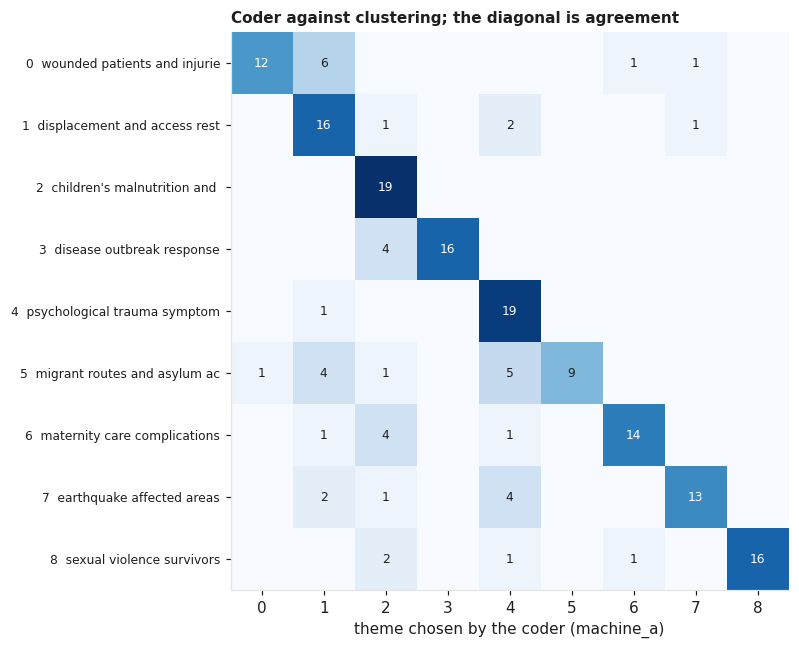


PRACTITIONER NOTE
  Ask whether someone shown only your category names can put an item back where your method put it.
  Withhold your own answer from the form, shuffle the option order, and report the confusion matrix
  and raw agreement beside kappa, since unequal category sizes depress kappa.


In [ ]:
# @title
# ==================================================================================================
# PHASE: VALIDATION                                                     stage 1 of 2 in this phase
# STAGE 20  A SECOND CODER
# WHAT THIS CELL DOES: a second coder assigns passages to themes; agreement is measured with kappa
# ==================================================================================================
# WHAT THIS CELL DOES
#   Tests whether a second coder, shown only a passage and the list of theme names, assigns it to
#   the same theme as the clustering. Computes Cohen's kappa and raw agreement against the
#   clustering, and between coders.
#
# WHY
#   This is a test of the clustering and the naming together: can someone reading only the names
#   put a passage back where the clustering put it. A low agreement means the themes exist in the
#   embedding but not in language, which is a reportable finding about the scheme.
#
# HOW
#   Up to three coders: the instruction model (machine_a), a human via a spreadsheet this cell
#   writes and reads back (human), and comparisons between whichever are available. Only the human
#   comparison is inter-coder reliability in the methods-section sense. Cohen's kappa corrects raw
#   agreement for chance; with unequal theme sizes kappa is depressed relative to raw agreement, so
#   both are reported together with expected agreement. Landis and Koch's bands are printed for
#   orientation only; they are arbitrary benchmarks, not a standard.
#
# REFERENCES
#   Cohen, J. (1960) A coefficient of agreement for nominal scales. Educational and Psychological
#     Measurement 20(1):37-46. DOI 10.1177/001316446002000104
#   Landis, J.R. and Koch, G.G. (1977) The measurement of observer agreement for categorical data.
#     Biometrics 33(1):159-174. DOI 10.2307/2529310

import os, re
import numpy as np, pandas as pd
from sklearn.metrics import cohen_kappa_score, confusion_matrix

heading("STAGE 20  A SECOND CODER")

AGREEMENT_N = min(int(CFG.validation_sample_per_category) * max(1, K_MAIN_OBTAINED), 300)
AGREEMENT_PATH = os.path.join(FIGURE_DIR, "s20_agreement_sample_for_manual_coding.csv")
AGREEMENT_REVIEWED = os.path.join(FIGURE_DIR, "s20_agreement_sample_CODED.csv")

# ---- the sample: stratified, and only passages a coder could reasonably place ----
_eligible = passages.loc[passages["sub_in_scope"] & (~passages["assigned_by_centroid"])] \
    if "sub_in_scope" in passages.columns else passages.loc[~passages["assigned_by_centroid"]]
_per_theme = max(4, AGREEMENT_N // max(1, _eligible["theme_main"].nunique()))
# Sampled by collecting row positions per theme, rather than groupby().apply(), which is not
# consistent across pandas versions in whether it passes the grouping column back.
_picked = []
_local_rng = np.random.default_rng(CFG.seed)
for _value, _block in _eligible.groupby("theme_main"):
    _take = min(len(_block), _per_theme)
    _picked.extend(_local_rng.choice(_block.index.to_numpy(), size=_take, replace=False))
AGREEMENT_SAMPLE = _eligible.loc[sorted(_picked)].reset_index(drop=True)
assert "theme_main" in AGREEMENT_SAMPLE.columns and len(AGREEMENT_SAMPLE), (
    "Agreement sample is empty or missing its theme column.")
print(f"  sample                : {len(AGREEMENT_SAMPLE):,} passages, "
      f"up to {_per_theme} per theme")
print(f"  themes offered        : {K_MAIN_OBTAINED}")
print(f"  seeded with           : {CFG.seed}, so the same passages are drawn on every run")
print(f"  passages excluded     : those assigned by centroid fallback, and those out of scope")

THEME_CHOICES = [(int(value), THEME_NAMES["main"][int(value)])
                 for value in sorted(THEME_NAMES["main"])]

# ---- the file a human codes -------------------------------------------------
os.makedirs(FIGURE_DIR, exist_ok=True)
_human_form = AGREEMENT_SAMPLE[["doc_id", "text_raw" if "text_raw" in AGREEMENT_SAMPLE.columns
                                else "text"]].copy()
_human_form.columns = ["doc_id", "passage"]
_human_form["passage"] = _human_form["passage"].astype(str).str.slice(0, 1200)
_human_form["your_theme_number"] = ""
_human_form.to_csv(AGREEMENT_PATH, index=False)
# Also kept on Drive, since coding this sample outlasts a Colab runtime; both places are checked.
AGREEMENT_PATH_ON_DRIVE = keep_on_drive(AGREEMENT_PATH)
print()
print(f"  A FORM FOR HUMAN CODING HAS BEEN WRITTEN")
print(f"    {AGREEMENT_PATH}")
if AGREEMENT_PATH_ON_DRIVE:
    print(f"    {AGREEMENT_PATH_ON_DRIVE}   (the same form, on Drive)")
print(f"    Put one theme number in 'your_theme_number' for each passage, using this key, save as")
print(f"    's20_agreement_sample_CODED.csv' in the same folder as either copy, and re-run this")
print(f"    cell.")
for value, name in THEME_CHOICES:
    print(f"      {value:>3}  {name}")
print(f"    The clustering's own assignment is deliberately NOT in this file. A coder who can see")
print(f"    the answer is not a second coder.")

# ---- the machine coders -----------------------------------------------------
CODER_SYSTEM_A = (
    f"You assign a passage from {'an' if str(CFG.document_type)[:1].lower() in 'aeiou' else 'a'} "
    f"{CFG.document_type} to one of a list of numbered themes. "
    "Reply with the number alone and nothing else. If none fits well, reply with the closest.")
CODER_SYSTEM_B = (
    "You are a research assistant sorting extracts into categories for a thematic analysis. "
    "Read the extract, decide which single category it belongs to, and answer with that "
    "category's number only.")


def coder_prompt(text, order, wording):
    listed = "\n".join(f"  {value}. {name}" for value, name in order)
    if wording == "a":
        return f"THEMES:\n{listed}\n\nPASSAGE:\n{str(text)[:1100]}\n\nWhich theme number?"
    return (f"Categories available:\n{listed}\n\nExtract:\n{str(text)[:1100]}\n\n"
            f"Which category number does this extract belong to?")


def machine_code(wording):
    """Code every sampled passage. The order of the theme list is shuffled per passage, with a seed,
    so that a model which favours the first or last option cannot score well by doing so."""
    answers, failures = [], 0
    local = np.random.default_rng(CFG.seed + (0 if wording == "a" else 7))
    valid = {value for value, _ in THEME_CHOICES}
    for _, row in AGREEMENT_SAMPLE.iterrows():
        order = [THEME_CHOICES[i] for i in local.permutation(len(THEME_CHOICES))]
        try:
            reply = LLM.generate(CODER_SYSTEM_A if wording == "a" else CODER_SYSTEM_B,
                                 coder_prompt(row["text"], order, wording), max_new_tokens=6)
            found = re.findall(r"-?\d+", reply or "")
            answer = int(found[0]) if found else None
            if answer not in valid:
                answer, failures = None, failures + 1
        except Exception:                                # noqa: BLE001 - counted, not hidden
            answer, failures = None, failures + 1
        answers.append(answer)
    return {"answers": answers, "failures": failures}


# Only one machine coder is used: a second wording would measure whether the assignment survives
# rewording, not inter-coder reliability, since both prompts share one model's systematic misreads.
CODERS = {}
if CFG.llm_enable and LLM.available:
    for wording in ("a",):
        CODERS[f"machine_{wording}"] = cached(
            f"agreement_machine_{wording}", lambda w=wording: machine_code(w),
            inputs=[CORPUS_TEXT_FINGERPRINT, LABEL_FINGERPRINT, tuple(THEME_CHOICES),
                    tuple(AGREEMENT_SAMPLE["passage_id"] if "passage_id" in AGREEMENT_SAMPLE
                          else AGREEMENT_SAMPLE.index),
                    CODER_SYSTEM_A, CODER_SYSTEM_B, wording, CFG.llm_model, CFG.seed],
            note=f"machine coding, wording {wording}, {len(AGREEMENT_SAMPLE)} passages")
else:
    print()
    print(f"  THE INSTRUCTION MODEL IS NOT AVAILABLE, so no machine coding was produced.")
    print(f"  Without a coded file either, reproducibility by a second coder is untested.")

_coded_places = [AGREEMENT_REVIEWED]
if AGREEMENT_PATH_ON_DRIVE:
    _coded_places.append(os.path.join(os.path.dirname(AGREEMENT_PATH_ON_DRIVE),
                                      os.path.basename(AGREEMENT_REVIEWED)))
AGREEMENT_REVIEWED = next((p for p in _coded_places if os.path.exists(p)), AGREEMENT_REVIEWED)
if os.path.exists(AGREEMENT_REVIEWED):
    _coded = pd.read_csv(AGREEMENT_REVIEWED)
    if len(_coded) == len(AGREEMENT_SAMPLE) and "your_theme_number" in _coded.columns:
        CODERS["human"] = {"answers": pd.to_numeric(_coded["your_theme_number"],
                                                    errors="coerce").tolist(), "failures": 0}
        print()
        print(f"  HUMAN CODING FOUND: {AGREEMENT_REVIEWED}")
    else:
        print()
        print(f"  A coded file exists but does not match the sample ({len(_coded)} rows against "
              f"{len(AGREEMENT_SAMPLE)}).")
        print(f"  It is IGNORED, not aligned by position, to avoid a false agreement figure.")

# ---- compare each coder with the clustering, and with each other ------------
REFERENCE = AGREEMENT_SAMPLE["theme_main"].astype(int).to_numpy()


def bands(kappa):
    """The conventional bands of Landis and Koch (1977), printed for orientation only. Their paper
    presents them as arbitrary divisions rather than as a standard, and they are widely repeated as
    though they were one."""
    if not np.isfinite(kappa):
        return "not computable"
    for floor, label in ((0.81, "almost perfect"), (0.61, "substantial"), (0.41, "moderate"),
                         (0.21, "fair"), (0.0, "slight"), (-1.0, "worse than chance")):
        if kappa >= floor:
            return label
    return "worse than chance"


def compare(left, right, left_name, right_name):
    pairs = [(a, b) for a, b in zip(left, right)
             if a is not None and b is not None
             and not (isinstance(a, float) and np.isnan(a))
             and not (isinstance(b, float) and np.isnan(b))]
    if len(pairs) < 10:
        return {"left": left_name, "right": right_name, "n": len(pairs),
                "observed": float("nan"), "expected": float("nan"), "kappa": float("nan")}
    a = np.array([int(p[0]) for p in pairs])
    b = np.array([int(p[1]) for p in pairs])
    observed = float((a == b).mean())
    labels = sorted(set(a) | set(b))
    counts_a = np.array([(a == v).mean() for v in labels])
    counts_b = np.array([(b == v).mean() for v in labels])
    expected = float((counts_a * counts_b).sum())
    return {"left": left_name, "right": right_name, "n": len(pairs), "observed": observed,
            "expected": expected, "kappa": float(cohen_kappa_score(a, b, labels=labels))}


AGREEMENT = []
for name, record in CODERS.items():
    AGREEMENT.append(compare(REFERENCE, record["answers"], "consensus clustering", name))
_names = list(CODERS)
for i in range(len(_names)):
    for j in range(i + 1, len(_names)):
        AGREEMENT.append(compare(CODERS[_names[i]]["answers"], CODERS[_names[j]]["answers"],
                                 _names[i], _names[j]))
AGREEMENT = pd.DataFrame(AGREEMENT)

print()
if not len(AGREEMENT):
    KAPPA_AGAINST_CLUSTERING = float("nan")
    HAS_HUMAN_AGREEMENT = False
    print(f"  NO AGREEMENT STATISTIC WAS COMPUTED.")
    print(f"  No coder was available. The limitations section must state that the scheme has not")
    print(f"  been tested for reproducibility by a second coder.")
else:
    print(f"  AGREEMENT")
    print(f"    {'compared':<44}  {'n':>5}  {'observed':>8}  {'expected':>8}  {'kappa':>6}  band")
    for _, row in AGREEMENT.iterrows():
        pair = f"{row['left']} vs {row['right']}"
        print(f"    {pair[:44]:<44}  {int(row['n']):>5}  "
              f"{row['observed']:>7.1%}  {row['expected']:>7.1%}  {row['kappa']:>6.3f}  "
              f"{bands(row['kappa'])}")
    _against = AGREEMENT[AGREEMENT["left"] == "consensus clustering"]
    KAPPA_AGAINST_CLUSTERING = float(_against["kappa"].max()) if len(_against) else float("nan")
    HAS_HUMAN_AGREEMENT = bool((AGREEMENT[["left", "right"]] == "human").any().any())

    print()
    print(f"  WHAT THESE FIGURES MAY BE CALLED")
    if HAS_HUMAN_AGREEMENT:
        print(f"    The rows involving 'human' are inter-coder agreement in the sense a methods")
        print(f"    section means, between one human coder and the clustering.")
    else:
        print(f"    NONE of these is inter-coder reliability: every coder is the same model under")
        print(f"    a different wording, so this measures reproducibility under rewording, not a")
        print(f"    second opinion. The limitations must say human inter-coder reliability was")
        print(f"    not established. Code the form above to change that.")
    for name, record in CODERS.items():
        if record.get("failures"):
            print(f"    {name}: {record['failures']} passage(s) produced no usable answer and are")
            print(f"      excluded from the figures above rather than counted as disagreement.")

# ---- which themes get confused with which ----------------------------------
_primary = next((name for name in ("human", "machine_a", "machine_b") if name in CODERS), None)
if _primary:
    answers = CODERS[_primary]["answers"]
    keep = [i for i, v in enumerate(answers)
            if v is not None and not (isinstance(v, float) and np.isnan(v))]
    if len(keep) >= 10:
        labels = sorted(THEME_NAMES["main"])
        matrix = confusion_matrix(REFERENCE[keep], [int(answers[i]) for i in keep], labels=labels)
        print()
        print(f"  WHERE {_primary.upper()} DISAGREED WITH THE CLUSTERING")
        print(f"    rows are the clustering's theme, columns are the coder's choice")
        print(f"    {'':>22}" + "".join(f"{v:>5}" for v in labels))
        for position, value in enumerate(labels):
            name = str(THEME_NAMES["main"].get(value, ""))[:20]
            print(f"    {value:>2} {name:<19}" + "".join(f"{c:>5}" for c in matrix[position]))
        _per_theme_recall = []
        for position, value in enumerate(labels):
            total = matrix[position].sum()
            _per_theme_recall.append({
                "theme_main": value, "name": THEME_NAMES["main"].get(value, ""),
                "coded": int(total),
                "agreed": int(matrix[position, position]),
                "agreement": float(matrix[position, position] / total) if total else float("nan"),
                "most_confused_with": int(labels[int(np.argsort(-matrix[position])[1])])
                if total and len(labels) > 1 else -1})
        AGREEMENT_PER_THEME = pd.DataFrame(_per_theme_recall)
        print()
        print(f"    {'theme':>5}  {'coded':>6}  {'agreed':>7}  {'rate':>6}  {'confused':>8}  name")
        for _, row in AGREEMENT_PER_THEME.sort_values("agreement").iterrows():
            print(f"    {int(row['theme_main']):>5}  {int(row['coded']):>6}  "
                  f"{int(row['agreed']):>7}  {row['agreement']:>5.0%}  "
                  f"{int(row['most_confused_with']):>13}  {str(row['name'])[:30]}")
        _worst = AGREEMENT_PER_THEME.nsmallest(1, "agreement")
        if len(_worst) and _worst.iloc[0]["agreement"] < 0.5:
            row = _worst.iloc[0]
            print()
            print(f"    Theme {int(row['theme_main'])} was placed elsewhere more often than not,")
            print(f"    most often in theme {int(row['most_confused_with'])}. Either its name does")
            print(f"    not describe it, or the two themes are not distinguishable from the text.")
    else:
        AGREEMENT_PER_THEME = pd.DataFrame()
else:
    AGREEMENT_PER_THEME = pd.DataFrame()

# ---- figure: where the coder agreed with the clustering -------------------------------------
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7.5, 6))
if len(AGREEMENT_PER_THEME):
    _share = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
    ax.imshow(_share, cmap=SEQUENTIAL, vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if matrix[i, j]:
                ax.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=8,
                        color="white" if _share[i, j] > 0.5 else INK)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels([f"{v}  {str(THEME_NAMES['main'].get(v, ''))[:28]}" for v in labels],
                       fontsize=8)
    ax.set_xlabel(f"theme chosen by the coder ({_primary})")
    ax.set_title("Coder against clustering; the diagonal is agreement", fontsize=10, loc="left")
    ax.grid(False)
else:
    _counts = AGREEMENT_SAMPLE["theme_main"].value_counts().sort_index()
    ax.bar(_counts.index.astype(str), _counts.values, color=PALETTE[0])
    ax.set_xlabel("theme")
    ax.set_ylabel("passages in the coding sample")
    ax.set_title("The coding sample, by theme (no coder yet)", fontsize=10, loc="left")
fig.tight_layout()
save_figure(fig, "s20_agreement")
plt.show()

rule()

report("agreement.sample_size", len(AGREEMENT_SAMPLE), "passages", "Stage 20")
report("agreement.coders", len(CODERS), "coders", "Stage 20")
report("agreement.kappa_against_clustering", round(KAPPA_AGAINST_CLUSTERING, 4)
       if np.isfinite(KAPPA_AGAINST_CLUSTERING) else float("nan"), "Cohen kappa", "Stage 20")
report("agreement.human_coding_present", int(HAS_HUMAN_AGREEMENT), "0 or 1", "Stage 20")

practitioner_note("Agreement on a scheme you built", """
Ask whether someone shown only your category names can put an item back where your method put it.
Withhold your own answer from the form, shuffle the option order, and report the confusion matrix
and raw agreement beside kappa, since unequal category sizes depress kappa.
""")

## Stage 21: self-test on known data   [phase: validation]

**What.** The same procedure (UMAP, sub-themes, themes) on three synthetic sets with a planted
hierarchy of 4 themes x 3 sub-themes: **clean**, **overlapping** and **null** (no groups at all).

**Why.** A clustering method finds clusters in noise. The null case shows what the procedure produces
from nothing; the clean case shows it recovers structure that is there. The real corpus is placed
between them.

  STAGE 21  SELF-TEST ON KNOWN DATA
  synthetic sets        : 1,200 items, 64 dimensions, 4 themes x 3 sub-themes planted (34 s)
  clean case recovered  : sub-themes ARI 0.976, themes ARI 1.000  ->  PASSES

case                   null  overlapping   clean  this corpus
sub_themes_found      8.000       10.000  13.000       15.000
themes_found          7.000        4.000   4.000        9.000
held_aside            0.807        0.708   0.065        0.518
silhouette_sub        0.019        0.051   0.871        0.138
seed_agreement        0.086        0.718   0.976        0.734
recovered_sub_themes    NaN        0.613   0.976          NaN
recovered_themes        NaN        0.991   1.000          NaN

  WHERE THIS CORPUS SITS (0 = no structure, 1 = clear structure)
    silhouette_sub   0.14
    seed_agreement   0.73
    held_aside       0.39
    mean             0.42: close to the null; the clusters are not established
  figure saved: s21_self_test (PNG, SVG, 16x9; local and Drive)


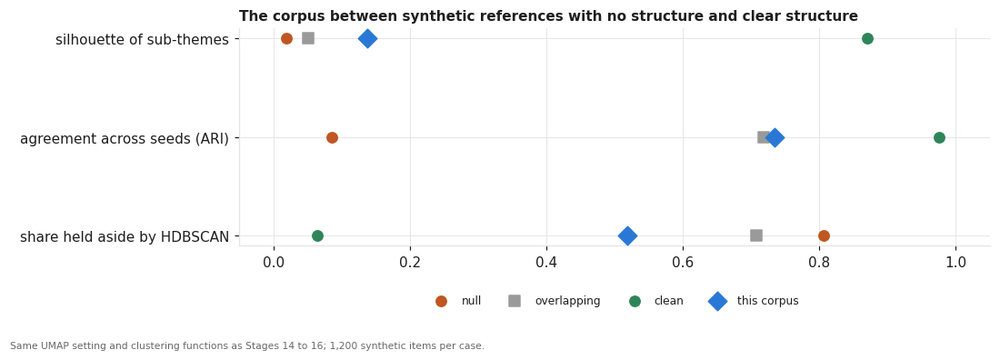


PRACTITIONER NOTE
  Run the whole procedure on data with no structure and on data with clear structure, and print the
  real figures between them. The null run shows how much of a result the method produces by itself.


In [ ]:
# @title
# ==================================================================================================
# PHASE: VALIDATION                                                     stage 2 of 2 in this phase
# STAGE 21  SELF-TEST ON KNOWN DATA
# WHAT THIS CELL DOES: runs the same clustering on data with known structure and with none
# ==================================================================================================
# WHAT THIS CELL DOES
#   Runs the same clustering procedure (UMAP, sub-themes, themes) on synthetic data whose answer is
#   known, and places the real corpus between a "no structure" and a "clear structure" reference.
#
# WHY
#   Every clustering number above lacks a scale: is a silhouette of 0.05 good? A method also returns
#   clusters from data that hold none. The null case shows what the procedure produces from
#   nothing; the clean case shows that it finds structure that is there.
#
# HOW
#   Three synthetic sets with a planted two-level hierarchy (4 themes x 3 sub-themes): CLEAN (well
#   separated), OVERLAPPING (heavily mixed) and NULL (one cloud, no groups). Each is projected with
#   the UMAP setting of notebook 1 on two seeds and clustered with the library functions that
#   Stages 14 to 16 use. Recovery is the adjusted Rand index against the planted groups (Hubert and
#   Arabie 1985). Comparing with a null reference follows the logic of the gap statistic
#   (Tibshirani, Walther and Hastie 2001).
#
# REFERENCES
#   Hubert, L. and Arabie, P. (1985) Comparing partitions. Journal of Classification 2(1):193-218.
#   Tibshirani, R., Walther, G. and Hastie, T. (2001) Estimating the number of clusters in a data
#     set via the gap statistic. Journal of the Royal Statistical Society B 63(2):411-423.

import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, silhouette_score

heading("STAGE 21  SELF-TEST ON KNOWN DATA")

SELF_TEST_N = int(min(1200, max(400, N_PASSAGES // 3)))
SELF_TEST_DIMS, SELF_TEST_TOP, SELF_TEST_PER = 64, 4, 3
SELF_TEST_MIN_SIZE = max(5, int(round(MIN_SUBTHEME_SIZE * SELF_TEST_N / N_PASSAGES)))
SPREAD = {"clean": 0.35, "overlapping": 5.0}


def synthetic(kind, seed):
    """Unit vectors with a planted hierarchy. Returns (vectors, sub-theme truth, theme truth)."""
    rng = np.random.default_rng(seed)
    if kind == "null":
        vectors = rng.normal(size=(SELF_TEST_N, SELF_TEST_DIMS))
        sub = np.zeros(SELF_TEST_N, dtype=int)
    else:
        top = rng.normal(size=(SELF_TEST_TOP, SELF_TEST_DIMS)) * 3.0
        centres = (np.repeat(top, SELF_TEST_PER, axis=0)
                   + rng.normal(size=(SELF_TEST_TOP * SELF_TEST_PER, SELF_TEST_DIMS)) * 1.5)
        sub = rng.integers(0, len(centres), size=SELF_TEST_N)
        vectors = centres[sub] + rng.normal(scale=SPREAD[kind], size=(SELF_TEST_N, SELF_TEST_DIMS))
    vectors = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
    return vectors.astype(np.float32), sub, sub // SELF_TEST_PER


def run_case(kind, seed):
    vectors, sub_truth, top_truth = synthetic(kind, seed)
    runs = []
    for s in (int(CFG.seed), int(CFG.seed) + 1):
        z = project(BEST_UMAP, seed=s, source=vectors)
        raw, _ = find_subthemes(z, METHOD, SELF_TEST_MIN_SIZE, CFG.ward_k_range)
        runs.append((raw, attach_noise(vectors, raw)[0]))
    raw, full = runs[0]
    found = len(np.unique(raw[raw >= 0]))
    grouping, _, _ = build_themes(vectors, full, CFG.theme_k_range) if found else ({}, None, {})
    main = np.array([grouping.get(int(v), 0) for v in full])
    planted = kind != "null"
    return {
        "case": kind,
        "sub_themes_found": float(found),
        "themes_found": float(len(set(grouping.values()))),
        "held_aside": float((raw < 0).mean()),
        "silhouette_sub": (float(silhouette_score(vectors, full, metric="cosine"))
                           if len(np.unique(full)) > 1 else float("nan")),
        "seed_agreement": float(adjusted_rand_score(runs[0][1], runs[1][1])),
        "recovered_sub_themes": (float(adjusted_rand_score(sub_truth, full)) if planted
                                 else float("nan")),
        "recovered_themes": (float(adjusted_rand_score(top_truth, main)) if planted
                             else float("nan")),
    }


_t0 = time.perf_counter()
SELF_TEST = pd.DataFrame([run_case(kind, int(CFG.seed) + 100 * (i + 1))
                          for i, kind in enumerate(("clean", "overlapping", "null"))]
                         ).set_index("case")
print(f"  synthetic sets        : {SELF_TEST_N:,} items, {SELF_TEST_DIMS} dimensions, "
      f"{SELF_TEST_TOP} themes x {SELF_TEST_PER} sub-themes planted "
      f"({time.perf_counter() - _t0:.0f} s)")

# ---- does the procedure recover planted structure? ------------------------------------------
_clean = SELF_TEST.loc["clean"]
MACHINERY_SOUND = bool(_clean["recovered_sub_themes"] >= 0.90
                       and _clean["recovered_themes"] >= 0.90)
print(f"  clean case recovered  : sub-themes ARI {_clean['recovered_sub_themes']:.3f}, themes ARI "
      f"{_clean['recovered_themes']:.3f}  ->  {'PASSES' if MACHINERY_SOUND else 'FAILS'}")
if not MACHINERY_SOUND:
    print("    The procedure missed planted, well-separated groups. Do not report the clusters "
          "until this is understood.")

# ---- the calibration table ----------------------------------------------------------------
REAL = {"sub_themes_found": float(K_SUB_OBTAINED), "themes_found": float(K_MAIN_OBTAINED),
        "held_aside": float(ASSIGNED_BY_CENTROID.mean()),
        "silhouette_sub": float(passages["silhouette_sub"].mean()),
        "seed_agreement": float(SUBTHEME_SEED_AGREEMENT),
        "recovered_sub_themes": float("nan"), "recovered_themes": float("nan")}
CALIBRATION = SELF_TEST.T
CALIBRATION["this corpus"] = pd.Series(REAL)
CALIBRATION = CALIBRATION[["null", "overlapping", "clean", "this corpus"]]
print()
print(CALIBRATION.round(3).to_string())


def position(key):
    """Where the corpus sits on a scale from the null case (0) to the clean case (1)."""
    null_value, clean_value, actual = (CALIBRATION.loc[key, c]
                                       for c in ("null", "clean", "this corpus"))
    if not np.all(np.isfinite([null_value, clean_value, actual])) or null_value == clean_value:
        return float("nan")
    return float(np.clip((actual - null_value) / (clean_value - null_value), -0.5, 1.5))


VERDICTS = pd.DataFrame([{"measure": key, "position": position(key)}
                         for key in ("silhouette_sub", "seed_agreement", "held_aside")])
_mean_position = float(VERDICTS["position"].mean())
print()
print("  WHERE THIS CORPUS SITS (0 = no structure, 1 = clear structure)")
for _, row in VERDICTS.iterrows():
    print(f"    {row['measure']:<16} {row['position']:.2f}")
print(f"    mean             {_mean_position:.2f}: "
      + ("clearly structured" if _mean_position >= 0.8 else
         "partly structured; report the weaker clusters with their scores"
         if _mean_position >= 0.45 else "close to the null; the clusters are not established"))

# ---- figure: the corpus between the references ----------------------------------------------
_measures = [("silhouette_sub", "silhouette of sub-themes"),
             ("seed_agreement", "agreement across seeds (ARI)"),
             ("held_aside", "share held aside by HDBSCAN")]
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (key, label) in enumerate(_measures):
    for case, colour, marker in (("null", WARN, "o"), ("overlapping", OTHER, "s"),
                                 ("clean", GOOD, "o"), ("this corpus", PALETTE[0], "D")):
        value = CALIBRATION.loc[key, case]
        if np.isfinite(value):
            ax.scatter(value, i, s=90 if case == "this corpus" else 55, color=colour,
                       marker=marker, zorder=3, label=case if i == 0 else None)
ax.set_yticks(range(len(_measures)))
ax.set_yticklabels([label for _, label in _measures])
ax.set_xlim(-0.05, 1.05)
ax.invert_yaxis()
ax.legend(fontsize=8, frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.set_title("The corpus between synthetic references with no structure and clear structure",
             fontsize=10, loc="left")
fig.tight_layout()
add_reference_footer(fig, f"Same UMAP setting and clustering functions as Stages 14 to 16; "
                          f"{SELF_TEST_N:,} synthetic items per case.")
save_figure(fig, "s21_self_test", slide_ready=True)
plt.show()
rule()

report("self_test.clean_recovery_sub", round(float(_clean["recovered_sub_themes"]), 4),
       "adjusted Rand", "Stage 21")
report("self_test.clean_recovery_themes", round(float(_clean["recovered_themes"]), 4),
       "adjusted Rand", "Stage 21")
report("self_test.null_held_aside", round(float(SELF_TEST.loc["null", "held_aside"]), 4),
       "share", "Stage 21")
report("self_test.position_of_this_corpus",
       round(_mean_position, 4) if np.isfinite(_mean_position) else float("nan"),
       "0 null to 1 clean", "Stage 21")
report("self_test.machinery_sound", int(MACHINERY_SOUND), "0 or 1", "Stage 21")

practitioner_note("Giving your numbers a scale", """
Run the whole procedure on data with no structure and on data with clear structure, and print the
real figures between them. The null run shows how much of a result the method produces by itself.
""")

## Stage 22: figures   [phase: output]

Three figures on the themes: size beside coherence, how firmly passages are held, and stability
against coherence. Each carries its caveats in its footer.

  STAGE 22  FIGURES
  figure saved: s22_size_and_coherence (PNG, SVG, 16x9; local and Drive)


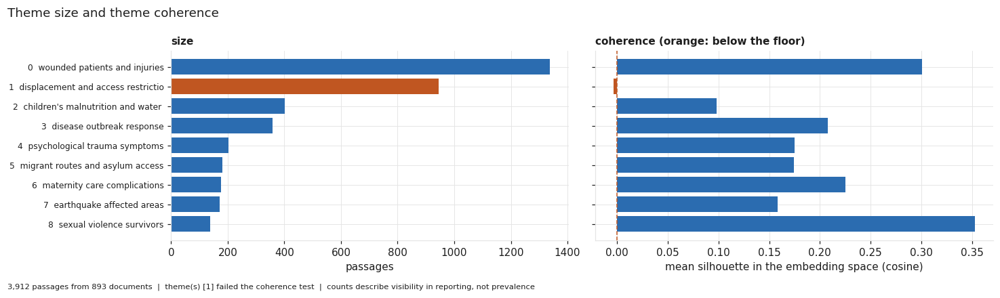

  figure saved: s22_confidence (PNG, SVG, 16x9; local and Drive)


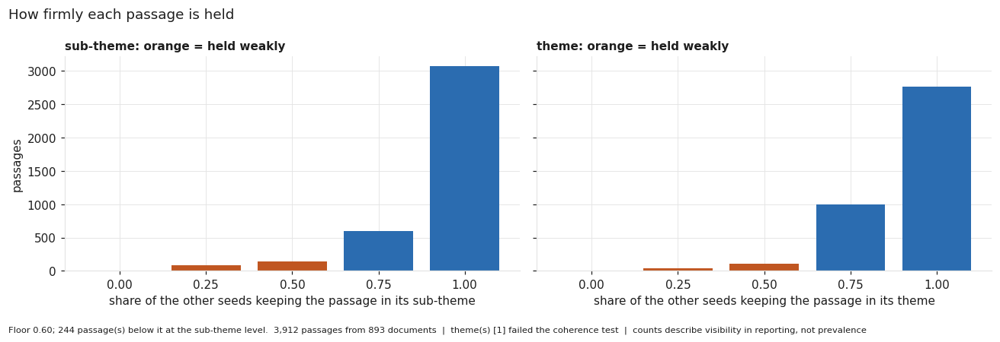

  figure saved: s22_stability_against_coherence (PNG, SVG, 16x9; local and Drive)


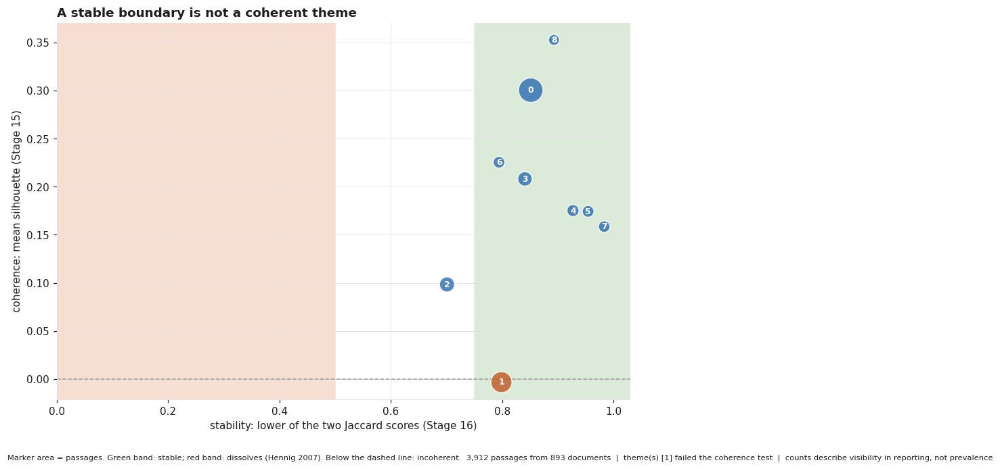

  FIGURES SAVED BY THIS NOTEBOOK: 15, in 13 stage(s)
    Stage 12   s12_analysis_set                     PNG, SVG
    Stage 13   s13_space_before_clustering          PNG, SVG, 16x9
    Stage 14   s14_subthemes                        PNG, SVG, 16x9
    Stage 15   s15_themes                           PNG, SVG, 16x9
    Stage 16   s16_stability                        PNG, SVG, 16x9
    Stage 16b  s16b_second_model                    PNG, SVG
    Stage 17   s17_theme_terms                      PNG, SVG, 16x9
    Stage 18   s18_name_gate                        PNG, SVG
    Stage 19   s19_scope                            PNG, SVG, 16x9
    Stage 19b  s19b_summaries                       PNG, SVG
    Stage 20   s20_agreement                        PNG, SVG
    Stage 21   s21_self_test                        PNG, SVG, 16x9
    Stage 22   s22_size_and_coherence               PNG, SVG, 16x9
    Stage 22   s22_confidence                       PNG, SVG, 16x9
    Stage 22   s22_stability_against_co

In [ ]:
# @title
# ==================================================================================================
# PHASE: OUTPUT                                                         stage 1 of 4 in this phase
# STAGE 22  FIGURES
# WHAT THIS CELL DOES: size, coherence, confidence and stability of the themes in three figures
# ==================================================================================================
# WHAT THIS CELL DOES
#   Three summary figures on the themes, then a list of every figure this notebook saved.
#     1. Size and coherence of each theme, side by side.
#     2. How firmly the passages are held: the share of seeds that keep each passage in place.
#     3. Stability against coherence: a stable boundary is not the same as a coherent theme.
#
# WHY
#   Size alone makes a residue look like a finding. Each figure carries its caveats in its footer,
#   so a figure pasted into another document keeps them.

import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

heading("STAGE 22  FIGURES")


def _caveat_line():
    parts = [f"{len(passages):,} passages from {passages['doc_id'].nunique():,} documents"]
    if INCOHERENT_THEMES:
        parts.append(f"theme(s) {sorted(INCOHERENT_THEMES)} failed the coherence test")
    if PARTITION_DOMINATED:
        parts.append(f"largest theme holds {LARGEST_SHARE:.0%}")
    parts.append("counts describe visibility in reporting, not prevalence")
    return "  |  ".join(parts)


def _label(theme):
    return f"{int(theme)}  {str(THEME_NAMES['main'].get(int(theme), ''))[:34]}"


# ---- 1. size and coherence -------------------------------------------------------------------
_table = CONSENSUS_MAIN_TABLE.sort_values("passages").reset_index(drop=True)
_colours = [WARN if int(t) in INCOHERENT_THEMES else NEUTRAL for t in _table["theme_main"]]
fig, axes = plt.subplots(1, 2, figsize=(13.5, max(3.6, 0.42 * len(_table))), sharey=True)
positions = np.arange(len(_table))
axes[0].barh(positions, _table["passages"], color=_colours)
axes[0].set_yticks(positions)
axes[0].set_yticklabels([_label(t) for t in _table["theme_main"]], fontsize=8)
axes[0].set_xlabel("passages")
axes[0].set_title("size", fontsize=10, loc="left")
axes[1].barh(positions, _table["coherence"], color=_colours)
axes[1].axvline(float(CFG.coherence_floor), color=WARN, linestyle="--", linewidth=1)
axes[1].set_xlabel("mean silhouette in the embedding space (cosine)")
axes[1].set_title("coherence (orange: below the floor)", fontsize=10, loc="left")
fig.suptitle("Theme size and theme coherence", fontsize=12, x=0.01, ha="left")
fig.text(0.01, -0.02, _caveat_line(), fontsize=7.5, color=INK, ha="left")
fig.tight_layout()
save_figure(fig, "s22_size_and_coherence", slide_ready=True)
plt.show()

# ---- 2. how firmly is each passage held? -----------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, column, level in ((axes[0], "confidence_sub", "sub-theme"),
                          (axes[1], "confidence_main", "theme")):
    counts = passages[column].round(2).value_counts().sort_index()
    ax.bar([f"{v:.2f}" for v in counts.index], counts.values,
           color=[WARN if v < float(CFG.confidence_floor) else NEUTRAL for v in counts.index])
    ax.set_xlabel(f"share of the other seeds keeping the passage in its {level}")
    ax.set_title(f"{level}: orange = held weakly", fontsize=10, loc="left")
axes[0].set_ylabel("passages")
fig.suptitle("How firmly each passage is held", fontsize=12, x=0.01, ha="left")
fig.text(0.01, -0.04, f"Floor {float(CFG.confidence_floor):.2f}; "
                      f"{int(passages['low_confidence'].sum()):,} passage(s) below it at the "
                      f"sub-theme level.  " + _caveat_line(), fontsize=7.5, ha="left")
fig.tight_layout()
save_figure(fig, "s22_confidence", slide_ready=True)
plt.show()

# ---- 3. stability against coherence ----------------------------------------------------------
_plot = STABILITY.copy()
_plot["stability"] = _plot[["jaccard_seeds", "jaccard_passages"]].min(axis=1)
fig, ax = plt.subplots(figsize=(8.6, 6.0))
ax.axvspan(0, float(CFG.unstable_cluster_floor), color="#f6ded3", zorder=0)
ax.axvspan(float(CFG.stability_jaccard_min), 1.03, color="#dcebd9", zorder=0)
ax.axhline(float(CFG.coherence_floor), color="#999999", linestyle="--", linewidth=1)
_sizes = 60 + 500 * (_plot["passages"] / _plot["passages"].max())
ax.scatter(_plot["stability"], _plot["coherence"], s=_sizes, alpha=0.8, edgecolor="white",
           color=[WARN if int(t) in INCOHERENT_THEMES | UNSTABLE_THEMES else NEUTRAL
                  for t in _plot["theme_main"]], zorder=3)
for _, row in _plot.iterrows():
    ax.annotate(str(int(row["theme_main"])), xy=(row["stability"], row["coherence"]),
                fontsize=8, ha="center", va="center", color="white", weight="bold", zorder=4)
ax.set_xlim(0, 1.03)
ax.set_xlabel("stability: lower of the two Jaccard scores (Stage 16)")
ax.set_ylabel("coherence: mean silhouette (Stage 15)")
ax.set_title("A stable boundary is not a coherent theme", fontsize=12, loc="left")
fig.text(0.01, -0.04, "Marker area = passages. Green band: stable; red band: dissolves (Hennig "
                      "2007). Below the dashed line: incoherent.  " + _caveat_line(),
         fontsize=7.5, ha="left")
fig.tight_layout()
save_figure(fig, "s22_stability_against_coherence", slide_ready=True)
plt.show()

# ---- every figure this notebook saved, by stage -----------------------------------------------
_OWN = {r.get("name", "?"): r for r in FIGURE_LEDGER if r.get("run_id") == RUN_ID}
_BY_STAGE = {}
for name, record in _OWN.items():
    _BY_STAGE.setdefault(name.split("_", 1)[0].lstrip("s") or "?", []).append(record)
print(f"  FIGURES SAVED BY THIS NOTEBOOK: {len(_OWN)}, in {len(_BY_STAGE)} stage(s)")
for stage_id in sorted(_BY_STAGE, key=lambda v: (len(v.rstrip("abcdefgh")), v)):
    for record in _BY_STAGE[stage_id]:
        print(f"    Stage {stage_id:<4} {record['name']:<36} "
              f"{', '.join(record.get('formats', []))}")
print(f"  in this session : {FIGURE_DIR}")
if globals().get("DURABLE_OUTPUT_DIR"):
    print(f"  on Drive        : "
          f"{os.path.join(DURABLE_OUTPUT_DIR, os.path.relpath(FIGURE_DIR, CFG.output_dir))}")
print("  Stage 25 packs every figure and table of both notebooks into one download.")
rule()

report("figures.in_notebook_two", len(_OWN), "figures", "Stage 22")

practitioner_note("Figures that keep their caveats", """
Put the caveat in the figure, not only beside it, and plot stability against coherence: the cluster
that scores well on one and badly on the other is the failure a single-axis chart hides.
""")

## Stage 23: hand over to notebook 3   [phase: output]

Saves the passages with their themes, the names, the health scope and every verdict (incoherent,
unstable, name rejected, summary withheld) in one bundle. Notebook 3 must carry these verdicts into
every table it prints.

  STAGE 23  HAND OVER TO NOTEBOOK 3
  VERDICTS TRAVELLING WITH THE DATA
    subthemes_count                    15
    subthemes_method                   hdbscan
    subtheme_min_size                  40
    themes_count                       9
    themes_chosen_by                   largest jump in fusion height
    subthemes_incoherent               none
    subthemes_language_artefact        none
    themes_incoherent                  [1]
    themes_unstable                    none
    subthemes_unstable                 none
    subthemes_model_dependent          [0, 1, 3, 6, 7, 9, 12, 13, 14]
    themes_model_dependent             [3, 5, 6]
    second_model_checked               True
    human_sample_coded                 False
    summaries_not_supported            0
    scope_rule_separates               False
    themes_weakly_held                 [1]
    themes_reportable_plainly          [0, 2, 3, 4, 5, 6, 7, 8]
    names_rejected                     none
    partition_dominated

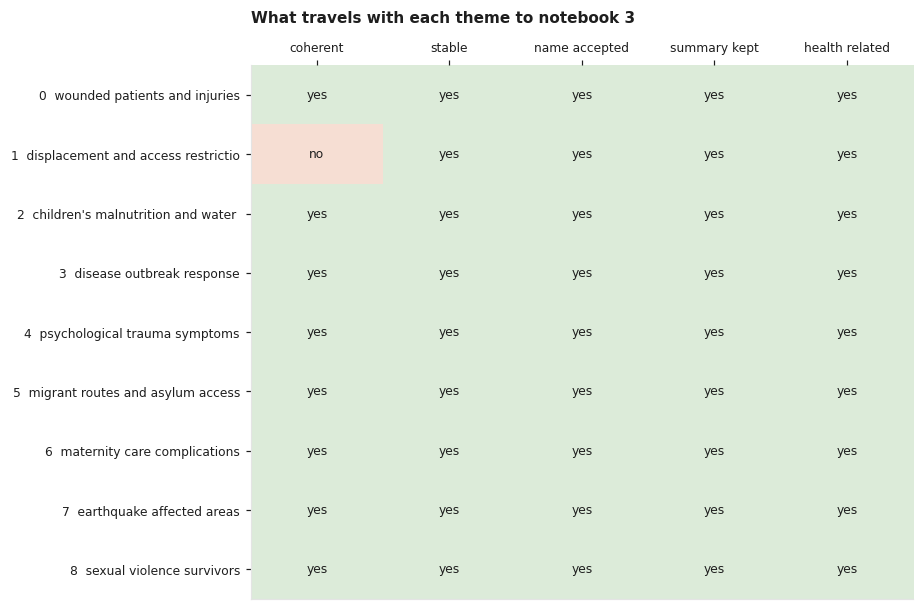


PRACTITIONER NOTE
  Send the verdicts with the data. A stage that receives only counts will produce a clean table from
  clusters you declined to endorse. A failed coherence test or a rejected name belongs in the object
  the next stage loads, so it cannot be left behind by accident.


In [ ]:
# @title
# ==================================================================================================
# PHASE: OUTPUT                                                         stage 2 of 4 in this phase
# STAGE 23  HAND OVER TO NOTEBOOK 3
# WHAT THIS CELL DOES: saves themes, names, scope and every verdict for notebook 3
# ==================================================================================================
# WHAT THIS CELL DOES
#   Writes the handoff bundle notebook 3 reads: passages, themes, names, scope decisions, and the
#   verdicts this notebook reached about what may be reported. Written before the dashboard, so a
#   display error cannot cost the handoff.
#
# WHY
#   Notebook 3 must not present a theme that failed its coherence test, or a rejected name, as
#   though it were sound; the verdicts travel with the data so that cannot happen. The embedding
#   is not copied, since notebook 3 needs only counts and labels; its filename lets a later figure
#   be traced back to it.

import os
import numpy as np, pandas as pd

heading("STAGE 23  HAND OVER TO NOTEBOOK 3")

REQUIRED_FOR_NB3 = {
    "__namespace__": globals(),
    "passages":           "the passage table, with theme, confidence and scope columns",
    "df_analysis":        "the document table",
    "THEME_NAMES":        "the gated names, at both levels",
    "GATE":               "which names were accepted, and why the others were not",
    "CONSENSUS_MAIN_TABLE": "size, coherence and confidence per theme",
    "SUBTHEME_TABLE":     "size, coherence and confidence per sub-theme",
    "THEME_OF_SUBTHEME":  "which theme each sub-theme belongs to",
    "HEALTH_SET":         "the health-related sub-themes, named, with their counts",
    "STABILITY":          "the two stability scores and the verdict per theme",
    "REPORTABLE":         "which themes may be reported plainly",
    "SUB_SCOPE":          "the scope decision per sub-theme",
    "SCOPE_ALTERNATIVES": "what the analysis looks like at other thresholds",
    "ANALYSED":           "the in-scope passages",
    "AGREEMENT":          "whether a second coder reproduced the assignment",
    "SELF_TEST":          "what this machinery reports on data with no themes in it",
    "CALIBRATION":        "the real figures beside the synthetic references",
    "SUMMARIES":          "the cluster summaries at all three levels, with the gate's verdict",
    "PASSAGE_SUMMARIES":  "the one-sentence summary of each quoted passage",
    "NUMBER_REGISTER":    "every number reported so far",
    "CORPUS_LEDGER":      "the reconciliation from raw rows to the analysed set",
}

_verdicts = {
    "subthemes_count": int(K_SUB_OBTAINED),
    "subthemes_method": str(METHOD),
    "subtheme_min_size": int(MIN_SUBTHEME_SIZE),
    "themes_count": int(K_MAIN_OBTAINED),
    "themes_chosen_by": str(THEMES_CHOSEN_BY),
    "subthemes_incoherent": sorted(INCOHERENT_SUBTHEMES),
    "subthemes_language_artefact": sorted(LANGUAGE_ARTEFACT_SUBTHEMES),
    "themes_incoherent": sorted(INCOHERENT_THEMES),
    "themes_unstable": sorted(UNSTABLE_THEMES),
    "subthemes_unstable": sorted(UNSTABLE_SUBTHEMES),
    "subthemes_model_dependent": sorted(globals().get("SUBTHEMES_MODEL_DEPENDENT", set())),
    "themes_model_dependent": sorted(globals().get("THEMES_MODEL_DEPENDENT", set())),
    "second_model_checked": globals().get("SECOND_MODEL_SUMMARY") is not None,
    "human_sample_coded": bool((HANDOFF.get("human_sample") or {}).get("coded_file")),
    "summaries_not_supported": int((globals().get("GROUNDING_SUMMARY") or {}).get(
        "clusters_not_supported", 0)),
    "scope_rule_separates": bool(globals().get("SCOPE_DISCRIMINATES", True)),
    "themes_weakly_held": sorted(WEAK_THEMES),
    "themes_reportable_plainly": sorted(
        int(v) for v in REPORTABLE.loc[REPORTABLE["report_without_caveat"], "theme_main"]),
    "names_rejected": sorted(int(v) for v in GATE.loc[~GATE["accepted"] & (GATE["level"] == "main"),
                                                      "theme"]),
    "partition_dominated": bool(PARTITION_DOMINATED),
    "largest_theme_share": round(float(LARGEST_SHARE), 4),
    "theme_silhouette": round(float(SILHOUETTE_MAIN), 4),
    "subtheme_seed_agreement": round(float(SUBTHEME_SEED_AGREEMENT), 4),
    "theme_seed_agreement": round(float(THEME_SEED_AGREEMENT), 4),
    "theme_bootstrap_ari": round(float(PASSAGE_BOOTSTRAP_ARI), 4),
    "held_aside_share": round(float(ASSIGNED_BY_CENTROID.mean()), 4),
    "machinery_sound": bool(MACHINERY_SOUND),
    "position_between_null_and_clean": (round(float(_mean_position), 4)
                                        if np.isfinite(_mean_position) else None),
    "lexicon_precision_measured": bool(PRECISION_TABLE is not None and len(PRECISION_TABLE)),
    "lexicon_precision_source": str(PRECISION_SOURCE),
    "human_coding_present": bool(HAS_HUMAN_AGREEMENT),
    "kappa_against_clustering": (round(float(KAPPA_AGAINST_CLUSTERING), 4)
                                 if np.isfinite(KAPPA_AGAINST_CLUSTERING) else None),
    "scope_worst_rank_correlation": (round(float(SCOPE_WORST_CORRELATION), 4)
                                     if np.isfinite(SCOPE_WORST_CORRELATION) else None),
    # A withheld summary is a verdict, not an absence: notebook 3 must know which clusters
    # have none.
    "summaries_written": int((SUMMARIES["verdict"] == "kept").sum()) if len(SUMMARIES) else 0,
    "summaries_withheld": sorted(
        f"{row['level']}:{row['theme']}"
        for _, row in SUMMARIES.iterrows() if row["verdict"] != "kept") if len(SUMMARIES) else [],
    "passage_summaries_written": int(len(PASSAGE_SUMMARIES)),
    "passage_summary_scope": str(globals().get("PASSAGE_SUMMARY_SCOPE",
                                              CFG.summary_passage_scope)),
}

print(f"  VERDICTS TRAVELLING WITH THE DATA")
for key, value in _verdicts.items():
    shown = value if not isinstance(value, list) else (value or "none")
    print(f"    {key:<34} {shown}")

PAYLOAD = {
    "produced_by": "notebook 2, stages 12 to 23",
    "passages": passages,
    "df_analysis": df_analysis,
    "analysed": ANALYSED,
    "theme_names": THEME_NAMES,
    "name_sources": NAME_SOURCES,
    "name_gate": GATE,
    "name_checks": NAME_CHECKS,
    "distinctive_terms": TERMS,
    "consensus_main_table": CONSENSUS_MAIN_TABLE,
    "subtheme_table": SUBTHEME_TABLE,
    "subtheme_sensitivity": SENSITIVITY,     # sub-themes found at other minimum sizes
    "theme_jumps": THEME_JUMPS,              # fusion-height jump per candidate number of themes
    "theme_of_subtheme": THEME_OF_SUBTHEME,  # the nesting, as a plain mapping
    "language_table": LANGUAGE_TABLE,
    "subthemes_method": METHOD,
    "themes_chosen_by": THEMES_CHOSEN_BY,
    "seeds": SEEDS,
    "subtheme_seed_ari": SEED_ARI,
    "theme_seed_ari": THEME_SEED_ARI,
    # Health-related set as its own object, with names and counts, so notebook 3 need not
    # re-derive it.
    "health_set": HEALTH_SET,
    "health_subthemes": HEALTH_SUBTHEMES,
    "health_themes": HEALTH_THEMES,
    "stability": STABILITY,
    "subtheme_stability": SUBTHEME_STABILITY,
    "reportable": REPORTABLE,
    "sub_scope": SUB_SCOPE,
    "main_scope": MAIN_SCOPE,
    "scope_alternatives": SCOPE_ALTERNATIVES,
    "in_scope_sub_themes": sorted(IN_SCOPE_SUB),
    "agreement": AGREEMENT,
    "agreement_per_theme": AGREEMENT_PER_THEME,
    "self_test": SELF_TEST,
    "calibration": CALIBRATION,
    "verdicts": _verdicts,
    "second_model": globals().get("SECOND_MODEL_SUMMARY"),     # Stage 16b
    "human_sample": HANDOFF.get("human_sample"),              # notebook 1, Stage 7c
    "grounding": globals().get("GROUNDING_SUMMARY"),           # Stage 19c
    "k_main_obtained": int(K_MAIN_OBTAINED),
    "k_sub_obtained": int(K_SUB_OBTAINED),
    "embedding_record": HANDOFF["embedding_record"],
    "chosen_model": CHOSEN_MODEL,
    "best_umap": tuple(BEST_UMAP),
    "capabilities": CAPABILITIES,
    "groups": GROUPS,
    "group_labels": GROUP_LABELS,
    "group_noun": CFG.group_noun,
    "categories": CATEGORIES,
    "codebook": CODEBOOK,
    "short_labels": SHORT_LABELS,
    "barrier_subtypes": BARRIER_SUBTYPES,
    "canonical": CANONICAL,
    "cat_cols": CAT_COLS,
    "bar_cols": BAR_COLS,
    "n_patterns": int(N_PATTERNS),
    "weak_categories": sorted(WEAK_CATEGORIES),
    "precision_table": PRECISION_TABLE,
    "precision_source": PRECISION_SOURCE,
    "group_main": GROUP_MAIN,
    "group_all": GROUP_ALL,
    "group_n": GROUP_N,
    "corpus_ledger": CORPUS_LEDGER,
    "cleaning_ledger": CLEANING_LEDGER,
    "number_register": NUMBER_REGISTER,
    "figure_ledger": FIGURE_LEDGER,
    "practitioner_notes": PRACTITIONER_NOTES,
    "environment_nb1": ENVIRONMENT_NB1,
    "environment_nb2": ENVIRONMENT,
}

RESULT = write_handoff("nb2_to_nb3", PAYLOAD, REQUIRED_FOR_NB3, CORPUS_TEXT_FINGERPRINT)
print_handoff(RESULT, extra_lines=[
    "the embedding is NOT inside; notebook 3 needs counts and labels, not vectors",
    f"notebook 3 will check the corpus fingerprint {CORPUS_TEXT_FINGERPRINT} and the upstream",
    f"  settings, and will stop if either differs",
])

print()
print(f"  WHAT NOTEBOOK 3 MUST CARRY INTO EVERY TABLE IT PRINTS")
_carry = []
if _verdicts["partition_dominated"]:
    _carry += [f"The partition is dominated by one theme at "
               f"{_verdicts['largest_theme_share']:.0%}. A table of theme shares is then mostly a "
               f"statement about that theme."]
if _verdicts["themes_incoherent"]:
    _carry += [f"Theme(s) {_verdicts['themes_incoherent']} failed the coherence test (Stage 15): "
               f"mark them wherever they appear, including inside any total."]
if _verdicts["themes_unstable"] or _verdicts["subthemes_unstable"]:
    _carry += [f"Theme(s) {_verdicts['themes_unstable']} and sub-theme(s) "
               f"{_verdicts['subthemes_unstable']} dissolve under resampling (Jaccard <= "
               f"{CFG.unstable_cluster_floor}, Stage 16): report them as tentative, not as "
               f"findings."]
if _verdicts["subthemes_model_dependent"]:
    _carry += [f"Sub-theme(s) {_verdicts['subthemes_model_dependent']} did not come back with a "
               f"second embedding model (Stage 16b): report them as tentative."]
elif not _verdicts["second_model_checked"]:
    _carry += ["No second embedding model was compared (Stage 16b): every cluster rests on one "
               "model."]
if _verdicts["summaries_not_supported"]:
    _carry += [f"{_verdicts['summaries_not_supported']} cluster summary(ies) are not supported by "
               f"their passages (Stage 19c): quote the passages, not those summaries."]
if not _verdicts["human_sample_coded"]:
    _carry += ["The random human sample of notebook 1 (Stage 7c) is not coded: lexicon counts are "
               "uncorrected and their recall is unknown."]
if _verdicts["subthemes_language_artefact"]:
    _carry += [f"Sub-theme(s) {_verdicts['subthemes_language_artefact']} are held by one language "
               f"(Stage 14): they may group passages by language, not by subject. A comparison "
               f"across {plural(CFG.group_noun)} that use different languages is confounded there."]
if _verdicts["names_rejected"]:
    _carry += [f"Name(s) of theme(s) {_verdicts['names_rejected']} were rejected and replaced by "
               f"term lists, which describe vocabulary, not content."]
if not _verdicts["scope_rule_separates"]:
    _carry += ["The scope rule separates no sub-theme on this corpus: 'in scope' is the whole "
               "corpus, and the scope tables add nothing to the theme tables."]
if _verdicts["human_sample_coded"]:
    pass            # precision and recall were measured on the random human sample (Stage 7c)
elif not _verdicts["lexicon_precision_measured"]:
    _carry += ["The lexicon's precision is UNMEASURED: no category may be called validated."]
elif not str(_verdicts["lexicon_precision_source"]).startswith("human"):
    _carry += ["The lexicon's precision is PROVISIONAL (machine judge only, Stage 7): a human "
               "review of the Stage 7 sample is needed before a category is called validated."]
if not _verdicts["human_coding_present"]:
    _carry += ["No human coder has tested the scheme: claim machine reproducibility under "
               "rewording (Stage 20), not inter-coder reliability."]
if _carry:
    import textwrap as _textwrap
    for number, line in enumerate(_carry, start=1):
        wrapped = _textwrap.wrap(line, width=OUTPUT_WIDTH - 10)
        print(f"    {number}. {wrapped[0]}")
        for rest in wrapped[1:]:
            print(f"       {rest}")
else:
    print(f"    Nothing beyond the usual framing: the themes describe visibility in reporting.")

# ---- figure: the report card each theme carries into notebook 3 ------------------------------
import matplotlib.pyplot as plt
_kept = (set(SUMMARIES.loc[(SUMMARIES["level"] == "main") & (SUMMARIES["verdict"] == "kept"),
                           "theme"].astype(int)) if len(SUMMARIES) else set())
_card = pd.DataFrame({
    "coherent": [t not in INCOHERENT_THEMES for t in range(K_MAIN_OBTAINED)],
    "stable": [t not in UNSTABLE_THEMES for t in range(K_MAIN_OBTAINED)],
    "name accepted": [bool(NAME_ACCEPTED["main"].get(t, False)) for t in range(K_MAIN_OBTAINED)],
    "summary kept": [t in _kept for t in range(K_MAIN_OBTAINED)],
    f"{CFG.subject_name} related": [t in set(HEALTH_THEMES) for t in range(K_MAIN_OBTAINED)]})
fig, ax = plt.subplots(figsize=(8.5, 0.45 * K_MAIN_OBTAINED + 1.6))
from matplotlib.colors import ListedColormap
ax.imshow(_card.to_numpy(dtype=float), cmap=ListedColormap(["#f6ded3", "#dcebd9"]), vmin=0, vmax=1,
          aspect="auto")
for i in range(_card.shape[0]):
    for j in range(_card.shape[1]):
        ax.text(j, i, "yes" if _card.iat[i, j] else "no", ha="center", va="center", fontsize=8)
ax.set_xticks(range(_card.shape[1]))
ax.set_xticklabels(_card.columns, fontsize=8)
ax.xaxis.tick_top()
ax.set_yticks(range(K_MAIN_OBTAINED))
ax.set_yticklabels([f"{t}  {str(THEME_NAMES['main'].get(t, ''))[:34]}"
                    for t in range(K_MAIN_OBTAINED)], fontsize=8)
ax.grid(False)
ax.set_title("What travels with each theme to notebook 3", fontsize=10, loc="left", pad=28)
fig.tight_layout()
save_figure(fig, "s23_report_card", slide_ready=True)
plt.show()

rule()

report("handoff_nb3.bytes", RESULT["bytes"], "bytes", "Stage 23")
report("handoff_nb3.themes", int(K_MAIN_OBTAINED), "themes", "Stage 23")
report("handoff_nb3.passages_in_scope", len(ANALYSED), "passages", "Stage 23")

practitioner_note("Passing on a judgement", """
Send the verdicts with the data. A stage that receives only counts will produce a clean table from
clusters you declined to endorse. A failed coherence test or a rejected name belongs in the object
the next stage loads, so it cannot be left behind by accident.
""")

## Stage 24: interactive dashboard   [phase: output]

One HTML page with every cluster's record: name and where it came from, summary, measures, visibility
by country, distinctive words and passages. It computes nothing; every number comes from the cells
above. Open it in a browser (it is saved on Drive and included in the download).

| Where | What |
|---|---|
| pointer on a point | that passage: its own one-sentence summary, its key sentence (copied verbatim), its country, date, language and title, and how firmly it is held |
| click a point | the whole passage opens on the right, with a link to its source |
| Themes, Sub-themes, Health (keys 1, 2, 3) | the level shown |
| Map, Hierarchy, Scope (keys m, h, s) | the centre view |
| click a cluster, arrow keys | its full record on the right |
| mouse wheel, drag, double-click | zoom, pan, reset the map |
| p | pin a cluster; pinned clusters export as CSV |

In [ ]:
# @title
# ==================================================================================================
# PHASE: OUTPUT                                                         stage 3 of 4 in this phase
# STAGE 24  INTERACTIVE DASHBOARD
# WHAT THIS CELL DOES: one interactive page with every cluster's name, summary and evidence
# ==================================================================================================
# WHAT THIS CELL DOES
#   Builds a self-contained interactive HTML dashboard. Each cluster (theme, sub-theme, or subject
#   sub-theme) gets one screen: its name, summary, coherence, stability, terms, quotes and country
#   profile. Each point on the map is one passage: the pointer on it shows its own summary, its key
#   sentence (verbatim), its source and how firmly it is held; a click opens the whole passage.
#   Added views: the theme/sub-theme hierarchy and the scope threshold.
#
# WHY
#   A cluster's record is spread across many earlier stages. This cell assembles it without
#   computing anything new, so the dashboard cannot disagree with the notebook: every number is
#   read from an earlier stage's own output, by name, from its number register. Flags, refused
#   names and withheld summaries are shown, not hidden. Every count describes VISIBILITY IN PUBLIC
#   REPORTING, what agencies chose to write about, never prevalence, burden or severity.
#
# HOW
#   Cluster, passage and register data are assembled into a JSON payload and embedded in a static
#   HTML/JS template. The one derived number is per-country document counts, divided by that
#   country's own document total to give a comparable share.

# The four settings of this cell are in Stage 1 with every other setting, classified downstream:
# nothing that produces the passages, the vectors or the clusters reads them.
DASHBOARD_QUOTES_PER_CLUSTER = int(CFG.dashboard_quotes_per_cluster)
DASHBOARD_POINT_LIMIT        = int(CFG.dashboard_point_limit)
DASHBOARD_TEXT_CHARS         = int(CFG.dashboard_text_chars)
DASHBOARD_FILENAME           = CFG.output("dashboard")

import os, re, json, html, math, datetime
import numpy as np, pandas as pd


def _cfg(name, default=None):
    """A setting from the control panel, or a default. A missing setting leaves one number blank
    rather than stopping the cell."""
    return getattr(globals().get("CFG"), name, default) if "CFG" in globals() else default


def _need(name):
    if name not in globals():
        raise RuntimeError(f"'{name}' is not defined. Run the notebook from Stage 0 to Stage 23 "
                           f"first; this cell recomputes nothing.")
    return globals()[name]


passages          = _need("passages")
SUMMARIES         = _need("SUMMARIES")
TERMS             = _need("TERMS")
THEME_NAMES       = _need("THEME_NAMES")
SUBTHEME_TABLE    = _need("SUBTHEME_TABLE")
MAIN_TABLE        = _need("CONSENSUS_MAIN_TABLE")
THEME_OF_SUBTHEME = _need("THEME_OF_SUBTHEME")
HEALTH_SUBS       = set(int(v) for v in _need("HEALTH_SUBTHEMES"))
COORDS            = np.asarray(_need("PROJECTION_2D"))[:, :2]
STABILITY         = globals().get("STABILITY")
GATE              = globals().get("GATE")
NAME_SOURCES      = globals().get("NAME_SOURCES", {})
PASSAGE_SUMMARIES = globals().get("PASSAGE_SUMMARIES")
SCOPE_ALTERNATIVES = globals().get("SCOPE_ALTERNATIVES")
CALIBRATION       = globals().get("CALIBRATION")
REGISTER          = globals().get("NUMBER_REGISTER", [])
FIGURE_DIR        = globals().get("FIGURE_DIR", ".")
os.makedirs(FIGURE_DIR, exist_ok=True)

assert len(COORDS) == len(passages), (
    f"PROJECTION_2D has {len(COORDS)} rows, passages has {len(passages)}; rows must align 1:1.")

# GROUP_COL is the renamed column; CFG.column("group") gives the raw file name instead.
try:
    GROUP_COL = group_column(passages)
except Exception:
    GROUP_COL = "group" if "group" in passages.columns else None
GROUP_NOUN = str(_cfg("group_noun", "group"))


def _number(value, places=3):
    try:
        number = float(value)
    except (TypeError, ValueError):
        return None
    return None if not math.isfinite(number) else round(number, places)


_REGISTER_NAMES = {str(row.get("name")) for row in REGISTER}
_ASKED_FOR = []


def _reported(name):
    """A number the notebook itself registered, by name, so the dashboard cannot disagree with the
    notebook's own results.

    An unregistered name and a value registered as NaN both return None here, but they are not the
    same: the first is a mistake in this cell, the second a measurement the notebook could not make.
    The name is recorded in _ASKED_FOR so the difference can be checked below."""
    _ASKED_FOR.append(name)
    for row in reversed(REGISTER):
        if row.get("name") == name:
            return _number(row.get("value"), 4)
    return None


# ---- what each cluster is, gathered once ------------------------------------
_SUMMARY_LOOKUP, _PASSAGE_SUMMARY, _GATE, _STAB = {}, {}, {}, {}
if SUMMARIES is not None and len(SUMMARIES):
    for _, row in SUMMARIES.iterrows():
        _SUMMARY_LOOKUP[(str(row["level"]), int(row["theme"]))] = {
            "summary": str(row.get("summary", "") or ""),
            "verdict": str(row.get("verdict", "") or ""),
            "reason": str(row.get("reason", "") or ""),
            "grounding": _number(row.get("grounding"), 2),
            "weakest": str(row.get("weakest_sentence", "") or "")}
if PASSAGE_SUMMARIES is not None and len(PASSAGE_SUMMARIES):
    for _, row in PASSAGE_SUMMARIES.iterrows():
        _PASSAGE_SUMMARY[int(row["passage"])] = str(row["summary"])
# Reads the gate's own column names: it writes "failed", not "reason", and "proposed" holds the
# model's suggested name, the one an analyst most needs to see for a refusal.
if GATE is not None and len(GATE):
    for _, row in GATE.iterrows():
        def _g(column, default=""):
            value = row.get(column, default) if hasattr(row, "get") else default
            return default if value is None or (isinstance(value, float) and math.isnan(value)) \
                else value
        _GATE[(str(row["level"]), int(row["theme"]))] = {
            "accepted": bool(_g("accepted", True)),
            "failed": str(_g("failed")), "kinds": str(_g("kinds")),
            "proposed": str(_g("proposed")), "final": str(_g("final_name")),
            "first": str(_g("first_proposal")), "first_failed": str(_g("first_failed")),
            "retried": bool(_g("retried", False)), "source": str(_g("source")),
            "lexical": str(_g("lexical"))}
if STABILITY is not None and len(STABILITY):
    for _, row in STABILITY.iterrows():
        _STAB[int(row["theme_main"])] = {
            "jaccard_seeds": _number(row.get("jaccard_seeds")),
            "jaccard_passages": _number(row.get("jaccard_passages")),
            "unstable": bool(row.get("unstable", False)),
            "safe_to_report": bool(row.get("safe_to_report", True))}

# ---- the country profile ----------------------------------------------------
# The document count is not comparable across countries, since document totals differ; the share of
# a country's own documents is, and the bar is drawn from the share. This describes visibility in
# what was published, not how common the subject is in that country.
DOCS_PER_GROUP = {}
COUNTRY_PROFILE = {}
if GROUP_COL and "doc_id" in passages.columns:
    DOCS_PER_GROUP = {str(g): int(n) for g, n in
                      passages.groupby(GROUP_COL)["doc_id"].nunique().items()}
    for level, column in (("main", "theme_main"), ("sub", "theme_sub")):
        counts = (passages.groupby([column, GROUP_COL])["doc_id"].nunique()
                  .reset_index(name="documents"))
        for value, block in counts.groupby(column):
            rows = []
            for _, row in block.iterrows():
                group = str(row[GROUP_COL])
                total = DOCS_PER_GROUP.get(group, 0)
                rows.append({"group": group, "documents": int(row["documents"]),
                             "of_group": round(int(row["documents"]) / total, 4) if total else None})
            rows.sort(key=lambda r: -(r["of_group"] or 0))
            COUNTRY_PROFILE[(level, int(value))] = rows


def _text_of(index):
    for column in ("text_raw", "text"):
        if column in passages.columns:
            body = " ".join(str(passages.at[index, column]).split())
            if len(body) > DASHBOARD_TEXT_CHARS:
                body = body[:DASHBOARD_TEXT_CHARS].rsplit(" ", 1)[0] + " ..."
            return body
    return ""


def _meta_of(index):
    out = {}
    for label, column in (("document", "doc_id"), ("title", "title"), ("date", "date"),
                          ("language", "doc_language"), ("type", "doc_type")):
        if column in passages.columns:
            value = passages.at[index, column]
            if pd.notna(value):
                out[label] = str(value)[:120]
    if GROUP_COL and GROUP_COL in passages.columns:
        value = passages.at[index, GROUP_COL]
        if pd.notna(value):
            out[GROUP_NOUN] = str(value)
    return out


def _quotes_for(label_column, confidence_column, value):
    """The most firmly held and most typical passages in this cluster, the same rule Stage 17 used
    to pick what it sent for naming. Each is shown with the summary Stage 19b wrote for it."""
    block = passages.loc[passages[label_column] == value]
    typical = "silhouette_" + label_column.split("_", 1)[1]
    if confidence_column in block.columns and typical in block.columns:
        block = block.sort_values([confidence_column, typical], ascending=False, na_position="last")
    elif confidence_column in block.columns:
        block = block.sort_values(confidence_column, ascending=False, na_position="last")
    out = []
    for index, _ in block.head(DASHBOARD_QUOTES_PER_CLUSTER * 2).iterrows():
        body = _text_of(index)
        if len(body.split()) < 12:
            continue
        confidence = None
        if confidence_column in passages.columns and pd.notna(passages.at[index,
                                                                          confidence_column]):
            confidence = round(float(passages.at[index, confidence_column]), 3)
        out.append({"summary": _PASSAGE_SUMMARY.get(int(index), ""), "text": body,
                    "meta": _meta_of(index), "confidence": confidence})
        if len(out) >= DASHBOARD_QUOTES_PER_CLUSTER:
            break
    return out


def _terms_for(level, value):
    return [{"term": str(r["term"]), "lift": float(r.get("lift", 0) or 0),
             "count": int(r.get("count", 0) or 0)}
            for r in TERMS.get(level, {}).get(value, [])][:14]


CLUSTERS = []


def _record(level, value, name, size, share, documents, coherence, confidence,
            flags, label_column, confidence_column, extra):
    base = "sub" if level == "health" else level
    summary = _SUMMARY_LOOKUP.get((level, value), {})
    gate = _GATE.get((base, value), {})
    CLUSTERS.append({
        "key": f"{level}-{value}", "level": level, "id": value, "name": name,
        "size": int(size), "share": _number(share, 4), "documents": int(documents),
        "coherence": _number(coherence), "confidence": _number(confidence),
        "name_source": gate.get("source") or str(NAME_SOURCES.get(base, {}).get(value, "")),
        "name_accepted": gate.get("accepted", None), "name_reason": gate.get("failed", ""),
        "name_kinds": gate.get("kinds", ""),
        "model_name": gate.get("proposed") or name, "gated_name": gate.get("final") or name,
        "first_name": gate.get("first", ""), "first_failed": gate.get("first_failed", ""),
        "retried": gate.get("retried", False), "lexical": gate.get("lexical", ""),
        "summary": summary.get("summary", ""), "summary_verdict": summary.get("verdict", ""),
        "summary_grounding": summary.get("grounding"),
        "summary_weakest": summary.get("weakest", ""),
        "summary_reason": summary.get("reason", ""),
        "flags": flags, "terms": _terms_for(base, value),
        "countries": COUNTRY_PROFILE.get((base, value), []),
        "quotes": _quotes_for(label_column, confidence_column, value), "extra": extra})


for _, row in MAIN_TABLE.iterrows():
    value = int(row["theme_main"])
    stability = _STAB.get(value, {})
    flags = [f for f, on in (("incoherent", row.get("incoherent")),
                             ("contains a language artefact", row.get("contains_language_artefact")),
                             ("unstable", stability.get("unstable"))) if on]
    _record("main", value, THEME_NAMES.get("main", {}).get(value, f"theme {value}"),
            row["passages"], row["share"], row["documents"], row["coherence"],
            row["confidence_mean"], flags, "theme_main", "confidence_main",
            {"sub_themes": [int(s) for s in row["sub_theme_ids"]],
             "jaccard_seeds": stability.get("jaccard_seeds"),
             "jaccard_passages": stability.get("jaccard_passages"),
             "safe_to_report": stability.get("safe_to_report")})

for _, row in SUBTHEME_TABLE.iterrows():
    value = int(row["theme_sub"])
    parent = int(THEME_OF_SUBTHEME.get(value, -1))
    flags = [f for f, on in (("incoherent", row.get("incoherent")),
                             ("language artefact", row.get("language_artefact")),
                             ("not reproduced by a second model", row.get("model_dependent")))
             if on]
    extra = {"parent": parent, "parent_name": THEME_NAMES.get("main", {}).get(parent, ""),
             "below_floor": int(row.get("below_floor", 0)),
             "centroid_assigned": int(row.get("centroid_assigned", 0)),
             "second_model_jaccard": _number(row.get("second_model_jaccard")),
             "in_health_set": value in HEALTH_SUBS}
    _record("sub", value, THEME_NAMES.get("sub", {}).get(value, f"sub-theme {value}"),
            row["passages"], row["share"], row["documents"], row["coherence"],
            row["confidence_mean"], flags,
            "theme_sub", "confidence_sub", extra)
    if value in HEALTH_SUBS:
        _record("health", value, THEME_NAMES.get("sub", {}).get(value, f"sub-theme {value}"),
                row["passages"], row["share"], row["documents"], row["coherence"],
                row["confidence_mean"], flags, "theme_sub", "confidence_sub", extra)

# ---- the points on the map --------------------------------------------------
_rng = np.random.default_rng(int(_cfg("seed", 42)))
_n = len(passages)
if _n > DASHBOARD_POINT_LIMIT:
    _keep = np.sort(_rng.choice(_n, size=DASHBOARD_POINT_LIMIT, replace=False))
    _sampled = True
else:
    _keep, _sampled = np.arange(_n), False
POINTS = {
    "x": [round(float(v), 3) for v in COORDS[_keep, 0]],
    "y": [round(float(v), 3) for v in COORDS[_keep, 1]],
    "sub": [int(v) for v in passages["theme_sub"].to_numpy()[_keep]],
    "main": [int(v) for v in passages["theme_main"].to_numpy()[_keep]],
    "health": [bool(int(v) in HEALTH_SUBS) for v in passages["theme_sub"].to_numpy()[_keep]],
    "weak": ([bool(v) for v in passages["low_confidence"].to_numpy()[_keep]]
             if "low_confidence" in passages.columns else [False] * len(_keep)),
    "sampled": _sampled, "drawn": int(len(_keep)), "total": int(_n)}

# ---- each point's own record, shown when the pointer rests on it -----------------------------
# A point is one passage. Its card shows the passage's own one-sentence summary (Stage 19b, written
# by the model from this passage alone), its KEY SENTENCE (verbatim: the sentence carrying most of
# its sub-theme's distinctive words, Monroe et al. 2008 z-scores), where it comes from, and how
# firmly it is held. The key sentence is copied, never generated, so every card has a check on
# the summary. The passage text is cut so that all texts together stay under TEXT_BUDGET characters.
_SENTENCE_SPLIT = re.compile(r"(?:(?<=[.!?])|(?<=[.!?][\"\u201d\u2019')]))\s+"
                             r"(?=[A-Z\u00c0-\u00dd\"\u201c(0-9])")
_TERM_WEIGHT = {int(value): {str(row["term"]): max(0.0, float(row.get("z", 0) or 0))
                             for row in rows}
                for value, rows in TERMS.get("sub", {}).items()}


def key_sentence(text, sub_value, max_chars=300):
    """The sentence of `text` with the largest summed weight of its sub-theme's distinctive terms,
    each term counted once. With no distinctive term present, the first full sentence."""
    weights = _TERM_WEIGHT.get(int(sub_value), {})
    sentences = [" ".join(x.split()) for x in _SENTENCE_SPLIT.split(str(text)) if x.strip()]
    sentences = [x for x in sentences if len(x.split()) >= 6] or sentences
    if not sentences:
        return ""
    scored = [(sum(weights.get(t, 0.0) for t in set(tokens_of(x))), -k, x)
              for k, x in enumerate(sentences)]
    best = max(scored)[2] if max(scored)[0] > 0 else sentences[0]
    return best if len(best) <= max_chars else best[:max_chars].rsplit(" ", 1)[0] + " ..."


TEXT_BUDGET = 3_500_000
_chars = int(min(DASHBOARD_TEXT_CHARS, max(200, TEXT_BUDGET // max(1, len(_keep)))))
_raw_column = "text_raw" if "text_raw" in passages.columns else "text"
_label_column = "group_label" if "group_label" in passages.columns else GROUP_COL
def _passage_column(name):
    if PASSAGE_SUMMARIES is None or not len(PASSAGE_SUMMARIES) or name not in PASSAGE_SUMMARIES:
        return {}
    return dict(zip(PASSAGE_SUMMARIES["passage"].astype(int), PASSAGE_SUMMARIES[name]))


_support = _passage_column("word_support")
_grounding = _passage_column("grounding")
GROUNDING_CUT = float(_cfg("grounding_threshold", 0.5))
DOCS, _doc_index = [], {}
_card = {"doc": [], "sum": [], "key": [], "txt": [], "conf": [], "held": [], "low": [],
         "grd": []}
for index in passages.index[_keep]:
    doc_id = str(passages.at[index, "doc_id"])
    if doc_id not in _doc_index:
        def _field(column, limit=140):
            if column and column in passages.columns and pd.notna(passages.at[index, column]):
                return str(passages.at[index, column])[:limit]
            return ""
        _group = _field(_label_column) or _field(GROUP_COL)
        _doc_index[doc_id] = len(DOCS)
        DOCS.append({"t": _field("title"), "g": _group, "d": _field("date", 10),
                     "l": _field("doc_language", 8), "k": _field("doc_type", 40),
                     "u": doc_id[:200]})
    raw = " ".join(str(passages.at[index, _raw_column]).split())
    _card["doc"].append(_doc_index[doc_id])
    _card["sum"].append(_PASSAGE_SUMMARY.get(int(index), ""))
    _card["key"].append(key_sentence(raw, passages.at[index, "theme_sub"]))
    _card["txt"].append(raw if len(raw) <= _chars else raw[:_chars].rsplit(" ", 1)[0] + " ...")
    _card["conf"].append(_number(passages.at[index, "confidence_sub"], 2)
                         if "confidence_sub" in passages.columns else None)
    _card["held"].append(bool(passages.at[index, "assigned_by_centroid"])
                         if "assigned_by_centroid" in passages.columns else False)
    _value = _support.get(int(index))
    _card["low"].append(bool(_value is not None and pd.notna(_value) and _value < 0.5))
    _card["grd"].append(_number(_grounding.get(int(index)), 2))
POINTS.update(_card)
POINTS["text_chars"] = _chars

# ---- how far to trust any of it ---------------------------------------------
# Four numbers from the notebook's register, each with its floor, answering "should these themes
# be believed at all" before any individual cluster is shown.
TRUST = [
    {"label": "position between no themes and clean themes",
     "value": _reported("self_test.position_of_this_corpus"),
     "floor": 0.50, "higher_is_better": True,
     "note": "0 means this corpus behaves like data with no themes in it, 1 like data with clean "
             "ones. Measured by running the same machinery on both references."},
    {"label": "theme agreement under resampling", "value": _reported("stability.passage_bootstrap_ari"),
     "floor": _number(_cfg("stability_jaccard_min", 0.75)),
     "higher_is_better": True,
     "note": "adjusted Rand between the themes and the themes found again on 80% of the passages."},
    {"label": "second coder against the clustering",
     "value": _reported("agreement.kappa_against_clustering"),
     "floor": 0.60, "higher_is_better": True,
     "note": "Cohen's kappa. Absent until the coding form in Stage 20 is filled in."},
    {"label": "summaries kept", "value": (
        _number((SUMMARIES["verdict"] == "kept").mean()) if (
            SUMMARIES is not None and len(SUMMARIES)) else None),
     "floor": None, "higher_is_better": True,
     "note": "the rest were withheld because they made a claim this corpus cannot support, or "
             "named a place the masking removed."},
]

_UNKNOWN = [n for n in _ASKED_FOR if n not in _REGISTER_NAMES]
assert not _UNKNOWN, f"Not in the number register: {_UNKNOWN}. Fix the name(s) asked for above."

SCOPE_ROWS = []
if SCOPE_ALTERNATIVES is not None and len(SCOPE_ALTERNATIVES):
    for _, row in SCOPE_ALTERNATIVES.iterrows():
        SCOPE_ROWS.append({k: (_number(row[k], 4) if isinstance(row[k], (int, float, np.floating))
                               else str(row[k]))
                           for k in SCOPE_ALTERNATIVES.columns if k != "ranking"})

CALIBRATION_ROWS = []
if CALIBRATION is not None and len(CALIBRATION):
    for name, row in CALIBRATION.iterrows():
        CALIBRATION_ROWS.append({"measure": str(name),
                                 **{str(c): _number(row[c], 4) for c in CALIBRATION.columns}})

HEADER = {
    "built": datetime.datetime.now().strftime("%Y-%m-%d %H:%M"),
    "run_id": str(globals().get("RUN_ID", "")),
    "corpus": str(globals().get("CORPUS_TEXT_FINGERPRINT", "")),
    "passages": int(_n),
    "documents": int(passages["doc_id"].nunique()) if "doc_id" in passages.columns else 0,
    "themes": int(len(MAIN_TABLE)), "subthemes": int(len(SUBTHEME_TABLE)),
    "health_subthemes": len(HEALTH_SUBS),
    "subject": str(_cfg("subject_name", "subject")),
    "summaries_written": int((SUMMARIES["verdict"] == "kept").sum()) if (
        SUMMARIES is not None and len(SUMMARIES)) else 0,
    "summaries_total": int(len(SUMMARIES)) if SUMMARIES is not None else 0,
    "passage_summaries": len(_PASSAGE_SUMMARY),
    "group_noun": GROUP_NOUN, "group_plural": plural(GROUP_NOUN, 2),
    "groups": DOCS_PER_GROUP,
    "projection": str(globals().get("BEST_UMAP", "")),
    "scope_threshold": _number(_cfg("scope_share_floor"), 2),
    "grounding_threshold": GROUNDING_CUT}

PAYLOAD = json.dumps({"header": HEADER, "clusters": CLUSTERS, "points": POINTS, "docs": DOCS,
                      "trust": TRUST, "scope": SCOPE_ROWS, "calibration": CALIBRATION_ROWS},
                     ensure_ascii=True, allow_nan=False)

TEMPLATE = r"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Themes, names and summaries</title>
<style>
:root{--bg:#ffffff;--panel:#f6f7f9;--sunk:#eceff3;--line:#dde2e8;--ink:#161a1f;--soft:#5b6572;
  --faint:#8a939e;--warn:#b0470f;--warnbg:#fdf0e8;--good:#1d6b3b;--goodbg:#e8f4ec;--accent:#2d5f8f;
  --halo:rgba(255,255,255,.92);--shadow:0 1px 2px rgba(16,24,40,.06),0 2px 6px rgba(16,24,40,.06);
  --r:6px;--list:292px;--detail:430px}
@media (prefers-color-scheme:dark){:root:not([data-theme="light"]){
  --bg:#12151a;--panel:#181c22;--sunk:#21262e;--line:#2b313a;--ink:#e8ebef;--soft:#9ea8b4;
  --faint:#6f7985;--warn:#eaa373;--warnbg:#2b211b;--good:#86cc9f;--goodbg:#18271e;--accent:#8ab4de;
  --halo:rgba(10,12,15,.9);--shadow:0 1px 3px rgba(0,0,0,.4)}}
*{box-sizing:border-box}
html,body{height:100%;margin:0}
body{background:var(--bg);color:var(--ink);display:flex;flex-direction:column;overflow:hidden;
  font:13.5px/1.5 -apple-system,BlinkMacSystemFont,"Segoe UI",Roboto,Helvetica,Arial,sans-serif;
  -webkit-font-smoothing:antialiased}
button{font:inherit;color:inherit;cursor:pointer}
/* ---------- the slim bar: facts that do not change sit in one line ---------- */
.bar{display:flex;align-items:center;gap:14px;padding:7px 14px;border-bottom:1px solid var(--line);
  background:var(--panel);flex:0 0 auto;flex-wrap:wrap}
.brand{font-weight:650;font-size:14px;white-space:nowrap}
.facts{font-size:12px;color:var(--soft);white-space:nowrap;overflow:hidden;text-overflow:ellipsis;
  min-width:0;flex:1 1 260px}
.facts b{color:var(--ink);font-weight:600}
.chips{display:flex;gap:6px;flex-wrap:wrap}
.chip{display:inline-flex;align-items:center;gap:6px;padding:3px 9px;border-radius:12px;
  border:1px solid var(--line);background:var(--bg);font-size:11.5px;white-space:nowrap}
.chip .dot{width:7px;height:7px;border-radius:50%}
.chip b{font-weight:650}
.btn{border:1px solid var(--line);background:var(--bg);border-radius:var(--r);padding:4px 10px;
  font-size:11.5px;color:var(--soft);white-space:nowrap}
.btn:hover{background:var(--sunk);color:var(--ink)}
.btn.on{background:var(--accent);border-color:var(--accent);color:#fff}
.strip{flex:0 0 auto;padding:4px 14px;font-size:11.5px;color:var(--soft);
  border-bottom:1px solid var(--line);background:var(--bg)}
.strip b{color:var(--warn);font-weight:600}
.drawer{flex:0 0 auto;display:none;padding:12px 14px;border-bottom:1px solid var(--line);
  background:var(--panel);max-height:40vh;overflow:auto}
.drawer.on{display:block}
.tgrid{display:grid;grid-template-columns:repeat(auto-fit,minmax(230px,1fr));gap:10px}
.tcard{background:var(--bg);border:1px solid var(--line);border-radius:var(--r);padding:9px 11px}
.tlab{font-size:11.5px;color:var(--soft)}
.tval{font-size:19px;font-weight:650;margin:2px 0 4px}
.tbar{height:4px;background:var(--sunk);border-radius:3px;position:relative;overflow:hidden}
.tfill{height:100%;border-radius:3px}
.tfloor{position:absolute;top:-2px;width:1px;height:8px;background:var(--ink);opacity:.5}
.tnote{font-size:11px;color:var(--soft);margin-top:5px;line-height:1.45}
/* ---------- three columns; the view in the middle takes what is left ---------- */
/* The single row is pinned to the height that is left, and every column may shrink below its
   content. Without both, a long list made the row as tall as the list, and the map was drawn into a
   stage taller than the frame, with its lower half out of sight. Each column is also placed in its
   own track by name, so hiding the list cannot slide the map into the list's zero-width track. */
.layout{flex:1 1 auto;min-height:0;display:grid;grid-template-rows:minmax(0,1fr);
  grid-template-columns:var(--list) minmax(0,1fr) var(--detail)}
.layout>.left{grid-column:1;min-height:0}.layout>.centre{grid-column:2;min-height:0}
.layout>.right{grid-column:3;min-height:0}
.layout.nolist{grid-template-columns:0 minmax(0,1fr) var(--detail)}
.layout.nodetail{grid-template-columns:var(--list) minmax(0,1fr) 0}
.layout.nolist.nodetail{grid-template-columns:0 minmax(0,1fr) 0}
.layout.nolist .left,.layout.nodetail .right{display:none}
.left{border-right:1px solid var(--line);display:flex;flex-direction:column;min-width:0;
  background:var(--panel)}
.controls{padding:9px 10px 7px;border-bottom:1px solid var(--line)}
.tabs{display:flex;gap:3px;background:var(--sunk);padding:3px;border-radius:var(--r);margin-bottom:7px}
.tab{flex:1;padding:5px 2px;font-size:11.5px;border:0;background:transparent;border-radius:4px;
  color:var(--soft)}
.tab.on{background:var(--bg);color:var(--ink);font-weight:600;box-shadow:var(--shadow)}
.row{display:flex;gap:6px;align-items:center}
input[type=search],select{padding:5px 8px;border:1px solid var(--line);border-radius:var(--r);
  font-size:12px;background:var(--bg);color:var(--ink);min-width:0}
input[type=search]{flex:1}
label.chk{display:inline-flex;align-items:center;gap:5px;margin-top:6px;font-size:11.5px;
  color:var(--soft);cursor:pointer}
.count{font-size:11px;color:var(--faint);margin-top:5px}
.list{overflow-y:auto;flex:1}
.item{padding:7px 10px 7px 12px;border-bottom:1px solid var(--line);cursor:pointer;display:flex;
  gap:8px;align-items:flex-start}
.item:hover{background:var(--sunk)}
.item.on{background:var(--bg);box-shadow:inset 3px 0 0 var(--accent)}
.item.kb{outline:2px solid var(--accent);outline-offset:-2px}
.sw{width:10px;height:10px;border-radius:3px;margin-top:4px;flex:0 0 auto}
.iname{font-weight:600;font-size:12.5px;line-height:1.35;overflow-wrap:anywhere}
.iterm{font-size:11px;color:var(--faint);margin-top:1px;overflow-wrap:anywhere}
.imeta{font-size:11px;color:var(--soft);margin-top:2px}
.tag{display:inline-block;font-size:9.5px;font-weight:600;letter-spacing:.3px;text-transform:uppercase;
  padding:0 5px;border-radius:3px;margin-left:5px;vertical-align:1px}
.tag.warn{background:var(--warnbg);color:var(--warn)}
.tag.info{background:var(--sunk);color:var(--soft)}
.pin{border:0;background:transparent;color:var(--faint);padding:0 2px;margin-left:auto;font-size:12px}
.pin.on{color:var(--accent)}
.centre{display:flex;flex-direction:column;min-width:0;min-height:0}
.toolbar{display:flex;align-items:center;gap:5px;padding:6px 8px;border-bottom:1px solid var(--line);
  background:var(--panel);flex-wrap:wrap;row-gap:5px}
.toolbar .btn{padding:4px 8px}
.seg{display:inline-flex;background:var(--sunk);padding:2px;border-radius:var(--r);gap:2px}
.seg button{border:0;background:transparent;padding:4px 8px;font-size:11.5px;border-radius:4px;
  color:var(--soft)}
.seg button.on{background:var(--bg);color:var(--ink);font-weight:600;box-shadow:var(--shadow)}
.spacer{flex:1}
.tlabel{font-size:11px;color:var(--faint);margin-left:4px}
.stage{position:relative;flex:1 1 auto;min-height:0;background:var(--bg)}
.stage canvas{position:absolute;inset:0;width:100%;height:100%;display:none}
.stage canvas.on{display:block}
#map{cursor:grab}
.scopewrap{position:absolute;inset:0;overflow:auto;padding:14px 18px;display:none}
.scopewrap.on{display:block}
.tip{position:absolute;pointer-events:none;background:#0e1115;color:#eef1f4;font-size:11.5px;
  padding:8px 11px 9px;border-radius:7px;max-width:360px;display:none;z-index:9;line-height:1.45;
  box-shadow:0 6px 18px rgba(0,0,0,.3);border:1px solid #3a424d}
.tip .ts{color:#aeb7c2;margin-top:3px}
.tip .th{display:flex;gap:7px;align-items:flex-start;font-weight:650;font-size:12px}
.tip .sw2{width:9px;height:9px;border-radius:2px;margin-top:4px;flex:0 0 auto}
.tip .lab{font-size:9.5px;letter-spacing:.5px;text-transform:uppercase;color:#8d97a3;margin-top:7px}
.tip .sm{color:#f3f5f7;margin-top:1px}
.tip .ks{color:#d3dae2;font-style:italic;margin-top:1px}
.tip .mt{color:#aeb7c2;margin-top:7px;padding-top:6px;border-top:1px solid #2a3038;font-size:11px}
.tip .fl{color:#f0b58c;font-size:11px;margin-top:3px}
.tip .hint{color:#7f8a96;font-size:10.5px;margin-top:5px}
#hov{pointer-events:none}
.pcard{border:1px solid var(--accent);border-radius:var(--r);padding:10px 12px;margin:0 0 12px;
  background:var(--panel)}
.pchead{display:flex;align-items:center;gap:8px;margin-bottom:2px}
.pchead b{font-size:12.5px}
.pchead .x{margin-left:auto;border:0;background:var(--sunk);border-radius:50%;width:22px;height:22px;
  line-height:20px;padding:0;color:var(--soft)}
.plab{font-size:10px;letter-spacing:.5px;text-transform:uppercase;color:var(--soft);margin-top:8px}
.kq{font-size:12.5px;font-style:italic;line-height:1.55;border-left:3px solid var(--line);
  padding-left:8px;margin-top:2px}
.pflag{font-size:11px;color:var(--warn);margin-top:4px}
.pcard a{color:var(--accent)}
.vnote{position:absolute;left:10px;bottom:9px;font-size:10.5px;color:var(--soft);
  background:var(--bg);padding:2px 8px;border-radius:10px;border:1px solid var(--line)}
.selchip{position:absolute;left:10px;top:10px;display:none;align-items:center;gap:8px;
  background:var(--bg);border:1px solid var(--line);border-radius:14px;padding:4px 6px 4px 10px;
  font-size:12px;box-shadow:var(--shadow);max-width:70%}
.selchip.on{display:inline-flex}
.selchip b{white-space:nowrap;overflow:hidden;text-overflow:ellipsis}
.selchip button{border:0;background:var(--sunk);border-radius:50%;width:20px;height:20px;
  line-height:18px;padding:0;color:var(--soft)}
table.grid{border-collapse:collapse;font-size:12.5px;width:100%}
table.grid th{text-align:left;font-weight:600;font-size:10.5px;text-transform:uppercase;
  letter-spacing:.5px;color:var(--soft);padding:5px 12px 5px 0;border-bottom:1px solid var(--line)}
table.grid td{padding:5px 12px 5px 0;border-bottom:1px solid var(--line);vertical-align:top}
tr.here td{background:var(--sunk);font-weight:600}
/* ---------- the detail panel ---------- */
.right{border-left:1px solid var(--line);overflow-y:auto;min-width:0}
.detail{padding:14px 16px 70px}
.dname{font-size:19px;font-weight:650;margin:0;letter-spacing:-.2px;line-height:1.3}
.dsub{font-size:11.5px;color:var(--soft);margin:3px 0 9px}
.prov{font-size:12px;border:1px solid var(--line);border-radius:var(--r);padding:8px 10px;
  margin-bottom:10px;background:var(--panel)}
.prov.warn{border-color:var(--warn);background:var(--warnbg)}
.prov div+div{margin-top:4px}
.prov .k{color:var(--soft)}
.badges{margin:0 0 6px}
.badge{display:inline-block;font-size:10.5px;padding:2px 8px;border-radius:10px;margin:0 4px 5px 0;
  border:1px solid var(--line);background:var(--sunk);color:var(--soft)}
.badge.warn{background:var(--warnbg);border-color:var(--warn);color:var(--warn)}
.badge.good{background:var(--goodbg);border-color:var(--good);color:var(--good)}
h3{font-size:10.5px;text-transform:uppercase;letter-spacing:.8px;color:var(--soft);
  margin:16px 0 6px;font-weight:650}
.summary{font-size:13.5px;line-height:1.6;padding:10px 12px;background:var(--panel);
  border-left:3px solid var(--accent);border-radius:0 var(--r) var(--r) 0}
.summary.withheld{border-left-color:var(--warn);background:var(--warnbg);font-size:12.5px}
table.nums{border-collapse:collapse;font-size:12.5px;width:100%}
table.nums td{padding:2px 10px 2px 0;vertical-align:top}
table.nums td.k{color:var(--soft);white-space:nowrap}
.cty{display:grid;grid-template-columns:auto 1fr auto;gap:4px 8px;align-items:center;font-size:12px}
.ctybar{height:8px;background:var(--sunk);border-radius:2px;overflow:hidden}
.ctyfill{height:100%;border-radius:2px}
.ctyval{color:var(--soft);font-size:11px;white-space:nowrap}
.terms{display:flex;flex-wrap:wrap;gap:4px}
.term{font-size:11.5px;padding:1px 8px;background:var(--sunk);border:1px solid var(--line);
  border-radius:10px}
.term span{color:var(--faint);font-size:10.5px;margin-left:3px}
.quote{border:1px solid var(--line);border-radius:var(--r);padding:9px 11px;margin-bottom:7px}
.qsum{font-size:13px;font-weight:500;line-height:1.5}
.qsum.none{font-weight:400;color:var(--soft);font-style:italic}
.qmeta{font-size:10.5px;color:var(--faint);margin:4px 0 3px}
.qtext{font-size:12px;color:var(--soft);display:none;padding-top:6px;margin-top:4px;
  border-top:1px dashed var(--line);line-height:1.6}
.qtext.on{display:block}
.toggle{font-size:11px;color:var(--accent);cursor:pointer;user-select:none}
.empty{padding:28px 16px;color:var(--soft);font-size:12.5px}
.act{display:flex;gap:5px;margin:0 0 10px}
.tray{position:fixed;left:0;right:0;bottom:0;background:var(--panel);border-top:1px solid var(--line);
  padding:6px 12px;display:none;gap:7px;align-items:center;flex-wrap:wrap;z-index:20}
.tray.on{display:flex}
.pchip{font-size:11.5px;background:var(--bg);border:1px solid var(--line);border-radius:11px;
  padding:1px 6px 1px 9px;display:inline-flex;gap:5px;align-items:center}
.pchip button{border:0;background:transparent;color:var(--soft);padding:0 2px}
.toast{position:fixed;bottom:52px;left:50%;transform:translateX(-50%);background:#0e1115;color:#fff;
  font-size:12.5px;padding:7px 16px;border-radius:18px;z-index:40;opacity:0;transition:opacity .18s;
  pointer-events:none}
.toast.on{opacity:1}
kbd{font:11px ui-monospace,Menlo,Consolas,monospace;background:var(--sunk);border:1px solid var(--line);
  border-bottom-width:2px;border-radius:3px;padding:0 4px}
body.focus .bar,body.focus .strip,body.focus .drawer{display:none}
@media (max-width:980px){:root{--list:240px;--detail:340px}}
@media (max-width:760px){body{overflow:auto}.layout{grid-template-columns:1fr!important;
  grid-auto-rows:auto}.left{max-height:40vh}.stage{height:62vh}.right{border-left:0;
  border-top:1px solid var(--line)}}
</style></head><body>
<header class="bar">
  <div class="brand">Themes, names and summaries</div>
  <div class="facts" id="facts"></div>
  <div class="chips" id="chips"></div>
  <button class="btn" id="infobtn">about these numbers</button>
</header>
<div class="strip">Every count here is passages and documents in <b>public reporting</b>: what
  the authors chose to write about. It measures visibility, never prevalence, burden or severity.</div>
<div class="drawer" id="drawer"></div>
<main class="layout" id="layout">
  <aside class="left">
    <div class="controls">
      <div class="tabs">
        <button class="tab on" data-level="main">Themes</button>
        <button class="tab" data-level="sub">Sub-themes</button>
        <button class="tab" data-level="health">Health</button>
      </div>
      <div class="row">
        <input type="search" id="q" placeholder="name, summary, term, country">
        <select id="sort" title="order of the list">
          <option value="size">largest</option><option value="coherence">most coherent</option>
          <option value="coherence-">least coherent</option><option value="name">A to Z</option>
        </select>
      </div>
      <label class="chk"><input type="checkbox" id="onlyflag"> only clusters with a flag</label>
      <div class="count" id="count"></div>
    </div>
    <div class="list" id="list"></div>
  </aside>
  <section class="centre">
    <div class="toolbar">
      <div class="seg" id="views">
        <button class="on" data-view="map">Map</button>
        <button data-view="tree">Hierarchy</button>
        <button data-view="scope" title="the scope rule at other thresholds">Scope</button>
      </div>
      <div class="seg" id="namemode" title="which name to show">
        <button class="on" data-mode="model" title="what the instruction model wrote, refusals marked">model</button>
        <button data-mode="gated" title="what the gate lets into the report">reported</button>
      </div>
      <button class="btn on" id="tglabels" title="draw cluster names on the map">labels</button>
      <div class="spacer"></div>
      <button class="btn" id="tglist" title="hide or show the list">&#8676;</button>
      <button class="btn" id="tgdetail" title="hide or show the detail">&#8677;</button>
      <button class="btn" id="tgfocus" title="hide the header and give the view the screen (f)">focus</button>
      <button class="btn" id="png" title="redraw this view at four times the size">PNG</button>
    </div>
    <div class="stage" id="stage">
      <canvas id="map" class="on"></canvas><canvas id="hov" class="on"></canvas><canvas id="tree"></canvas>
      <div class="scopewrap" id="scopewrap"></div>
      <div class="selchip" id="selchip"><b id="selname"></b><button id="selclear" title="clear">&times;</button></div>
      <div class="tip" id="tip"></div><div class="vnote" id="vnote"></div>
    </div>
  </section>
  <aside class="right"><div class="detail" id="detail"></div></aside>
</main>
<div class="tray" id="tray"></div><div class="toast" id="toast"></div>
<script id="payload" type="application/json">__PAYLOAD__</script>
<script>
"use strict";
const D=JSON.parse(document.getElementById("payload").textContent);
const H=D.header,CL=D.clusters,P=D.points;
const S={level:"main",view:"map",sel:null,q:"",flag:false,sort:"size",kb:-1,mode:"model",labels:true,
  zoom:1,px:0,py:0,drag:null,hov:-1,pt:null};
const DOC=D.docs||[];
const cap=t=>{t=String(t||"");return t?t[0].toUpperCase()+t.slice(1):t;};
const pinned=new Set();
const $=id=>document.getElementById(id);
const esc=s=>String(s==null?"":s).replace(/[&<>"']/g,c=>({"&":"&amp;","<":"&lt;",">":"&gt;",
  '"':"&quot;","'":"&#39;"}[c]));
const sentence=t=>{t=String(t).trim();if(!t)return t;t=t[0].toUpperCase()+t.slice(1);return /[.!?]$/.test(t)?t:t+".";};
const pct=(v,d=1)=>v==null?"n/a":(v*100).toFixed(d)+"%";
const num=v=>v==null?"n/a":v.toFixed(3);
const byKey={};CL.forEach(c=>byKey[c.key]=c);
const find=k=>byKey[k];
function toast(m){const t=$("toast");t.textContent=m;t.classList.add("on");
  clearTimeout(t._h);t._h=setTimeout(()=>t.classList.remove("on"),1500);}
const shown=c=>S.mode==="model"?(c.model_name||c.name):(c.gated_name||c.name);

// ---------- colour: one hue per theme, and each sub-theme a shade of its theme's hue ----------
// Colour follows the hierarchy. A theme owns a hue; its sub-themes are lighter and darker shades of
// it. At the theme level eight hues are easy to tell apart, and at the sub-theme level a point still
// shows which theme it belongs to, which 48 unrelated hues could not. The colours are written in the
// comma form of hsl(), which every canvas implementation parses; a colour string a canvas cannot
// parse is silently ignored and the previous colour is reused, which turns a map grey.
const HUES=[212,24,146,333,48,268,186,2,96,300,36,232,160,12];
const THEMES=CL.filter(c=>c.level==="main").sort((a,b)=>b.size-a.size);
const THEME_HUE={};THEMES.forEach((t,i)=>THEME_HUE[t.id]=HUES[i%HUES.length]+Math.floor(i/HUES.length)*9);
const SUB_COL={};
THEMES.forEach(t=>{const subs=(t.extra.sub_themes||[]).map(id=>find("sub-"+id)).filter(Boolean)
  .sort((a,b)=>b.size-a.size);const n=subs.length,h=THEME_HUE[t.id];
  subs.forEach((s,j)=>{const l=n<2?52:36+Math.round(j*(32/(n-1)));const sat=n<2?62:54+(j%3)*8;
    SUB_COL[s.id]=`hsl(${h}, ${sat}%, ${l}%)`;});});
const themeCol=id=>`hsl(${THEME_HUE[id]??210}, 62%, 52%)`;
const subCol=id=>SUB_COL[id]||"hsl(210, 8%, 55%)";
const colourOf=c=>c.level==="main"?themeCol(c.id):subCol(c.id);
const pointCol=i=>S.level==="main"?themeCol(P.main[i]):subCol(P.sub[i]);

// ---------- the slim bar and the drawer ----------
$("facts").innerHTML=`<b>${H.passages.toLocaleString()}</b> passages, <b>${H.documents.toLocaleString()}</b> documents`
  +` &middot; <b>${H.themes}</b> themes, <b>${H.subthemes}</b> sub-themes, <b>${H.health_subthemes}</b> ${esc(H.subject)}`
  +` &middot; projection ${esc(H.projection)} &middot; run ${esc(H.run_id)}`;
function judged(t){if(t.value==null)return "var(--faint)";if(t.floor==null)return "var(--accent)";
  return (t.higher_is_better?t.value>=t.floor:t.value<=t.floor)?"var(--good)":"var(--warn)";}
const SHORT={"position between no themes and clean themes":"self-test",
  "theme agreement under resampling":"resampling","second coder against the clustering":"second coder",
  "summaries kept":"summaries kept"};
$("chips").innerHTML=D.trust.map(t=>`<span class="chip" title="${esc(t.note)}">
  <span class="dot" style="background:${judged(t)}"></span>${esc(SHORT[t.label]||t.label)}
  <b style="color:${judged(t)}">${t.value==null?"n/a":t.value.toFixed(2)}</b></span>`).join("");
$("drawer").innerHTML=`<div class="tgrid">${D.trust.map(t=>{const has=t.value!=null,col=judged(t);
  return `<div class="tcard"><div class="tlab">${esc(t.label)}</div>
    <div class="tval" style="color:${col}">${has?t.value.toFixed(2):"not measured yet"}</div>
    <div class="tbar"><div class="tfill" style="width:${has?Math.max(2,Math.min(100,t.value*100)):0}%;
      background:${col}"></div>${t.floor!=null?`<div class="tfloor" style="left:${t.floor*100}%"></div>`:""}</div>
    <div class="tnote">${esc(t.note)}${t.floor!=null?" Floor "+t.floor+".":""}</div></div>`;}).join("")}</div>
  <p class="tnote" style="margin-top:10px">Keyboard: <kbd>&uarr;</kbd><kbd>&darr;</kbd> move,
  <kbd>p</kbd> pin, <kbd>/</kbd> search, <kbd>1</kbd><kbd>2</kbd><kbd>3</kbd> level,
  <kbd>m</kbd><kbd>h</kbd><kbd>s</kbd> view, <kbd>f</kbd> focus, <kbd>Esc</kbd> clear.
  Map: rest the pointer on a point to read that passage (its own summary and its key sentence,
  copied verbatim); click it to open the whole passage on the right. Scroll to zoom, drag to pan,
  double-click to reset. A link ending in <kbd>#sub-14</kbd> opens that cluster.</p>`;
$("infobtn").onclick=()=>$("drawer").classList.toggle("on");

// ---------- the list ----------
function visible(){
  const q=S.q.trim().toLowerCase();
  const rows=CL.filter(c=>c.level===S.level)
    .filter(c=>!S.flag||c.flags.length||c.summary_verdict==="withheld"||c.name_accepted===false)
    .filter(c=>!q||[c.model_name,c.gated_name,c.first_name,c.summary].some(x=>(x||"").toLowerCase().includes(q))
      ||c.terms.some(t=>t.term.toLowerCase().includes(q))
      ||c.countries.some(g=>g.group.toLowerCase().includes(q))||String(c.id)===q);
  const by={size:(a,b)=>b.size-a.size,coherence:(a,b)=>(b.coherence??-1)-(a.coherence??-1),
    "coherence-":(a,b)=>(a.coherence??9)-(b.coherence??9),name:(a,b)=>shown(a).localeCompare(shown(b))};
  return rows.sort(by[S.sort]);
}
function nameTags(c){
  let t="";
  if(c.name_accepted===false)t+=`<span class="tag warn" title="${esc(c.name_reason)}">refused</span>`;
  else if(c.retried)t+=`<span class="tag info" title="first answer: ${esc(c.first_name)}">2nd try</span>`;
  if(c.lexical&&c.lexical.startsWith("not applicable")&&(c.name_source||"").startsWith("instruction"))
    t+=`<span class="tag info" title="${esc(c.lexical)}">not English</span>`;
  return t;
}
function drawList(){
  const rows=visible();
  $("count").textContent=`${rows.length} of ${CL.filter(c=>c.level===S.level).length} shown`
    +(pinned.size?`, ${pinned.size} pinned`:"");
  $("list").innerHTML=rows.length?rows.map((c,i)=>{
    const other=S.mode==="model"?c.gated_name:c.model_name;
    const alt=other&&other!==shown(c)?`<div class="iterm">${S.mode==="model"?"reported as":"model said"}: ${esc(other)}</div>`:"";
    return `<div class="item ${S.sel===c.key?"on":""} ${S.kb===i?"kb":""}" data-key="${c.key}">
      <div class="sw" style="background:${colourOf(c)}"></div>
      <div style="min-width:0;flex:1"><div class="iname">${esc(shown(c))}${nameTags(c)}</div>${alt}
        <div class="imeta">#${c.id} &middot; ${c.size.toLocaleString()} passages &middot; ${pct(c.share)}
        &middot; coherence ${num(c.coherence)}${c.flags.length?" &middot; "+c.flags.map(esc).join(", "):""}
        ${c.summary_verdict==="withheld"?" &middot; no summary":""}</div></div>
      <button class="pin ${pinned.has(c.key)?"on":""}" data-pin="${c.key}" title="pin">${pinned.has(c.key)?"&#9679;":"&#9675;"}</button>
    </div>`;}).join(""):`<div class="empty">Nothing matches.</div>`;
  $("list").querySelectorAll(".item").forEach(el=>el.onclick=e=>{if(e.target.dataset.pin)return;select(el.dataset.key);});
  $("list").querySelectorAll("[data-pin]").forEach(el=>el.onclick=e=>{e.stopPropagation();togglePin(el.dataset.pin);});
}
function select(k,pt){S.sel=k;S.pt=(pt===undefined||pt===null)?null:pt;
  try{history.replaceState(null,"","#"+(k||""));}catch(e){}
  drawList();drawDetail();draw();selchip();}
function selchip(){const c=find(S.sel);$("selchip").classList.toggle("on",!!c&&S.view==="map");
  if(c)$("selname").textContent=shown(c);}
$("selclear").onclick=()=>select(null);
function togglePin(k){pinned.has(k)?pinned.delete(k):pinned.add(k);drawList();drawTray();drawDetail();}

// ---------- the detail ----------
function badge(t,k){return `<span class="badge ${k||""}">${esc(t)}</span>`;}
function provenance(c){
  const L=[];
  const src=(c.name_source||"").startsWith("instruction")?"the instruction model":"terms only";
  if(c.retried)L.push(`<div><span class="k">first answer</span> &nbsp;<b>${esc(c.first_name)}</b>, refused: ${esc(c.first_failed||"")}</div>`);
  if(c.name_accepted===false){
    if(c.model_name&&c.model_name!==c.gated_name)L.push(`<div><span class="k">model said</span> &nbsp;<b>${esc(c.model_name)}</b></div>`);
    if(c.name_reason)L.push(`<div><span class="k">refused</span> &nbsp;${esc(c.name_reason)}</div>`);
    else L.push(`<div><span class="k">refused</span> &nbsp;the gate refused the model's name; this run did not record why</div>`);
    L.push(`<div><span class="k">reported as</span> &nbsp;<b>${esc(c.gated_name||c.name)}</b>, a label built from the cluster's own terms</div>`);
  }else{
    L.push(`<div><span class="k">named by</span> &nbsp;${src}${c.retried?", on the second attempt":""}; accepted by the gate</div>`);
  }
  if(c.lexical&&c.lexical.startsWith("not applicable")&&src==="the instruction model")
    L.push(`<div><span class="k">word tests</span> &nbsp;${esc(c.lexical)}; judged on language, length, forbidden words and uniqueness</div>`);
  return `<div class="prov ${c.name_accepted===false?"warn":""}">${L.join("")}</div>`;
}
function markdownOf(c){
  const L=[`### ${shown(c)}`,"",`*${c.level==="main"?"Theme":c.level==="health"?cap(H.subject)+" sub-theme":"Sub-theme"} ${c.id}. `
    +`${c.size} passages (${pct(c.share)}) in ${c.documents} documents. Coherence ${num(c.coherence)}.*`,""];
  if(c.name_accepted===false)L.push(`*Model name "${c.model_name}" was refused (${c.name_reason}); reported as "${c.gated_name}".*`,"");
  L.push(c.summary_verdict==="kept"&&c.summary?c.summary:`*No summary: ${c.summary_reason||"none produced"}.*`);
  if(c.flags.length)L.push("",`**Flags:** ${c.flags.join(", ")}.`);
  if(c.terms.length)L.push("","**Distinctive words:** "+c.terms.map(t=>`${t.term} (x${t.lift.toFixed(1)})`).join(", ")+".");
  if(c.countries.length)L.push("",`**Visibility by ${H.group_noun}:** `+c.countries.map(g=>`${g.group} ${pct(g.of_group)} of its documents`).join("; ")+".");
  if(c.quotes.length){L.push("","**Evidence.**");c.quotes.slice(0,4).forEach(q=>L.push("",`> ${q.text}`,"",
    `> -- ${Object.entries(q.meta).map(([k,v])=>k+": "+v).join(", ")}`));}
  L.push("","*Counts describe visibility in public reporting, not prevalence.*");
  return L.join("\n");
}
function copy(text,what){navigator.clipboard.writeText(text).then(()=>toast(what+" copied"),()=>toast("copy blocked by the browser"));}
function drawDetail(){
  const c=find(S.sel),box=$("detail");
  if(!c){box.innerHTML=`<div class="empty"><b>Select a cluster</b> in the list or on the map.<br><br>
    Colours follow the hierarchy: each theme has a hue, and its sub-themes are shades of it.<br><br>
    "model names" shows what the instruction model wrote, with any refusal marked; "reported names"
    shows what the gate lets into the report.</div>`;return;}
  let b="";c.flags.forEach(f=>b+=badge(f,"warn"));
  if(c.level!=="main"&&c.extra.in_health_set)b+=badge(`in the ${H.subject} set`,"good");
  if(c.level==="main"&&c.extra.safe_to_report===true)b+=badge("safe to report plainly","good");
  const kept=c.summary_verdict==="kept"&&c.summary;
  const grd=c.summary_grounding;
  const checked=kept&&grd!=null?(grd<H.grounding_threshold
    ?`<div class="pflag">The fact-checker did not find this sentence in the passages the model saw
       (support ${grd.toFixed(2)}): ${esc(c.summary_weakest)}</div>`
    :`<div class="tnote">Checked against the passages the model saw: support ${grd.toFixed(2)}.</div>`):"";
  const note=(kept&&c.summary_reason?`<div class="tnote">${esc(c.summary_reason)}</div>`:"")+checked;
  const summary=kept?`<div class="summary">${esc(c.summary)}</div>${note}`
    :`<div class="summary withheld"><b>No summary.</b> ${esc(sentence(c.summary_reason||"none was produced"))}
      This cluster is reported by its name and its evidence only.</div>`;
  let nums=`<tr><td class="k">passages</td><td>${c.size.toLocaleString()} (${pct(c.share)})</td></tr>
    <tr><td class="k">documents</td><td>${c.documents.toLocaleString()}</td></tr>
    <tr><td class="k">coherence</td><td>${num(c.coherence)}</td></tr>
    <tr><td class="k">mean confidence</td><td>${num(c.confidence)}</td></tr>`;
  if(c.level==="main")nums+=`<tr><td class="k">sub-themes</td><td>${(c.extra.sub_themes||[]).join(", ")}</td></tr>
    <tr><td class="k">stability</td><td>${num(c.extra.jaccard_seeds)} across seeds, ${num(c.extra.jaccard_passages)} across passages</td></tr>`;
  else{const par=find("main-"+c.extra.parent);nums+=`<tr><td class="k">inside theme</td><td>${c.extra.parent}
      ${esc(par?shown(par):c.extra.parent_name||"")}</td></tr>
    <tr><td class="k">below the floor</td><td>${c.extra.below_floor} passages</td></tr>`
    +(c.extra.second_model_jaccard!=null?`<tr><td class="k">second model</td><td>best Jaccard match
      ${num(c.extra.second_model_jaccard)}</td></tr>`:"");}
  const top=c.countries.length?Math.max(...c.countries.map(g=>g.of_group||0)):1;
  const countries=c.countries.length?`<div class="cty">`+c.countries.map(g=>`<div>${esc(g.group)}</div>
     <div class="ctybar"><div class="ctyfill" style="width:${((g.of_group||0)/top*100).toFixed(1)}%;background:${colourOf(c)}"></div></div>
     <div class="ctyval">${pct(g.of_group)} &middot; ${g.documents}</div>`).join("")+`</div>
    <div class="tnote">Share of each ${esc(H.group_noun)}'s own documents, so ${esc(H.group_plural)} with
    different numbers of documents compare fairly. Visibility in reporting, not how common anything is.</div>`
    :`<div class="empty" style="padding:6px 0">No ${esc(H.group_noun)} column in this corpus.</div>`;
  box.innerHTML=passageCard()+`<h2 class="dname">${esc(shown(c))}</h2>
    <div class="dsub">${c.level==="main"?"theme":c.level==="health"?H.subject+" sub-theme":"sub-theme"} #${c.id}</div>
    <div class="act"><button class="btn" id="cp">copy as Markdown</button>
      <button class="btn" id="pn">${pinned.has(c.key)?"unpin":"pin"}</button></div>
    ${provenance(c)}<div class="badges">${b}</div>
    <h3>Summary</h3>${summary}
    <h3>Measured</h3><table class="nums">${nums}</table>
    <h3>Visibility by ${esc(H.group_noun)}</h3>${countries}
    <h3>Distinctive words</h3><div class="terms">${c.terms.length?c.terms.map(t=>
      `<span class="term">${esc(t.term)}<span>x${t.lift.toFixed(1)}</span></span>`).join(""):"<span class='term'>none measured</span>"}</div>
    <h3>Passages held most firmly (${c.quotes.length})</h3>
    ${c.quotes.length?c.quotes.map((q,i)=>`<div class="quote">
      <div class="qsum ${q.summary?"":"none"}">${q.summary?esc(q.summary):"No one-sentence summary was kept for this passage."}</div>
      <div class="qmeta">${Object.entries(q.meta).map(([k,v])=>esc(k)+": "+esc(v)).join(" &middot; ")}</div>
      <span class="toggle" data-i="${i}">show the passage</span><div class="qtext" id="qt${i}">${esc(q.text)}</div></div>`).join("")
      :`<div class="empty">No quotable passage.</div>`}`;
  box.querySelectorAll(".toggle").forEach(el=>el.onclick=()=>{const t=$("qt"+el.dataset.i);
    t.classList.toggle("on");el.textContent=t.classList.contains("on")?"hide the passage":"show the passage";});
  $("cp").onclick=()=>copy(markdownOf(c),"Cluster");$("pn").onclick=()=>togglePin(c.key);
  wirePassageCard();
}

// ---------- the pin tray ----------
function drawTray(){
  const tray=$("tray");tray.classList.toggle("on",pinned.size>0);if(!pinned.size)return;
  tray.innerHTML=`<b style="font-size:11.5px">${pinned.size} pinned</b>`+[...pinned].map(k=>{const c=find(k);
    return c?`<span class="pchip">${esc(shown(c))}<button data-un="${k}">&times;</button></span>`:"";}).join("")
    +`<button class="btn" id="expmd">copy all as Markdown</button><button class="btn" id="expcsv">CSV</button>
      <button class="btn" id="clr">clear</button>`;
  tray.querySelectorAll("[data-un]").forEach(el=>el.onclick=()=>togglePin(el.dataset.un));
  $("clr").onclick=()=>{pinned.clear();drawList();drawTray();drawDetail();};
  $("expmd").onclick=()=>copy([...pinned].map(k=>markdownOf(find(k))).join("\n\n---\n\n"),`${pinned.size} clusters`);
  $("expcsv").onclick=()=>{const head=["level","id","model_name","reported_name","gate","passages","share",
    "documents","coherence","flags","summary"];const q=v=>`"${String(v==null?"":v).replace(/"/g,'""')}"`;
    const body=[...pinned].map(k=>{const c=find(k);return [c.level,c.id,c.model_name,c.gated_name,
      c.name_accepted===false?"refused: "+c.name_reason:"accepted",c.size,c.share,c.documents,c.coherence,
      c.flags.join("; "),c.summary].map(q).join(",");});
    const a=document.createElement("a");a.href=URL.createObjectURL(new Blob([head.join(",")+"\n"+body.join("\n")],
      {type:"text/csv"}));a.download="pinned_clusters.csv";a.click();toast("CSV saved");};
}

// ---------- the map ----------
// The backing bitmap is at least twice the displayed size, whatever the host reports: inside an
// embedded frame the pixel ratio often comes back as 1, and 6,000 points drawn at 1x are a blur.
const HIDPI=()=>Math.max(2,Math.min(3,window.devicePixelRatio||1));
const cvm=$("map"),ctm=cvm.getContext("2d");
const X0=Math.min(...P.x),X1=Math.max(...P.x),Y0=Math.min(...P.y),Y1=Math.max(...P.y);
let SC=1,DX=0,DY=0,CW=0,CH=0;
function fit(w,h){const pad=22;SC=Math.min((w-2*pad)/((X1-X0)||1),(h-2*pad)/((Y1-Y0)||1));
  DX=(w-(X1-X0)*SC)/2-X0*SC;DY=(h-(Y1-Y0)*SC)/2-Y0*SC;}
const sx=i=>(P.x[i]*SC+DX)*S.zoom+S.px;
const sy=i=>(CH-(P.y[i]*SC+DY))*S.zoom+S.py;
// Where each cluster sits, for its label: the median of its points, not the mean, so a few stray
// passages do not drag the label off the cluster.
function median(a){const b=a.slice().sort((x,y)=>x-y);const m=b.length>>1;return b.length%2?b[m]:(b[m-1]+b[m])/2;}
const CENTRES={main:{},sub:{}};
(function(){const acc={main:{},sub:{}};
  for(let i=0;i<P.x.length;i++){for(const [lv,id] of [["main",P.main[i]],["sub",P.sub[i]]]){
    (acc[lv][id]=acc[lv][id]||{x:[],y:[]});acc[lv][id].x.push(P.x[i]);acc[lv][id].y.push(P.y[i]);}}
  for(const lv of ["main","sub"])for(const id in acc[lv])
    CENTRES[lv][id]={x:median(acc[lv][id].x),y:median(acc[lv][id].y),n:acc[lv][id].x.length};
  // A theme can span several islands: its label sits on its largest sub-theme, never between them.
  const count={};
  for(let i=0;i<P.x.length;i++){const m=P.main[i],s=P.sub[i];(count[m]=count[m]||{});
    count[m][s]=(count[m][s]||0)+1;}
  for(const m in count){const s=Object.keys(count[m]).reduce((a,b)=>count[m][a]>=count[m][b]?a:b);
    CENTRES.main[m]=Object.assign({},CENTRES.sub[s],{n:CENTRES.main[m].n});}})();
function inSel(i,c){return c.level==="main"?P.main[i]===c.id:P.sub[i]===c.id;}
function drawMap(target,scale){
  const cv=target||cvm,cx=cv.getContext("2d"),r=scale||HIDPI();
  const w=cvm.clientWidth,h=cvm.clientHeight;if(!w||!h)return;CW=w;CH=h;fit(w,h);
  cv.width=Math.round(w*r);cv.height=Math.round(h*r);cx.setTransform(r,0,0,r,0,0);
  cx.fillStyle=getComputedStyle(document.body).backgroundColor;cx.fillRect(0,0,w,h);
  const c=find(S.sel),healthOnly=S.level==="health";
  const base=Math.max(1.2,Math.min(3.6,Math.sqrt(100000/Math.max(1,P.drawn))))*Math.sqrt(S.zoom);
  // Points outside the selection keep THEIR OWN colour, faded. Turning them grey removed the whole
  // map's structure from view the moment anything was selected, and a selection that sits outside
  // the visible area then left nothing on screen but grey.
  for(let pass=0;pass<2;pass++)for(let i=0;i<P.x.length;i++){
    const on=c?inSel(i,c):!(healthOnly&&!P.health[i]);
    if((pass===0)===on)continue;
    const x=sx(i),y=sy(i);if(x<-8||y<-8||x>w+8||y>h+8)continue;
    cx.globalAlpha=on?(c?0.95:0.62):(c?0.10:0.08);
    cx.fillStyle=pointCol(i);cx.beginPath();cx.arc(x,y,on&&c?base*1.45:base,0,6.2832);cx.fill();
    if(on&&c&&base>1.6){cx.globalAlpha=0.55;cx.lineWidth=0.7;cx.strokeStyle="rgba(255,255,255,.85)";cx.stroke();}
  }
  cx.globalAlpha=1;
  if(S.labels)drawLabels(cx,w,h,c);
  if(!target)drawHover();
  $("vnote").textContent=`${P.drawn.toLocaleString()} of ${P.total.toLocaleString()} passages`
    +(P.sampled?" (seeded sample)":"")+(S.zoom!==1?` \u00b7 zoom ${S.zoom.toFixed(1)}x, double-click to reset`
    :" \u00b7 scroll to zoom, drag to pan");
}
function drawLabels(cx,w,h,c){
  const lv=S.level==="main"?"main":"sub";
  const pool=CL.filter(k=>k.level===(S.level==="health"?"health":S.level)).sort((a,b)=>b.size-a.size);
  const placed=[],limit=lv==="main"?30:Math.round(10+8*S.zoom);
  const halo=getComputedStyle(document.documentElement).getPropertyValue("--halo").trim()||"rgba(255,255,255,.9)";
  const ink=getComputedStyle(document.documentElement).getPropertyValue("--ink").trim()||"#161a1f";
  let drawn=0;
  for(const k of pool){
    if(drawn>=limit)break;
    const ctr=CENTRES[lv][k.id];if(!ctr)continue;
    const x=(ctr.x*SC+DX)*S.zoom+S.px,y=(CH-(ctr.y*SC+DY))*S.zoom+S.py;
    if(x<10||y<10||x>w-10||y>h-10)continue;
    const isSel=c&&c.key===k.key;if(c&&!isSel&&lv!=="main")continue;
    let text=shown(k);if(text.length>30)text=text.slice(0,29)+"\u2026";
    cx.font=`${isSel||lv==="main"?"650 ":"600 "}${lv==="main"?12.5:11}px system-ui,-apple-system,Segoe UI,sans-serif`;
    const tw=cx.measureText(text).width+12;            // 12 px for the colour swatch
    const lx=Math.max(6,Math.min(w-tw-6,x-tw/2));      // kept inside the frame
    const bx=lx-5,by=y-9,bw=tw+10,bh=18;
    if(!isSel&&placed.some(p=>bx<p.x+p.w&&bx+bw>p.x&&by<p.y+p.h&&by+bh>p.y))continue;
    placed.push({x:bx,y:by,w:bw,h:bh});drawn++;
    cx.globalAlpha=c&&!isSel?0.55:1;
    // Dark text on a halo stays readable on any colour; the swatch carries the cluster colour.
    cx.lineJoin="round";cx.lineWidth=4;cx.strokeStyle=halo;cx.strokeText(text,lx+12,y+4);
    cx.strokeRect(lx,y-4,8,8);
    cx.fillStyle=ink;cx.fillText(text,lx+12,y+4);
    cx.fillStyle=colourOf(k);cx.fillRect(lx,y-4,8,8);cx.globalAlpha=1;
  }
}
function nearest(e){const r=cvm.getBoundingClientRect(),mx=e.clientX-r.left,my=e.clientY-r.top;
  let best=-1,bd=110;for(let i=0;i<P.x.length;i++){const d=(sx(i)-mx)**2+(sy(i)-my)**2;if(d<bd){bd=d;best=i;}}
  return {best,mx,my};}
cvm.addEventListener("wheel",e=>{e.preventDefault();const r=cvm.getBoundingClientRect(),
  mx=e.clientX-r.left,my=e.clientY-r.top,next=Math.max(1,Math.min(30,S.zoom*Math.exp(-e.deltaY*0.0016)));
  if(next===S.zoom)return;S.px=mx-(mx-S.px)*(next/S.zoom);S.py=my-(my-S.py)*(next/S.zoom);S.zoom=next;
  if(S.zoom===1){S.px=0;S.py=0;}drawMap();},{passive:false});
cvm.onmousedown=e=>{S.drag={x:e.clientX,y:e.clientY,px:S.px,py:S.py,moved:false};cvm.style.cursor="grabbing";};
window.addEventListener("mouseup",()=>{setTimeout(()=>S.drag=null,0);cvm.style.cursor="";});
cvm.ondblclick=()=>{S.zoom=1;S.px=0;S.py=0;drawMap();};
// ---------- one passage: the card under the pointer, and the card in the detail panel ----------
// Every point is one passage. Its summary was written by the model from that passage alone; its key
// sentence is copied from it, so the two can be compared on the spot.
const docOf=i=>DOC[(P.doc||[])[i]]||{};
const clip=(t,n)=>{t=String(t||"");return t.length>n?t.slice(0,n-1).replace(/\s+\S*$/,"")+" \u2026":t;};
function whereOf(i){const d=docOf(i);return [d.g,d.d,d.l,d.k].filter(Boolean).map(esc).join(" &middot; ");}
function holdOf(i){const f=[];
  if(P.conf&&P.conf[i]!=null)f.push(`kept in this sub-theme on ${Math.round(P.conf[i]*100)}% of seeds`);
  return f.join("");}
function flagsOf(i){const f=[];
  if(P.held&&P.held[i])f.push("held aside by the clustering, then joined to the nearest sub-theme");
  else if(P.weak&&P.weak[i])f.push("held weakly across seeds");
  const g=P.grd?P.grd[i]:null;
  if(g!=null&&g<H.grounding_threshold)f.push(`the fact-checker did not find this summary in the passage (support ${g.toFixed(2)}): read the passage`);
  else if(g==null&&P.low&&P.low[i])f.push("few of the summary's words are in the passage: read the passage");
  return f;}
function checkedOf(i){const g=P.grd?P.grd[i]:null;
  return g==null?"":`checked against the passage: support ${g.toFixed(2)}`;}
function tipHTML(i){
  const sub=find("sub-"+P.sub[i]),main=find("main-"+P.main[i]),d=docOf(i);
  const sum=(P.sum||[])[i],key=(P.key||[])[i];
  return `<div class="th"><span class="sw2" style="background:${pointCol(i)}"></span><span>${esc(sub?shown(sub):"sub-theme "+P.sub[i])}</span></div>`
    +(main?`<div class="ts">in the theme: ${esc(shown(main))}</div>`:"")
    +`<div class="lab">summary of this passage</div>`
    +(sum?`<div class="sm">${esc(sum)}</div>`:`<div class="ts">none was kept for this passage</div>`)
    +(key?`<div class="lab">key sentence, verbatim</div><div class="ks">\u201c${esc(clip(key,240))}\u201d</div>`:"")
    +`<div class="mt">${whereOf(i)||"no source details"}${d.t?`<br>${esc(clip(d.t,110))}`:""}`
    +`${holdOf(i)?`<br>${holdOf(i)}`:""}${checkedOf(i)?`<br>${checkedOf(i)}`:""}</div>`
    +flagsOf(i).map(f=>`<div class="fl">${esc(f)}</div>`).join("")
    +`<div class="hint">click to open this passage</div>`;}
function passageCard(){
  const i=S.pt;if(i==null||i<0||i>=P.x.length)return "";
  const d=docOf(i),sum=(P.sum||[])[i],key=(P.key||[])[i],txt=(P.txt||[])[i]||"";
  const link=/^https?:\/\//.test(d.u||"")?` &middot; <a href="${esc(d.u)}" target="_blank" rel="noopener">source</a>`:"";
  return `<div class="pcard"><div class="pchead"><b>This passage</b>
      <span class="tnote" style="margin:0">${esc(shown(find("sub-"+P.sub[i])||{name:""}))}</span>
      <button class="x" id="ptclose" title="close (Esc)">&times;</button></div>
    <div class="plab">summary, written by the model from this passage alone</div>
    <div class="qsum ${sum?"":"none"}">${sum?esc(sum):"No summary was kept for this passage."}</div>
    ${key?`<div class="plab">key sentence, copied verbatim</div><div class="kq">${esc(key)}</div>`:""}
    <div class="qmeta" style="margin-top:8px">${whereOf(i)}${link}</div>
    ${d.t?`<div class="qmeta">${esc(d.t)}</div>`:""}
    ${holdOf(i)?`<div class="qmeta">${holdOf(i)}</div>`:""}
    ${checkedOf(i)?`<div class="qmeta">${checkedOf(i)}</div>`:""}
    ${flagsOf(i).map(f=>`<div class="pflag">${esc(f)}</div>`).join("")}
    <div style="margin-top:6px"><span class="toggle" id="pttoggle">show the passage</span>
      &nbsp;<span class="toggle" id="ptcopy">copy with its source</span></div>
    <div class="qtext" id="pttext">${esc(txt)}</div></div>`;}
function wirePassageCard(){
  if(!$("ptclose"))return;const i=S.pt,d=docOf(i);
  $("ptclose").onclick=()=>{S.pt=null;drawDetail();drawHover();};
  $("pttoggle").onclick=()=>{const t=$("pttext");t.classList.toggle("on");
    $("pttoggle").textContent=t.classList.contains("on")?"hide the passage":"show the passage";};
  $("ptcopy").onclick=()=>copy(`"${(P.txt||[])[i]||""}"\n-- ${[d.t,d.g,d.d,d.u].filter(Boolean).join(", ")}`,"Passage");}
// The ring around the passage under the pointer, and around the open one, drawn on a layer of its
// own so the 4,000 points are not redrawn at every movement of the mouse.
const cvh=$("hov");
function drawHover(){const r=HIDPI(),w=cvm.clientWidth,h=cvm.clientHeight;if(!w||!h)return;
  if(cvh.width!==Math.round(w*r)||cvh.height!==Math.round(h*r)){cvh.width=Math.round(w*r);cvh.height=Math.round(h*r);}
  const cx=cvh.getContext("2d");cx.setTransform(r,0,0,r,0,0);cx.clearRect(0,0,w,h);if(S.view!=="map")return;
  const base=Math.max(1.2,Math.min(3.6,Math.sqrt(100000/Math.max(1,P.drawn))))*Math.sqrt(S.zoom);
  const ink=getComputedStyle(document.documentElement).getPropertyValue("--ink").trim()||"#161a1f";
  for(const [i,strong] of [[S.pt,true],[S.hov,false]]){if(i==null||i<0)continue;
    const x=sx(i),y=sy(i),rad=base*1.6+(strong?4:3);
    cx.beginPath();cx.arc(x,y,rad,0,6.2832);cx.lineWidth=4;cx.strokeStyle="rgba(255,255,255,.9)";cx.stroke();
    cx.beginPath();cx.arc(x,y,rad,0,6.2832);cx.lineWidth=strong?2.2:1.6;cx.strokeStyle=ink;cx.stroke();
    cx.beginPath();cx.arc(x,y,base*1.6,0,6.2832);cx.fillStyle=pointCol(i);cx.fill();}}
function placeTip(tip,mx,my){const st=$("stage"),W=st.clientWidth,Hh=st.clientHeight;
  tip.style.display="block";const tw=tip.offsetWidth,th=tip.offsetHeight;
  let x=mx+16,y=my-14;if(x+tw>W-6)x=Math.max(6,mx-16-tw);if(y+th>Hh-6)y=Math.max(6,Hh-6-th);
  tip.style.left=x+"px";tip.style.top=Math.max(6,y)+"px";}
cvm.onmousemove=e=>{const tip=$("tip");
  if(S.drag){const dx=e.clientX-S.drag.x,dy=e.clientY-S.drag.y;if(Math.abs(dx)+Math.abs(dy)>3)S.drag.moved=true;
    S.px=S.drag.px+dx;S.py=S.drag.py+dy;S.hov=-1;drawMap();tip.style.display="none";return;}
  const {best,mx,my}=nearest(e);
  if(best!==S.hov){S.hov=best;drawHover();}
  if(best<0){tip.style.display="none";cvm.style.cursor="";return;}
  cvm.style.cursor="pointer";tip.innerHTML=tipHTML(best);placeTip(tip,mx,my);};
cvm.onmouseleave=()=>{$("tip").style.display="none";S.hov=-1;drawHover();};
cvm.onclick=e=>{if(S.drag&&S.drag.moved)return;const {best}=nearest(e);if(best<0)return;
  const lv=S.level==="health"&&!P.health[best]?"sub":S.level;
  if(lv!==S.level)setLevel(lv);
  const want=lv==="main"?"main-"+P.main[best]:lv+"-"+P.sub[best];
  if(find(want)){select(want,best);$("tip").style.display="none";
    if($("layout").classList.contains("nodetail"))$("tgdetail").click();
    document.querySelector(".right").scrollTop=0;}};

// ---------- the hierarchy ----------
const cvt=$("tree"),ctt=cvt.getContext("2d");let TREE=[];
function squarify(items,x,y,w,h){ // Bruls, Huizing and van Wijk (2000)
  const out=[];const total=items.reduce((s,i)=>s+i.value,0);if(total<=0)return out;
  let rest=items.slice().sort((a,b)=>b.value-a.value),cx=x,cy=y,cw=w,ch=h;
  while(rest.length){const vert=cw>=ch,side=vert?ch:cw,remaining=rest.reduce((s,t)=>s+t.value,0),
      scale=(cw*ch)/remaining;let row=[],best=Infinity;
    for(const it of rest){const trial=row.concat([it]),sum=trial.reduce((s,t)=>s+t.value,0),len=sum*scale/side;
      const worst=Math.max(...trial.map(t=>{const th=t.value*scale/len;return Math.max(th/len,len/th);}));
      if(worst>best)break;best=worst;row=trial;}
    if(!row.length)row=[rest[0]];const sum=row.reduce((s,t)=>s+t.value,0),len=sum*scale/side;let off=0;
    row.forEach(t=>{const th=t.value*scale/len;out.push(vert?{item:t,x:cx,y:cy+off,w:len,h:th}:{item:t,x:cx+off,y:cy,w:th,h:len});off+=th;});
    if(vert){cx+=len;cw-=len;}else{cy+=len;ch-=len;}rest=rest.slice(row.length);if(cw<0.5||ch<0.5)break;}
  return out;}
function drawTree(target,scale){
  const cv=target||cvt,cx=cv.getContext("2d"),r=scale||HIDPI(),w=cvt.clientWidth,h=cvt.clientHeight;if(!w||!h)return;
  cv.width=Math.round(w*r);cv.height=Math.round(h*r);cx.setTransform(r,0,0,r,0,0);
  cx.fillStyle=getComputedStyle(document.body).backgroundColor;cx.fillRect(0,0,w,h);
  const ink=getComputedStyle(document.body).color,bg=getComputedStyle(document.body).backgroundColor,
    sel=find(S.sel);TREE=[];
  squarify(THEMES.map(t=>({value:t.size,c:t})),6,6,w-12,h-12).forEach(b=>{const t=b.item.c;
    const lit=!sel||sel.key===t.key||(sel.extra&&sel.extra.parent===t.id);
    cx.fillStyle=themeCol(t.id);cx.globalAlpha=0.10;cx.fillRect(b.x,b.y,b.w,b.h);cx.globalAlpha=1;
    const subs=(t.extra.sub_themes||[]).map(id=>find("sub-"+id)).filter(Boolean).map(s=>({value:s.size,c:s}));
    squarify(subs,b.x+2,b.y+18,Math.max(1,b.w-4),Math.max(1,b.h-20)).forEach(cell=>{const s=cell.item.c;
      cx.globalAlpha=sel?(sel.key===s.key?1:lit?0.62:0.16):0.86;cx.fillStyle=subCol(s.id);
      cx.fillRect(cell.x+.5,cell.y+.5,Math.max(0,cell.w-1),Math.max(0,cell.h-1));cx.globalAlpha=1;
      if(s.extra.in_health_set&&cell.w>12&&cell.h>12){cx.setLineDash([3,2]);cx.strokeStyle="rgba(255,255,255,.9)";
        cx.lineWidth=1;cx.strokeRect(cell.x+2,cell.y+2,cell.w-4,cell.h-4);cx.setLineDash([]);}
      if(cell.w>54&&cell.h>20){cx.font="600 10.5px system-ui,sans-serif";
        let tx=shown(s);const max=Math.floor((cell.w-8)/5.7);if(tx.length>max)tx=tx.slice(0,Math.max(1,max-1))+"\u2026";
        // The label sits on a plate of the page colour, in the page's ink, so it stays readable on
        // a pale shade, on a faded one, and in dark mode. White text on a pale shade did not.
        const tw=cx.measureText(tx).width;cx.globalAlpha=0.82;cx.fillStyle=bg;
        cx.fillRect(cell.x+2,cell.y+3,Math.min(tw+5,cell.w-4),14);cx.globalAlpha=1;
        cx.fillStyle=ink;cx.fillText(tx,cell.x+4,cell.y+13);}
      TREE.push({x:cell.x,y:cell.y,w:cell.w,h:cell.h,key:s.key});});
    cx.strokeStyle=themeCol(t.id);cx.lineWidth=sel&&sel.key===t.key?2.5:1.4;cx.strokeRect(b.x+.5,b.y+.5,b.w-1,b.h-1);
    cx.fillStyle=ink;cx.font="650 11.5px system-ui,sans-serif";let tt=shown(t);const mx=Math.floor((b.w-10)/6.4);
    if(tt.length>mx)tt=tt.slice(0,Math.max(1,mx-1))+"\u2026";if(b.w>50)cx.fillText(tt,b.x+5,b.y+13);
    TREE.push({x:b.x,y:b.y,w:b.w,h:16,key:t.key});});
  $("vnote").textContent=`area is passages \u00b7 each theme's sub-themes are shades of its colour \u00b7 dashed outline: ${H.subject} set`;
}
function hitTree(e){const r=cvt.getBoundingClientRect(),mx=e.clientX-r.left,my=e.clientY-r.top;
  for(let i=TREE.length-1;i>=0;i--){const t=TREE[i];if(mx>=t.x&&mx<=t.x+t.w&&my>=t.y&&my<=t.y+t.h)return {t,mx,my};}
  return {t:null,mx,my};}
cvt.onmousemove=e=>{const {t,mx,my}=hitTree(e),tip=$("tip");if(!t){tip.style.display="none";return;}
  const c=find(t.key);tip.innerHTML=`<b>${esc(shown(c))}</b> (#${c.id})<div class="ts">${c.size.toLocaleString()} passages, ${pct(c.share)}, coherence ${num(c.coherence)}</div>`
    +(c.extra.in_health_set?`<div class="ts">in the ${esc(H.subject)} set</div>`:"");
  tip.style.display="block";tip.style.left=Math.min(mx+14,cvt.clientWidth-330)+"px";tip.style.top=Math.max(6,my-12)+"px";};
cvt.onmouseleave=()=>$("tip").style.display="none";
cvt.onclick=e=>{const {t}=hitTree(e);if(!t)return;const c=find(t.key);
  if(c.level==="main"){if(S.level!=="main")setLevel("main");select(c.key);}
  else{if(S.level==="main")setLevel("sub");if(S.level==="health"&&!c.extra.in_health_set)setLevel("sub");
    select(S.level+"-"+c.id);}};

// ---------- the health scope table ----------
function drawScope(){const box=$("scopewrap");
  if(!D.scope.length){box.innerHTML=`<div class="empty">Stage 19 recorded no alternative thresholds.</div>`;return;}
  const keys=Object.keys(D.scope[0]);
  box.innerHTML=`<h3 style="margin-top:0">The ${esc(H.subject)} scope rule at other thresholds</h3>
    <p class="tnote" style="max-width:720px">A sub-theme joins the ${esc(H.subject)} set when at least this share of its passages
    match the ${esc(H.subject)} lexicon. The line in use is <b>${H.scope_threshold}</b>, highlighted. Showing the alternatives lets a
    reader see how much the result depends on where the line is drawn.</p>
    <table class="grid"><thead><tr>${keys.map(k=>`<th>${esc(k.replace(/_/g," "))}</th>`).join("")}</tr></thead><tbody>
    ${D.scope.map(r=>`<tr class="${Math.abs((r.threshold||0)-(H.scope_threshold||0))<1e-9?"here":""}">${keys.map(k=>`<td>${
      r[k]==null?"n/a":(k.startsWith("is_")?(r[k]?"in use":""):(typeof r[k]==="number"&&k.includes("share")?pct(r[k])
      :esc(typeof r[k]==="number"?r[k].toLocaleString():r[k])))}</td>`).join("")}</tr>`).join("")}</tbody></table>
    ${D.calibration.length?`<h3>The same machinery on data with known structure</h3>
      <p class="tnote" style="max-width:720px">Synthetic data with no themes, with overlapping themes and with clean ones, beside
      this corpus. It is the scale that makes every other number here readable.</p>
      <table class="grid"><thead><tr><th>measure</th>${Object.keys(D.calibration[0]).filter(k=>k!=="measure")
      .map(k=>`<th>${esc(k)}</th>`).join("")}</tr></thead><tbody>${D.calibration.map(r=>`<tr><td>${esc(r.measure)}</td>${
      Object.keys(r).filter(k=>k!=="measure").map(k=>`<td>${r[k]==null?"n/a":r[k]}</td>`).join("")}</tr>`).join("")}</tbody></table>`:""}`;
  $("vnote").textContent="";}

// ---------- layout, export and wiring ----------
function draw(){if(S.view==="map")drawMap();else if(S.view==="tree")drawTree();else drawScope();selchip();}
function setLevel(l){S.level=l;S.kb=-1;const c=find(S.sel);
  if(c&&c.level!==l){const same=find(l+"-"+c.id);S.sel=(same&&l!=="main"&&c.level!=="main")?same.key:null;}
  document.querySelectorAll(".tab").forEach(t=>t.classList.toggle("on",t.dataset.level===l));drawList();drawDetail();draw();}
function setView(v){S.view=v;document.querySelectorAll("#views button").forEach(b=>b.classList.toggle("on",b.dataset.view===v));
  cvm.classList.toggle("on",v==="map");cvh.classList.toggle("on",v==="map");cvt.classList.toggle("on",v==="tree");
  $("scopewrap").classList.toggle("on",v==="scope");
  $("tip").style.display="none";requestAnimationFrame(draw);}
function exportView(scale){
  if(S.view==="scope"){toast("this view is a table; use the CSV button in the pin tray");return;}
  const off=document.createElement("canvas");
  if(S.view==="map")drawMap(off,scale);else drawTree(off,scale);
  const a=document.createElement("a");a.href=off.toDataURL("image/png");
  a.download=`nb2_${S.view}_${S.level}${S.sel?"_"+S.sel:""}.png`;a.click();draw();toast(`saved at ${scale}x`);}
function relayout(){requestAnimationFrame(()=>requestAnimationFrame(draw));}
document.querySelectorAll(".tab").forEach(el=>el.onclick=()=>setLevel(el.dataset.level));
document.querySelectorAll("#views button").forEach(b=>b.onclick=()=>setView(b.dataset.view));
document.querySelectorAll("#namemode button").forEach(b=>b.onclick=()=>{S.mode=b.dataset.mode;
  document.querySelectorAll("#namemode button").forEach(x=>x.classList.toggle("on",x===b));drawList();drawDetail();draw();drawTray();});
$("tglabels").onclick=()=>{S.labels=!S.labels;$("tglabels").classList.toggle("on",S.labels);draw();};
$("tglist").onclick=()=>{$("layout").classList.toggle("nolist");$("tglist").classList.toggle("on");relayout();};
$("tgdetail").onclick=()=>{$("layout").classList.toggle("nodetail");$("tgdetail").classList.toggle("on");relayout();};
$("tgfocus").onclick=()=>{document.body.classList.toggle("focus");$("tgfocus").classList.toggle("on");relayout();};
$("png").onclick=()=>exportView(4);
$("q").oninput=e=>{S.q=e.target.value;S.kb=-1;drawList();};
$("sort").onchange=e=>{S.sort=e.target.value;drawList();};
$("onlyflag").onchange=e=>{S.flag=e.target.checked;drawList();};
new ResizeObserver(()=>draw()).observe($("stage"));
document.addEventListener("keydown",e=>{
  if(e.target.tagName==="INPUT"||e.target.tagName==="SELECT"){if(e.key==="Escape")e.target.blur();return;}
  const rows=visible();
  if(e.key==="/"){e.preventDefault();$("q").focus();}
  else if(e.key==="ArrowDown"||e.key==="ArrowUp"){e.preventDefault();S.kb=Math.max(0,Math.min(rows.length-1,S.kb+(e.key==="ArrowDown"?1:-1)));
    if(rows[S.kb])select(rows[S.kb].key);document.querySelector(".item.kb")?.scrollIntoView({block:"nearest"});}
  else if(e.key==="Escape")select(null);else if(e.key==="p"&&S.sel)togglePin(S.sel);
  else if(e.key==="1")setLevel("main");else if(e.key==="2")setLevel("sub");else if(e.key==="3")setLevel("health");
  else if(e.key==="m")setView("map");else if(e.key==="h")setView("tree");else if(e.key==="s")setView("scope");
  else if(e.key==="f")$("tgfocus").click();});
const hash=decodeURIComponent(location.hash.replace("#",""));
if(hash&&find(hash)){const c=find(hash);S.level=c.level;
  document.querySelectorAll(".tab").forEach(t=>t.classList.toggle("on",t.dataset.level===c.level));S.sel=hash;}
document.querySelector('.tab[data-level="health"]').textContent=cap(H.subject);
drawList();drawDetail();drawTray();relayout();
</script></body></html>
"""


OUT = os.path.join(FIGURE_DIR, DASHBOARD_FILENAME)
with open(OUT, "w", encoding="utf-8") as handle:
    handle.write(TEMPLATE.replace("__PAYLOAD__", PAYLOAD))
_size_mb = os.path.getsize(OUT) / 1e6
OUT_ON_DRIVE = keep_on_drive(OUT)

heading("STAGE 24  INTERACTIVE DASHBOARD")
print(f"  written               : {OUT}")
print(f"                          {_size_mb:.2f} MB, self-contained, no internet needed")
print(f"  copy on Drive         : {OUT_ON_DRIVE or 'none, Drive is not mounted in this session'}")
print(f"  clusters              : {len(CLUSTERS)} ({len(MAIN_TABLE)} themes, "
      f"{len(SUBTHEME_TABLE)} sub-themes, {len(HEALTH_SUBS)} {HEADER['subject']})")
print(f"  points on the map     : {POINTS['drawn']:,} of {POINTS['total']:,}"
      f"{' (seeded sample)' if POINTS['sampled'] else ''}")
print(f"  summaries shown       : {HEADER['summaries_written']} of {HEADER['summaries_total']}")
print(f"  passage summaries     : {HEADER['passage_summaries']:,}")
print(f"  passage cards         : {len(POINTS['key']):,} points, each with its key sentence; "
      f"text cut at {_chars:,} characters")
if COUNTRY_PROFILE:
    print(f"  {GROUP_NOUN + ' profiles':<22}: {len(COUNTRY_PROFILE)} clusters x "
          f"{len(DOCS_PER_GROUP)} {plural(GROUP_NOUN, len(DOCS_PER_GROUP))}")
else:
    print(f"  {GROUP_NOUN + ' profiles':<22}: none, this corpus has no {GROUP_NOUN} column")
print(f"  scope alternatives    : {len(SCOPE_ROWS)} threshold(s) from Stage 19")
_missing = [t["label"] for t in TRUST if t["value"] is None]
if _missing:
    print(f"  trust strip           : {len(TRUST) - len(_missing)} of {len(TRUST)} measured "
          f"(not yet: {'; '.join(_missing)})")
else:
    print(f"  trust strip           : all {len(TRUST)} numbers measured")
_no_summary = [c["key"] for c in CLUSTERS if c["summary_verdict"] != "kept"]
if _no_summary:
    print(f"  without a summary     : {len(_no_summary)} cluster(s) (rule shown above)")
print()
print("  WHAT IT CONTAINS")
print(f"    Left     clusters at one level: themes, sub-themes, or {HEADER['subject']} sub-themes")
print(f"    Centre   the map, hierarchy, and {HEADER['subject']} scope views; the pointer on a point")
print(f"             shows that passage: its own summary, its key sentence (verbatim), its source")
print("    Right    the selected cluster: name and its source, summary, measures, visibility by "
      + GROUP_NOUN + ", terms and passages")
print("    Names    'model names' as written, with refusals marked; 'reported names' as gated")
print("    Export   PNG at four times the size; pinned clusters copy as Markdown")
print()
print("  Computes no statistic; every count is passages and documents in public reporting.")


# IFrame(src=<local path>) fails in Colab: it serves notebook output from a sandboxed origin, so a
# relative path resolves to localhost. Embedding the file as a data URI avoids fetching it at all.
def show_dashboard(path=None, height=860):
    """Render the dashboard under this cell. Call it again at any time."""
    import base64
    from IPython.display import HTML, display
    target = path or OUT
    raw = open(target, "rb").read()
    size_mb = len(raw) / 1e6
    if size_mb > 12:
        print(f"  {size_mb:.1f} MB is too large to embed without making the .ipynb unwieldy.")
        print(f"  Download it and open it in your own browser:")
        print(f"    from google.colab import files; files.download({target!r})")
        return
    # IPython's IFrame suggestion fails in Colab for the reason above, so it is silenced here.
    import warnings
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")
        display(HTML(
            f'<iframe src="data:text/html;base64,{base64.b64encode(raw).decode("ascii")}" '
            f'width="100%" height="{height}" style="border:1px solid #d5d9de;border-radius:5px" '
            f'sandbox="allow-scripts allow-same-origin allow-downloads allow-popups" '
            f'allow="clipboard-write; fullscreen"></iframe>'))


print()
print("  TO SEE IT")
print(f"    here               : show_dashboard()   (called below)")
print(f"    in your browser    : from google.colab import files; files.download({OUT!r})")
print(f"    file browser       : left sidebar, folder icon, then {os.path.dirname(OUT) or '.'}")
if OUT_ON_DRIVE:
    print(f"    after this session : open {OUT_ON_DRIVE} from Google Drive; it needs no notebook")
print(f"    later in a session : show_dashboard()   re-draws it under whichever cell calls it")
print(f"    one cluster        : open the file with #sub-14 on the end to land on that cluster")
try:
    show_dashboard()
except Exception as exc:
    print(f"  inline display failed ({type(exc).__name__}: {str(exc)[:90]}). Download it instead.")

  STAGE 24  INTERACTIVE DASHBOARD
  written               : run_outputs/figures/nb2_dashboard.html
                          5.75 MB, self-contained, no internet needed
  copy on Drive         : /content/drive/MyDrive/CIRP_MSF/outputs/figures/nb2_dashboard.html
  clusters              : 39 (9 themes, 15 sub-themes, 15 health)
  points on the map     : 3,912 of 3,912
  summaries shown       : 39 of 39
  passage summaries     : 3,542
  passage cards         : 3,912 points, each with its key sentence; text cut at 894 characters
  country profiles      : 24 clusters x 8 countries
  scope alternatives    : 3 threshold(s) from Stage 19
  trust strip           : all 4 numbers measured

  WHAT IT CONTAINS
    Left     clusters at one level: themes, sub-themes, or health sub-themes
    Centre   the map, hierarchy, and health scope views; the pointer on a point
             shows that passage: its own summary, its key sentence (verbatim), its source
    Right    the selected cluster: name and it

## Stage 25: download everything   [phase: output]

Packs every figure (PNG, SVG and slide version) and every table (CSV) of both notebooks, this
notebook's result tables, the dashboard and a README into one zip file, keeps a copy on Drive and
starts the download.

  STAGE 25  DOWNLOAD EVERYTHING
  files packed          : 114
    dashboard                       1
    notebook 1 figures             30
    notebook 1 tables              14
    notebook 2 figures             52
    notebook 2 result tables       12
    notebook 2 tables               5
  zip file              : run_outputs/thematic_analysis_outputs_20260925_1632.zip (15.0 MB)
  also on Drive         : /content/drive/MyDrive/CIRP_MSF/outputs/thematic_analysis_outputs_20260925_1632.zip


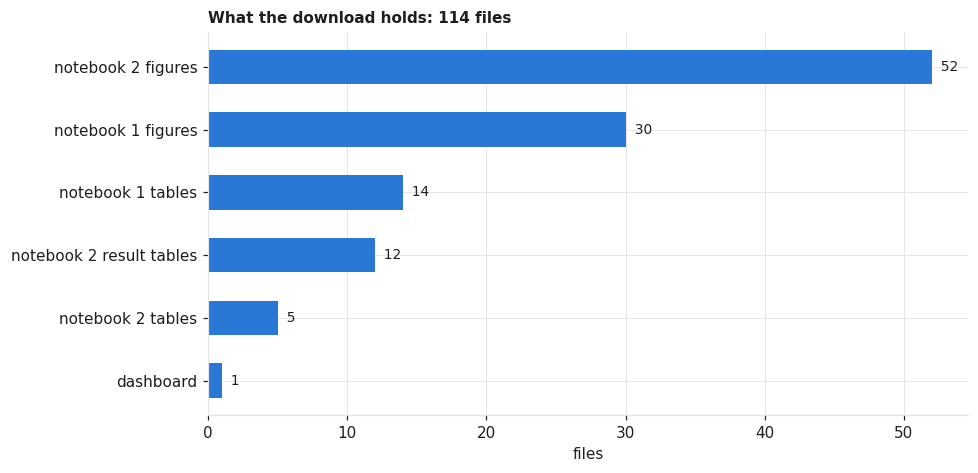

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  the download has started in your browser


In [ ]:
# @title
# ==================================================================================================
# PHASE: OUTPUT                                                         stage 4 of 4 in this phase
# STAGE 25  DOWNLOAD EVERYTHING
# WHAT THIS CELL DOES: every figure and table of both notebooks, the dashboard and a README, in one
#                      zip file
# ==================================================================================================
# WHAT THIS CELL DOES
#   Packs everything both notebooks produced into one zip file and starts the download: every
#   figure (PNG, SVG, slide version), every table (CSV), the result tables of this notebook, the
#   interactive dashboard and a README listing the contents.
#
# WHY
#   A Colab runtime erases its files when it ends. Notebook 1's figures and tables are read from
#   Drive, where notebook 1 copied them; this notebook's are in this session and on Drive.

import os, zipfile, datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

heading("STAGE 25  DOWNLOAD EVERYTHING")

EXPORT_DIR = os.path.join(CFG.output_dir, "export_tables")
os.makedirs(EXPORT_DIR, exist_ok=True)


def _with_names(frame, key, level):
    frame = frame.copy()
    frame.insert(1, "name", frame[key].map(THEME_NAMES.get(level, {})))
    return frame


# ---- the result tables of this notebook, as CSV ---------------------------------------------
_passage_columns = [c for c in ("passage_id", "doc_id", "group", "doc_language", "year", "date",
                                "theme_main", "theme_main_name", "theme_sub", "theme_sub_name",
                                "confidence_sub", "confidence_main", "silhouette_sub",
                                "silhouette_main", "assigned_by_centroid", "low_confidence",
                                "in_scope", "sub_in_scope", "text")
                    if c in passages.columns]
_list_columns = ("sub_theme_ids",)
EXPORTS = {
    "passages_with_themes": passages[_passage_columns],
    "themes": _with_names(CONSENSUS_MAIN_TABLE.merge(
        STABILITY[["theme_main", "jaccard_seeds", "jaccard_passages", "verdict"]],
        on="theme_main", how="left"), "theme_main", "main"),
    "subthemes": _with_names(SUBTHEME_TABLE, "theme_sub", "sub"),
    "name_gate": GATE,
    "summaries": SUMMARIES,
    "passage_summaries": PASSAGE_SUMMARIES,
    "scope_subthemes": SUB_SCOPE,
    "scope_alternatives": SCOPE_ALTERNATIVES,
    "self_test_calibration": CALIBRATION.reset_index().rename(columns={"index": "measure"}),
    "number_register": register_table(),
    "corpus_ledger": CORPUS_LEDGER,
    "documents": df_analysis[[c for c in df_analysis.columns
                              if c not in ("text", "text_raw", "body")]],
}
if SENSITIVITY is not None and len(SENSITIVITY):
    EXPORTS["subtheme_min_size_sensitivity"] = SENSITIVITY
for name, frame in EXPORTS.items():
    if frame is None or not hasattr(frame, "to_csv"):
        continue
    frame = frame.copy()
    for column in _list_columns:
        if column in frame.columns:
            frame[column] = frame[column].map(lambda v: " ".join(str(x) for x in v))
    frame.to_csv(os.path.join(EXPORT_DIR, f"{name}.csv"), index=False)

# ---- collect every file: this session first, then Drive (notebook 1's copies) -----------------
_roots = [("session", CFG.output_dir)]
if globals().get("DURABLE_OUTPUT_DIR") and os.path.isdir(DURABLE_OUTPUT_DIR):
    _roots.append(("Drive", DURABLE_OUTPUT_DIR))
_skip_dirs = {"cache", "artifacts", "__pycache__"}
_skip_ext = (".pkl", ".npy", ".npz", ".pt", ".zip")
FILES = {}
for origin, root in _roots:
    for folder, dirs, names in os.walk(root):
        dirs[:] = [d for d in dirs if d not in _skip_dirs]
        for name in names:
            path = os.path.join(folder, name)
            relative = os.path.relpath(path, root)
            if name.endswith(_skip_ext) or relative in FILES:
                continue
            if os.path.getsize(path) > 60 * 1024 * 1024:
                continue
            FILES[relative] = (path, origin)


def _part(relative):
    """Which part of the package a file belongs to, for the README and the figure."""
    name = os.path.basename(relative)
    if relative.startswith("export_tables"):
        return "notebook 2 result tables"
    if name.endswith(".html"):
        return "dashboard"
    stage = name[1:].split("_", 1)[0] if name.startswith("s") else ""
    digits = "".join(ch for ch in stage if ch.isdigit())
    notebook = "notebook 1" if digits and int(digits) <= 11 else "notebook 2"
    kind = "figures" if name.endswith((".png", ".svg")) else "tables"
    return f"{notebook} {kind}"


STAMP = datetime.datetime.now().strftime("%Y%m%d_%H%M")
ZIP_NAME = CFG.output("download").replace(".zip", f"_{STAMP}.zip")
ZIP_PATH = os.path.join(CFG.output_dir, ZIP_NAME)
_readme = ["Outputs of the thematic analysis pipeline (notebooks 1 and 2).",
           f"Written {STAMP} by run {RUN_ID}. Counts describe visibility in public reporting, "
           f"not prevalence.", ""]
_by_part = {}
for relative in sorted(FILES):
    _by_part.setdefault(_part(relative), []).append(relative)
for part in sorted(_by_part):
    _readme.append(f"{part}: {len(_by_part[part])} file(s)")
    _readme += [f"  {r}" for r in _by_part[part]]
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    archive.writestr("README.txt", "\n".join(_readme))
    for relative, (path, _) in sorted(FILES.items()):
        archive.write(path, relative)
ZIP_ON_DRIVE = keep_on_drive(ZIP_PATH)

print(f"  files packed          : {len(FILES):,}")
for part in sorted(_by_part):
    print(f"    {part:<28} {len(_by_part[part]):>4}")
print(f"  zip file              : {ZIP_PATH} ({os.path.getsize(ZIP_PATH) / 1e6:.1f} MB)")
if ZIP_ON_DRIVE:
    print(f"  also on Drive         : {ZIP_ON_DRIVE}")

# ---- figure: what the package holds ----------------------------------------------------------
_parts = sorted(_by_part, key=lambda p: -len(_by_part[p]))
fig, ax = plt.subplots(figsize=(9, 0.5 * len(_parts) + 1.4))
ax.barh(_parts[::-1], [len(_by_part[p]) for p in _parts[::-1]], color=PALETTE[0], height=0.55)
for k, part in enumerate(_parts[::-1]):
    ax.text(len(_by_part[part]), k, f"  {len(_by_part[part])}", va="center", fontsize=9)
ax.set_xlabel("files")
ax.set_title(f"What the download holds: {len(FILES)} files", fontsize=10, loc="left")
fig.tight_layout()
plt.show()

try:
    from google.colab import files as _colab_files
    _colab_files.download(ZIP_PATH)
    print("  the download has started in your browser")
except Exception:
    print("  not running in Colab: take the zip file from the path above")
rule()

_ = report("download.files", len(FILES), "files", "Stage 25")